# Orientation treatment and the cross-dataset gap in smartphone activity recognition

The notebook measures the part of the gap between in-domain and cross-dataset macro-F1 that is closed by treating device orientation. It uses four public smartphone datasets (HHAR, UCI-HAR, MotionSense and Shoaib), which give 12 directed transfer pairs, and three model families: a LIMU-BERT encoder with a GRU head, XGBoost on engineered features, and a fine-tuned UniMTS model.

## Contents

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Base pipeline: loaders, LIMU-BERT encoder, GRU head, augmentation operators, engineered features |
| 3 | Experiments: datasets, orientation treatments, training, run log, stages, data checks |
| 4 | Fine-tuning check on the source, run logs, UniMTS joint |
| 5 | Stages with encoders pretrained per fold, and their runs |
| 6 | Runs of the stages of Section 3 |
| 7 | Orientation-invariant transformation: arm `I_oit2` |
| 8 | Stages of the final configuration, and their runs |
| 9 | Analysis: gap fraction, hierarchical bootstrap, equivalence tests, tables and figures |
| 10 | Additional runs: source-selected identity floor of the final arm, equal seed budgets, tuned OIT, UniMTS |
| 11 | Numerical checks of Lemma 1, Corollary 1 and Propositions 1 to 3 and 6 |
| 12 | Treated in-domain reference (Definition 2), order-averaged attribution, permutation reference of Kendall's W, verdicts of the reporting protocol, numerical checks of Corollary 2 and Propositions 3 to 5 |
| 13 | SO(3) treatments with the identity floor selected on the source |
| 14 | Tables and figures with the source-selected SO(3) runs; seeds resampled once per shared training |
| 15 | Gravity-removed control and tuning of the device-frame encoder |

The first code cell of each of Sections 2 to 5, 7 to 10 and 12 to 15 contains definitions. The cells have to be executed from top to bottom, because Sections 4, 5, 7, 8, 14 and 15 extend or replace functions of earlier sections.

## Running the notebook from top to bottom

`RUN_STAGES` (Section 2) controls the calls of Sections 5 to 10 that train a model or measure a time. With `RUN_STAGES = False` (the setting of this file), `run_stage`, `run_strict`, `run_v4` and `v5_run` return without doing anything, and `estimate_cost()`, the runs of arm `I_oit2`, `v5_unimts_time()` and the cell of Section 10 that moves the partial UniMTS logs are skipped. These sections then only read the run logs in `revision/runs/`, and the analysis cells rewrite their tables and figures from the logs with fixed seeds. With `RUN_STAGES = True`, every stage runs; a stage skips the runs that are already in its log.

The stages of Sections 13 and 15 do not use `RUN_STAGES`. They need a GPU, skip the runs that are already in their logs and train the missing ones. Section 14 trains nothing.

## Where the methods of the paper are implemented

| Paper | Code |
|---|---|
| Gravity canonicalization with heading augmentation (Algorithm 1) | `canonicalize`, `op_yaw`, `finetune_rev` |
| Residual heading after a known rotation (Propositions 1 and 2) | `residual_heading`, `make_perturbation` |
| Comparison treatments | `op_so3`, objective `"so3"` in `pretrain_rev`, `pca_heading`, `mizell_transform`, `oit_transform` |
| Fraction of the gap closed and its hierarchical bootstrap (Algorithm 2) | `gap_fraction`, `hboot`, `Cells`; with shared trainings resampled once: `CellsShared`, `hboot_shared` |
| Source-only selection of the identity floor of the final arm (Sec. 4.2) | `exp_hparam_v4`, `v5_selected_floors`, `v5_exp_floor` |
| Source-only selection of the identity floor of the SO(3) treatments (Sec. 4.2) | `so3_tune`, `so3_select_source_floors`, `so3_run_final` |
| Source-only tuning of the device-frame encoder (Sec. 4.2) | `v7_exp_parity_val`, `v7_parity_selected`, `v7_exp_parity` |
| Gravity-removed control (Sec. 4.5) | `v7_demean`, `v7_exp_demean` |
| Reporting protocol (Algorithm 3) | `gap_fraction`, `contrast`, `differences`, `v6_contrasts`, `so3s_contrasts`, `protocol_verdict` |
| In-domain effect and fraction with the treated in-domain reference (Definition 2) | `v6_did` |
| Order-averaged attribution of the joint gain (Sec. 4.7) | `v6_shapley` |
| Kendall's W and its reference under permutation (Sec. 4.6) | `v6_agreement` |
| Lemma 1, Corollary 1, Propositions 1 to 3 and 6 | Section 11 (`verify_propositions.py`) |
| Corollary 2 and Propositions 3 to 5 | `v6_verify` (Section 12) |

## Data

The four datasets are public and are not distributed with this notebook. Place them under one data root:

```
<data root>/HHAR/Activity recognition exp/     Phones_accelerometer.csv, Phones_gyroscope.csv
<data root>/UCI HAR Dataset/                   train/ and test/ with "Inertial Signals"
<data root>/MotionSense/A_DeviceMotion_data/   <activity>_<trial>/sub_<k>.csv
<data root>/Shoaib/                            one CSV file per participant
```

On Google Colab the data root is `MyDrive`. Elsewhere it is taken from the environment variable `HAR_DATA_ROOT`.

## Requirements

NumPy, pandas, SciPy, scikit-learn, joblib, XGBoost, PyTorch and Matplotlib. The UniMTS stage clones the UniMTS repository, installs CLIP and `huggingface_hub`, and downloads the released checkpoint.

## Results

All output is written to the folder `revision/`, which is created in `MyDrive` on Colab and in `<data root>/results/` elsewhere. Every training run appends one row to a log in `revision/runs/`. A stage that is called again skips the runs already in its log, so an interrupted session can be continued. Pretrained encoders and parsed datasets are cached in `revision/enc/` and `revision/cache/`, and tables and figures are written to `revision/tables/`.

| Log files | Stages |
|---|---|
| `xgb.csv`, `*_v2.csv` | `run_stage(...)`: cross-dataset matrix with encoders pretrained on the source dataset, UniMTS, and the within-dataset stages with encoders pretrained on all subjects of the dataset |
| `*_strict.csv` | `run_strict(...)`: within-dataset stages with encoders pretrained on the training subjects of each fold |
| `*_v4.csv` | `run_v4(...)`: stages of the final configuration |
| `*_v5.csv` | `v5_run(...)`: additional runs of Section 10 |
| `*_so3source.csv` | `so3_tune()`, `so3_run_final()`: selection runs and 12-pair runs of the SO(3) treatments (Section 13) |
| `*_v7.csv` | `v7_run(...)`: gravity-removed control and tuning of the device-frame encoder (Section 15) |

Section 12 writes only to `revision/tables/v6/`, and Section 14 only to `revision/tables/so3source/`.

The values of the 12-pair matrix that the paper reports are those of Sections 14 and 15. The tables printed in Sections 9, 10 and 12 use the SO(3) runs with the identity floor of 0.3 on every pair and resample the seeds of every pair separately.

## 1. Setup

The cell below is for Google Colab: it mounts Google Drive, installs XGBoost and reports the GPU. Elsewhere, skip it and set `HAR_DATA_ROOT`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install xgboost tabulate
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE -- switch the runtime to GPU")

## 2. Base pipeline

Paths of the datasets, window geometry, the LIMU-BERT encoder with span masking, the GRU head, the augmentation operators and the engineered features used by XGBoost. Section 3 builds on these definitions.

In [2]:
# Base pipeline: loaders, LIMU-BERT encoder, GRU head, augmentation operators, engineered features

import os, glob, warnings, math, random
import numpy as np
import pandas as pd
import scipy.fftpack
import joblib

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix
from xgboost import XGBClassifier

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.func import functional_call

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB  = True
    DATA_ROOT = '/content/drive/MyDrive'
except Exception:
    IN_COLAB  = False
    DATA_ROOT = os.environ.get('HAR_DATA_ROOT', os.path.expanduser('~/har_data'))

BASE_PATH         = os.path.join(DATA_ROOT, 'HHAR')
ACTIVITY_PATH     = os.path.join(BASE_PATH, 'Activity recognition exp')
ANDROID_DATA_PATH = os.path.join(DATA_ROOT, 'Android_Data')
UCI_PATH          = os.path.join(DATA_ROOT, 'UCI HAR Dataset')
SAVE_PATH         = DATA_ROOT if IN_COLAB else os.path.join(DATA_ROOT, 'results')
os.makedirs(SAVE_PATH, exist_ok=True)

MS_PATH = os.path.join(DATA_ROOT, 'MotionSense', 'A_DeviceMotion_data')
SHOAIB_PATH = os.path.join(DATA_ROOT, 'Shoaib')

# Window geometry
STEP_SEC   = 2.5
MIN_SAMPLES_HHAR = 30
TARGET_HZ  = 20.0                              # LIMU-BERT operating rate
N_CHANNELS = 6                                 # acc xyz + gyro xyz

WINDOW_SEC = 5.0                               # in-domain HHAR window
SEQ_LEN    = int(round(WINDOW_SEC * TARGET_HZ))   # L = 100 (5 s @ 20 Hz)

XDOMAIN_WINDOW_SEC = 2.56                       # UCI native window (128 @ 50 Hz)
XDOMAIN_SEQ_LEN    = int(round(XDOMAIN_WINDOW_SEC * TARGET_HZ))  # L = 51 @ 20 Hz

MAX_LEN = 128     # positional-embedding capacity; must be >= any L used above

USE_GRAVITY_ALIGN = False

QUICK  = False
RESUME = True
# False: the stages of Sections 5 to 10 do not train, and the analysis reads the existing run logs.
# True:  every stage runs and skips the runs that are already in its log.
RUN_STAGES = False
SEED   = 42
SEEDS  = (42,) if QUICK else (42, 43, 44)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
PRETRAIN_EPOCHS = 5  if QUICK else 80
FINETUNE_EPOCHS = 6  if QUICK else 40
POLICY_EPOCHS   = 4  if QUICK else 15
PRETRAIN_BS, PRETRAIN_LR = 256, 1e-3
FINETUNE_BS, FINETUNE_LR = 128, 1e-3
ALPHA_LR = 3e-3
FREEZE_ENCODER = False
PRETRAIN_CONSISTENCY = True
CONSISTENCY_LAMBDA   = 0.1
CONSISTENCY_MIN_N    = 15000

# Balanced multi-source pool: cap each dataset's contribution so one large set
MULTI_CAP = 25000

# Identity floor for fixed-policy augmentation: with this probability the batch
# passes through unaugmented
AUG_IDENTITY_FLOOR = 0.3

# LIMU-BERT hyperparameters (defaults of the LIMU-BERT paper)
H_DIM, FF_DIM, N_LAYERS, N_HEADS = 72, 144, 4, 4
SHARE_LAYERS = True
MASK_RATIO, MASK_PROB, SPAN_P, SPAN_LMAX = 0.15, 0.80, 0.20, 10

LABEL_MAP = {
    'stand': 0, 'sit': 0, 'null': -1, 'bike': 6,
    'stairsup': 2, 'stairsdown': 3, 'walk': 4, 'elevator': 1,
    'running': 5, 'walking': 4,
}
CLASS_NAMES = {0:'static(sit/stand)',1:'elevator',2:'stairsUP',3:'stairsDOWN',
               4:'walk',5:'run',6:'bike'}
UCI2OURS = {1: 4, 2: 2, 3: 3, 4: 0, 5: 0}      # Walk,up,down,sit,stand
UCI_G, UCI_HZ = 9.80665, 50.0


def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


def map_gt_hhar(v):
    return LABEL_MAP.get(str(v).strip().lower(), -1)


# Gravity canonicalization and engineered features
def _rot_to_vertical(ghat):
    z = np.array([0.0, 0.0, 1.0]); v = np.cross(ghat, z)
    c = float(np.dot(ghat, z)); s = np.linalg.norm(v)
    if s < 1e-8:
        return np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
    vx = np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])
    return np.eye(3) + vx + vx @ vx * ((1 - c) / (s * s))

def _apply_R(win_df, R):
    out = win_df.copy()
    out[['x', 'y', 'z']] = win_df[['x', 'y', 'z']].values @ R.T
    return out

def align_window(a_win, g_win):
    m = a_win[['x', 'y', 'z']].values.mean(0); n = np.linalg.norm(m)
    if n < 5.0:
        return a_win, g_win, False
    R = _rot_to_vertical(m / n)
    return _apply_R(a_win, R), _apply_R(g_win, R), True

def align_window_with_ref(a_win, g_win, grav_win):
    if grav_win is None or len(grav_win) == 0:
        return a_win, g_win, False
    m = grav_win[['x', 'y', 'z']].values.mean(0); n = np.linalg.norm(m)
    if n < 1e-6:
        return a_win, g_win, False
    R = _rot_to_vertical(m / n)
    return _apply_R(a_win, R), _apply_R(g_win, R), True

def instance_norm(win):
    w = win.copy()
    for c in "xyz":
        v = w[c].values
        w[c] = (v - v.mean()) / (v.std() + 1e-8)
    return w

def amp_features(win, prefix, hz):
    f = {}
    for ax in "xyz":
        sig = win[ax].values - win[ax].values.mean()
        amp = np.abs(np.fft.rfft(sig)); amp = amp / (amp.sum() + 1e-9)
        frq = np.fft.rfftfreq(len(sig), d=1.0 / hz)
        for lo, hi, nm in [(0,1,"b01"),(1,2,"b12"),(2,3,"b23"),(3,5,"b35")]:
            m = (frq >= lo) & (frq < hi)
            f[f"{prefix}_{ax}_amp_{nm}"] = float(amp[m].sum())
        f[f"{prefix}_{ax}_spec_centroid"] = float((frq * amp).sum())
        di = 1 + int(np.argmax(amp[1:])) if len(amp) > 1 else 0
        h2 = min(2 * di, len(amp) - 1)
        f[f"{prefix}_{ax}_harm_ratio"] = float(amp[h2] / (amp[di] + 1e-9))
    return f

def corr_features(a_win, g_win):
    def cc(u, v):
        n = min(len(u), len(v))
        if n < 2:
            return 0.0
        c = np.corrcoef(u[:n], v[:n])[0, 1]
        return float(c) if np.isfinite(c) else 0.0
    ax, ay, az = a_win.x.values, a_win.y.values, a_win.z.values
    gx, gy, gz = g_win.x.values, g_win.y.values, g_win.z.values
    return {"acc_xy_corr": cc(ax, ay), "acc_xz_corr": cc(ax, az), "acc_yz_corr": cc(ay, az),
            "accgyro_x_corr": cc(ax, gx), "accgyro_y_corr": cc(ay, gy), "accgyro_z_corr": cc(az, gz)}

def features_from_windows(a_win, g_win, sample_hz=100.0, grav_win=None,
                          add_amp=True, add_corr=True, use_instnorm=False):
    if USE_GRAVITY_ALIGN:
        if grav_win is not None:
            a_al, g_al, aligned = align_window_with_ref(a_win, g_win, grav_win)
        else:
            a_al, g_al, aligned = align_window(a_win, g_win)
    else:
        a_al, g_al, aligned = a_win, g_win, False
    a_use, g_use = (instance_norm(a_al), instance_norm(g_al)) if use_instnorm else (a_al, g_al)
    f = {**extract_sensor_features(a_use, "acc", sample_hz),
         **extract_sensor_features(g_use, "gyro", sample_hz)}
    f.pop('acc_z_drift', None); f.pop('acc_z_drift_abs', None)
    vz = a_al['z'].values - a_al['z'].values.mean()
    vel = np.cumsum(vz) * (1.0 / sample_hz)
    f['acc_vert_vel_range'] = float(vel.max() - vel.min())
    if add_amp:
        f.update(amp_features(a_use, "acc", sample_hz))
        f.update(amp_features(g_use, "gyro", sample_hz))
    if add_corr:
        f.update(corr_features(a_use, g_use))
    return f, aligned

def extract_sensor_features(window_df, sensor_prefix, sample_hz=100.0):
    feats = {}
    x = window_df['x'].values.astype(float); y = window_df['y'].values.astype(float)
    z = window_df['z'].values.astype(float); mag = np.sqrt(x*x + y*y + z*z)
    if sensor_prefix == 'acc' and mag.mean() > 5.0:
        x = x - x.mean(); y = y - y.mean(); z = z - z.mean()
        mag = np.sqrt(x*x + y*y + z*z)
    mag_centered = mag - mag.mean()
    feats[f'{sensor_prefix}_x_mean'] = float(np.mean(x)); feats[f'{sensor_prefix}_y_mean'] = float(np.mean(y))
    feats[f'{sensor_prefix}_z_mean'] = float(np.mean(z)); feats[f'{sensor_prefix}_x_std'] = float(np.std(x))
    feats[f'{sensor_prefix}_y_std'] = float(np.std(y));  feats[f'{sensor_prefix}_z_std'] = float(np.std(z))
    feats[f'{sensor_prefix}_mag_mean'] = float(np.mean(mag)); feats[f'{sensor_prefix}_mag_std'] = float(np.std(mag))
    feats[f'{sensor_prefix}_mag_p2p'] = float(np.ptp(mag))
    feats[f'{sensor_prefix}_mag_energy'] = float(np.sum(mag**2) / len(mag))
    feats[f'{sensor_prefix}_sma'] = float(np.sum(np.abs(x)+np.abs(y)+np.abs(z)) / len(mag))
    feats[f'{sensor_prefix}_mag_75th'] = float(np.percentile(mag, 75))
    feats[f'{sensor_prefix}_mag_25th'] = float(np.percentile(mag, 25))
    feats[f'{sensor_prefix}_zcr'] = float(((mag_centered[:-1] * mag_centered[1:]) < 0).sum() / len(mag))
    dt = 1.0 / sample_hz
    feats[f'{sensor_prefix}_z_drift'] = float(np.sum(z) * dt)
    feats[f'{sensor_prefix}_z_drift_abs'] = float(abs(np.sum(z) * dt))
    def _skew(a):
        m, s = a.mean(), a.std(); return float(((a-m)**3).mean() / (s**3 + 1e-9))
    def _kurt(a):
        m, s = a.mean(), a.std(); return float(((a-m)**4).mean() / (s**4 + 1e-9) - 3.0)
    feats[f'{sensor_prefix}_z_skew'] = _skew(z); feats[f'{sensor_prefix}_z_kurt'] = _kurt(z)
    feats[f'{sensor_prefix}_mag_skew'] = _skew(mag); feats[f'{sensor_prefix}_mag_kurt'] = _kurt(mag)
    z_pos = z[z > 0]; z_neg = z[z < 0]
    feats[f'{sensor_prefix}_z_pos_mean'] = float(z_pos.mean()) if len(z_pos) else 0.0
    feats[f'{sensor_prefix}_z_neg_mean'] = float(z_neg.mean()) if len(z_neg) else 0.0
    feats[f'{sensor_prefix}_z_peak_asym'] = feats[f'{sensor_prefix}_z_pos_mean'] + feats[f'{sensor_prefix}_z_neg_mean']
    fft_vals = np.abs(scipy.fftpack.fft(mag)); freqs = scipy.fftpack.fftfreq(len(mag), d=1.0/sample_hz)
    peak_idx = 1 + np.argmax(fft_vals[1:]) if len(fft_vals) > 1 else 0
    fs = fft_vals.sum() + 1e-9
    feats[f'{sensor_prefix}_dominant_freq'] = float(abs(freqs[peak_idx]))
    feats[f'{sensor_prefix}_spectral_entropy'] = float(-np.sum((fft_vals / fs) * np.log(fft_vals / fs + 1e-9)))
    fft_z = np.abs(scipy.fftpack.fft(z - z.mean()))
    z_pidx = 1 + np.argmax(fft_z[1:]) if len(fft_z) > 1 else 0
    feats[f'{sensor_prefix}_z_dominant_freq'] = float(abs(freqs[z_pidx]))
    return feats

def safe_read_csv(path):
    for enc in ['utf-8', 'latin1', 'cp1252']:
        try:    return pd.read_csv(path, encoding=enc)
        except Exception: continue
    return None

def standardize_columns(df):
    return df.rename(columns={c: c.strip().lower() for c in df.columns})


# HHAR: loading, feature windows and raw windows
def infer_sensor(path):
    n = os.path.basename(path).lower()
    return 'gyro' if 'gyro' in n else 'acc' if 'acc' in n else 'unknown'

def load_raw_phone_csv(file_path):
    df = safe_read_csv(file_path)
    if df is None: return None
    df = standardize_columns(df)
    req = ['creation_time', 'x', 'y', 'z', 'user', 'model', 'device', 'gt']
    if not all(c in df.columns for c in req): return None
    df = df[req].dropna().copy()
    for col in ['creation_time', 'x', 'y', 'z']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna()
    df['class_label'] = df['gt'].apply(map_gt_hhar)
    df = df[df['class_label'] >= 0]
    df['time_sec'] = df['creation_time'] / 1e9
    return df.sort_values(['user', 'device', 'time_sec']).reset_index(drop=True)

def load_hhar_phone():
    all_csv = [f for f in glob.glob(os.path.join(ACTIVITY_PATH, '*.csv')) if 'readme' not in f.lower()]
    files_df = pd.DataFrame({'file_path': f, 'sensor_type': infer_sensor(f),
                             'is_phone': 'phone' in os.path.basename(f).lower()} for f in all_csv)
    files_df = files_df[files_df['is_phone']].copy()
    acc_p  = next((r.file_path for _, r in files_df.iterrows() if r.sensor_type == 'acc'),  None)
    gyro_p = next((r.file_path for _, r in files_df.iterrows() if r.sensor_type == 'gyro'), None)
    return load_raw_phone_csv(acc_p), load_raw_phone_csv(gyro_p)


# Feature windows
def window_hhar(acc_raw, gyro_raw, window_sec=WINDOW_SEC, step_sec=STEP_SEC,
                min_samples=MIN_SAMPLES_HHAR):
    results = []
    if acc_raw is None or gyro_raw is None: return results
    for (user, device), acc_grp in acc_raw.groupby(['user', 'device']):
        gyro_grp = gyro_raw[(gyro_raw['user'] == user) & (gyro_raw['device'] == device)]
        if gyro_grp.empty: continue
        t0 = max(acc_grp['time_sec'].min(), gyro_grp['time_sec'].min())
        t1 = min(acc_grp['time_sec'].max(), gyro_grp['time_sec'].max())
        if t1 - t0 < window_sec: continue
        at, gt = acc_grp['time_sec'].values, gyro_grp['time_sec'].values
        t, wid = t0, 0
        while t + window_sec <= t1:
            a_win = acc_grp[(at >= t) & (at < t + window_sec)]
            g_win = gyro_grp[(gt >= t) & (gt < t + window_sec)]
            if len(a_win) >= min_samples and len(g_win) >= min_samples:
                lbl = int(a_win['class_label'].mode().iloc[0])
                feats, _ = features_from_windows(a_win, g_win)
                results.append({'class_label': lbl, 'carrying_load': 0, 'user': user,
                                'device': device, 'source': 'hhar', 'window_id': wid, **feats})
            t += step_sec; wid += 1
    return results


# Raw windows, with gravity alignment
def _resample(arr, L):
    n = arr.shape[0]
    if n == L: return arr.astype(np.float32)
    old = np.linspace(0.0, 1.0, n); new = np.linspace(0.0, 1.0, L)
    out = np.empty((L, arr.shape[1]), dtype=np.float32)
    for c in range(arr.shape[1]):
        out[:, c] = np.interp(new, old, arr[:, c])
    return out

def _align_arrays(acc, gyro):
    """Self-align from accelerometer gravity (array version of align_window)."""
    m = acc.mean(0); n = np.linalg.norm(m)
    if n < 5.0:
        return acc, gyro, False
    R = _rot_to_vertical(m / n)
    return acc @ R.T, gyro @ R.T, True

def raw_from_arrays(acc, gyro, align, has_gravity=True, seq_len=SEQ_LEN):
    """[n,3]+[n,3] -> normalized [L,6]. acc/9.80665 (LIMU-BERT Eq.1); gyro as-is."""
    if align and has_gravity:
        acc, gyro, _ = _align_arrays(acc, gyro)
    acc = _resample(acc, seq_len); gyro = _resample(gyro, seq_len)
    win = np.concatenate([acc, gyro], axis=1).astype(np.float32)
    win[:, 0:3] = win[:, 0:3] / 9.80665
    return win

def window_hhar_raw(acc_raw, gyro_raw, align, window_sec=WINDOW_SEC, step_sec=STEP_SEC,
                    min_samples=MIN_SAMPLES_HHAR, seq_len=SEQ_LEN):
    X, y, groups = [], [], []
    if acc_raw is None or gyro_raw is None:
        return np.empty((0, seq_len, N_CHANNELS), np.float32), np.array([]), np.array([])
    for (user, device), acc_grp in acc_raw.groupby(['user', 'device']):
        gyro_grp = gyro_raw[(gyro_raw['user'] == user) & (gyro_raw['device'] == device)]
        if gyro_grp.empty: continue
        t0 = max(acc_grp['time_sec'].min(), gyro_grp['time_sec'].min())
        t1 = min(acc_grp['time_sec'].max(), gyro_grp['time_sec'].max())
        if t1 - t0 < window_sec: continue
        at, gt = acc_grp['time_sec'].values, gyro_grp['time_sec'].values
        t = t0
        while t + window_sec <= t1:
            a_win = acc_grp[(at >= t) & (at < t + window_sec)]
            g_win = gyro_grp[(gt >= t) & (gt < t + window_sec)]
            if len(a_win) >= min_samples and len(g_win) >= min_samples:
                lbl = int(a_win['class_label'].mode().iloc[0])
                acc = a_win[['x', 'y', 'z']].values.astype(np.float32)
                gyr = g_win[['x', 'y', 'z']].values.astype(np.float32)
                X.append(raw_from_arrays(acc, gyr, align, has_gravity=True, seq_len=seq_len))
                y.append(lbl); groups.append(str(user))
            t += step_sec
    return (np.asarray(X, np.float32) if X else np.empty((0, seq_len, N_CHANNELS), np.float32),
            np.asarray(y), np.asarray(groups))


# Phyphox recordings (features only)
def load_phyphox_csv(path):
    if not os.path.exists(path): return None
    df = pd.read_csv(path)
    df.columns = ['time_sec', 'x', 'y', 'z'] + list(df.columns[4:])
    return df[['time_sec', 'x', 'y', 'z']].astype(np.float32)

def load_phyphox_gravity_ref(folder_path):
    for fn in ['Gravity.csv', 'Accelerometer.csv', 'Acceleration with g.csv', 'Raw Acceleration.csv']:
        df = load_phyphox_csv(os.path.join(folder_path, fn))
        if df is not None:
            return df, fn
    return None, None

def map_folder_to_label(folder_name):
    name = folder_name.lower(); label = -1
    if 'elevator' in name: label = 1
    elif 'stairsup' in name: label = 2
    elif 'stairsdown' in name: label = 3
    elif 'walking' in name: label = 4
    elif 'running' in name: label = 5
    return label, ('with_box' in name)

def process_phyphox_folder(folder_path, label, carrying_load,
                           window_sec=WINDOW_SEC, step_sec=2.0, min_samples=50):
    acc_df  = load_phyphox_csv(os.path.join(folder_path, 'Linear Acceleration.csv'))
    gyro_df = load_phyphox_csv(os.path.join(folder_path, 'Gyroscope.csv'))
    if acc_df is None or gyro_df is None: return []
    grav_df = None
    if USE_GRAVITY_ALIGN:
        grav_df, _ = load_phyphox_gravity_ref(folder_path)
    max_t = min(acc_df['time_sec'].max(), gyro_df['time_sec'].max())
    at, gt = acc_df['time_sec'].values, gyro_df['time_sec'].values
    grav_t = grav_df['time_sec'].values if grav_df is not None else None
    results, t = [], 0.0
    while t + window_sec <= max_t:
        a_win = acc_df.iloc[np.searchsorted(at, t):np.searchsorted(at, t + window_sec)]
        g_win = gyro_df.iloc[np.searchsorted(gt, t):np.searchsorted(gt, t + window_sec)]
        grav_win = None
        if grav_df is not None:
            grav_win = grav_df.iloc[np.searchsorted(grav_t, t):np.searchsorted(grav_t, t + window_sec)]
        if len(a_win) >= min_samples and len(g_win) >= min_samples:
            feats, _ = features_from_windows(a_win, g_win, grav_win=grav_win)
            results.append({'class_label': label, 'carrying_load': int(carrying_load),
                            'user': 'phyphox_team', 'device': 'phyphox', 'source': 'phyphox',
                            'window_id': int(t / step_sec), **feats})
        t += step_sec
    return results

def load_phyphox_features():
    rows = []
    if os.path.exists(ANDROID_DATA_PATH):
        for folder_name in os.listdir(ANDROID_DATA_PATH):
            fp = os.path.join(ANDROID_DATA_PATH, folder_name)
            if not os.path.isdir(fp): continue
            label, load = map_folder_to_label(folder_name)
            if label < 0: continue
            rows.extend(process_phyphox_folder(fp, label, load))
    return pd.DataFrame(rows).fillna(0) if rows else pd.DataFrame()


# UCI-HAR: feature windows and raw windows
def _uci_load(split, sig):
    p = os.path.join(UCI_PATH, split, 'Inertial Signals', f'{sig}_{split}.txt')
    return np.loadtxt(p)

def build_uci_features(feature_cols):
    frames, ys = [], []
    for split in ['train', 'test']:
        ax, ay, az = (_uci_load(split, f'total_acc_{a}') * UCI_G for a in 'xyz')
        gx, gy, gz = (_uci_load(split, f'body_gyro_{a}')       for a in 'xyz')
        yv = np.loadtxt(os.path.join(UCI_PATH, split, f'y_{split}.txt')).astype(int)
        keep = np.isin(yv, list(UCI2OURS))
        rows = []
        for i in range(ax.shape[0]):
            a_df = pd.DataFrame({'x': ax[i], 'y': ay[i], 'z': az[i]})
            g_df = pd.DataFrame({'x': gx[i], 'y': gy[i], 'z': gz[i]})
            feats, _ = features_from_windows(a_df, g_df, sample_hz=UCI_HZ)
            feats['carrying_load'] = 0
            rows.append(feats)
        X = pd.DataFrame(rows).reindex(columns=feature_cols, fill_value=0.0).iloc[np.where(keep)[0]]
        frames.append(X); ys.append(np.array([UCI2OURS[v] for v in yv[keep]]))
    return pd.concat(frames, ignore_index=True), np.concatenate(ys)

def build_uci_raw(align, seq_len=SEQ_LEN):
    Xs, ys = [], []
    for split in ['train', 'test']:
        ax, ay, az = (_uci_load(split, f'total_acc_{a}') * UCI_G for a in 'xyz')
        gx, gy, gz = (_uci_load(split, f'body_gyro_{a}')       for a in 'xyz')
        yv = np.loadtxt(os.path.join(UCI_PATH, split, f'y_{split}.txt')).astype(int)
        for i in range(ax.shape[0]):
            if yv[i] not in UCI2OURS: continue
            acc = np.stack([ax[i], ay[i], az[i]], axis=1)
            gyr = np.stack([gx[i], gy[i], gz[i]], axis=1)
            Xs.append(raw_from_arrays(acc, gyr, align, has_gravity=True, seq_len=seq_len))
            ys.append(UCI2OURS[yv[i]])
    return np.asarray(Xs, np.float32), np.asarray(ys)


# XGBoost evaluation: leave-one-subject-out and transfer to UCI-HAR
def make_xgb(n_classes):
    return XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                         colsample_bytree=0.8, min_child_weight=3, reg_alpha=0.1, reg_lambda=1.0,
                         objective='multi:softprob', num_class=n_classes, eval_metric='mlogloss',
                         random_state=42, n_jobs=-1)

def tier1_loso(hhar_df, feature_cols):
    X = hhar_df[feature_cols].copy(); y = hhar_df['class_label'].astype(int).copy()
    groups = hhar_df['user'].astype(str)
    logo = LeaveOneGroupOut(); accs = []
    for tr_idx, te_idx in logo.split(X, y, groups=groups):
        y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]
        if (set(y_te.unique()) - set(y_tr.unique())) or len(y_te) < 10:
            continue
        classes = sorted(y_tr.unique())
        lmap = {o: n for n, o in enumerate(classes)}; inv = {n: o for o, n in lmap.items()}
        model = make_xgb(len(classes))
        model.fit(X.iloc[tr_idx], y_tr.map(lmap))
        pred = pd.Series(model.predict(X.iloc[te_idx])).map(inv).values
        accs.append(accuracy_score(y_te, pred))
    return float(np.mean(accs)) if accs else float('nan'), float(np.std(accs)) if accs else float('nan')

def tier1_cross_uci(hhar_df, feature_cols, X_uci, y_uci, seeds=(SEED,)):
    classes = sorted(hhar_df['class_label'].unique())
    lmap = {o: n for n, o in enumerate(classes)}; inv = {n: o for o, n in lmap.items()}
    f4s, fsts = [], []
    for sd in seeds:
        model = make_xgb(len(classes)); model.set_params(random_state=sd)
        model.fit(hhar_df[feature_cols], hhar_df['class_label'].map(lmap))
        pred = pd.Series(model.predict(X_uci[feature_cols])).map(inv).values
        f4s.append(f1_score(y_uci, pred, labels=[0, 2, 3, 4], average='macro'))
        fsts.append(f1_score(y_uci, pred, labels=[2, 3], average='macro'))
    return (float(np.mean(f4s)), float(np.std(f4s)),
            float(np.mean(fsts)), float(np.std(fsts)))


# LIMU-BERT encoder
class Embeddings(nn.Module):
    def __init__(self, s_dim, h_dim, max_len):
        super().__init__()
        self.proj = nn.Linear(s_dim, h_dim)
        self.norm1 = nn.LayerNorm(h_dim)
        self.pos = nn.Parameter(torch.zeros(1, max_len, h_dim))
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.norm2 = nn.LayerNorm(h_dim)
    def forward(self, x):
        h = self.norm1(self.proj(x)); h = h + self.pos[:, :x.size(1)]
        return self.norm2(h)

class MultiHeadAttention(nn.Module):
    """Attention written with matmul and softmax. It supports second-order gradients on the GPU, which the
    AutoAugHAR search needs."""
    def __init__(self, h_dim, n_heads):
        super().__init__()
        assert h_dim % n_heads == 0
        self.h, self.d = n_heads, h_dim // n_heads
        self.qkv = nn.Linear(h_dim, 3 * h_dim)
        self.out = nn.Linear(h_dim, h_dim)
    def forward(self, x):                                   # X: [b, l, h]
        B, L, H = x.shape
        qkv = self.qkv(x).view(B, L, 3, self.h, self.d).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]                    # each [B, heads, L, d]
        att = (q @ k.transpose(-2, -1)) / (self.d ** 0.5)  # [B, heads, L, L]
        att = att.softmax(dim=-1)
        o = (att @ v).transpose(1, 2).reshape(B, L, H)      # [B, L, H]
        return self.out(o)

class EncoderBlock(nn.Module):
    def __init__(self, h_dim, ff_dim, n_heads):
        super().__init__()
        self.attn = MultiHeadAttention(h_dim, n_heads)
        self.norm_a = nn.LayerNorm(h_dim)
        self.proj = nn.Linear(h_dim, h_dim); self.norm_p = nn.LayerNorm(h_dim)
        self.ff = nn.Sequential(nn.Linear(h_dim, ff_dim), nn.GELU(), nn.Linear(ff_dim, h_dim))
        self.norm_h = nn.LayerNorm(h_dim)
    def forward(self, h):
        a = self.norm_a(self.attn(h) + h)
        p = self.norm_p(self.proj(a) + a)
        return self.norm_h(self.ff(p) + p)

class LimuEncoder(nn.Module):
    def __init__(self, s_dim=N_CHANNELS, h_dim=H_DIM, ff_dim=FF_DIM, n_layers=N_LAYERS,
                 n_heads=N_HEADS, max_len=MAX_LEN, share=SHARE_LAYERS):
        super().__init__()
        self.embed = Embeddings(s_dim, h_dim, max_len)
        self.share = share; self.n_layers = n_layers
        if share:
            self.block = EncoderBlock(h_dim, ff_dim, n_heads)
        else:
            self.blocks = nn.ModuleList([EncoderBlock(h_dim, ff_dim, n_heads) for _ in range(n_layers)])
    def forward(self, x):
        h = self.embed(x)
        if self.share:
            for _ in range(self.n_layers): h = self.block(h)
        else:
            for blk in self.blocks: h = blk(h)
        return h

class LimuDecoder(nn.Module):
    def __init__(self, h_dim=H_DIM, s_dim=N_CHANNELS):
        super().__init__()
        self.proj = nn.Linear(h_dim, h_dim); self.norm = nn.LayerNorm(h_dim)
        self.pred = nn.Linear(h_dim, s_dim)
    def forward(self, e):
        return self.pred(self.norm(F.gelu(self.proj(e))))

class LimuBERT(nn.Module):
    def __init__(self, **kw):
        super().__init__()
        self.encoder = LimuEncoder(**kw)
        self.decoder = LimuDecoder(kw.get('h_dim', H_DIM), kw.get('s_dim', N_CHANNELS))
    def forward(self, x_masked):
        return self.decoder(self.encoder(x_masked))

def _span_mask_np(B, L, mask_ratio, p, l_max):
    """Boolean mask [B, L], built on the CPU with NumPy."""
    mask = np.zeros((B, L), dtype=bool)
    n_mask = max(1, int(L * mask_ratio))
    for b in range(B):
        chosen = mask[b]; m, guard = 0, 0
        while m < n_mask and guard < 10 * L:
            guard += 1
            s = np.random.randint(0, L)
            if chosen[s]: continue
            l = min(int(np.random.geometric(p)), l_max, n_mask - m)
            e = min(s + l, L)
            for j in range(s, e):
                if not chosen[j]:
                    chosen[j] = True; m += 1
    return mask

def span_mask(x, mask_ratio=MASK_RATIO, p=SPAN_P, l_max=SPAN_LMAX, p_m=MASK_PROB):
    """Span masking of LIMU-BERT. Returns (x_masked, mask[B, L]). The masked positions always enter
    the loss; the input is set to zero there with probability p_m per sequence. The mask is built
    on the CPU and applied in one operation on the device."""
    B, L, C = x.shape
    mask = torch.from_numpy(_span_mask_np(B, L, mask_ratio, p, l_max)).to(x.device)
    do_zero = (torch.rand(B, device=x.device) < p_m).view(B, 1, 1)   # per-sequence
    x_masked = x.masked_fill(mask.unsqueeze(-1) & do_zero, 0.0)
    return x_masked, mask

class GRUClassifier(nn.Module):
    def __init__(self, h_dim=H_DIM, n_classes=7):
        super().__init__()
        self.g1 = nn.GRU(h_dim, 20, batch_first=True)
        self.g2 = nn.GRU(20, 20, batch_first=True)
        self.g3 = nn.GRU(20, 10, batch_first=True)
        self.drop = nn.Dropout(0.5); self.fc1 = nn.Linear(10, 10); self.fc2 = nn.Linear(10, n_classes)
    def forward(self, e):
        h, _ = self.g1(e); h, _ = self.g2(h); h, _ = self.g3(h)
        h = self.drop(h[:, -1]); return self.fc2(F.relu(self.fc1(h)))

class HARModel(nn.Module):
    def __init__(self, n_classes, freeze_encoder=FREEZE_ENCODER, **kw):
        super().__init__()
        self.encoder = LimuEncoder(**kw)
        self.head = GRUClassifier(kw.get('h_dim', H_DIM), n_classes)
        self.freeze = freeze_encoder
    def load_encoder(self, sd): self.encoder.load_state_dict(sd)
    def forward(self, x):
        if self.freeze:
            with torch.no_grad(): e = self.encoder(x)
        else:
            e = self.encoder(x)
        return self.head(e)


# AutoAugHAR: label-preserving operators and differentiable policy
def op_identity(x): return x
def op_jitter(x, s):  return x + torch.randn_like(x) * s
def op_scaling(x, s):
    f = torch.randn(x.size(0), 1, x.size(2), device=x.device) * s + 1.0; return x * f
def op_moving_avg(x, ws):
    pad = ws // 2; xt = x.transpose(1, 2)
    w = torch.ones(x.size(2), 1, ws, device=x.device) / ws
    y = F.conv1d(F.pad(xt, (pad, pad), mode='replicate'), w, groups=x.size(2))
    return y[..., :x.size(1)].transpose(1, 2)
def op_slope(x, sr=0.1):
    B, L, C = x.shape
    s = (torch.rand(B, 1, C, device=x.device) * 2 - 1) * sr
    t = torch.linspace(0, 1, L, device=x.device).view(1, L, 1)
    return x + s * t
def _smooth_curve(B, L, C, sigma, n_knots, device):
    knots = torch.randn(B, n_knots, C, device=device) * sigma + 1.0
    return F.interpolate(knots.transpose(1, 2), size=L, mode='linear', align_corners=True).transpose(1, 2)
def op_mag_warp(x, s, n_knots=4):
    return x * _smooth_curve(x.size(0), x.size(1), x.size(2), s, n_knots, x.device)
def op_time_warp(x, s, n_knots=4):
    B, L, C = x.shape
    speed = _smooth_curve(B, L, 1, s, n_knots, x.device).clamp(min=0.1)
    cum = torch.cumsum(speed, dim=1); cum = (cum - cum[:, :1]) / (cum[:, -1:] - cum[:, :1] + 1e-6)
    xs = (cum.squeeze(-1) * 2 - 1).unsqueeze(1).expand(B, C, L)
    ys = torch.linspace(-1, 1, C, device=x.device).view(1, C, 1).expand(B, C, L)
    grid = torch.stack([xs, ys], dim=-1)
    img = x.permute(0, 2, 1).unsqueeze(1)
    out = F.grid_sample(img, grid, align_corners=True, padding_mode='border')
    return out.squeeze(1).transpose(1, 2)
def op_window_slice(x, lam_range=(0.7, 0.9)):
    B, L, C = x.shape; lam = random.uniform(*lam_range)
    w = max(2, int(L * lam)); s = random.randint(0, L - w)
    crop = x[:, s:s + w].transpose(1, 2)
    return F.interpolate(crop, size=L, mode='linear', align_corners=True).transpose(1, 2)

def op_rot_z(x, max_deg=180.0):
    """Rotation about the z-axis by a random angle per window, theta ~ U(-max_deg, max_deg), applied
    to the x and y components of both sensors (Eq. 7). After canonicalization z is the vertical,
    so the operator changes only the heading."""
    B = x.size(0)
    th = (torch.rand(B, 1, device=x.device) * 2 - 1) * math.radians(max_deg)
    c, s = torch.cos(th), torch.sin(th)                     # [B,1]
    out = x.clone()
    for i0 in (0, 3):                                       # acc xy, gyro xy
        xs_, ys_ = x[:, :, i0], x[:, :, i0 + 1]
        out[:, :, i0]     = c * xs_ - s * ys_
        out[:, :, i0 + 1] = s * xs_ + c * ys_
    return out

LABEL_PRESERVING_OPS = [
    ("identity", op_identity),
    ("jitter_0.05", lambda x: op_jitter(x, 0.05)), ("jitter_0.10", lambda x: op_jitter(x, 0.10)),
    ("jitter_0.15", lambda x: op_jitter(x, 0.15)),
    ("scale_0.1", lambda x: op_scaling(x, 0.1)), ("scale_0.2", lambda x: op_scaling(x, 0.2)),
    ("magwarp_0.2", lambda x: op_mag_warp(x, 0.2)), ("magwarp_0.4", lambda x: op_mag_warp(x, 0.4)),
    ("timewarp_0.1", lambda x: op_time_warp(x, 0.1)), ("timewarp_0.2", lambda x: op_time_warp(x, 0.2)),
    ("movavg_3", lambda x: op_moving_avg(x, 3)), ("movavg_5", lambda x: op_moving_avg(x, 5)),
    ("movavg_7", lambda x: op_moving_avg(x, 7)),
    ("winslice", lambda x: op_window_slice(x)), ("slope", lambda x: op_slope(x, 0.1)),
    ("rotz_30",  lambda x: op_rot_z(x, 30.0)), ("rotz_180", lambda x: op_rot_z(x, 180.0)),
]

def _default_policy():
    """Fixed policy for the cases in which the search is not reliable (small source, or a policy close to
    uniform). It gives more weight to jitter, magnitude warping and rotation about z."""
    boost = {'rotz_180': 4.0, 'rotz_30': 2.0, 'jitter_0.10': 3.0, 'jitter_0.15': 3.0,
             'magwarp_0.4': 3.0, 'magwarp_0.2': 2.0, 'scale_0.1': 2.0}
    p = np.array([boost.get(n, 1.0) for n, _ in LABEL_PRESERVING_OPS], dtype=float)
    return p / p.sum()
DEFAULT_POLICY = _default_policy()

# Guards for the AutoAugHAR search
MIN_POLICY_N     = 15000
POLICY_MIN_PEAK  = 1.5

class AugPolicy(nn.Module):
    def __init__(self, n_ops=len(LABEL_PRESERVING_OPS), tau=1.0):
        super().__init__()
        self.alpha = nn.Parameter(torch.zeros(n_ops)); self.tau = tau
        self.ops = [op for _, op in LABEL_PRESERVING_OPS]
    def probs(self): return F.softmax(self.alpha.detach(), dim=0)
    def forward(self, x, hard=False):
        g = F.gumbel_softmax(self.alpha, tau=self.tau, hard=hard)
        outs = torch.stack([op(x) for op in self.ops], dim=0)
        return (g.view(-1, 1, 1, 1) * outs).sum(0)

def mixup_cutmix(x, y, n_classes, a_mix=0.3, a_cut=0.8, p=0.5):
    B = x.size(0); y1 = F.one_hot(y, n_classes).float()
    if random.random() > p: return x, y1
    perm = torch.randperm(B, device=x.device)
    if random.random() < 0.5:
        lam = np.random.beta(a_mix, a_mix); x = lam * x + (1 - lam) * x[perm]
    else:
        lam = np.random.beta(a_cut, a_cut); L = x.size(1)
        w = int(L * (1 - lam)); s = random.randint(0, max(0, L - w))
        x = x.clone(); x[:, s:s + w] = x[perm, s:s + w]; lam = 1 - w / L
    return x, lam * y1 + (1 - lam) * y1[perm]


# Training and evaluation
def pretrain_limubert(X_unlabeled, epochs=None, bs=PRETRAIN_BS, lr=PRETRAIN_LR,
                      min_epochs=30, patience=8, verbose=True):
    """Span-masking pretraining with early stopping on a plateau. An optional consistency term (Zhang et
    al., 2024) asks two views of a window, rotated about z by random angles, to give similar pooled
    embeddings. The reconstruction loss is kept, so the embeddings cannot collapse to a constant."""
    if epochs is None:
        epochs = PRETRAIN_EPOCHS
    use_cons = PRETRAIN_CONSISTENCY and len(X_unlabeled) >= CONSISTENCY_MIN_N
    if PRETRAIN_CONSISTENCY and not use_cons and verbose:
        print(f"    [pretrain] pool={len(X_unlabeled)} < {CONSISTENCY_MIN_N} "
              f"-> consistency OFF (plain MLM) to avoid small-pool collapse")
    set_seed(); model = LimuBERT().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    X = torch.tensor(X_unlabeled, dtype=torch.float32); n = len(X)
    best, stall = float('inf'), 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n); tot = 0.0
        for i in range(0, n, bs):
            xb = X[perm[i:i + bs]].to(DEVICE)
            xm, mask = span_mask(xb)
            loss = F.mse_loss(model(xm)[mask], xb[mask])
            if use_cons:
                v1 = op_rot_z(op_jitter(xb, 0.03), 180.0)
                v2 = op_rot_z(op_jitter(xb, 0.03), 180.0)
                e1 = model.encoder(v1).mean(1)          # [B, H] pooled embeddings
                e2 = model.encoder(v2).mean(1)
                loss = loss + CONSISTENCY_LAMBDA * (1.0 - F.cosine_similarity(e1, e2, dim=1).mean())
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * xb.size(0)
        mse = tot / n
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f"    [pretrain] ep {ep:3d}  loss {mse:.4f}")
        if mse < best * 0.995:
            best, stall = mse, 0
        else:
            stall += 1
            if ep >= min_epochs and stall >= patience:
                if verbose:
                    print(f"    [pretrain] early stop at ep {ep} (plateau, best {best:.4f})")
                break
    return {k: v.cpu() for k, v in model.encoder.state_dict().items()}

def _soft_ce(logits, soft): return -(soft * F.log_softmax(logits, dim=1)).sum(1).mean()

def train_classifier(encoder_state, X_tr, y_tr, n_classes, aug_mode="off",
                     epochs=FINETUNE_EPOCHS, bs=FINETUNE_BS, lr=FINETUNE_LR,
                     fixed_policy=None, return_policy=False, freeze=None,
                     seed=SEED, verbose=False):
    """aug_mode: 'off'     no augmentation
              'random'  MixUp/CutMix and one random label-preserving operator
              'search'  AutoAugHAR bilevel policy search (second-order gradients)
              'fixed'   apply a learned policy (fixed_policy over the operators)
    freeze:   overrides FREEZE_ENCODER; the search needs freeze=False.
    seed:     sets the initialization and the batch order; the caller passes one seed per run."""
    set_seed(seed)
    fz = FREEZE_ENCODER if freeze is None else freeze
    model = HARModel(n_classes, freeze_encoder=fz).to(DEVICE)
    # class-weighted CE: static classes dominate several targets
    cnt = np.bincount(np.asarray(y_tr), minlength=n_classes).astype(float)
    cnt[cnt == 0] = 1.0
    cw = torch.tensor(len(y_tr) / (n_classes * cnt), dtype=torch.float32).to(DEVICE)
    if encoder_state is not None:
        model.load_encoder({k: v.to(DEVICE) for k, v in encoder_state.items()})
    w_params = ([p for p in model.parameters() if p.requires_grad]
                if not model.freeze else list(model.head.parameters()))
    w_opt = torch.optim.Adam(w_params, lr=lr)
    Xtr = torch.tensor(X_tr, dtype=torch.float32); ytr = torch.tensor(y_tr, dtype=torch.long)
    fp = np.asarray(fixed_policy, dtype=float) if fixed_policy is not None else None
    if fp is not None:
        fp = fp / fp.sum()

    aug = None; va_idx = []
    if aug_mode == "search":
        aug = AugPolicy().to(DEVICE); a_opt = torch.optim.Adam(aug.parameters(), lr=ALPHA_LR)
        idx = torch.randperm(len(Xtr)); cut = int(0.85 * len(Xtr))
        tr_idx, va_idx = idx[:cut], idx[cut:]
        Xva, yva = Xtr[va_idx], ytr[va_idx]; Xtr, ytr = Xtr[tr_idx], ytr[tr_idx]

    n = len(Xtr)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, bs):
            xb = Xtr[perm[i:i + bs]].to(DEVICE); yb = ytr[perm[i:i + bs]].to(DEVICE)
            if aug_mode == "search" and len(va_idx) >= bs:
                vsel = torch.randint(0, len(Xva), (bs,))
                xv = Xva[vsel].to(DEVICE); yv = yva[vsel].to(DEVICE)
                with torch.backends.cudnn.flags(enabled=False):
                    params = {k: v for k, v in model.named_parameters() if v.requires_grad}
                    x_aug = aug(xb)
                    loss_tr = F.cross_entropy(
                        functional_call(model, {**dict(model.named_parameters()), **params}, (x_aug,)), yb,
                        weight=cw)
                    grads = torch.autograd.grad(loss_tr, params.values(), create_graph=True, allow_unused=True)
                    vparams = {k: (v - lr * g if g is not None else v)
                               for (k, v), g in zip(params.items(), grads)}
                    full = {**dict(model.named_parameters()), **vparams}
                    loss_val = F.cross_entropy(functional_call(model, full, (xv,)), yv, weight=cw)
                    a_opt.zero_grad(); loss_val.backward(); a_opt.step()
            if aug_mode == "search":
                xin = aug(xb).detach(); loss = F.cross_entropy(model(xin), yb, weight=cw)
            elif aug_mode == "fixed":                       # apply the learned policy
                if random.random() < AUG_IDENTITY_FLOOR:
                    xin = xb                                # unaugmented batch
                else:
                    op = LABEL_PRESERVING_OPS[int(np.random.choice(len(fp), p=fp))][1]
                    xin = op(xb).detach()
                loss = F.cross_entropy(model(xin), yb, weight=cw)
            elif aug_mode == "random":
                xin, soft = mixup_cutmix(xb, yb, n_classes)
                xin = random.choice(LABEL_PRESERVING_OPS)[1](xin).detach()
                loss = _soft_ce(model(xin), soft)
            else:
                loss = F.cross_entropy(model(xb), yb, weight=cw)
            w_opt.zero_grad(); loss.backward(); w_opt.step()

    policy_out = aug.probs().cpu().numpy() if aug is not None else None
    if aug is not None and verbose:
        print("    learned policy:", {LABEL_PRESERVING_OPS[j][0]: round(float(policy_out[j]), 3)
                                       for j in np.argsort(-policy_out)[:5]})
    return (model, policy_out) if return_policy else model


def learn_policy(encoder_state, X, y, n_classes, epochs=None, seed=SEED):
    """Run the AutoAugHAR search once and return the learned operator distribution (NumPy). It is then
    applied with aug_mode='fixed'. If the second-order step fails on Apple MPS, the search is repeated on
    the CPU and the device is restored."""
    global DEVICE
    ep = epochs if epochs is not None else POLICY_EPOCHS
    try:
        _, policy = train_classifier(encoder_state, X, y, n_classes, aug_mode="search",
                                     epochs=ep, return_policy=True, freeze=False,
                                     seed=seed, verbose=True)
        return policy
    except RuntimeError as e:
        if DEVICE.type != "cpu":
            print(f"    [policy] search failed on {DEVICE} ({str(e)[:90]}...)")
            print("    [policy] retrying the policy search on CPU (slower, one-time) ...")
            old, DEVICE = DEVICE, torch.device("cpu")
            try:
                _, policy = train_classifier(encoder_state, X, y, n_classes, aug_mode="search",
                                             epochs=ep, return_policy=True, freeze=False,
                                             seed=seed, verbose=True)
            finally:
                DEVICE = old
            return policy
        raise


# Disk caches: pretraining
CACHE_VERSION = "v3"
def _cache_dir():
    d = os.path.join(SAVE_PATH, 'enc_cache'); os.makedirs(d, exist_ok=True); return d

def cached_pretrain(tag, X_pool, **kw):
    cons = PRETRAIN_CONSISTENCY and len(X_pool) >= CONSISTENCY_MIN_N
    tag = tag + ("" if cons else "_nc")
    fp = os.path.join(_cache_dir(), f"enc_{CACHE_VERSION}_{tag}.pt")
    if RESUME and os.path.exists(fp):
        print(f"    [cache] encoder '{tag}' loaded from disk (delete enc_cache to retrain)")
        return torch.load(fp, map_location='cpu')
    enc = pretrain_limubert(X_pool, **kw)
    try:
        torch.save(enc, fp)
    except Exception as e:
        print(f"    [warn] could not save encoder cache: {e}")
    return enc

def cached_policy(tag, enc, X, y, n_classes):
    fp = os.path.join(_cache_dir(), f"pol_{CACHE_VERSION}_{tag}.npy")
    if RESUME and os.path.exists(fp):
        pol = np.load(fp)
        if len(pol) == len(LABEL_PRESERVING_OPS):
            print(f"    [cache] policy '{tag}' loaded from disk")
            return pol
        print(f"    [cache] policy '{tag}' has stale op count ({len(pol)}) -> re-searching")
    pol = learn_policy(enc, X, y, n_classes)
    try:
        np.save(fp, pol)
    except Exception as e:
        print(f"    [warn] could not save policy cache: {e}")
    return pol

@torch.no_grad()
def predict(model, X, bs=512):
    model.eval(); X = torch.tensor(X, dtype=torch.float32); out = []
    for i in range(0, len(X), bs):
        out.append(model(X[i:i + bs].to(DEVICE)).argmax(1).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def predict_proba_t2(model, X, bs=512):
    model.eval(); X = torch.tensor(X, dtype=torch.float32); out = []
    for i in range(0, len(X), bs):
        out.append(F.softmax(model(X[i:i + bs].to(DEVICE)), dim=1).cpu())
    return torch.cat(out).numpy()

def tier2_loso(encoder_state, X, y, groups, aug_mode="off", fixed_policy=None):
    accs = []
    for subj in np.unique(groups):
        te = groups == subj; tr = ~te
        classes = sorted(np.unique(y[tr]))
        if (set(np.unique(y[te])) - set(classes)) or te.sum() < 10:
            continue
        lmap = {c: i for i, c in enumerate(classes)}; inv = {i: c for c, i in lmap.items()}
        y_tr = np.array([lmap[v] for v in y[tr]])
        model = train_classifier(encoder_state, X[tr], y_tr, len(classes),
                                 aug_mode=aug_mode, fixed_policy=fixed_policy)
        pred = np.array([inv[p] for p in predict(model, X[te])])
        accs.append(accuracy_score(y[te], pred))
    return float(np.mean(accs)) if accs else float('nan'), float(np.std(accs)) if accs else float('nan')

def tier2_cross_uci(encoder_state, X_hhar, y_hhar, X_uci, y_uci, aug_mode="off",
                    fixed_policy=None, seeds=(SEED,), verbose=False):
    """Repeat the fine-tuning over `seeds` and return the mean and standard deviation of each metric."""
    classes = sorted(np.unique(y_hhar))
    lmap = {c: i for i, c in enumerate(classes)}; inv = {i: c for c, i in lmap.items()}
    y_tr = np.array([lmap[v] for v in y_hhar])
    f4s, fsts = [], []
    for sd in seeds:
        model = train_classifier(encoder_state, X_hhar, y_tr, len(classes), aug_mode=aug_mode,
                                 fixed_policy=fixed_policy, seed=sd,
                                 verbose=(verbose and sd == seeds[0]))
        pred = np.array([inv[p] for p in predict(model, X_uci)])
        f4s.append(f1_score(y_uci, pred, labels=[0, 2, 3, 4], average='macro'))
        fsts.append(f1_score(y_uci, pred, labels=[2, 3], average='macro'))
    return (float(np.mean(f4s)), float(np.std(f4s)),
            float(np.mean(fsts)), float(np.std(fsts)))

G0 = 9.80665

# MotionSense
# Layout: MS_PATH/<act>_<trial>/sub_<k>.csv with columns gravity.{x,y,z},
# userAcceleration.{x,y,z}, rotationRate.{x,y,z} (g and rad/s).
# Total acceleration = (gravity + userAcceleration) * 9.80665, so gravity is included.
MS_LABEL = {'dws': 3, 'ups': 2, 'wlk': 4, 'jog': 5, 'sit': 0, 'std': 0}

def load_motionsense_raw(align, seq_len=XDOMAIN_SEQ_LEN, path=MS_PATH,
                         win=128, step=64):
    if not os.path.exists(path):
        print(f"  [MotionSense] path not found: {path}"); return None, None
    Xs, ys, n_files = [], [], 0
    trial_dirs = []
    for root, dirs, _ in os.walk(path):
        dirs[:] = [d for d in dirs if d != '__MACOSX' and not d.startswith('.')]
        if '__MACOSX' in root:
            continue
        for d in dirs:
            act = d.split('_')[0].lower()
            if act in MS_LABEL:
                trial_dirs.append((os.path.join(root, d), MS_LABEL[act]))
    for tdir, lbl in sorted(trial_dirs):
        for fn in sorted(os.listdir(tdir)):
            if not fn.endswith('.csv') or fn.startswith('.'):
                continue
            try:
                df = pd.read_csv(os.path.join(tdir, fn))
            except Exception as e:
                print(f"  [MotionSense] unreadable {fn}: {e} -- skipped")
                continue
            need = ['gravity.x', 'gravity.y', 'gravity.z',
                    'userAcceleration.x', 'userAcceleration.y', 'userAcceleration.z',
                    'rotationRate.x', 'rotationRate.y', 'rotationRate.z']
            if not all(c in df.columns for c in need):
                continue
            n_files += 1
            acc = (df[['gravity.x', 'gravity.y', 'gravity.z']].values
                   + df[['userAcceleration.x', 'userAcceleration.y',
                         'userAcceleration.z']].values) * G0
            gyr = df[['rotationRate.x', 'rotationRate.y', 'rotationRate.z']].values
            for s in range(0, len(acc) - win + 1, step):
                Xs.append(raw_from_arrays(acc[s:s+win].astype(np.float32),
                                          gyr[s:s+win].astype(np.float32),
                                          align, has_gravity=True, seq_len=seq_len))
                ys.append(lbl)
    if not Xs:
        print("  [MotionSense] no windows parsed -- check folder layout/columns.")
        return None, None
    X, y = np.asarray(Xs, np.float32), np.asarray(ys)
    print(f"  [MotionSense] files={n_files}  windows={len(X)}  "
          f"classes={dict(pd.Series(y).value_counts().sort_index())}")
    return X, y

# Shoaib et al. (2014)
# Layout: Participant_1.csv to Participant_10.csv. Each file has a header row and one block of
# columns per body position (left pocket, right pocket, wrist, upper arm, belt): time_stamp,
# Ax, Ay, Az, Lx, Ly, Lz, Gx, Gy, Gz, Mx, My, Mz, and a last column with the activity label.
# A is the acceleration with gravity; G is the gyroscope.
SHOAIB_LABEL = {'walking': 4, 'jogging': 5, 'running': 5, 'sitting': 0,
                'standing': 0, 'biking': 6, 'upstairs': 2, 'downstairs': 3}

_SHOAIB_META = {}   # align -> {"pos": [N], "subj": [N]}, filled by load_shoaib_raw

def _shoaib_label(s):
    s = str(s).strip().lower()
    for k, v in SHOAIB_LABEL.items():
        if k in s:
            return v
    return -1

def load_shoaib_raw(align, seq_len=XDOMAIN_SEQ_LEN, path=SHOAIB_PATH,
                    win=128, step=64):
    if not os.path.exists(path):
        print(f"  [Shoaib] path not found: {path}"); return None, None
    files = sorted(glob.glob(os.path.join(path, '**', '*.csv'), recursive=True))
    if not files:
        print("  [Shoaib] no CSV files found under path."); return None, None
    Xs, ys, ps, subj = [], [], [], []
    for f_i, fp in enumerate(files):
        raw = pd.read_csv(fp, header=None, low_memory=False, dtype=str)
        hdr_row = None
        for r in range(min(5, len(raw))):
            if (raw.iloc[r].astype(str).str.strip() == 'Ax').any():
                hdr_row = r; break
        if hdr_row is None:
            print(f"  [Shoaib] {os.path.basename(fp)}: no 'Ax' header found, skipped.")
            continue
        names = raw.iloc[hdr_row].astype(str).str.strip().tolist()
        data = raw.iloc[hdr_row + 1:].reset_index(drop=True)
        ax_cols = [i for i, n in enumerate(names) if n == 'Ax']
        gx_cols = [i for i, n in enumerate(names) if n == 'Gx']
        # activity label = last column
        lab = data.iloc[:, -1].map(_shoaib_label).values
        n_pos = min(len(ax_cols), len(gx_cols))
        if n_pos == 0:
            print(f"  [Shoaib] {os.path.basename(fp)}: no sensor blocks, skipped.")
            continue
        for p in range(n_pos):
            try:
                acc = data.iloc[:, ax_cols[p]:ax_cols[p]+3].astype(float).values
                gyr = data.iloc[:, gx_cols[p]:gx_cols[p]+3].astype(float).values
            except Exception:
                continue
            # run-length segments of constant, valid label
            change = np.where(np.diff(lab) != 0)[0] + 1
            bounds = np.concatenate([[0], change, [len(lab)]])
            for b0, b1 in zip(bounds[:-1], bounds[1:]):
                if lab[b0] < 0 or (b1 - b0) < win:
                    continue
                a_seg, g_seg = acc[b0:b1], gyr[b0:b1]
                ok = np.isfinite(a_seg).all(1) & np.isfinite(g_seg).all(1)
                a_seg, g_seg = a_seg[ok], g_seg[ok]
                for s in range(0, len(a_seg) - win + 1, step):
                    Xs.append(raw_from_arrays(a_seg[s:s+win].astype(np.float32),
                                              g_seg[s:s+win].astype(np.float32),
                                              align, has_gravity=True, seq_len=seq_len))
                    ys.append(int(lab[b0])); ps.append(p); subj.append(f_i)
    if not Xs:
        print("  [Shoaib] parsed 0 windows -- check the file format notes above.")
        return None, None
    X, y = np.asarray(Xs, np.float32), np.asarray(ys)
    # Body position and subject of each window
    _SHOAIB_META[align] = {"pos": np.asarray(ps), "subj": np.asarray(subj)}
    print(f"  [Shoaib] files={len(files)}  windows={len(X)}  "
          f"positions={len(np.unique(ps))}  "
          f"classes={dict(pd.Series(y).value_counts().sort_index())}")
    return X, y

# HHAR and UCI-HAR raw windows at the cross-dataset window length
_HHAR_RAW_CACHE = {}
def _hhar_xd_raw(align):
    if align not in _HHAR_RAW_CACHE:
        acc_raw, gyro_raw = load_hhar_phone()
        Xh, yh, _ = window_hhar_raw(acc_raw, gyro_raw, align,
                                    window_sec=XDOMAIN_WINDOW_SEC,
                                    seq_len=XDOMAIN_SEQ_LEN)
        _HHAR_RAW_CACHE[align] = (Xh, yh)
    return _HHAR_RAW_CACHE[align]

DATASETS = {
    'hhar':   lambda align: _hhar_xd_raw(align),
    'uci':    lambda align: build_uci_raw(align, seq_len=XDOMAIN_SEQ_LEN),
    'motion': lambda align: load_motionsense_raw(align),
    'shoaib': lambda align: load_shoaib_raw(align),
}

_DS_CACHE = {}
def get_dataset_raw(name, align):
    key = (name, align)
    if key not in _DS_CACHE:
        print(f"[data] loading {name} (align={align}) ...")
        _DS_CACHE[key] = DATASETS[name](align)
    return _DS_CACHE[key]


TRANSFER_PAIRS = [
    ("hhar", "uci"), ("uci", "hhar"),
    ("hhar", "motion"), ("motion", "hhar"),
    ("hhar", "shoaib"), ("shoaib", "hhar"),
    ("uci", "motion"), ("motion", "uci"),
    ("uci", "shoaib"), ("shoaib", "uci"),
    ("motion", "shoaib"), ("shoaib", "motion"),
]
ALL_DATASET_NAMES = ["hhar", "uci", "motion", "shoaib"]
TRANSFER_CONFIGS = [
    {"name": "T1 XGBoost",              "kind": "t1"},
    {"name": "T2 gravON [source]",      "kind": "t2", "align": True, "scope": "source", "aug": "off"},
    {"name": "T2 gravON [multi-src]",   "kind": "t2", "align": True, "scope": "multi",  "aug": "off"},
    {"name": "T2 gravON [pooled/UDA]",  "kind": "t2", "align": True, "scope": "pooled", "aug": "off"},
    {"name": "T2+Aug gravON [source]",  "kind": "t2", "align": True, "scope": "source", "aug": "search"},
    # Soft-voting
    {"name": "T1+T2 ensemble [source]", "kind": "ens", "align": True, "scope": "source", "aug": "search"},
]

def _features_df_from_raw(X_raw):
    """Engineered features from the raw windows (acceleration converted back to m/s^2, as
    extract_sensor_features expects)."""
    rows = []
    for w in X_raw:
        a = pd.DataFrame(w[:, 0:3] * G0, columns=['x', 'y', 'z'])
        g = pd.DataFrame(w[:, 3:6],      columns=['x', 'y', 'z'])
        feats, _ = features_from_windows(a, g, sample_hz=TARGET_HZ)
        feats['carrying_load'] = 0
        rows.append(feats)
    return pd.DataFrame(rows).fillna(0)

_T1_FEAT_CACHE = {}
def _t1_features(name, X_raw):
    """Engineered features with a disk cache, keyed by dataset name and cache version."""
    if name in _T1_FEAT_CACHE:
        return _T1_FEAT_CACHE[name]
    fp = os.path.join(_cache_dir(), f"t1feat_{CACHE_VERSION}_{name}.joblib")
    if RESUME and os.path.exists(fp):
        try:
            df = joblib.load(fp)
            if len(df) == len(X_raw):
                print(f"    [cache] T1 features '{name}' loaded from disk ({len(df)} rows)")
                _T1_FEAT_CACHE[name] = df
                return df
            print(f"    [cache] T1 features '{name}' stale (rows {len(df)} != {len(X_raw)}) -> recompute")
        except Exception as e:
            print(f"    [cache] T1 features '{name}' unreadable ({e}) -> recompute")
    print(f"    [T1] extracting features for {name} ({len(X_raw)} windows) ...")
    df = _features_df_from_raw(X_raw)
    try:
        joblib.dump(df, fp)
    except Exception as e:
        print(f"    [warn] could not save T1 feature cache: {e}")
    _T1_FEAT_CACHE[name] = df
    return df

def _macro_f1(y_true, y_pred, labels):
    out = {"f1": f1_score(y_true, y_pred, labels=labels, average='macro')}
    if 2 in labels and 3 in labels:
        out["stairs"] = f1_score(y_true, y_pred, labels=[2, 3], average='macro')
    else:
        out["stairs"] = float('nan')
    return out

def transfer_eval_t2(enc, Xs, ys, Xt, yt, labels, aug_mode="off",
                     fixed_policy=None, seeds=SEEDS, report=False):
    lmap = {c: i for i, c in enumerate(labels)}; inv = {i: c for c, i in lmap.items()}
    y_tr = np.array([lmap[v] for v in ys])
    f1s, sts = [], []
    for si, sd in enumerate(seeds):
        m = train_classifier(enc, Xs, y_tr, len(labels), aug_mode=aug_mode,
                             fixed_policy=fixed_policy, seed=sd)
        pred = np.array([inv[p] for p in predict(m, Xt)])
        r = _macro_f1(yt, pred, labels)
        f1s.append(r["f1"]); sts.append(r["stairs"])
        if report and si == 0:
            per = f1_score(yt, pred, labels=labels, average=None)
            print("      per-class F1 (seed %d): %s" % (
                sd, {CLASS_NAMES.get(l, l): round(float(v), 3)
                     for l, v in zip(labels, per)}))
    return (float(np.mean(f1s)), float(np.std(f1s)),
            float(np.nanmean(sts)), float(np.nanstd(sts)))

def run_transfer_matrix(pairs=None, configs=None):
    pairs = pairs or TRANSFER_PAIRS
    configs = configs or TRANSFER_CONFIGS
    results, enc_cache, pol_cache, pol_src = [], {}, {}, {}
    tm_fp = os.path.join(SAVE_PATH, f"transfer_matrix_partial_{CACHE_VERSION}.csv")
    done = set()
    if RESUME and os.path.exists(tm_fp):
        prev = pd.read_csv(tm_fp)
        results = prev.to_dict('records')
        done = set(zip(prev['pair'], prev['config']))
        print(f"[resume] transfer matrix: {len(done)} cells already done, skipping them.")
    for (src, tgt) in pairs:
        pair_name = f"{src}->{tgt}"
        if all((pair_name, cfg["name"]) in done for cfg in configs):
            print(f"[resume] pair {pair_name}: all configs done, skipping data load.")
            continue
        Xsrc = get_dataset_raw(src, True);  Xtgt = get_dataset_raw(tgt, True)
        if Xsrc[0] is None or Xtgt[0] is None:
            print(f"[transfer] SKIP {src}->{tgt}: dataset missing."); continue
        Xs_a, ys_a = Xsrc; Xt_a, yt_a = Xtgt
        labels = sorted(int(c) for c in (set(np.unique(ys_a)) & set(np.unique(yt_a))))
        if len(labels) < 2:
            print(f"[transfer] SKIP {src}->{tgt}: <2 shared classes."); continue
        ms = np.isin(ys_a, labels); mt = np.isin(yt_a, labels)
        Xs, ys = Xs_a[ms], ys_a[ms]; Xt, yt = Xt_a[mt], yt_a[mt]
        print(f"\n[transfer] {src} -> {tgt} | shared={labels} | "
              f"train n={len(Xs)}  test n={len(Xt)}")
        # Unaligned copies for the engineered features
        Xs_u = get_dataset_raw(src, False)[0]; Xt_u = get_dataset_raw(tgt, False)[0]
        ys_u = get_dataset_raw(src, False)[1]; yt_u = get_dataset_raw(tgt, False)[1]
        msu = np.isin(ys_u, labels); mtu = np.isin(yt_u, labels)

        for cfg in configs:
            policy_used = "n/a"
            if (pair_name, cfg["name"]) in done:
                print(f"    [resume] skip {pair_name} / {cfg['name']}"); continue
            if cfg["kind"] == "t1":
                Ftr = _t1_features(f"{src}_u", Xs_u).iloc[np.where(msu)[0]]
                Fte = _t1_features(f"{tgt}_u", Xt_u).iloc[np.where(mtu)[0]]
                lmap = {c: i for i, c in enumerate(labels)}
                inv = {i: c for c, i in lmap.items()}
                y_map = pd.Series(ys_u[msu]).map(lmap)
                # class-balanced sample weights
                freq = y_map.value_counts()
                sw = y_map.map(lambda c: len(y_map) / (len(labels) * freq[c])).values
                f1s, sts = [], []
                for sd in SEEDS:
                    mdl = make_xgb(len(labels)); mdl.set_params(random_state=sd)
                    mdl.fit(Ftr, y_map, sample_weight=sw)
                    pred = pd.Series(mdl.predict(Fte)).map(inv).values
                    r = _macro_f1(yt_u[mtu], pred, labels)
                    f1s.append(r["f1"]); sts.append(r["stairs"])
                f1m, f1sd = float(np.mean(f1s)), float(np.std(f1s))
                stm, stsd = float(np.nanmean(sts)), float(np.nanstd(sts))
            elif cfg["kind"] == "ens":
                assert len(Xt) == int(mtu.sum()), "aligned/unaligned window mismatch"
                align, scope, aug = cfg["align"], cfg["scope"], cfg["aug"]
                ekey = ('src', src, align)
                enc = enc_cache.get(ekey)
                if enc is None:
                    print("    [ens] source encoder not in cache -> pretraining ...")
                    enc = cached_pretrain(f"tm_src_{src}_{align}", Xs, verbose=False)
                    enc_cache[ekey] = enc
                pol = pol_cache.get(ekey)
                if pol is None:
                    if len(Xs) < MIN_POLICY_N:
                        pol = DEFAULT_POLICY
                        pol_src[ekey] = "fixed-default(small-source)"
                    else:
                        lm0 = {c: i for i, c in enumerate(labels)}
                        pol = cached_policy(f"tm_src_{src}_{align}", enc, Xs,
                                            np.array([lm0[v] for v in ys]), len(labels))
                        if pol.max() < POLICY_MIN_PEAK / len(pol):
                            pol = DEFAULT_POLICY
                            pol_src[ekey] = "fixed-default(search~uniform)"
                        else:
                            pol_src[ekey] = "searched(AutoAugHAR)"
                    pol_cache[ekey] = pol
                policy_used = pol_src.get(ekey, "unknown")
                Ftr = _t1_features(f"{src}_u", Xs_u).iloc[np.where(msu)[0]]
                Fte = _t1_features(f"{tgt}_u", Xt_u).iloc[np.where(mtu)[0]]
                lmap = {c: i for i, c in enumerate(labels)}
                inv = {i: c for c, i in lmap.items()}
                y_map = pd.Series(ys_u[msu]).map(lmap)
                freq = y_map.value_counts()
                sw = y_map.map(lambda c: len(y_map) / (len(labels) * freq[c])).values
                y_tr2 = np.array([lmap[v] for v in ys])
                f1s, sts = [], []
                for sd in SEEDS:
                    mdl = make_xgb(len(labels)); mdl.set_params(random_state=sd)
                    mdl.fit(Ftr, y_map, sample_weight=sw)
                    p1 = mdl.predict_proba(Fte)              # [N, n_labels]
                    m2 = train_classifier(enc, Xs, y_tr2, len(labels), aug_mode="fixed",
                                          fixed_policy=pol, seed=sd)
                    p2 = predict_proba_t2(m2, Xt)            # [N, n_labels]
                    pred = np.array([inv[p] for p in (0.5 * p1 + 0.5 * p2).argmax(1)])
                    r = _macro_f1(yt, pred, labels)
                    f1s.append(r["f1"]); sts.append(r["stairs"])
                f1m, f1sd = float(np.mean(f1s)), float(np.std(f1s))
                stm, stsd = float(np.nanmean(sts)), float(np.nanstd(sts))
            else:
                align, scope, aug = cfg["align"], cfg["scope"], cfg["aug"]
                if scope == "source":
                    ekey = ('src', src, align);  etag = f"tm_src_{src}_{align}"
                elif scope == "pooled":
                    ekey = ('pool', frozenset({src, tgt}), align)
                    etag = f"tm_pool_{'-'.join(sorted({src, tgt}))}_{align}"
                else:                                    # 'multi': all datasets but target
                    ekey = ('multi', tgt, align);        etag = f"tm_multi_no-{tgt}_{align}"
                if ekey not in enc_cache:
                    if scope == "source":
                        pool = Xs
                    elif scope == "pooled":
                        pool = np.concatenate([Xs, Xt], 0)
                    else:
                        parts, rng = [], np.random.RandomState(SEED)
                        for nm in ALL_DATASET_NAMES:
                            if nm == tgt:
                                continue
                            d = get_dataset_raw(nm, align)
                            if d[0] is None:
                                continue
                            Xd = d[0]
                            if len(Xd) > MULTI_CAP:         # balance: cap each dataset
                                Xd = Xd[rng.choice(len(Xd), MULTI_CAP, replace=False)]
                            parts.append(Xd)
                        pool = np.concatenate(parts, 0)
                    print(f"    [T2] encoder {etag} (pool={len(pool)}) ...")
                    enc_cache[ekey] = cached_pretrain(etag, pool, verbose=False)
                enc = enc_cache[ekey]
                pol = None
                if aug == "search":
                    pkey = ekey
                    if pkey not in pol_cache:
                        if len(Xs) < MIN_POLICY_N:
                            print(f"    [T2] source too small for policy search "
                                  f"(n={len(Xs)} < {MIN_POLICY_N}) -> DEFAULT_POLICY")
                            pol_cache[pkey] = DEFAULT_POLICY
                            pol_src[pkey] = "fixed-default(small-source)"
                        else:
                            lm = {c: i for i, c in enumerate(labels)}
                            print(f"    [T2] aug policy for {etag} ...")
                            learned = cached_policy(
                                etag, enc, Xs, np.array([lm[v] for v in ys]), len(labels))
                            if learned.max() < POLICY_MIN_PEAK / len(learned):
                                print("    [T2] search stayed ~uniform -> DEFAULT_POLICY")
                                learned = DEFAULT_POLICY
                                pol_src[pkey] = "fixed-default(search~uniform)"
                            else:
                                pol_src[pkey] = "searched(AutoAugHAR)"
                            pol_cache[pkey] = learned
                    pol = pol_cache[pkey]
                    policy_used = pol_src.get(pkey, "unknown")
                eff = "fixed" if aug == "search" else aug
                f1m, f1sd, stm, stsd = transfer_eval_t2(
                    enc, Xs, ys, Xt, yt, labels, aug_mode=eff, fixed_policy=pol,
                    report=True)
            results.append({"pair": f"{src}->{tgt}", "config": cfg["name"],
                            "shared_classes": str(labels), "policy_used": policy_used,
                            "macroF1": f1m, "macroF1_std": f1sd,
                            "stairsF1": stm, "stairsF1_std": stsd})
            print(f"    {cfg['name']:28s} F1={f1m:.3f}±{f1sd:.3f}  "
                  f"stairs={stm:.3f}±{stsd:.3f}")
            try:
                pd.DataFrame(results).to_csv(tm_fp, index=False)
            except Exception as e:
                print(f"    [warn] save failed: {e}")

    df = pd.DataFrame(results)
    if not df.empty:
        disp = df.copy()
        disp["macro-F1"] = disp.apply(lambda r: f"{r.macroF1:.3f} ± {r.macroF1_std:.3f}", axis=1)
        disp["stairs-F1"] = disp.apply(
            lambda r: ("--" if np.isnan(r.stairsF1) else f"{r.stairsF1:.3f} ± {r.stairsF1_std:.3f}"), axis=1)
        print("\n" + "=" * 84)
        print("TRANSFER MATRIX  (rate-consistent 2.56 s / 20 Hz windows, shared-class macro-F1)")
        print("=" * 84)
        if "policy_used" not in disp.columns:
            disp["policy_used"] = "n/a"
        disp["policy_used"] = disp["policy_used"].fillna("n/a")
        print(disp[["pair", "config", "policy_used", "macro-F1", "stairs-F1"]]
              .to_string(index=False))
        print("=" * 84)
    return df


# Diagnostic: walking windows of MotionSense
def _walk_fingerprint(X, y, name, hz=TARGET_HZ):
    w = X[y == 4]
    if len(w) == 0:
        print(f"  [{name}] no walk windows"); return
    mag = np.linalg.norm(w[:, :, 0:3], axis=2)              # [N, L] acc magnitude (g)
    mag = mag - mag.mean(axis=1, keepdims=True)
    fft = np.abs(np.fft.rfft(mag, axis=1))
    frq = np.fft.rfftfreq(mag.shape[1], d=1.0 / hz)
    dom = frq[1 + fft[:, 1:].argmax(axis=1)]
    eng = mag.std(axis=1)
    gyr = np.linalg.norm(w[:, :, 3:6], axis=2).std(axis=1)
    print(f"  [{name:8s}] walk n={len(w):5d} | dom-freq {np.median(dom):.2f} Hz "
          f"(IQR {np.percentile(dom,25):.2f}-{np.percentile(dom,75):.2f}) | "
          f"acc-energy {np.median(eng):.3f} g (IQR {np.percentile(eng,25):.3f}-"
          f"{np.percentile(eng,75):.3f}) | gyro-energy {np.median(gyr):.3f}")

def apply_instance_norm_raw(X):
    """Z-score per window and channel, from the statistics of the window itself."""
    mu = X.mean(axis=1, keepdims=True)
    sd = X.std(axis=1, keepdims=True) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

def probe_policy_confound(n_match=24208, align=True):
    """Subsample Shoaib (classes shared with UCI-HAR) to n_match windows with all five positions kept,
    pretrain on the subsample and run the search. It separates the effect of data volume from that of
    placement diversity on the convergence of the search."""
    print("\n" + "=" * 78)
    print(f"PROBE: policy-search confound (size vs diversity), n_match={n_match}")
    print("=" * 78)
    X, y = get_dataset_raw('shoaib', align)
    if X is None:
        print("Shoaib not available."); return
    labels = [0, 2, 3, 4]                       # match the hhar->uci search setting
    m = np.isin(y, labels)
    Xs, ys = X[m], y[m]
    print(f"  Shoaib shared-class pool: {len(Xs)} windows "
          f"(full-size search peaked at 0.121 and CONVERGED)")
    if len(Xs) <= n_match:
        print("  pool already <= n_match; nothing to subsample."); return
    rng = np.random.RandomState(SEED)
    idx = rng.choice(len(Xs), n_match, replace=False)
    Xsub, ysub = Xs[idx], ys[idx]
    print(f"  subsampled to {len(Xsub)} windows "
          f"(size at which the HHAR search stayed ~uniform)")
    enc = cached_pretrain(f"probe_shoaib_sub{n_match}_{align}", Xsub, verbose=False)
    lm = {c: i for i, c in enumerate(labels)}
    pol = learn_policy(enc, Xsub, np.array([lm[v] for v in ysub]), len(labels))
    thr = POLICY_MIN_PEAK / len(pol)
    top = {LABEL_PRESERVING_OPS[j][0]: round(float(pol[j]), 3)
           for j in np.argsort(-pol)[:5]}
    print(f"  search peak = {pol.max():.3f}  (uniform = {1/len(pol):.3f}, "
          f"convergence threshold = {thr:.3f})")
    print(f"  top-5 ops: {top}")
    if pol.max() >= thr:
        print("  VERDICT: search CONVERGED at HHAR-matched size ->")
        print("           placement DIVERSITY drives search convergence.")
    else:
        print("  VERDICT: search stayed ~uniform at HHAR-matched size ->")
        print("           data VOLUME is the binding requirement.")
    print("=" * 78)


def probe_motion(align=True):
    """Statistics of the walking windows of every dataset, then hhar->motion with and without per-window
    normalization, per class."""
    print("\n" + "=" * 78)
    print("PROBE: MotionSense walk collapse")
    print("=" * 78)
    data = {nm: get_dataset_raw(nm, align) for nm in ALL_DATASET_NAMES}
    print("P1 -- walk fingerprints (dominant cadence vs signal energy):")
    for nm, (X, y) in data.items():
        if X is not None:
            _walk_fingerprint(X, y, nm)
    Xs, ys = data['hhar']; Xt, yt = data['motion']
    if Xs is None or Xt is None:
        print("P2 skipped: dataset missing."); return
    labels = sorted(int(c) for c in (set(np.unique(ys)) & set(np.unique(yt))))
    ms, mt = np.isin(ys, labels), np.isin(yt, labels)
    Xs, ys, Xt, yt = Xs[ms], ys[ms], Xt[mt], yt[mt]
    enc = cached_pretrain(f"tm_src_hhar_{align}", Xs, verbose=False)
    print("\nP2 -- instance-norm ablation (hhar->motion, T2+FixedAug source):")
    for tag, fn in [("raw", lambda a: a), ("instnorm", apply_instance_norm_raw)]:
        Xs_v, Xt_v = fn(Xs), fn(Xt)
        e = enc if tag == "raw" else cached_pretrain(f"probe_hhar_instnorm_{align}",
                                                     Xs_v, verbose=False)
        f1m, f1sd, stm, stsd = transfer_eval_t2(
            e, Xs_v, ys, Xt_v, yt, labels, aug_mode="fixed",
            fixed_policy=DEFAULT_POLICY, report=True)
        print(f"  {tag:9s} macro-F1={f1m:.3f}±{f1sd:.3f}  stairs={stm:.3f}±{stsd:.3f}")
    print("Reading: if instnorm recovers walk but dents static, the Motion gap is")
    print("device gain (dynamics), confirming the orientation-vs-dynamics boundary.")
    print("=" * 78)


# Subsampling is stratified over (position x class) cells
def _stratified_subsample(y, pos, n_target, rng, keep_positions=None):
    """Indices of an n_target-sized subset preserving the (position, class)
    composition of the input; optionally restricted to `keep_positions` first."""
    idx = np.arange(len(y))
    if keep_positions is not None:
        idx = idx[np.isin(pos[idx], keep_positions)]
    if n_target >= len(idx):
        return idx
    cells = {}
    for i in idx:
        cells.setdefault((int(pos[i]), int(y[i])), []).append(i)
    total, keep = len(idx), []
    for _, members in sorted(cells.items()):
        take = min(len(members), int(round(n_target * len(members) / total)))
        if take > 0:
            keep.extend(rng.choice(members, take, replace=False))
    keep = np.asarray(keep, dtype=int)
    if len(keep) > n_target:
        keep = rng.choice(keep, n_target, replace=False)
    return np.sort(keep)

def probe_policy_datasize(align=True, seeds=(42,), n_hhar=28914,
                          include_full=False, retrain_encoder=False,
                          downstream=False, downstream_target="motion"):
    """Search on four subsets of Shoaib that differ in volume and in the number of positions.
    retrain_encoder=False keeps the cached encoder of the full source, so only the labelled set of the
    search changes; True pretrains one encoder per subset. `seeds` repeats each subset. downstream=True
    also fine-tunes with each policy on Shoaib-><target>."""
    print("\n" + "=" * 78)
    print("PROBE: policy-search convergence -- data volume vs placement diversity")
    print("=" * 78)
    X, y = get_dataset_raw('shoaib', align)
    meta = _SHOAIB_META.get(align)
    if X is None or meta is None:
        print("  Shoaib not loaded (or position metadata missing); probe skipped.")
        return None
    pos = meta["pos"]
    if len(pos) != len(y):
        print("  position metadata length mismatch; probe skipped."); return None

    labels = [0, 2, 3, 4, 6]
    m = np.isin(y, labels)
    X, y, pos = X[m], y[m], pos[m]
    lm = {c: i for i, c in enumerate(labels)}
    y_idx = np.array([lm[v] for v in y])

    enc = cached_pretrain(f"tm_src_shoaib_{align}", X, verbose=False)

    positions = np.unique(pos)
    per_pos = {int(p): int((pos == p).sum()) for p in positions}
    by_size = sorted(per_pos, key=per_pos.get, reverse=True)
    p_big = by_size[0]
    n_single = per_pos[p_big]
    p_mid = by_size[:3]
    n_mid = sum(per_pos[p] for p in p_mid)
    rng = np.random.RandomState(SEED)
    print(f"  source n={len(X)}  positions={len(positions)}  per-position={per_pos}")

    arms = [
        ("size-cut",   _stratified_subsample(y, pos, n_hhar,   rng)),          # 5 pos, HHAR volume
        ("mid-5pos",   _stratified_subsample(y, pos, n_mid,    rng)),          # 5 pos, mid volume
        ("mid-3pos",   _stratified_subsample(y, pos, n_mid,    rng, p_mid)),   # 3 pos, same volume
        ("div-cut",    _stratified_subsample(y, pos, n_single, rng, [p_big])), # 1 pos, low volume
    ]
    if include_full:
        arms.insert(0, ("full", np.arange(len(X))))
    print("  arms: " + ", ".join(f"{n}(n={len(i)})" for n, i in arms))

    uniform = 1.0 / len(LABEL_PRESERVING_OPS)
    thr = POLICY_MIN_PEAK / len(LABEL_PRESERVING_OPS)
    rows = []
    for name, idx in arms:
        got = {int(p): int((pos[idx] == p).sum()) for p in np.unique(pos[idx])}
        print(f"\n  --- arm '{name}': n={len(idx)}, positions={len(got)} {got}")
        if retrain_encoder and name != "full":
            enc_arm = cached_pretrain(f"probe_arm_{name}_{len(idx)}_{align}",
                                      X[idx], verbose=False)
        else:
            enc_arm = enc
        for sd in seeds:
            pol = learn_policy(enc_arm, X[idx], y_idx[idx], len(labels), seed=sd)
            peak = float(pol.max())
            top = [LABEL_PRESERVING_OPS[j][0] for j in np.argsort(-pol)[:3]]
            conv = peak >= thr
            print(f"      seed {sd}: peak={peak:.4f} ({peak/uniform:.2f}x uniform)  "
                  f"{'CONVERGED' if conv else 'near-uniform'}  top3={top}")
            row = {"arm": name, "n": len(idx), "positions": len(got), "seed": sd,
                   "encoder": "per-arm" if (retrain_encoder and name != "full") else "fixed",
                   "peak": peak, "peak_over_uniform": peak / uniform,
                   "converged": bool(conv), "top3": ",".join(top)}
            if downstream:
                Xt, yt = get_dataset_raw(downstream_target, align)
                if Xt is not None:
                    sh = sorted(int(c) for c in (set(labels) & set(np.unique(yt))))
                    a = np.isin(y[idx], sh); b = np.isin(yt, sh)
                    f1m, f1sd, _, _ = transfer_eval_t2(
                        enc_arm, X[idx][a], y[idx][a], Xt[b], yt[b], sh,
                        aug_mode="fixed", fixed_policy=pol, seeds=(sd,))
                    row["downstream_f1"] = f1m
                    print(f"                downstream shoaib->{downstream_target}: "
                          f"macro-F1={f1m:.3f}")
            rows.append(row)

    df = pd.DataFrame(rows)
    print("\n" + "=" * 78)
    print("SUMMARY (guard threshold = %.4f; uniform = %.4f)" % (thr, uniform))
    agg = df.groupby("arm", sort=False).agg(
        n=("n", "first"), positions=("positions", "first"),
        peak_mean=("peak", "mean"), peak_min=("peak", "min"),
        converged=("converged", "all"))
    print(agg.to_string())
    print("\nReading:")
    print("  size-cut CONVERGED  -> HHAR-scale volume suffices when 5 positions")
    print("                         are present; placement DIVERSITY is the driver.")
    print("  size-cut ~uniform   -> data VOLUME is the binding requirement.")
    print("  mid-5pos vs mid-3pos-> volume matched, diversity cut: the direct test.")
    print("  reference: full Shoaib (41,005 / 5 pos) converged at peak 0.121.")
    print("=" * 78)
    try:
        df.to_csv(os.path.join(SAVE_PATH, f"policy_probe_{CACHE_VERSION}.csv"), index=False)
    except Exception as e:
        print(f"  [warn] could not save probe CSV: {e}")
    return df


TIER2_RUNS = [
    # Gravity ablation (pooled); the row with gravity alignment is also the pooled row below
    {"name": "T2 LIMU-BERT (grav OFF)  [pooled/UDA]",  "align": False, "aug": "off",    "scope": "pooled"},
    {"name": "T2 LIMU-BERT (grav ON)   [pooled/UDA]",  "align": True,  "aug": "off",    "scope": "pooled"},
    # Source-only counterpart of the row with gravity alignment
    {"name": "T2 LIMU-BERT (grav ON)   [source-only]", "align": True,  "aug": "off",    "scope": "source"},
    # With AutoAugHAR: source-only and pooled at the best alignment
    {"name": "T2 +AutoAugHAR (grav ON) [pooled/UDA]",  "align": True,  "aug": "search", "scope": "pooled"},
    {"name": "T2 +AutoAugHAR (grav ON) [source-only]", "align": True,  "aug": "search", "scope": "source"},
]

def run_head_to_head(acc_raw, gyro_raw, hhar_df, feature_cols):
    set_seed()
    results, done = [], set()
    h2h_fp = os.path.join(SAVE_PATH, "head_to_head_partial.csv")
    if RESUME and os.path.exists(h2h_fp):
        prev = pd.read_csv(h2h_fp)
        results = prev.to_dict('records'); done = set(prev['model'])
        print(f"[resume] head-to-head: {len(done)} rows already done, skipping them.")

    if "T1 XGBoost (GenHAR+LLM4HAR)" not in done:
        print("\n[Tier-1] XGBoost LOSO + cross-UCI ...")
        t1_loso_m, t1_loso_s = tier1_loso(hhar_df, feature_cols)
        X_uci_feat, y_uci_feat = build_uci_features(feature_cols)
        t1_f4, t1_f4s, t1_fst, t1_fsts = tier1_cross_uci(hhar_df, feature_cols,
                                                         X_uci_feat, y_uci_feat, seeds=SEEDS)
        results.append({"model": "T1 XGBoost (GenHAR+LLM4HAR)", "align": "n/a", "aug": "n/a",
                        "scope": "n/a", "loso_acc": t1_loso_m, "loso_std": t1_loso_s,
                        "uci_4f1": t1_f4, "uci_4f1_std": t1_f4s,
                        "uci_stairs_f1": t1_fst, "uci_stairs_std": t1_fsts})
        pd.DataFrame(results).to_csv(h2h_fp, index=False)

    in_raw, in_enc = {}, {}       # in_enc keyed by align (HHAR-only pretrain)
    xd_raw, xd_enc = {}, {}       # xd_enc keyed by (align, scope)
    policy_cache = {}             # align -> learned AutoAugHAR policy (searched once)
    loso_cache = {}               # (align, eff_aug) -> (loso_m, loso_s)  [scope-independent]

    for spec in TIER2_RUNS:
        align, aug, scope = spec["align"], spec["aug"], spec["scope"]
        if spec["name"] in done:
            print(f"[resume] skip completed row: {spec['name']}"); continue

        # In-domain windows and the encoder pretrained on HHAR
        if align not in in_raw:
            print(f"\n[Tier-2] in-domain HHAR windows (align={align}, L={SEQ_LEN}) ...")
            in_raw[align] = window_hhar_raw(acc_raw, gyro_raw, align,
                                            window_sec=WINDOW_SEC, seq_len=SEQ_LEN)
            print(f"    HHAR raw: {len(in_raw[align][0])}")
        Xh, yh, gh = in_raw[align]
        if align not in in_enc:
            print(f"[Tier-2] pretraining in-domain encoder (align={align}, HHAR-only, "
                  f"pool={len(Xh)}) ...")
            in_enc[align] = cached_pretrain(f'in_{align}', Xh)

        # Cross-dataset windows
        if align not in xd_raw:
            print(f"[Tier-2] cross-domain windows (align={align}, L={XDOMAIN_SEQ_LEN}) ...")
            Xh2, yh2, _ = window_hhar_raw(acc_raw, gyro_raw, align,
                                          window_sec=XDOMAIN_WINDOW_SEC, seq_len=XDOMAIN_SEQ_LEN)
            Xu, yu = build_uci_raw(align, seq_len=XDOMAIN_SEQ_LEN)
            xd_raw[align] = (Xh2, yh2, Xu, yu)
            print(f"    HHAR raw: {len(Xh2)}  |  UCI raw: {len(Xu)}")
        Xh2, yh2, Xu, yu = xd_raw[align]
        key = (align, scope)
        if key not in xd_enc:
            pool = Xh2 if scope == "source" else np.concatenate([Xh2, Xu], axis=0)
            print(f"[Tier-2] pretraining cross-domain encoder (align={align}, scope={scope}, "
                  f"pool={len(pool)}) ...")
            xd_enc[key] = cached_pretrain(f'xd_{align}_{scope}', pool)

        # AutoAugHAR policy per (align, scope)
        if aug == "search" and key not in policy_cache:
            print(f"[Tier-2] learning AutoAugHAR policy (align={align}, scope={scope}) "
                  f"-> applied fixed across folds ...")
            cls_x = sorted(np.unique(yh2)); lm = {c: i for i, c in enumerate(cls_x)}
            policy_cache[key] = cached_policy(f'xd_{align}_{scope}', xd_enc[key], Xh2,
                                              np.array([lm[v] for v in yh2]), len(cls_x))
        eff_aug = "fixed" if aug == "search" else aug
        eff_pol = policy_cache.get(key) if aug == "search" else None

        # Evaluation of this row
        print(f"[Tier-2] evaluating: {spec['name']} ...")
        lkey = (align, eff_aug)
        if lkey not in loso_cache:
            loso_cache[lkey] = tier2_loso(in_enc[align], Xh, yh, gh,
                                          aug_mode=eff_aug, fixed_policy=eff_pol)
        loso_m, loso_s = loso_cache[lkey]
        f4, f4s, fst, fsts = tier2_cross_uci(xd_enc[key], Xh2, yh2, Xu, yu,
                                             aug_mode=eff_aug, fixed_policy=eff_pol,
                                             seeds=SEEDS, verbose=True)
        results.append({"model": spec["name"], "align": str(align), "aug": aug,
                        "scope": scope, "loso_acc": loso_m, "loso_std": loso_s,
                        "uci_4f1": f4, "uci_4f1_std": f4s,
                        "uci_stairs_f1": fst, "uci_stairs_std": fsts})
        try:
            pd.DataFrame(results).to_csv(os.path.join(SAVE_PATH, "head_to_head_partial.csv"),
                                         index=False)
            print(f"    [saved] {len(results)} rows -> head_to_head_partial.csv")
        except Exception as e:
            print(f"    [warn] could not save partial results: {e}")

    # Summary table
    df = pd.DataFrame(results)
    disp = df.copy()
    disp["in-domain LOSO acc"] = disp.apply(lambda r: f"{r.loso_acc:.3f} ± {r.loso_std:.3f}", axis=1)
    disp["cross-UCI 4-class F1"] = disp.apply(lambda r: f"{r.uci_4f1:.3f} ± {r.uci_4f1_std:.3f}", axis=1)
    disp["cross-UCI stairs F1"] = disp.apply(lambda r: f"{r.uci_stairs_f1:.3f} ± {r.uci_stairs_std:.3f}", axis=1)
    disp = disp[["model", "align", "aug", "scope", "in-domain LOSO acc",
                 "cross-UCI 4-class F1", "cross-UCI stairs F1"]]
    print("\n" + "=" * 92)
    print("HEAD-TO-HEAD SUMMARY  (rate-consistent: in-domain @5s/20Hz, cross-domain @2.56s/20Hz)")
    print("=" * 92)
    print(disp.to_string(index=False))
    print("=" * 92)
    print("Reading:")
    print("  * grav OFF vs ON     -> value of gravity canonicalization for the deep model")
    print("  * +AutoAugHAR vs off -> augmentation lift on top of the better alignment")
    print("  * pooled vs source   -> cross-UCI gap = value of unlabeled TARGET signal")
    print("  NOTE: LOSO uses an HHAR-only encoder, so it is identical within a source/")
    print("        pooled pair by construction -- scope moves the CROSS-UCI column only.")
    return df


# Entry point
def _device_banner():
    if DEVICE.type == "cuda":
        print(f"[device] CUDA active: {torch.cuda.get_device_name(0)}  (Tier-2 runs on GPU)")
    elif DEVICE.type == "mps":
        print("[device] Apple MPS active (Tier-2 runs on the Mac GPU).")
        print("         If the one-time AutoAugHAR policy search hits a missing MPS kernel,")
        print("         it automatically retries on CPU and then continues on MPS.")
    else:
        print("[device] WARNING: no GPU found -> Tier-2 runs on CPU (expect a long run).")
        print("         Colab: Runtime > Change runtime type > T4 GPU, then restart.")
    print(f"[env]    {'Colab' if IN_COLAB else 'local'} | DATA_ROOT={DATA_ROOT}")
    print(f"[resume] RESUME={RESUME} -> partial CSVs + enc_cache under {SAVE_PATH}")
    print("[note] Tier-1 (XGBoost + feature extraction) is CPU-bound by design;")
    print("       an idle GPU during the Tier-1 phase is expected, not a problem.")

RUN_ABLATION = False    # stage 1: the 6-row gravity/scope/aug ablation (HHAR<->UCI)
RUN_TRANSFER = False    # stage 2: quartet transfer matrix (full 12 directed pairs)
RUN_PROBE    = False    # stage 3: MotionSense walk-collapse diagnostic
RUN_POLICY_PROBE = False  # stage 4: convergence of the search, volume against diversity

def main():
    _device_banner()
    acc_raw, gyro_raw = load_hhar_phone()
    if acc_raw is None or gyro_raw is None:
        print("HHAR phone CSVs not found — check ACTIVITY_PATH."); return
    print(f"HHAR acc rows {len(acc_raw):,} | gyro rows {len(gyro_raw):,}")

    if RUN_ABLATION:
        print("Windowing HHAR (features) ...")
        hhar_df = pd.DataFrame(window_hhar(acc_raw, gyro_raw)).fillna(0)
        print(f"HHAR feature windows: {len(hhar_df):,}")
        phyphox_df = load_phyphox_features()
        combined_df = pd.concat([hhar_df, phyphox_df], ignore_index=True) if not phyphox_df.empty else hhar_df
        meta_cols = ['class_label', 'carrying_load', 'user', 'device', 'source', 'window_id']
        feature_cols = [c for c in combined_df.columns if c not in meta_cols] + ['carrying_load']
        run_head_to_head(acc_raw, gyro_raw, hhar_df, feature_cols)

    if RUN_TRANSFER:
        print("\n" + "#" * 84)
        print("# STAGE 2: QUARTET TRANSFER MATRIX")
        print("#" * 84)
        run_transfer_matrix()

    if RUN_PROBE:
        probe_motion()

    if RUN_POLICY_PROBE:
        probe_policy_datasize()


def _smoke_test():
    print("SMOKE TEST (synthetic)")
    set_seed()
    N, ncl = 300, 4
    Xh = np.random.randn(N, SEQ_LEN, N_CHANNELS).astype(np.float32)
    yh = np.random.randint(0, ncl, N)
    for c in range(ncl):
        Xh[yh == c, :, 0] += 0.4 * c
    yh = np.array([[0, 2, 3, 4][v] for v in yh])
    gh = np.array([f"s{ i%3 }" for i in range(N)])
    Xu = np.random.randn(90, SEQ_LEN, N_CHANNELS).astype(np.float32)
    yu = np.array([[0, 2, 3, 4][i % 4] for i in range(90)])
    enc = pretrain_limubert(Xh, epochs=2, bs=64)
    for aug in ["off", "random", "search"]:
        la, ls = tier2_loso(enc, Xh, yh, gh, aug_mode=aug)
        f4, f4s, fs, fss = tier2_cross_uci(enc, Xh, yh, Xu, yu, aug_mode=aug)
        print(f"  aug={aug:6s} loso={la:.3f}±{ls:.3f}  uci4F1={f4:.3f}±{f4s:.3f}  stairsF1={fs:.3f}")
    print("SMOKE TEST PASSED")

Mounted at /content/drive


## 3. Experiments

Every loader returns unaligned windows of 2.56 s resampled to 20 Hz (51 samples), with acceleration in g and angular velocity in rad/s, in the Android sign convention (a phone lying screen up reads +1 g on z). Each window has a subject identifier and two labels:

- `y_merged`: static, stairs up, stairs down, walk, run, bike (the label set of the main experiments);
- `y_posture`: sitting, standing and lying kept apart.

A label of −1 marks a window without a label in that mode (lying in UCI-HAR under the merged labels). Canonicalization and the other input treatments (`canonicalize`, `pca_heading`, `mizell_transform`, `oit_transform`) are applied afterwards by `prep()`, so that every treatment sees the same windows.

The cell also defines pretraining and fine-tuning, the run log, the treatments (`ARMS_REV`), the stages and the data checks. `run_stage(name)` runs one stage.

In [3]:
# Experiments: data, input treatments, training, run log, stages
import os, re, json, math, time, glob, hashlib, platform, random, subprocess, sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

_REQUIRED = ["LimuBERT", "LimuEncoder", "HARModel", "GRUClassifier", "span_mask", "op_jitter", "op_rot_z",
             "_rot_to_vertical", "set_seed", "DEVICE", "load_hhar_phone", "_uci_load",
             "_resample", "UCI_PATH", "MS_PATH", "SHOAIB_PATH", "SAVE_PATH", "make_xgb",
             "_features_df_from_raw", "LABEL_PRESERVING_OPS", "train_classifier",
             "PRETRAIN_EPOCHS", "PRETRAIN_BS", "PRETRAIN_LR", "FINETUNE_EPOCHS",
             "FINETUNE_BS", "FINETUNE_LR", "XDOMAIN_WINDOW_SEC", "XDOMAIN_SEQ_LEN",
             "TARGET_HZ", "STEP_SEC", "MIN_SAMPLES_HHAR", "H_DIM"]
_missing = [n for n in _REQUIRED if n not in globals()]
if _missing:
    raise RuntimeError("Run the base pipeline cell first. Missing: "
                       + ", ".join(_missing))

G_REV = 9.80665
REV_VERSION = "rev1"
# d2 = MotionSense converted from the iOS sign convention, subject IDs kept
DATA_VERSION = "d2"

REV_DIR = os.path.join(SAVE_PATH, "revision")
for _d in ("runs", "cache", "enc", "tables", "unimts"):
    os.makedirs(os.path.join(REV_DIR, _d), exist_ok=True)

# Configuration. No value is chosen on target data; exp_hparam() selects lam and floor on the
# source and reports the whole grid on the targets.
REV = dict(
    lam=0.1,            # consistency weight (Eq. 6)
    warm=0,             # linear ramp length in epochs; 0 = no ramp
    floor=0.3,          # identity floor: probability that a fine-tuning batch is clean
    view_jitter=0.03,   # jitter added to both consistency views
    pre_epochs=PRETRAIN_EPOCHS, pre_bs=PRETRAIN_BS, pre_lr=PRETRAIN_LR,
    pre_min_epochs=30, pre_patience=8,   # early stop on the source MLM training loss
    ft_epochs=FINETUNE_EPOCHS, ft_bs=FINETUNE_BS, ft_lr=FINETUNE_LR,  # fixed, no early stop
    # one run budget for every source: 2 pretraining seeds x 4 fine-tuning seeds
    # for the ablation arms; 2 x 2 for the comparison treatments
    budget={"pre": (42, 43), "ft": (42, 43, 44, 45)},
    budget_baselines={"pre": (42, 43), "ft": (42, 43)},
    ios_sign_fix=True,  # Core Motion reports -specific force (flat, face up: z=-1 g)
    gate_g=5.0 / G_REV, # gravity gate in g units (acc stored in g)
)

PAIRS = [("hhar", "uci"), ("uci", "hhar"), ("hhar", "motion"), ("motion", "hhar"),
         ("hhar", "shoaib"), ("shoaib", "hhar"), ("uci", "motion"), ("motion", "uci"),
         ("uci", "shoaib"), ("shoaib", "uci"), ("motion", "shoaib"), ("shoaib", "motion")]
DATASETS_REV = ["hhar", "uci", "motion", "shoaib"]

CLS = {0: "static", 2: "up", 3: "down", 4: "walk", 5: "run", 6: "bike",
       8: "sit", 9: "stand", 10: "lie"}
STAIRS = (2, 3)


def _p(*a):
    print(*a, flush=True)


# 1. Data
# Every loader returns unaligned 20 Hz windows of 2.56 s (L = 51), acceleration in g and angular
# velocity in rad/s, in the Android sign convention (flat, face up: acc_z = +1 g), with subject
# IDs, two label vectors and metadata per window:
#   y_merged  : static / up / down / walk / run / bike   (label set of the main experiments)
#   y_posture : sit / stand / lie kept apart
# -1 marks a window without a label in that mode (LAYING of UCI-HAR under the merged labels,
# which leaves 8,355 of its 10,299 windows).
# Canonicalization and the other input transforms are applied afterwards by prep(), so every
# arm sees the same windows.
HHAR_POSTURE = {"sit": 8, "stand": 9}
UCI_MERGED = {1: 4, 2: 2, 3: 3, 4: 0, 5: 0}
UCI_POSTURE = {1: 4, 2: 2, 3: 3, 4: 8, 5: 9, 6: 10}
MS_MERGED = {"dws": 3, "ups": 2, "wlk": 4, "jog": 5, "sit": 0, "std": 0}
MS_POSTURE = {"dws": 3, "ups": 2, "wlk": 4, "jog": 5, "sit": 8, "std": 9}
SHOAIB_MERGED = {"walking": 4, "jogging": 5, "running": 5, "sitting": 0, "standing": 0,
                 "biking": 6, "upstairs": 2, "downstairs": 3}
SHOAIB_POSTURE = dict(SHOAIB_MERGED, sitting=8, standing=9)
SHOAIB_POSITIONS = {0: "left_pocket", 1: "right_pocket", 2: "wrist", 3: "upper_arm", 4: "belt"}


def _win20(acc, gyr):
    """[n,3]+[n,3] native-rate arrays -> [51,6] at 20 Hz, acc in g. Same resampler as
    the pipeline (linear interpolation over the window's own duration)."""
    a = _resample(np.asarray(acc, np.float32), XDOMAIN_SEQ_LEN)
    g = _resample(np.asarray(gyr, np.float32), XDOMAIN_SEQ_LEN)
    w = np.concatenate([a, g], axis=1).astype(np.float32)
    w[:, 0:3] /= G_REV
    return w


def _mode_label(v):
    vals, cnt = np.unique(np.asarray(v), return_counts=True)
    return vals[int(np.argmax(cnt))]          # ties -> smallest, as pandas .mode().iloc[0]


def _load_hhar_v2():
    acc_raw, gyro_raw = load_hhar_phone()
    if acc_raw is None or gyro_raw is None:
        raise FileNotFoundError("HHAR phone CSVs not found under ACTIVITY_PATH")
    W, step, mn = XDOMAIN_WINDOW_SEC, STEP_SEC, MIN_SAMPLES_HHAR
    acc_raw = acc_raw.copy()
    acc_raw["posture"] = [HHAR_POSTURE.get(str(s).strip().lower(), -2) for s in acc_raw["gt"]]
    gyro_groups = {k: g for k, g in gyro_raw.groupby(["user", "device"])}
    X, ym, yp, grp, dev, mdl, rate = [], [], [], [], [], [], []
    for (user, device), ag in acc_raw.groupby(["user", "device"]):
        gg = gyro_groups.get((user, device))
        if gg is None or gg.empty:
            continue
        t0 = max(ag["time_sec"].min(), gg["time_sec"].min())
        t1 = min(ag["time_sec"].max(), gg["time_sec"].max())
        if t1 - t0 < W:
            continue
        at, gt = ag["time_sec"].values, gg["time_sec"].values
        axyz, gxyz = ag[["x", "y", "z"]].values, gg[["x", "y", "z"]].values
        lab, pos = ag["class_label"].values, ag["posture"].values
        model = str(ag["model"].iloc[0])
        t = t0
        while t + W <= t1:
            i0, i1 = np.searchsorted(at, t, "left"), np.searchsorted(at, t + W, "left")
            j0, j1 = np.searchsorted(gt, t, "left"), np.searchsorted(gt, t + W, "left")
            if (i1 - i0) >= mn and (j1 - j0) >= mn:
                lm = int(_mode_label(lab[i0:i1]))
                pm = int(_mode_label(pos[i0:i1]))
                X.append(_win20(axyz[i0:i1], gxyz[j0:j1]))
                ym.append(lm)
                yp.append(lm if lm != 0 else (pm if pm >= 0 else -1))
                grp.append(f"hhar_{user}"); dev.append(str(device)); mdl.append(model)
                rate.append((i1 - i0) / W)
            t += step
    X = np.asarray(X, np.float32)
    return dict(X=X, y_merged=np.asarray(ym), y_posture=np.asarray(yp), groups=np.asarray(grp),
                meta=dict(device=np.asarray(dev), model=np.asarray(mdl),
                          native_hz=np.asarray(rate, np.float32)),
                info=dict(native="~50-200 Hz (per phone model)", units="m/s^2, rad/s",
                          convention="Android", placement="smartphones (waist pouch)",
                          overlap=f"{1 - STEP_SEC / W:.1%} (step {STEP_SEC} s)"))


def _load_uci_v2():
    X, ym, yp, grp, split_ = [], [], [], [], []
    for split in ("train", "test"):
        ax, ay, az = (_uci_load(split, f"total_acc_{a}") * G_REV for a in "xyz")
        gx, gy, gz = (_uci_load(split, f"body_gyro_{a}") for a in "xyz")
        yv = np.loadtxt(os.path.join(UCI_PATH, split, f"y_{split}.txt")).astype(int)
        sv = np.loadtxt(os.path.join(UCI_PATH, split, f"subject_{split}.txt")).astype(int)
        for i in range(ax.shape[0]):
            acc = np.stack([ax[i], ay[i], az[i]], 1); gyr = np.stack([gx[i], gy[i], gz[i]], 1)
            X.append(_win20(acc, gyr))
            ym.append(UCI_MERGED.get(int(yv[i]), -1)); yp.append(UCI_POSTURE.get(int(yv[i]), -1))
            grp.append(f"uci_{sv[i]}"); split_.append(split)
    return dict(X=np.asarray(X, np.float32), y_merged=np.asarray(ym), y_posture=np.asarray(yp),
                groups=np.asarray(grp), meta=dict(split=np.asarray(split_)),
                info=dict(native="50 Hz (pre-segmented 128-sample windows)", units="g, rad/s",
                          convention="Android", placement="waist (belt)",
                          overlap="50% (dataset's own segmentation)",
                          note="LAYING excluded in merged mode: 10,299 - 1,944 = 8,355 windows"))


def _load_motion_v2(win=128, step=64):
    path = MS_PATH
    if not os.path.exists(path):
        raise FileNotFoundError(path)
    sign = -1.0 if REV["ios_sign_fix"] else 1.0
    need = ["gravity.x", "gravity.y", "gravity.z", "userAcceleration.x", "userAcceleration.y",
            "userAcceleration.z", "rotationRate.x", "rotationRate.y", "rotationRate.z"]
    trial_dirs = []
    for root, dirs, _ in os.walk(path):
        dirs[:] = [d for d in dirs if d != "__MACOSX" and not d.startswith(".")]
        if "__MACOSX" in root:
            continue
        for d in dirs:
            act = d.split("_")[0].lower()
            if act in MS_MERGED:
                trial_dirs.append((os.path.join(root, d), act))
    X, ym, yp, grp, trial = [], [], [], [], []
    for tdir, act in sorted(trial_dirs):
        for fn in sorted(os.listdir(tdir)):
            if not fn.endswith(".csv") or fn.startswith("."):
                continue
            df = pd.read_csv(os.path.join(tdir, fn))
            if not all(c in df.columns for c in need):
                continue
            m = re.search(r"sub_(\d+)", fn)
            subj = f"ms_{m.group(1) if m else fn}"
            # Core Motion: total = gravity + userAcceleration, in g, with the opposite
            # sign to Android (device flat, face up -> gravity.z = -1). Negating all
            # three axes gives the Android specific-force convention. rotationRate is
            # right-handed rad/s on both platforms and is left unchanged.
            acc = sign * (df[need[0:3]].values + df[need[3:6]].values) * G_REV
            gyr = df[need[6:9]].values
            for s in range(0, len(acc) - win + 1, step):
                X.append(_win20(acc[s:s + win], gyr[s:s + win]))
                ym.append(MS_MERGED[act]); yp.append(MS_POSTURE[act])
                grp.append(subj); trial.append(os.path.basename(tdir))
    return dict(X=np.asarray(X, np.float32), y_merged=np.asarray(ym), y_posture=np.asarray(yp),
                groups=np.asarray(grp), meta=dict(trial=np.asarray(trial)),
                info=dict(native="50 Hz", units="g (Core Motion), rad/s",
                          convention="iOS -> converted to Android" if REV["ios_sign_fix"]
                          else "iOS (NOT converted)",
                          placement="front trouser pocket (iPhone 6s)",
                          overlap=f"{1 - step / win:.0%} (win {win}, step {step} @ 50 Hz)"))


def _shoaib_lab(s, table):
    s = str(s).strip().lower()
    for k, v in table.items():
        if k in s:
            return v
    return -1


def _load_shoaib_v2(win=128, step=64):
    path = SHOAIB_PATH
    files = sorted(glob.glob(os.path.join(path, "**", "*.csv"), recursive=True))
    if not files:
        raise FileNotFoundError(path)
    X, ym, yp, grp, pos = [], [], [], [], []
    for f_i, fp in enumerate(files):
        raw = pd.read_csv(fp, header=None, low_memory=False, dtype=str)
        hdr = next((r for r in range(min(5, len(raw)))
                    if (raw.iloc[r].astype(str).str.strip() == "Ax").any()), None)
        if hdr is None:
            continue
        names = raw.iloc[hdr].astype(str).str.strip().tolist()
        data = raw.iloc[hdr + 1:].reset_index(drop=True)
        ax_cols = [i for i, n in enumerate(names) if n == "Ax"]
        gx_cols = [i for i, n in enumerate(names) if n == "Gx"]
        lab_str = data.iloc[:, -1].values
        lm = np.array([_shoaib_lab(s, SHOAIB_MERGED) for s in lab_str])
        lp = np.array([_shoaib_lab(s, SHOAIB_POSTURE) for s in lab_str])
        m = re.search(r"(\d+)", os.path.basename(fp))
        subj = f"shoaib_{m.group(1) if m else f_i}"
        for p in range(min(len(ax_cols), len(gx_cols))):
            try:
                acc = data.iloc[:, ax_cols[p]:ax_cols[p] + 3].astype(float).values
                gyr = data.iloc[:, gx_cols[p]:gx_cols[p] + 3].astype(float).values
            except Exception:
                continue
            change = np.where(np.diff(lm) != 0)[0] + 1
            bounds = np.concatenate([[0], change, [len(lm)]])
            for b0, b1 in zip(bounds[:-1], bounds[1:]):
                if lm[b0] < 0 or (b1 - b0) < win:
                    continue
                a_seg, g_seg = acc[b0:b1], gyr[b0:b1]
                ok = np.isfinite(a_seg).all(1) & np.isfinite(g_seg).all(1)
                a_seg, g_seg = a_seg[ok], g_seg[ok]
                for s in range(0, len(a_seg) - win + 1, step):
                    X.append(_win20(a_seg[s:s + win], g_seg[s:s + win]))
                    ym.append(int(lm[b0])); yp.append(int(lp[b0])); grp.append(subj); pos.append(p)
    return dict(X=np.asarray(X, np.float32), y_merged=np.asarray(ym), y_posture=np.asarray(yp),
                groups=np.asarray(grp), meta=dict(position=np.asarray(pos)),
                info=dict(native="50 Hz", units="m/s^2, rad/s", convention="Android",
                          placement="5 simultaneous: L/R pocket, wrist, upper arm, belt",
                          overlap=f"{1 - step / win:.0%} (win {win}, step {step} @ 50 Hz)"))


# Loader of each dataset.
REV_LOADERS = {"hhar": _load_hhar_v2, "uci": _load_uci_v2,
               "motion": _load_motion_v2, "shoaib": _load_shoaib_v2}

_RAW_CACHE = {}


def _fingerprint(X):
    X = np.ascontiguousarray(X)
    step = max(1, len(X) // 64)
    h = hashlib.md5(X[::step].tobytes()).hexdigest()[:8]
    return f"n{len(X)}_{h}"


def load_raw_v2(name):
    """All windows of a dataset (both label modes), cached in memory and on disk."""
    key = (name, DATA_VERSION, REV["ios_sign_fix"])
    if key in _RAW_CACHE:
        return _RAW_CACHE[key]
    tag = f"{name}_{DATA_VERSION}_ios{int(REV['ios_sign_fix'])}"
    fp = os.path.join(REV_DIR, "cache", f"data_{tag}.npz")
    if os.path.exists(fp) and REV_LOADERS.get(name) in (
            _load_hhar_v2, _load_uci_v2, _load_motion_v2, _load_shoaib_v2):
        z = np.load(fp, allow_pickle=True)
        d = dict(X=z["X"], y_merged=z["y_merged"], y_posture=z["y_posture"],
                 groups=z["groups"], meta=z["meta"].item(), info=z["info"].item())
    else:
        _p(f"[data] parsing {name} ...")
        d = REV_LOADERS[name]()
        if REV_LOADERS.get(name) in (_load_hhar_v2, _load_uci_v2, _load_motion_v2, _load_shoaib_v2):
            np.savez(fp, X=d["X"], y_merged=d["y_merged"], y_posture=d["y_posture"],
                     groups=d["groups"], meta=np.array(d["meta"], dtype=object),
                     info=np.array(d["info"], dtype=object))
    d["fp"] = _fingerprint(d["X"])
    _RAW_CACHE[key] = d
    _p(f"[data] {name}: {len(d['X'])} windows, {len(np.unique(d['groups']))} subjects")
    return d


def get_ds(name, label_mode="merged"):
    """Returns X_raw [N,51,6] (unaligned, Android convention), y, groups, meta (dict) and the fingerprint."""
    d = load_raw_v2(name)
    y = d["y_merged"] if label_mode == "merged" else d["y_posture"]
    k = y >= 0
    meta = {kk: np.asarray(v)[k] for kk, v in d["meta"].items()}
    X = d["X"][k]
    return X, y[k], d["groups"][k], meta, f"{d['fp']}_{label_mode}"


# 2. Input transforms (one implementation for every arm and analysis)
def gravity_dirs(X):
    """Unit gravity direction g_hat (device frame) and |a_bar| (g units) per window."""
    m = np.asarray(X)[:, :, 0:3].astype(np.float64).mean(1)
    n = np.linalg.norm(m, axis=1)
    return m / np.maximum(n, 1e-12)[:, None], n


def _skew(v):
    z = np.zeros(len(v))
    return np.stack([np.stack([z, -v[:, 2], v[:, 1]], 1),
                     np.stack([v[:, 2], z, -v[:, 0]], 1),
                     np.stack([-v[:, 1], v[:, 0], z], 1)], 1)


def rot_to_vertical_batch(g):
    """Eq. 3 for a batch of unit vectors: the minimal (Rodrigues) rotation with R g = z.
    Same convention as _rot_to_vertical of the base pipeline: at g = -z (s = 0, c < 0)
    it returns diag(1, -1, -1), a rotation by 180 deg about x."""
    g = np.asarray(g, np.float64)
    v = np.cross(g, np.array([0.0, 0.0, 1.0]))
    c = g[:, 2]; s = np.linalg.norm(v, axis=1)
    K = _skew(v)
    coef = np.where(s > 1e-8, (1 - c) / np.maximum(s * s, 1e-300), 0.0)
    R = np.eye(3)[None] + K + (K @ K) * coef[:, None, None]
    sing = s <= 1e-8
    if sing.any():
        R[sing] = np.where((c[sing] > 0)[:, None, None], np.eye(3)[None],
                           np.diag([1.0, -1.0, -1.0])[None])
    return R


def rotate_windows(X, R):
    """Apply a per-window rotation [N,3,3] (or one [3,3]) to acc and gyro."""
    X = np.asarray(X, np.float32)
    R = np.asarray(R, np.float64)
    if R.ndim == 2:
        R = np.broadcast_to(R, (len(X), 3, 3))
    out = X.copy()
    out[:, :, 0:3] = np.einsum("nij,ntj->nti", R, X[:, :, 0:3]).astype(np.float32)
    out[:, :, 3:6] = np.einsum("nij,ntj->nti", R, X[:, :, 3:6]).astype(np.float32)
    return out


def canonicalize(X, return_R=False):
    """Gravity canonicalization (Eqs. 2-4) of 20 Hz windows: g_hat from the window mean, minimal
    rotation to +z, the same R for both sensors. Windows whose mean acceleration is below the
    threshold of Eq. 2 are left unrotated (antipode_report gives their fraction)."""
    g, n = gravity_dirs(X)
    R = rot_to_vertical_batch(g)
    R[n < REV["gate_g"]] = np.eye(3)
    out = rotate_windows(X, R)
    return (out, R) if return_R else out


def pca_heading(Xc, return_ratio=False):
    """PCA heading alignment: after canonicalization, rotate about z so that the principal
    horizontal acceleration axis lies on +x. The sign of the axis is fixed by making the third
    moment of the projection positive (an eigenvector is defined only up to its sign).
    ratio = lambda_min / lambda_max of the horizontal covariance; a value near 1 means that
    there is no dominant direction (static windows)."""
    Xc = np.asarray(Xc, np.float32)
    H = Xc[:, :, 0:2].astype(np.float64)
    H = H - H.mean(1, keepdims=True)
    C = np.einsum("nti,ntj->nij", H, H)
    w, V = np.linalg.eigh(C)
    p = V[:, :, 1]
    proj = np.einsum("nti,ni->nt", H, p)
    p = p * np.where((proj ** 3).mean(1) < 0, -1.0, 1.0)[:, None]
    th = np.arctan2(p[:, 1], p[:, 0])
    c, s = np.cos(-th), np.sin(-th)
    Rz = np.zeros((len(Xc), 3, 3)); Rz[:, 0, 0] = c; Rz[:, 0, 1] = -s
    Rz[:, 1, 0] = s; Rz[:, 1, 1] = c; Rz[:, 2, 2] = 1.0
    out = rotate_windows(Xc, Rz)
    ratio = w[:, 0] / np.maximum(w[:, 1], 1e-12)
    return (out, ratio) if return_ratio else out


def mizell_transform(X):
    """Vertical-horizontal decomposition (Mizell, 2003), applied to both sensors:
    [a.g, |a - (a.g)g|, w.g, |w - (w.g)g|]. It is invariant to every rotation of the device
    and discards the horizontal direction."""
    X = np.asarray(X, np.float32)
    g, _ = gravity_dirs(X)
    out = []
    for sl in (slice(0, 3), slice(3, 6)):
        v = X[:, :, sl].astype(np.float64)
        par = np.einsum("nti,ni->nt", v, g)
        perp = np.linalg.norm(v - par[..., None] * g[:, None, :], axis=-1)
        out += [par, perp]
    return np.stack(out, -1).astype(np.float32)


def _angle(a, b):
    na = np.linalg.norm(a, axis=-1); nb = np.linalg.norm(b, axis=-1)
    cos = (a * b).sum(-1) / np.maximum(na * nb, 1e-12)
    return np.arccos(np.clip(cos, -1.0, 1.0))


def _pad_to(x, L):
    if x.shape[1] == L:
        return x
    return np.concatenate([x, np.repeat(x[:, -1:], L - x.shape[1], axis=1)], 1)


def oit_transform(X):
    """Orientation-invariant transformation of Yurtman and Barshan (2017), per sensor: norms of
    v, dv, d2v; angles between successive v, dv, d2v; angles between successive cross products
    of v, dv, d2v. This gives 9 sequences per sensor and 18 channels; sequences shorter than L
    are extended by repeating their last value."""
    X = np.asarray(X, np.float64)
    L = X.shape[1]
    chans = []
    for sl in (slice(0, 3), slice(3, 6)):
        v = X[:, :, sl]
        d1 = v[:, 1:] - v[:, :-1]
        d2 = d1[:, 1:] - d1[:, :-1]
        seqs = [np.linalg.norm(v, axis=-1), np.linalg.norm(d1, axis=-1), np.linalg.norm(d2, axis=-1),
                _angle(v[:, :-1], v[:, 1:]), _angle(d1[:, :-1], d1[:, 1:]), _angle(d2[:, :-1], d2[:, 1:])]
        for u in (v, d1, d2):
            cr = np.cross(u[:, :-1], u[:, 1:])
            seqs.append(_angle(cr[:, :-1], cr[:, 1:]))
        chans += [_pad_to(s, L) for s in seqs]
    return np.stack(chans, -1).astype(np.float32)


KIND_DIM = {"raw": 6, "canon": 6, "pca": 6, "mizell": 4, "oit": 18}


def prep(X_raw, kind):
    if kind == "raw":
        return np.asarray(X_raw, np.float32)
    if kind == "canon":
        return canonicalize(X_raw)
    if kind == "pca":
        return pca_heading(canonicalize(X_raw))
    if kind == "mizell":
        return mizell_transform(X_raw)
    if kind == "oit":
        return oit_transform(X_raw)
    raise ValueError(kind)


_PREP_CACHE = {}


def prep_cached(name, label_mode, kind):
    X, y, g, meta, fp = get_ds(name, label_mode)
    key = (fp, kind)
    if key not in _PREP_CACHE:
        if len(_PREP_CACHE) > 12:
            _PREP_CACHE.pop(next(iter(_PREP_CACHE)))
        _PREP_CACHE[key] = prep(X, kind)
    return _PREP_CACHE[key], y, g, meta, fp


# 3. Training (one pretraining path and one fine-tuning path for every arm)
def _haar_rot_torch(B, device):
    q = torch.randn(B, 4, device=device)
    q = q / q.norm(dim=1, keepdim=True)
    w, x, y, z = q.unbind(1)
    return torch.stack([
        torch.stack([1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)], 1),
        torch.stack([2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)], 1),
        torch.stack([2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)], 1)], 1)


def _apply_R_torch(x, R):
    out = x.clone()
    out[:, :, 0:3] = torch.einsum("bij,blj->bli", R, x[:, :, 0:3])
    out[:, :, 3:6] = torch.einsum("bij,blj->bli", R, x[:, :, 3:6])
    return out


def _axis_angle_torch(axis, th):
    a = axis / axis.norm(dim=1, keepdim=True).clamp(min=1e-9)
    z = torch.zeros_like(a[:, 0])
    K = torch.stack([torch.stack([z, -a[:, 2], a[:, 1]], 1),
                     torch.stack([a[:, 2], z, -a[:, 0]], 1),
                     torch.stack([-a[:, 1], a[:, 0], z], 1)], 1)
    I = torch.eye(3, device=a.device).expand(len(a), 3, 3)
    s = torch.sin(th).view(-1, 1, 1); c = torch.cos(th).view(-1, 1, 1)
    return I + s * K + (1 - c) * torch.bmm(K, K)


def op_yaw(x):
    """Rotation about the z-axis, theta ~ U(-180, 180) per window (Eq. 7). On canonicalized windows z
    is the vertical; on device-frame windows it is the device z-axis (heading-only control)."""
    return op_rot_z(x, 180.0)


def op_so3(x):
    """Haar-uniform random rotation per window (acc and gyro jointly)."""
    return _apply_R_torch(x, _haar_rot_torch(x.size(0), x.device))


def make_axis_op(axis=(1.0, 0.0, 0.0), max_deg=180.0):
    def op(x):
        B = x.size(0)
        th = (torch.rand(B, device=x.device) * 2 - 1) * math.radians(max_deg)
        ax = torch.tensor(axis, dtype=torch.float32, device=x.device).expand(B, 3)
        return _apply_R_torch(x, _axis_angle_torch(ax, th))
    return op


def make_so3_angle_op(max_deg=180.0):
    """Rotation about a random axis by an angle ~ U(-max_deg, max_deg)."""
    def op(x):
        B = x.size(0)
        th = (torch.rand(B, device=x.device) * 2 - 1) * math.radians(max_deg)
        return _apply_R_torch(x, _axis_angle_torch(torch.randn(B, 3, device=x.device), th))
    return op


AUG_OPS = {None: None, "yaw": op_yaw, "so3": op_so3}


def pretrain_rev(X, objective="mlm", seed=42, lam=None, warm=None, verbose=False):
    """Span-masked reconstruction (LIMU-BERT settings) with an optional consistency term between
    two independently rotated views: objective 'yaw' rotates about z, 'so3' draws rotations
    uniformly from SO(3). Training stops when the reconstruction loss on the pretraining
    windows has stopped decreasing (REV['pre_min_epochs'], REV['pre_patience'])."""
    lam = REV["lam"] if lam is None else lam
    warm = REV["warm"] if warm is None else warm
    s_dim = X.shape[2]
    set_seed(seed)
    model = LimuBERT(s_dim=s_dim).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=REV["pre_lr"])
    Xt = torch.tensor(X, dtype=torch.float32); n = len(Xt)
    op = {"yaw": op_yaw, "so3": op_so3}.get(objective)
    if op is not None and s_dim != 6:
        raise ValueError("rotation consistency needs the 6-channel acc+gyro input")
    best, stall, hist = float("inf"), 0, []
    for ep in range(REV["pre_epochs"]):
        lam_ep = 0.0 if op is None else (lam if warm <= 0 else lam * min(1.0, (ep + 1) / warm))
        model.train(); perm = torch.randperm(n); tm = tc = 0.0
        for i in range(0, n, REV["pre_bs"]):
            xb = Xt[perm[i:i + REV["pre_bs"]]].to(DEVICE)
            xm, mask = span_mask(xb)
            l_mlm = F.mse_loss(model(xm)[mask], xb[mask])
            loss = l_mlm
            if lam_ep > 0:
                e1 = model.encoder(op(op_jitter(xb, REV["view_jitter"]))).mean(1)
                e2 = model.encoder(op(op_jitter(xb, REV["view_jitter"]))).mean(1)
                l_c = 1.0 - F.cosine_similarity(e1, e2, dim=1).mean()
                loss = loss + lam_ep * l_c
                tc += float(l_c) * xb.size(0)
            opt.zero_grad(); loss.backward(); opt.step()
            tm += l_mlm.item() * xb.size(0)
        mlm = tm / n
        hist.append({"ep": ep, "lam": lam_ep, "mlm": mlm, "cons": tc / n})
        if verbose and (ep % 10 == 0):
            _p(f"    [pre] ep {ep:3d} lam {lam_ep:.3f} mlm {mlm:.4f} cons {tc / n:.4f}")
        if mlm < best * 0.995:
            best, stall = mlm, 0
        else:
            stall += 1
            if ep >= REV["pre_min_epochs"] and stall >= REV["pre_patience"]:
                break
    return {k: v.cpu() for k, v in model.encoder.state_dict().items()}, hist


def get_encoder_rev(name, kind, objective, seed, label_mode="merged", lam=None, warm=None,
                    X_override=None, tag_extra=""):
    """Encoder pretrained on the unlabeled windows of dataset `name` (or on `X_override`), without
    target data. Encoders are cached on disk; the tag contains the fingerprint of the windows."""
    lam = REV["lam"] if lam is None else lam
    warm = REV["warm"] if warm is None else warm
    if X_override is None:
        X, _, _, _, fp = prep_cached(name, label_mode, kind)
    else:
        X, fp = X_override, _fingerprint(X_override)
    lam_t = lam if objective != "mlm" else 0.0
    warm_t = warm if objective != "mlm" else 0
    tag = (f"{REV_VERSION}_{name}_{fp}_{kind}_{objective}_l{lam_t}_w{warm_t}_s{seed}"
           f"_e{REV['pre_epochs']}{tag_extra}")
    path = os.path.join(REV_DIR, "enc", tag + ".pt")
    if os.path.exists(path):
        return torch.load(path, map_location="cpu")
    t0 = time.time()
    enc, hist = pretrain_rev(X, objective, seed, lam=lam, warm=warm)
    torch.save(enc, path)
    pd.DataFrame(hist).to_csv(path.replace(".pt", "_log.csv"), index=False)
    _p(f"  [enc] {tag}  n={len(X)}  {len(hist)} ep  {(time.time() - t0) / 60:.1f} min")
    return enc


class GRUHeadAux(nn.Module):
    """GRU head (20-20-10) with an optional auxiliary vector joined before the last two layers
    (used by the posture arms that receive the gravity direction)."""
    def __init__(self, h_dim, n_classes, aux_dim=0):
        super().__init__()
        self.g1 = nn.GRU(h_dim, 20, batch_first=True)
        self.g2 = nn.GRU(20, 20, batch_first=True)
        self.g3 = nn.GRU(20, 10, batch_first=True)
        self.drop = nn.Dropout(0.5)
        self.fc1 = nn.Linear(10 + aux_dim, 10); self.fc2 = nn.Linear(10, n_classes)

    def forward(self, e, aux=None):
        h, _ = self.g1(e); h, _ = self.g2(h); h, _ = self.g3(h)
        h = self.drop(h[:, -1])
        if aux is not None:
            h = torch.cat([h, aux], 1)
        return self.fc2(F.relu(self.fc1(h)))


class HARModelRev(nn.Module):
    def __init__(self, n_classes, s_dim=6, aux_dim=0):
        super().__init__()
        self.encoder = LimuEncoder(s_dim=s_dim)
        self.head = GRUHeadAux(H_DIM, n_classes, aux_dim)

    def forward(self, x, aux=None):
        return self.head(self.encoder(x), aux)


def finetune_rev(enc_state, X, y, n_classes, aug=None, seed=42, floor=None, aux=None,
                 epochs=None):
    """Fine-tune encoder and GRU head end to end with class-weighted cross-entropy (Eq. 8). If
    `aug` is set, a batch passes unrotated with probability `floor` and through the operator
    otherwise. The number of epochs is fixed; no validation or target data is used."""
    floor = REV["floor"] if floor is None else floor
    epochs = REV["ft_epochs"] if epochs is None else epochs
    set_seed(seed)
    s_dim = X.shape[2]
    aux_dim = 0 if aux is None else aux.shape[1]
    model = HARModelRev(n_classes, s_dim, aux_dim).to(DEVICE)
    if enc_state is not None:
        model.encoder.load_state_dict({k: v.to(DEVICE) for k, v in enc_state.items()})
    cnt = np.bincount(np.asarray(y), minlength=n_classes).astype(float); cnt[cnt == 0] = 1
    cw = torch.tensor(len(y) / (n_classes * cnt), dtype=torch.float32, device=DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=REV["ft_lr"])
    Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(np.asarray(y), dtype=torch.long)
    At = None if aux is None else torch.tensor(aux, dtype=torch.float32)
    op = aug if callable(aug) else AUG_OPS[aug]
    n, bs = len(Xt), REV["ft_bs"]
    for _ in range(epochs):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            xb = Xt[idx].to(DEVICE); yb = yt[idx].to(DEVICE)
            ab = None if At is None else At[idx].to(DEVICE)
            if op is not None and random.random() >= floor:
                with torch.no_grad():
                    xb = op(xb)
            loss = F.cross_entropy(model(xb, ab), yb, weight=cw)
            opt.zero_grad(); loss.backward(); opt.step()
    return model


@torch.no_grad()
def predict_rev(model, X, aux=None, bs=1024):
    model.eval(); out = []
    Xt = torch.tensor(X, dtype=torch.float32)
    At = None if aux is None else torch.tensor(aux, dtype=torch.float32)
    for i in range(0, len(Xt), bs):
        ab = None if At is None else At[i:i + bs].to(DEVICE)
        out.append(model(Xt[i:i + bs].to(DEVICE), ab).argmax(1).cpu())
    return torch.cat(out).numpy()


def metrics_rev(y_true, y_pred, labels):
    """Macro-F1 over the classes shared by the pair; stairs-F1 = macro-F1 over {up, down} from the
    same predictions, defined for every pair that has both stairs classes."""
    per = f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    st = (f1_score(y_true, y_pred, labels=list(STAIRS), average="macro", zero_division=0)
          if all(s in labels for s in STAIRS) else float("nan"))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    wad = float("nan")
    if 4 in labels and 3 in labels:
        r = cm[labels.index(4)]
        wad = float(r[labels.index(3)] / max(r.sum(), 1))
    return {"macro_f1": float(per.mean()), "stairs_f1": float(st),
            "acc": float((np.asarray(y_true) == np.asarray(y_pred)).mean()),
            "per_class": json.dumps({int(l): round(float(v), 4) for l, v in zip(labels, per)}),
            "confusion": json.dumps(cm.tolist()), "walk_as_down": wad}


# 4. Run log (one row per training run; a stage can be resumed)
LOG_COLS = ["exp", "source", "target", "arm", "pre_seed", "ft_seed", "fold", "perturb",
            "angle", "labels", "n_train", "n_test", "macro_f1", "stairs_f1", "acc",
            "per_class", "confusion", "walk_as_down", "extra", "cfg", "data_fp", "time"]


class RunLog:
    def __init__(self, name):
        self.path = os.path.join(REV_DIR, "runs", f"{name}.csv")
        self.keys = set()
        if os.path.exists(self.path):
            prev = pd.read_csv(self.path)
            for _, r in prev.iterrows():
                self.keys.add(self._key(r))

    @staticmethod
    def _key(r):
        ang = r.get("angle", 0.0)
        ang = 0.0 if ang is None or (isinstance(ang, float) and np.isnan(ang)) else float(ang)
        return (str(r["exp"]), str(r["source"]), str(r["target"]), str(r["arm"]),
                int(r["pre_seed"]), int(r["ft_seed"]), int(r["fold"]), str(r["perturb"]),
                round(ang, 3))

    def has(self, **k):
        r = dict(fold=-1, perturb="none", angle=0.0, pre_seed=-1, ft_seed=-1)
        r.update(k)
        return self._key(r) in self.keys

    def add(self, row):
        r = {c: row.get(c, "") for c in LOG_COLS}
        for k, v in dict(fold=-1, perturb="none", angle=0.0, pre_seed=-1, ft_seed=-1).items():
            if r[k] == "":
                r[k] = v
        r["cfg"] = row.get("cfg", json.dumps({k: REV[k] for k in ("lam", "warm", "floor")}))
        r["time"] = time.strftime("%Y-%m-%d %H:%M:%S")
        pd.DataFrame([r], columns=LOG_COLS).to_csv(
            self.path, mode="a", header=not os.path.exists(self.path), index=False)
        self.keys.add(self._key(r))

    def df(self):
        return pd.read_csv(self.path) if os.path.exists(self.path) else pd.DataFrame(columns=LOG_COLS)


# 5. Arms
#   kind  input transform (raw device frame, canonicalized, ...)
#   obj   pretraining objective (mlm, mlm with yaw consistency, mlm with SO(3) consistency)
#   aug   fine-tuning operator
ARMS_REV = {
    # 2x2 component ablation: device frame, + canonicalization, + heading invariance, both
    "A_ssl":     dict(kind="raw",   obj="mlm", aug=None,  label="Baseline SSL (LIMU-BERT)"),
    "B_grav":    dict(kind="canon", obj="mlm", aug=None,  label="+ Gravity canonicalization"),
    "C_yaw":     dict(kind="raw",   obj="yaw", aug="yaw", label="+ Yaw invariance only"),
    "D_gravyaw": dict(kind="canon", obj="yaw", aug="yaw", label="Gravity + yaw invariance (ours)"),
    # heading invariance in pretraining only (D_pre) or in fine-tuning only (D_ft)
    "D_pre":     dict(kind="canon", obj="yaw", aug=None,  label="Gravity + yaw consistency only"),
    "D_ft":      dict(kind="canon", obj="mlm", aug="yaw", label="Gravity + yaw augmentation only"),
    # comparison treatments
    "E_so3aug":  dict(kind="raw",   obj="mlm", aug="so3", label="LIMU-BERT + SO(3) augmentation"),
    "F_so3inv":  dict(kind="raw",   obj="so3", aug="so3", label="Learned SO(3) invariance (no canon.)"),
    "G_pca":     dict(kind="pca",   obj="mlm", aug=None,  label="Gravity + PCA heading alignment"),
    "H_mizell":  dict(kind="mizell", obj="mlm", aug=None, label="Vertical/horizontal decomposition [Mizell]"),
    "I_oit":     dict(kind="oit",   obj="mlm", aug=None,  label="Orientation-invariant transform [Yurtman]"),
}
ABLATION_ARMS = ["A_ssl", "B_grav", "C_yaw", "D_gravyaw"]
SITE_ARMS = ["D_pre", "D_ft"]
BASELINE_ARMS = ["E_so3aug", "F_so3inv", "G_pca", "H_mizell", "I_oit"]


def pair_data(src, tgt, kind, label_mode="merged"):
    Xs, ys, gs, ms, fps = prep_cached(src, label_mode, kind)
    Xt, yt, gt, mt, fpt = prep_cached(tgt, label_mode, kind)
    labels = sorted(int(c) for c in set(np.unique(ys)) & set(np.unique(yt)))
    a, b = np.isin(ys, labels), np.isin(yt, labels)
    lmap = {c: i for i, c in enumerate(labels)}
    return (Xs[a], np.array([lmap[v] for v in ys[a]]), Xt[b], yt[b], labels,
            f"{fps}|{fpt}", a, b)


def _run_cell(log, exp, src, tgt, arm, Xs, ys_idx, Xt, yt, labels, enc_src, label_mode,
              pre_seeds, ft_seeds, fold=-1, aux_s=None, aux_t=None, data_fp="", extra=None,
              enc_kw=None, ft_kw=None):
    a = ARMS_REV[arm] if isinstance(arm, str) else arm
    name = arm if isinstance(arm, str) else a["name"]
    for ps in pre_seeds:
        enc = None
        for fs in ft_seeds:
            if log.has(exp=exp, source=src, target=tgt, arm=name, pre_seed=ps, ft_seed=fs, fold=fold):
                continue
            if enc is None:
                enc = (None if a["obj"] == "none" else
                       get_encoder_rev(enc_src, a["kind"], a["obj"], ps, label_mode, **(enc_kw or {})))
            m = finetune_rev(enc, Xs, ys_idx, len(labels), aug=a["aug"], seed=fs, aux=aux_s,
                             **(ft_kw or {}))
            pred = np.array([labels[p] for p in predict_rev(m, Xt, aux_t)])
            r = metrics_rev(yt, pred, labels)
            log.add(dict(exp=exp, source=src, target=tgt, arm=name, pre_seed=ps, ft_seed=fs,
                         fold=fold, labels=json.dumps(labels), n_train=len(Xs), n_test=len(Xt),
                         data_fp=data_fp, extra=json.dumps(extra or {}), **r))
            _p(f"  [{exp}] {src}->{tgt} {name:10s} fold {fold:2d} pre {ps} ft {fs}  "
               f"F1 {r['macro_f1']:.3f}  stairs {r['stairs_f1']:.3f}")


# 6. Experiments
# Main matrix on the 12 pairs: ablation, site of the heading invariance, comparison treatments
def exp_main(arms=None, pairs=None, budget=None, label_mode="merged", log_name="main"):
    arms = arms or (ABLATION_ARMS + SITE_ARMS + BASELINE_ARMS)
    pairs = pairs or PAIRS
    budget = budget or REV["budget"]
    log = RunLog(log_name)
    for src, tgt in pairs:
        for arm in arms:
            kind = ARMS_REV[arm]["kind"]
            Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, kind, label_mode)
            _run_cell(log, log_name, src, tgt, arm, Xs, ys, Xt, yt, labels, src, label_mode,
                      budget["pre"], budget["ft"], data_fp=fp)
    return log.df()


# Engineered features with XGBoost, raw and canonicalized frame, 12 pairs; both metrics come
# from the same predictions
_XGB_FEAT = {}


def xgb_features(name, kind, label_mode="merged"):
    X, y, g, meta, fp = get_ds(name, label_mode)
    key = (fp, kind)
    if key in _XGB_FEAT:
        return _XGB_FEAT[key]
    path = os.path.join(REV_DIR, "cache", f"xgbfeat_{name}_{fp}_{kind}.pkl")
    if os.path.exists(path):
        df = pd.read_pickle(path)
    else:
        _p(f"  [xgb] extracting features {name}/{kind} ({len(X)} windows, CPU) ...")
        df = _features_df_from_raw(prep(X, kind)).reset_index(drop=True)
        df.to_pickle(path)
    _XGB_FEAT[key] = df
    return df


def _xgb_fit_predict(Fs, ys_idx, Ft, n_classes, seed):
    cnt = np.bincount(ys_idx, minlength=n_classes).astype(float); cnt[cnt == 0] = 1
    w = np.array([len(ys_idx) / (n_classes * cnt[c]) for c in ys_idx])
    mdl = make_xgb(n_classes); mdl.set_params(random_state=seed)
    mdl.fit(Fs, ys_idx, sample_weight=w)
    return mdl.predict(Ft)


def exp_xgb(pairs=None, kinds=("raw", "canon"), seeds=(42, 43, 44), label_mode="merged"):
    pairs = pairs or PAIRS
    log = RunLog("xgb")
    for src, tgt in pairs:
        for kind in kinds:
            arm = f"XGB_{kind}"
            if all(log.has(exp="xgb", source=src, target=tgt, arm=arm, pre_seed=0, ft_seed=s)
                   for s in seeds):
                continue
            _, ys, _, _, fps = get_ds(src, label_mode)
            _, yt, _, _, fpt = get_ds(tgt, label_mode)
            Fs, Ft = xgb_features(src, kind, label_mode), xgb_features(tgt, kind, label_mode)
            labels = sorted(int(c) for c in set(np.unique(ys)) & set(np.unique(yt)))
            a, b = np.isin(ys, labels), np.isin(yt, labels)
            cols = [c for c in Fs.columns if c in Ft.columns]
            lmap = {c: i for i, c in enumerate(labels)}
            ys_idx = np.array([lmap[v] for v in ys[a]])
            for s in seeds:
                if log.has(exp="xgb", source=src, target=tgt, arm=arm, pre_seed=0, ft_seed=s):
                    continue
                p = _xgb_fit_predict(Fs.loc[a, cols], ys_idx, Ft.loc[b, cols], len(labels), s)
                r = metrics_rev(yt[b], np.array([labels[i] for i in p]), labels)
                log.add(dict(exp="xgb", source=src, target=tgt, arm=arm, pre_seed=0, ft_seed=s,
                             labels=json.dumps(labels), n_train=int(a.sum()), n_test=int(b.sum()),
                             data_fp=f"{fps}|{fpt}", **r))
                _p(f"  [xgb] {src}->{tgt} {arm:9s} seed {s}  F1 {r['macro_f1']:.3f} "
                   f"stairs {r['stairs_f1']:.3f}")
    return log.df()


# In-domain reference on the label set of each pair.
# Subject-disjoint 3-fold cross-validation within the target. The encoder is pretrained on all
# unlabeled windows of the target, which favours the in-domain score and lowers the fraction
# of the gap closed.
def exp_ceiling(arms=("A_ssl", "B_grav", "D_gravyaw"), xgb_kinds=("raw", "canon"),
                pairs=None, n_folds=3, pre_seeds=(42,), ft_seeds=(42, 43), label_mode="merged"):
    pairs = pairs or PAIRS
    log = RunLog("ceiling")
    combos = {}
    for src, tgt in pairs:
        _, ys, _, _, _ = get_ds(src, label_mode)
        _, yt, _, _, _ = get_ds(tgt, label_mode)
        labels = tuple(sorted(int(c) for c in set(np.unique(ys)) & set(np.unique(yt))))
        combos.setdefault((tgt, labels), []).append(src)
    for (tgt, labels), srcs in combos.items():
        labels = list(labels)
        lab_tag = "-".join(map(str, labels))
        Xr, y, g, _, fp = get_ds(tgt, label_mode)
        keep = np.isin(y, labels)
        idx_all = np.where(keep)[0]
        folds = list(GroupKFold(n_splits=n_folds).split(idx_all, y[idx_all], g[idx_all]))
        lmap = {c: i for i, c in enumerate(labels)}
        for k, (tr, te) in enumerate(folds):
            itr, ite = idx_all[tr], idx_all[te]
            for arm in arms:
                Xk, _, _, _, _ = prep_cached(tgt, label_mode, ARMS_REV[arm]["kind"])
                _run_cell(log, "ceiling", f"in:{tgt}", f"{tgt}[{lab_tag}]", arm, Xk[itr],
                          np.array([lmap[v] for v in y[itr]]), Xk[ite], y[ite], labels, tgt,
                          label_mode, pre_seeds, ft_seeds, fold=k, data_fp=fp,
                          extra={"for_sources": srcs})
            for kind in xgb_kinds:
                arm = f"XGB_{kind}"
                if log.has(exp="ceiling", source=f"in:{tgt}", target=f"{tgt}[{lab_tag}]", arm=arm,
                           pre_seed=0, ft_seed=42, fold=k):
                    continue
                Fd = xgb_features(tgt, kind, label_mode)
                p = _xgb_fit_predict(Fd.iloc[itr], np.array([lmap[v] for v in y[itr]]),
                                     Fd.iloc[ite], len(labels), 42)
                r = metrics_rev(y[ite], np.array([labels[i] for i in p]), labels)
                log.add(dict(exp="ceiling", source=f"in:{tgt}", target=f"{tgt}[{lab_tag}]", arm=arm,
                             pre_seed=0, ft_seed=42, fold=k, labels=json.dumps(labels),
                             n_train=len(itr), n_test=len(ite), data_fp=fp,
                             extra=json.dumps({"for_sources": srcs}), **r))
    return log.df()


# Controlled rotations on the four datasets, subject-disjoint.
#   device_x/y/z  : rotation about a fixed device axis. Its physical meaning depends on the
#                   pose: on UCI-HAR gravity lies along device x, so a rotation about x is a
#                   change of heading.
#   phys_tilt     : rotation about a horizontal axis (perpendicular to the gravity of the
#                   window, random azimuth), a physical pitch or roll.
#   phys_heading  : rotation about the gravity of the window, a physical yaw.
# The residual heading psi after canonicalization is logged for every test window (Prop. 1);
# accuracy binned by |psi| shows that a canonicalized model depends on the rotation through
# psi only.
ROT_PERTURB = {"device_x": (0, 30, 60, 90, 120, 150, 180),
               "device_y": (0, 30, 60, 90, 120, 150, 180),
               "device_z": (0, 30, 60, 90, 120, 150, 180),
               "phys_tilt": (0, 15, 30, 45, 60, 75, 90),
               "phys_heading": (0, 30, 60, 90, 120, 150, 180)}
PSI_BINS = (0, 10, 30, 60, 90, 120, 150, 180.01)


def axis_angle_np(axis, deg):
    axis = np.asarray(axis, np.float64)
    if axis.ndim == 1:
        axis = axis[None]
    a = axis / np.maximum(np.linalg.norm(axis, axis=1, keepdims=True), 1e-12)
    K = _skew(a); t = math.radians(deg)
    return np.eye(3)[None] + math.sin(t) * K + (1 - math.cos(t)) * (K @ K)


def make_perturbation(X_raw, perturb, deg, seed=0):
    """Per-window rotation matrices Q [N,3,3] for one perturbation family/angle."""
    N = len(X_raw)
    if deg == 0:
        return np.broadcast_to(np.eye(3), (N, 3, 3)).copy()
    if perturb.startswith("device_"):
        ax = {"device_x": (1, 0, 0), "device_y": (0, 1, 0), "device_z": (0, 0, 1)}[perturb]
        return np.broadcast_to(axis_angle_np(ax, deg)[0], (N, 3, 3)).copy()
    g, _ = gravity_dirs(X_raw)
    if perturb == "phys_heading":
        return axis_angle_np(g, deg)
    if perturb == "phys_tilt":
        rng = np.random.default_rng(seed)
        u = rng.normal(size=(N, 3))
        h = np.cross(g, u)
        return axis_angle_np(h, deg)
    raise ValueError(perturb)


def residual_heading(g, Q):
    """psi (deg) of S(Q) = R(Q g) Q R(g)^T, the rotation left on the canonicalized
    window (Prop. 1: always a rotation about z)."""
    R0 = rot_to_vertical_batch(g)
    g1 = np.einsum("nij,nj->ni", Q, g)
    R1 = rot_to_vertical_batch(g1 / np.linalg.norm(g1, axis=1, keepdims=True))
    S = R1 @ Q @ np.transpose(R0, (0, 2, 1))
    return np.degrees(np.arctan2(S[:, 1, 0], S[:, 0, 0])), S


def exp_rotation(datasets=None, arms=None, perturbs=None, n_folds=3, pre_seeds=(42,),
                 ft_seeds=(42, 43), strict_pretrain=False):
    """Controlled rotations of the test windows of subject-disjoint folds. strict_pretrain=True
    pretrains the encoder of each fold on its training subjects only; False uses the encoder
    pretrained on all unlabeled windows of the dataset."""
    datasets = datasets or DATASETS_REV
    arms = arms or (ABLATION_ARMS + ["E_so3aug", "G_pca", "H_mizell"])
    perturbs = perturbs or list(ROT_PERTURB)
    log = RunLog("rotation")
    for dname in datasets:
        Xr, y, g, _, fp = get_ds(dname)
        labels = sorted(int(c) for c in np.unique(y))
        lmap = {c: i for i, c in enumerate(labels)}
        folds = list(GroupKFold(n_splits=n_folds).split(Xr, y, g))
        gdir, _ = gravity_dirs(Xr)
        for k, (tr, te) in enumerate(folds):
            for arm in arms:
                a = ARMS_REV[arm]
                todo = [(pt, d) for pt in perturbs for d in ROT_PERTURB[pt]
                        if not all(log.has(exp="rotation", source=dname, target=dname, arm=arm,
                                           pre_seed=ps, ft_seed=fs, fold=k, perturb=pt, angle=d)
                                   for ps in pre_seeds for fs in ft_seeds)]
                if not todo:
                    continue
                Xtr = prep(Xr[tr], a["kind"])
                ytr = np.array([lmap[v] for v in y[tr]])
                for ps in pre_seeds:
                    if strict_pretrain:
                        enc = get_encoder_rev(dname, a["kind"], a["obj"], ps,
                                              X_override=prep(Xr[tr], a["kind"]),
                                              tag_extra=f"_fold{k}of{n_folds}")
                    else:
                        enc = get_encoder_rev(dname, a["kind"], a["obj"], ps)
                    for fs in ft_seeds:
                        m = None
                        for pt, d in todo:
                            if log.has(exp="rotation", source=dname, target=dname, arm=arm,
                                       pre_seed=ps, ft_seed=fs, fold=k, perturb=pt, angle=d):
                                continue
                            if m is None:
                                m = finetune_rev(enc, Xtr, ytr, len(labels), aug=a["aug"], seed=fs)
                            Q = make_perturbation(Xr[te], pt, d, seed=1000 * k + int(d))
                            Xte = prep(rotate_windows(Xr[te], Q), a["kind"])
                            pred = np.array([labels[p] for p in predict_rev(m, Xte)])
                            r = metrics_rev(y[te], pred, labels)
                            psi, _ = residual_heading(gdir[te], Q)
                            ok = pred == y[te]
                            b = np.digitize(np.abs(psi), PSI_BINS) - 1
                            bins = {str(PSI_BINS[i]): [int(ok[b == i].sum()), int((b == i).sum())]
                                    for i in range(len(PSI_BINS) - 1) if (b == i).any()}
                            log.add(dict(exp="rotation", source=dname, target=dname, arm=arm,
                                         pre_seed=ps, ft_seed=fs, fold=k, perturb=pt, angle=d,
                                         labels=json.dumps(labels), n_train=len(tr), n_test=len(te),
                                         data_fp=fp, extra=json.dumps(
                                             {"psi_bins": bins,
                                              "psi_median": float(np.median(np.abs(psi)))}), **r))
                        _p(f"  [rot] {dname} {arm:10s} fold {k} pre {ps} ft {fs} done")
    return log.df()


# Posture classes.
# Sitting, standing and lying differ by the device pose, which canonicalization removes.
# Within-dataset (subject-disjoint) and cross-dataset runs on the full label set. D_pose gives
# the removed gravity direction (g_hat in device coordinates) to the classifier head as three
# additional inputs.
def _pose_aux(X_raw):
    g, _ = gravity_dirs(X_raw)
    return g.astype(np.float32)


def exp_posture(datasets=("uci", "motion", "shoaib", "hhar"),
                pairs=(("uci", "motion"), ("motion", "uci"), ("uci", "shoaib"),
                       ("shoaib", "uci"), ("motion", "shoaib"), ("shoaib", "motion")),
                arms=("A_ssl", "B_grav", "D_gravyaw", "D_pose"), n_folds=3,
                pre_seeds=(42,), ft_seeds=(42, 43)):
    log = RunLog("posture")
    lm = "posture"

    def _arm(a):
        return ARMS_REV["D_gravyaw"] if a == "D_pose" else ARMS_REV[a]

    for dname in datasets:
        Xr, y, g, _, fp = get_ds(dname, lm)
        labels = sorted(int(c) for c in np.unique(y))
        lmap = {c: i for i, c in enumerate(labels)}
        for k, (tr, te) in enumerate(GroupKFold(n_splits=n_folds).split(Xr, y, g)):
            for arm in arms:
                a = _arm(arm)
                Xk, _, _, _, _ = prep_cached(dname, lm, a["kind"])
                aux = _pose_aux(Xr) if arm == "D_pose" else None
                _run_cell(log, "posture", dname, dname, dict(a, name=arm), Xk[tr],
                          np.array([lmap[v] for v in y[tr]]), Xk[te], y[te], labels, dname, lm,
                          pre_seeds, ft_seeds, fold=k, data_fp=fp,
                          aux_s=None if aux is None else aux[tr],
                          aux_t=None if aux is None else aux[te])
    for src, tgt in pairs:
        for arm in arms:
            a = _arm(arm)
            Xs, ys, Xt, yt, labels, fp, ms, mt = pair_data(src, tgt, a["kind"], lm)
            aux_s = aux_t = None
            if arm == "D_pose":
                aux_s = _pose_aux(get_ds(src, lm)[0][ms]); aux_t = _pose_aux(get_ds(tgt, lm)[0][mt])
            _run_cell(log, "posture", src, tgt, dict(a, name=arm), Xs, ys, Xt, yt, labels, src, lm,
                      pre_seeds, ft_seeds, data_fp=fp, aux_s=aux_s, aux_t=aux_t)
    return log.df()


# Hyperparameter selection on the source and sensitivity on the targets.
# The criterion is the macro-F1 on held-out source subjects after a random rotation of their
# raw windows. The whole grid is then reported on the targets.
def exp_hparam(lams=(0.03, 0.1, 0.3), floors=(0.0, 0.3, 0.5), sources=None, pairs=None,
               pre_seed=42, ft_seeds=(42, 43), val_frac=0.2):
    sources = sources or DATASETS_REV
    pairs = pairs or PAIRS
    log = RunLog("hparam")
    for src in sources:
        Xr, y, g, _, fp = get_ds(src)
        labels = sorted(int(c) for c in np.unique(y))
        lmap = {c: i for i, c in enumerate(labels)}
        tr, va = next(GroupShuffleSplit(n_splits=1, test_size=val_frac, random_state=0)
                      .split(Xr, y, g))
        rng = np.random.default_rng(0)
        Qv = np.stack([_haar_np(rng) for _ in range(len(va))])
        Xva_rot = canonicalize(rotate_windows(Xr[va], Qv))
        Xva = canonicalize(Xr[va]); Xtr = canonicalize(Xr[tr])
        for lam in lams:
            enc = get_encoder_rev(src, "canon", "yaw", pre_seed, lam=lam)
            for fl in floors:
                arm = f"D_l{lam}_f{fl}"
                for fs in ft_seeds:
                    if log.has(exp="hparam_val", source=src, target=src, arm=arm,
                               pre_seed=pre_seed, ft_seed=fs):
                        continue
                    m = finetune_rev(enc, Xtr, np.array([lmap[v] for v in y[tr]]), len(labels),
                                     aug="yaw", seed=fs, floor=fl)
                    r_clean = metrics_rev(y[va], np.array([labels[p] for p in predict_rev(m, Xva)]), labels)
                    r = metrics_rev(y[va], np.array([labels[p] for p in predict_rev(m, Xva_rot)]), labels)
                    log.add(dict(exp="hparam_val", source=src, target=src, arm=arm, pre_seed=pre_seed,
                                 ft_seed=fs, labels=json.dumps(labels), n_train=len(tr), n_test=len(va),
                                 data_fp=fp, cfg=json.dumps({"lam": lam, "floor": fl, "warm": REV["warm"]}),
                                 extra=json.dumps({"clean_f1": r_clean["macro_f1"]}), **r))
                    _p(f"  [hp-val] {src} lam {lam} floor {fl} ft {fs}: rotated-val F1 "
                       f"{r['macro_f1']:.3f} (clean {r_clean['macro_f1']:.3f})")
    for src, tgt in pairs:
        Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, "canon")
        for lam in lams:
            for fl in floors:
                arm = f"D_l{lam}_f{fl}"
                _run_cell(log, "hparam", src, tgt, dict(ARMS_REV["D_gravyaw"], name=arm), Xs, ys, Xt,
                          yt, labels, src, "merged", (pre_seed,), ft_seeds, data_fp=fp,
                          enc_kw={"lam": lam}, ft_kw={"floor": fl})
    return log.df()


def _haar_np(rng):
    q = rng.normal(size=4); q /= np.linalg.norm(q)
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)],
                     [2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
                     [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)]])


# Augmentation specificity: rotation about z against other operators (12 pairs)
def _perturb_mag(X, op, n=2048, seed=0):
    idx = np.random.default_rng(seed).choice(len(X), min(n, len(X)), replace=False)
    xb = torch.tensor(X[idx], dtype=torch.float32, device=DEVICE)
    torch.manual_seed(seed)
    with torch.no_grad():
        d = (op(xb) - xb).flatten(1).norm(dim=1) / xb.flatten(1).norm(dim=1).clamp(min=1e-9)
    return float(d.mean())


def _bisect(fn, target, lo, hi, iters=22):
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if fn(mid) < target else (lo, mid)
    return 0.5 * (lo + hi)


def exp_aug_specificity(pairs=None, pre_seeds=(42, 43), ft_seeds=(42, 43)):
    pairs = pairs or PAIRS
    log = RunLog("augspec")
    Xref, _, _, _, _ = prep_cached("hhar", "merged", "canon")
    target = _perturb_mag(Xref, op_yaw)
    d_ax = _bisect(lambda d: _perturb_mag(Xref, make_axis_op((1, 0, 0), d)), target, 0.5, 180)
    d_so3 = _bisect(lambda d: _perturb_mag(Xref, make_so3_angle_op(d)), target, 0.5, 180)
    sig = _bisect(lambda s: _perturb_mag(Xref, lambda z: op_jitter(z, s)), target, 1e-3, 3.0)
    ops = {"none": None, "yaw180": op_yaw,
           "hax180": make_axis_op((1, 0, 0), 180.0), "so3_180": make_so3_angle_op(180.0),
           "hax_matched": make_axis_op((1, 0, 0), d_ax), "so3_matched": make_so3_angle_op(d_so3),
           "jitter_matched": (lambda z: op_jitter(z, sig))}
    cal = {"target_mag": target, "hax_deg": d_ax, "so3_deg": d_so3, "jitter_sigma": sig}
    json.dump(cal, open(os.path.join(REV_DIR, "tables", "augspec_calibration.json"), "w"), indent=2)
    _p(f"  [augspec] calibration {cal}")
    for src, tgt in pairs:
        Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, "canon")
        for name, op in ops.items():
            _run_cell(log, "augspec", src, tgt, dict(kind="canon", obj="yaw", aug=op, name=name),
                      Xs, ys, Xt, yt, labels, src, "merged", pre_seeds, ft_seeds, data_fp=fp,
                      extra=cal)
    return log.df()


# Transfer across the body positions of Shoaib (same subjects)
def exp_positions(arms=("A_ssl", "B_grav", "C_yaw", "D_gravyaw", "G_pca", "H_mizell"),
                  pre_seeds=(42,), ft_seeds=(42, 43, 44)):
    log = RunLog("positions")
    Xr, y, g, meta, fp = get_ds("shoaib")
    pos = meta["position"]
    for arm in arms:
        Xk, _, _, _, _ = prep_cached("shoaib", "merged", ARMS_REV[arm]["kind"])
        for ps_ in sorted(np.unique(pos)):
            for pt_ in sorted(np.unique(pos)):
                if ps_ == pt_:
                    continue
                si, ti = pos == ps_, pos == pt_
                labels = sorted(int(c) for c in set(np.unique(y[si])) & set(np.unique(y[ti])))
                lmap = {c: i for i, c in enumerate(labels)}
                si &= np.isin(y, labels); ti &= np.isin(y, labels)
                _run_cell(log, "positions", f"shoaib:{SHOAIB_POSITIONS[ps_]}",
                          f"shoaib:{SHOAIB_POSITIONS[pt_]}", arm, Xk[si],
                          np.array([lmap[v] for v in y[si]]), Xk[ti], y[ti], labels, "shoaib",
                          "merged", pre_seeds, ft_seeds, data_fp=fp)
    return log.df()


# Label efficiency (optional): k labelled target windows per class are added to the source
# set; evaluation on the remaining target windows.
def exp_label_efficiency(pairs=(("hhar", "uci"), ("shoaib", "motion")), ks=(0, 5, 10, 25, 50, 100),
                         arms=("A_ssl", "D_gravyaw"), pre_seeds=(42,), ft_seeds=(42, 43, 44, 45)):
    log = RunLog("labeleff")
    for src, tgt in pairs:
        for arm in arms:
            a = ARMS_REV[arm]
            Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, a["kind"])
            lmap = {c: i for i, c in enumerate(labels)}
            for k in ks:
                for ps in pre_seeds:
                    enc = None
                    for fs in ft_seeds:
                        if log.has(exp="labeleff", source=src, target=tgt, arm=arm, pre_seed=ps,
                                   ft_seed=fs, perturb="k", angle=k):
                            continue
                        enc = enc or get_encoder_rev(src, a["kind"], a["obj"], ps)
                        rng = np.random.default_rng(fs)
                        if k > 0:
                            sel = np.concatenate([rng.choice(np.where(yt == c)[0], min(k, int((yt == c).sum())),
                                                             replace=False) for c in labels])
                            Xtr = np.concatenate([Xs, Xt[sel]])
                            ytr = np.concatenate([ys, [lmap[v] for v in yt[sel]]])
                            hold = np.setdiff1d(np.arange(len(yt)), sel)
                        else:
                            Xtr, ytr, hold = Xs, ys, np.arange(len(yt))
                        m = finetune_rev(enc, Xtr, ytr, len(labels), aug=a["aug"], seed=fs)
                        pred = np.array([labels[p] for p in predict_rev(m, Xt[hold])])
                        r = metrics_rev(yt[hold], pred, labels)
                        log.add(dict(exp="labeleff", source=src, target=tgt, arm=arm, pre_seed=ps,
                                     ft_seed=fs, perturb="k", angle=k, labels=json.dumps(labels),
                                     n_train=len(Xtr), n_test=len(hold), data_fp=fp, **r))
    return log.df()


# AutoAugHAR on the 12 pairs (optional).
#   autoaug_raw  : device-frame LIMU-BERT with the bilevel search
#   autoaug_ours : canonicalized encoder with the yaw-consistency objective and the search
# Uses the search of the base pipeline (train_classifier, mode 'search').
def exp_autoaug(pairs=None, settings=(("autoaug_raw", "raw", "mlm"), ("autoaug_ours", "canon", "yaw")),
                pre_seed=42, ft_seeds=(42, 43, 44), search_epochs=15):
    pairs = pairs or PAIRS
    log = RunLog("autoaug")
    for src, tgt in pairs:
        for name, kind, obj in settings:
            if all(log.has(exp="autoaug", source=src, target=tgt, arm=name, pre_seed=pre_seed,
                           ft_seed=fs) for fs in ft_seeds):
                continue
            Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, kind)
            enc = get_encoder_rev(src, kind, obj, pre_seed)
            t0 = time.time()
            _, pol = train_classifier(enc, Xs, ys, len(labels), aug_mode="search",
                                      epochs=search_epochs, freeze=False, return_policy=True,
                                      seed=pre_seed)
            mins = (time.time() - t0) / 60
            names = [n for n, _ in LABEL_PRESERVING_OPS]
            top = sorted(zip(names, pol), key=lambda t: -t[1])[:5]
            for fs in ft_seeds:
                if log.has(exp="autoaug", source=src, target=tgt, arm=name, pre_seed=pre_seed, ft_seed=fs):
                    continue
                m = train_classifier(enc, Xs, ys, len(labels), aug_mode="fixed", fixed_policy=pol, seed=fs)
                m.eval()
                with torch.no_grad():
                    pr = []
                    for i in range(0, len(Xt), 1024):
                        pr.append(m(torch.tensor(Xt[i:i + 1024], dtype=torch.float32, device=DEVICE))
                                  .argmax(1).cpu())
                pred = np.array([labels[p] for p in torch.cat(pr).numpy()])
                r = metrics_rev(yt, pred, labels)
                log.add(dict(exp="autoaug", source=src, target=tgt, arm=name, pre_seed=pre_seed,
                             ft_seed=fs, labels=json.dumps(labels), n_train=len(Xs), n_test=len(Xt),
                             data_fp=fp, extra=json.dumps({"search_min": mins, "peak": float(np.max(pol)),
                                                           "top5": [(n, round(float(v), 4)) for n, v in top]}),
                             **r))
    return log.df()


# UniMTS (Zhang et al., 2024), released checkpoint, fine-tuned on the source with the
# settings of its authors (Adam 1e-4, cross-entropy, state with the lowest training loss) and
# evaluated on the target, with the raw device frame and with canonicalized input.
# Joints as in data.py of the UniMTS code: waist -> 9 (UCI-HAR; assumed for the HHAR pouch),
# MotionSense pocket -> joints 1 and 5, Shoaib positions -> [1, 5, 21, 20, 0].
UNIMTS_DIR = os.environ.get("UNIMTS_DIR", "/content/UniMTS")
UNIMTS_JOINTS = {"hhar": [9], "uci": [9], "motion": [1, 5],
                 "shoaib": {0: [1], 1: [5], 2: [21], 3: [20], 4: [0]}}


def setup_unimts():
    """Clone the official repo, install CLIP, fetch the released checkpoint."""
    if not os.path.isdir(UNIMTS_DIR):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/xiyuanzh/UniMTS.git",
                        UNIMTS_DIR], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/openai/CLIP.git", "huggingface_hub", "ftfy", "regex"],
                   check=True)
    from huggingface_hub import hf_hub_download
    ck = os.path.join(UNIMTS_DIR, "checkpoint", "UniMTS.pth")
    if not os.path.exists(ck):
        hf_hub_download(repo_id="xiyuanz/UniMTS", filename="checkpoint/UniMTS.pth", local_dir=UNIMTS_DIR)
    if UNIMTS_DIR not in sys.path:
        sys.path.insert(0, UNIMTS_DIR)
    return ck


def unimts_batch(Xp, joints, gyro=False, pad_to=200):
    """[B,51,6] (acc in g, gyro in rad/s, 20 Hz) -> UniMTS input [B, C, 200, 22, 1]. The windows
    are already at 20 Hz; padding is 'wrap', as in load_custom_data of the UniMTS code."""
    B, L, _ = Xp.shape
    allX = np.zeros((B, L, 22, 6), np.float32)
    acc = Xp[:, :, 0:3] * G_REV; gyr = Xp[:, :, 3:6]
    for i in range(B):
        for j in (joints[i] if isinstance(joints[0], (list, tuple)) else joints):
            allX[i, :, j, 0:3] = acc[i]; allX[i, :, j, 3:6] = gyr[i]
    if L < pad_to:
        allX = np.pad(allX, ((0, 0), (0, pad_to - L), (0, 0), (0, 0)), mode="wrap")
    allX = allX[:, :pad_to]
    if not gyro:
        allX = allX[..., 0:3]
    return torch.from_numpy(allX).permute(0, 3, 1, 2).unsqueeze(-1).contiguous()


def exp_unimts(pairs=None, frames=("raw", "canon"), epochs=10, ft_seeds=(42, 43), gyro=False,
               bs=64, lr=1e-4, max_train=None):
    from types import SimpleNamespace
    ck = setup_unimts()
    from contrastive import ContrastiveModule
    pairs = pairs or PAIRS
    log = RunLog("unimts")
    for src, tgt in pairs:
        for frame in frames:
            arm = f"UniMTS_{frame}"
            Xs_r, ys_all, _, ms_meta, fps = get_ds(src)
            Xt_r, yt_all, _, mt_meta, fpt = get_ds(tgt)
            labels = sorted(int(c) for c in set(np.unique(ys_all)) & set(np.unique(yt_all)))
            a, b = np.isin(ys_all, labels), np.isin(yt_all, labels)
            Xs, Xt = prep(Xs_r[a], frame), prep(Xt_r[b], frame)
            js = UNIMTS_JOINTS[src]; jt = UNIMTS_JOINTS[tgt]
            js = [js[int(p)] for p in ms_meta["position"][a]] if isinstance(js, dict) else js
            jt = [jt[int(p)] for p in mt_meta["position"][b]] if isinstance(jt, dict) else jt
            lmap = {c: i for i, c in enumerate(labels)}
            ys = np.array([lmap[v] for v in ys_all[a]]); yt = yt_all[b]
            for fs in ft_seeds:
                if log.has(exp="unimts", source=src, target=tgt, arm=arm, pre_seed=0, ft_seed=fs):
                    continue
                set_seed(fs)
                args = SimpleNamespace(gyro=int(gyro), stft=0, stage="finetune", num_class=len(labels))
                model = ContrastiveModule(args).to(DEVICE)
                model.model.load_state_dict(torch.load(ck, map_location=DEVICE))
                opt = torch.optim.Adam(model.parameters(), lr=lr)
                tr_idx = np.arange(len(Xs))
                if max_train and len(tr_idx) > max_train:
                    tr_idx = np.random.default_rng(fs).choice(tr_idx, max_train, replace=False)
                best, best_state = None, None
                for ep in range(epochs):
                    model.train(); perm = np.random.permutation(tr_idx); tot = 0.0
                    for i in range(0, len(perm), bs):
                        ii = perm[i:i + bs]
                        jj = [js[k] for k in ii] if isinstance(js, list) and isinstance(js[0], list) else js
                        xb = unimts_batch(Xs[ii], jj, gyro).to(DEVICE)
                        yb = torch.tensor(ys[ii], dtype=torch.long, device=DEVICE)
                        loss = F.cross_entropy(model.classifier(xb).float(), yb)
                        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(ii)
                    if best is None or tot < best:
                        best = tot
                        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                    _p(f"  [unimts] {src}->{tgt} {frame} seed {fs} ep {ep} loss {tot / len(perm):.4f}")
                model.load_state_dict(best_state); model.eval()
                pr = []
                with torch.no_grad():
                    for i in range(0, len(Xt), 256):
                        jj = (jt[i:i + 256] if isinstance(jt, list) and isinstance(jt[0], list) else jt)
                        pr.append(model.classifier(unimts_batch(Xt[i:i + 256], jj, gyro).to(DEVICE))
                                  .argmax(1).cpu())
                pred = np.array([labels[p] for p in torch.cat(pr).numpy()])
                r = metrics_rev(yt, pred, labels)
                log.add(dict(exp="unimts", source=src, target=tgt, arm=arm, pre_seed=0, ft_seed=fs,
                             labels=json.dumps(labels), n_train=len(tr_idx), n_test=len(Xt),
                             data_fp=f"{fps}|{fpt}", extra=json.dumps({"epochs": epochs, "gyro": gyro}),
                             **r))
                _p(f"  [unimts] {src}->{tgt} {arm} seed {fs}  F1 {r['macro_f1']:.3f}")
                del model; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return log.df()


# 7. Analyses without training
def audit_motionsense_sign(n=4000):
    """Pose statistics of MotionSense with and without the conversion from the iOS to the
    Android sign convention, and the effect of a missing conversion after canonicalization:
    the vertical channel is identical, the horizontal plane is mirrored (an improper
    transformation that no rotation about the vertical can undo), and in the device frame
    the whole accelerometer signal is negated relative to the other three datasets."""
    old = REV["ios_sign_fix"]
    try:
        REV["ios_sign_fix"] = True; Xf = get_ds("motion")[0]
        REV["ios_sign_fix"] = False; Xo, y = get_ds("motion")[0:2]
    finally:
        REV["ios_sign_fix"] = old
    idx = np.random.default_rng(0).choice(len(Xf), min(n, len(Xf)), replace=False)
    rows = []
    for tag, X in (("as stored (iOS sign convention)", Xo), ("converted to Android sign", Xf)):
        g, nrm = gravity_dirs(X[idx])
        rows.append({"version": tag, "median_gz": float(np.median(g[:, 2])),
                     "frac_gz<0 ('inverted')": float((g[:, 2] < 0).mean()),
                     "frac_gz<-0.9": float((g[:, 2] < -0.9).mean()),
                     "median_|a_bar|_g": float(np.median(nrm))})
    ca, cb = canonicalize(Xo[idx]), canonicalize(Xf[idx])
    vert = float(np.abs(ca[:, :, 2] - cb[:, :, 2]).max())
    hm = float(np.abs(np.linalg.norm(ca[:, :, 0:2], axis=2) - np.linalg.norm(cb[:, :, 0:2], axis=2)).max())
    # det of the 2x2 map between the horizontal planes (least squares, per window)
    dets = []
    for i in range(min(500, len(idx))):
        A, B = cb[i, :, 0:2], ca[i, :, 0:2]
        M, *_ = np.linalg.lstsq(A, B, rcond=None)
        dets.append(np.linalg.det(M))
    df = pd.DataFrame(rows)
    _p("\n=== MotionSense sign audit ===")
    _p(df.round(4).to_string(index=False))
    _p(f"  after canonicalization: max |vertical acc difference| = {vert:.2e} g, "
       f"max |horizontal norm difference| = {hm:.2e} g")
    _p(f"  median det of horizontal map iOS->Android = {np.median(dets):+.3f} "
       f"(-1 = mirror image, +1 = rotation)")
    df.to_csv(os.path.join(REV_DIR, "tables", "c33_motionsense_sign.csv"), index=False)
    return df


def geometry_identities(n=2000, seed=0):
    """Numerical check of four statements about S(Q), the rotation that a change of mounting Q
    leaves on the canonicalized window:
      P1  S(Q) is a rotation about z for every Q and g (Proposition 1)
      L1  a rotation about the device z-axis passes through unchanged:
          S(Rz(t)) = Rz(t) for every g
      L2  a rotation by t about the gravity direction of the window leaves psi = t
      L3  a tilt leaves psi = 0 only when g = +z; otherwise psi grows with the angle
          between g and +z and is unbounded near g = -z."""
    rng = np.random.default_rng(seed)
    g = rng.normal(size=(n, 3)); g /= np.linalg.norm(g, axis=1, keepdims=True)
    Q = np.stack([_haar_np(rng) for _ in range(n)])
    psi, S = residual_heading(g, Q)
    tilt_axis = np.degrees(np.arccos(np.clip(np.abs(S[:, 2, 2]), 0, 1)))
    out = {"P1_max_axis_tilt_deg": float(tilt_axis.max())}
    for t in (30.0, 90.0, 150.0):
        psi_z, _ = residual_heading(g, np.broadcast_to(axis_angle_np((0, 0, 1), t)[0], (n, 3, 3)))
        psi_g, _ = residual_heading(g, axis_angle_np(g, t))
        out[f"L1_device_z_{int(t)}_max_err"] = float(np.abs(psi_z - t).max())
        out[f"L2_about_g_{int(t)}_max_err"] = float(np.abs(psi_g - t).max())
    ang_from_up = np.degrees(np.arccos(np.clip(g[:, 2], -1, 1)))
    h = np.cross(g, rng.normal(size=(n, 3)))
    psi_t, _ = residual_heading(g, axis_angle_np(h, 45.0))
    rows = []
    for lo, hi in ((0, 30), (30, 60), (60, 90), (90, 120), (120, 150), (150, 170), (170, 180.01)):
        m = (ang_from_up >= lo) & (ang_from_up < hi)
        if m.any():
            rows.append({"angle(g,+z) deg": f"{lo}-{int(hi)}", "n": int(m.sum()),
                         "median |psi| after 45 deg tilt": float(np.median(np.abs(psi_t[m]))),
                         "p95 |psi|": float(np.percentile(np.abs(psi_t[m]), 95))})
    _p("\n=== geometry identities (should be ~0 errors) ===")
    for k, v in out.items():
        _p(f"  {k:32s} {v:.2e}")
    _p("\n=== L3: residual heading left by a pure 45 deg physical tilt, by device pose ===")
    tab = pd.DataFrame(rows)
    _p(tab.round(2).to_string(index=False))
    tab.to_csv(os.path.join(REV_DIR, "tables", "geometry_L3_tilt_gauge.csv"), index=False)
    json.dump(out, open(os.path.join(REV_DIR, "tables", "geometry_identities.json"), "w"), indent=2)
    return out, tab


def rotation_axis_decomposition(datasets=None, degs=(30, 90), n=3000):
    """For each dataset and each rotation about a device axis: the angle between the rotation
    axis and the gravity of the window (0 = the rotation changes the heading, 90 = a pure
    tilt), the displacement of gravity in the device frame (what a device-frame model
    sees) and the residual heading after canonicalization. Also the share of dynamic
    accelerometer and gyroscope energy on each device axis: a rotation leaves the
    component along its own axis unchanged, which explains why a device-frame model is
    more robust to rotations about one axis than about another."""
    datasets = datasets or DATASETS_REV
    rows, energy = [], []
    for d in datasets:
        X = get_ds(d)[0]
        idx = np.random.default_rng(0).choice(len(X), min(n, len(X)), replace=False)
        X = X[idx]; g, _ = gravity_dirs(X)
        dyn = X - X.mean(1, keepdims=True)
        ea = (dyn[:, :, 0:3] ** 2).mean((0, 1)); eg = (dyn[:, :, 3:6] ** 2).mean((0, 1))
        energy.append({"dataset": d, **{f"acc_dyn_energy_{a}": float(v / ea.sum()) for a, v in zip("xyz", ea)},
                       **{f"gyro_energy_{a}": float(v / eg.sum()) for a, v in zip("xyz", eg)}})
        for pt in ("device_x", "device_y", "device_z"):
            ax = {"device_x": 0, "device_y": 1, "device_z": 2}[pt]
            ang = np.degrees(np.arccos(np.clip(np.abs(g[:, ax]), 0, 1)))
            for deg in degs:
                Q = make_perturbation(X, pt, deg)
                g1 = np.einsum("nij,nj->ni", Q, g)
                disp = np.degrees(np.arccos(np.clip((g * g1).sum(1), -1, 1)))
                psi, _ = residual_heading(g, Q)
                rows.append({"dataset": d, "rotation": pt, "deg": deg,
                             "median angle(axis, g)": float(np.median(ang)),
                             "median gravity displacement (raw frame)": float(np.median(disp)),
                             "median |psi| after canon.": float(np.median(np.abs(psi)))})
    df, en = pd.DataFrame(rows), pd.DataFrame(energy)
    _p("\n=== device-axis rotations, decomposed ===")
    _p(df.round(1).to_string(index=False))
    _p("\n=== share of dynamic energy per device axis (raw frame) ===")
    _p(en.round(3).to_string(index=False))
    df.to_csv(os.path.join(REV_DIR, "tables", "rotation_axis_decomposition.csv"), index=False)
    en.to_csv(os.path.join(REV_DIR, "tables", "axis_energy.csv"), index=False)
    return df, en


def antipode_report(datasets=None, deltas=(5, 10, 15, 25), noise_deg=1.0, n=3000):
    """Neighbourhood of the antipodal singularity, defined by the angle between g_hat and -z.
    Within it a small error in g_hat changes the canonical heading considerably; the change
    caused by a perturbation of g_hat by `noise_deg` is measured as a function of the distance
    to the antipode. Exactly at g = -z the code returns diag(1, -1, -1)."""
    datasets = datasets or DATASETS_REV
    rows = []
    rng = np.random.default_rng(0)
    for d in datasets:
        X = get_ds(d)[0]
        g, nrm = gravity_dirs(X)
        dist = np.degrees(np.arccos(np.clip(-g[:, 2], -1, 1)))
        r = {"dataset": d, "n": len(g), "gate_fail_frac": float((nrm < REV["gate_g"]).mean())}
        for dl in deltas:
            r[f"within_{dl}deg_of_antipode"] = float((dist < dl).mean())
        idx = rng.choice(len(g), min(n, len(g)), replace=False)
        gi = g[idx]
        pert = gi + np.radians(noise_deg) * rng.normal(size=gi.shape)
        pert /= np.linalg.norm(pert, axis=1, keepdims=True)
        R0, R1 = rot_to_vertical_batch(gi), rot_to_vertical_batch(pert)
        D = R1 @ np.transpose(R0, (0, 2, 1))
        dh = np.abs(np.degrees(np.arctan2(D[:, 1, 0], D[:, 0, 0])))
        r["median heading jitter (deg) per 1 deg g error, far (>90 from antipode)"] = float(
            np.median(dh[dist[idx] > 90])) if (dist[idx] > 90).any() else np.nan
        r["... near (<15 from antipode)"] = float(np.median(dh[dist[idx] < 15])) if (dist[idx] < 15).any() else np.nan
        rows.append(r)
    df = pd.DataFrame(rows)
    _p("\n=== antipodal neighbourhood ===")
    _p(df.round(4).to_string(index=False))
    df.to_csv(os.path.join(REV_DIR, "tables", "c38_antipode.csv"), index=False)
    return df


def heading_profile_v2(datasets=None):
    """Heading statistics of the dynamic windows. theta_h is the axis (mod 180) of the principal
    horizontal acceleration after canonicalization, measured from the canonical x-axis:
        C = sum_t h_t h_t^T,  h_t = [a_x,t  a_y,t]^T - mean,  theta_h = atan2(v2, v1) mod 180
    with v the leading eigenvector of C. Concentration R = |mean exp(2 i theta_h)| in [0, 1]
    (0 = uniform, 1 = identical)."""
    datasets = datasets or DATASETS_REV
    rows = []
    for d in datasets:
        X, y = get_ds(d)[0:2]
        m = np.isin(y, (2, 3, 4, 5))
        Xc = canonicalize(X[m])
        H = Xc[:, :, 0:2].astype(np.float64); H = H - H.mean(1, keepdims=True)
        C = np.einsum("nti,ntj->nij", H, H)
        _, V = np.linalg.eigh(C)
        th = np.degrees(np.arctan2(V[:, 1, 1], V[:, 0, 1])) % 180.0
        z = np.exp(1j * np.radians(2 * th))
        rows.append({"dataset": d, "n_dynamic": int(m.sum()), "R_bar": float(abs(z.mean())),
                     "mean_theta_deg": float((np.degrees(np.angle(z.mean())) / 2) % 180)})
    df = pd.DataFrame(rows)
    _p("\n=== residual-heading profile (dynamic windows) ===")
    _p(df.round(3).to_string(index=False))
    df.to_csv(os.path.join(REV_DIR, "tables", "c32_heading_profile.csv"), index=False)
    return df


def cadence_energy_table(datasets=None):
    """Dominant walking frequency (FFT of the acceleration magnitude of the walking windows) and
    within-window standard deviation of the acceleration and angular-velocity magnitudes
    per dataset, also relative to HHAR."""
    datasets = datasets or DATASETS_REV
    rows = []
    for d in datasets:
        X, y = get_ds(d)[0:2]
        w = X[y == 4]
        if not len(w):
            continue
        mag = np.linalg.norm(w[:, :, 0:3], axis=2); mag = mag - mag.mean(1, keepdims=True)
        sp = np.abs(np.fft.rfft(mag, axis=1)); fr = np.fft.rfftfreq(mag.shape[1], d=1.0 / TARGET_HZ)
        dom = fr[1 + sp[:, 1:].argmax(1)]
        rows.append({"dataset": d, "n_walk": len(w), "cadence_median_hz": float(np.median(dom)),
                     "cadence_iqr": f"{np.percentile(dom, 25):.2f}-{np.percentile(dom, 75):.2f}",
                     "freq_resolution_hz": float(fr[1]),
                     "acc_dyn_rms_g": float(np.median(mag.std(1))),
                     "gyro_rms_rad_s": float(np.median(np.linalg.norm(w[:, :, 3:6], axis=2).std(1)))})
    df = pd.DataFrame(rows)
    if "hhar" in set(df.dataset):
        ref = df.set_index("dataset").loc["hhar"]
        df["acc_energy_vs_hhar"] = df["acc_dyn_rms_g"] / ref["acc_dyn_rms_g"]
        df["gyro_energy_vs_hhar"] = df["gyro_rms_rad_s"] / ref["gyro_rms_rad_s"]
    _p("\n=== walking cadence and energy ===")
    _p(df.round(3).to_string(index=False))
    _p("  note: 2.56 s windows give a 0.39 Hz frequency resolution; report it with the cadence.")
    df.to_csv(os.path.join(REV_DIR, "tables", "c66_cadence_energy.csv"), index=False)
    return df


def preprocessing_table(datasets=None):
    """What each dataset contributes after preprocessing."""
    datasets = datasets or DATASETS_REV
    rows = []
    for d in datasets:
        raw = load_raw_v2(d)
        X, y, g, meta, _ = get_ds(d)
        _, yp, _, _, _ = get_ds(d, "posture")
        r = {"dataset": d, "subjects": len(np.unique(g)), "windows (merged labels)": len(X),
             "windows (posture labels)": len(yp), **raw["info"],
             "classes (merged)": ", ".join(f"{CLS[c]}:{int((y == c).sum())}" for c in np.unique(y)),
             "classes (posture)": ", ".join(f"{CLS[c]}:{int((yp == c).sum())}" for c in np.unique(yp))}
        if d == "hhar":
            mdl, hz = meta["model"], meta["native_hz"]
            r["devices"] = "; ".join(f"{m}: {np.median(hz[mdl == m]):.0f} Hz"
                                     for m in sorted(np.unique(mdl)))
        rows.append(r)
    df = pd.DataFrame(rows)
    _p(df.T.to_string())
    df.to_csv(os.path.join(REV_DIR, "tables", "c45_preprocessing.csv"), index=False)
    return df


def pair_label_table(pairs=None, label_mode="merged"):
    """Classes shared by each of the 12 pairs."""
    pairs = pairs or PAIRS
    rows = []
    for s, t in pairs:
        ys, yt = get_ds(s, label_mode)[1], get_ds(t, label_mode)[1]
        sh = sorted(int(c) for c in set(np.unique(ys)) & set(np.unique(yt)))
        rows.append({"pair": f"{s}->{t}", "classes": ", ".join(CLS[c] for c in sh),
                     "n_source": int(np.isin(ys, sh).sum()), "n_target": int(np.isin(yt, sh).sum())})
    df = pd.DataFrame(rows)
    _p(df.to_string(index=False))
    df.to_csv(os.path.join(REV_DIR, "tables", f"c44_pair_labels_{label_mode}.csv"), index=False)
    return df


def param_breakdown(n_classes=4):
    """Parameter counts of the encoder and the head for each input width."""
    rows = []
    for kind, s_dim in (("6-ch (raw/canon/pca)", 6), ("Mizell 4-ch", 4), ("OIT 18-ch", 18)):
        m = HARModelRev(n_classes, s_dim)
        e = sum(p.numel() for p in m.encoder.parameters())
        h = sum(p.numel() for p in m.head.parameters())
        rows.append({"input": kind, "LIMU-BERT encoder": e, "GRU head": h, "total": e + h})
    dec = sum(p.numel() for p in LimuBERT().decoder.parameters())
    df = pd.DataFrame(rows)
    _p(df.to_string(index=False))
    _p(f"  pretraining-only decoder (discarded after pretraining): {dec:,} parameters")
    df.to_csv(os.path.join(REV_DIR, "tables", "c42_parameters.csv"), index=False)
    return df


def inference_benchmark(n=2048, reps=20, export=True):
    """Time per window on the CPU. The CPU model, the number of threads and the batch size are
    recorded with every number. The model (pretrained encoder, untrained head) is also
    exported as TorchScript and ONNX, so that it can be timed on a device."""
    X = get_ds("hhar")[0][:n]
    try:
        cpu = subprocess.run(["bash", "-c", "lscpu | grep 'Model name' | head -1"],
                             capture_output=True, text=True).stdout.split(":")[-1].strip()
    except Exception:
        cpu = platform.processor()
    rows = []
    t = []
    for _ in range(reps):
        t0 = time.perf_counter(); canonicalize(X); t.append(time.perf_counter() - t0)
    rows.append({"component": "canonicalization (numpy, vectorized)", "batch": n, "threads": "numpy default",
                 "ms_per_window": 1000 * np.median(t) / n})
    t = []
    for i in range(min(n, 500)):
        t0 = time.perf_counter(); canonicalize(X[i:i + 1]); t.append(time.perf_counter() - t0)
    rows.append({"component": "canonicalization (numpy)", "batch": 1, "threads": "numpy default",
                 "ms_per_window": 1000 * np.median(t)})
    enc = get_encoder_rev("hhar", "canon", "yaw", 42)
    model = HARModelRev(4).cpu(); model.encoder.load_state_dict(enc); model.eval()
    nt0 = torch.get_num_threads()
    for threads in (1, nt0):
        torch.set_num_threads(threads)
        for bsz in (1, 256):
            xb = torch.tensor(canonicalize(X[:bsz]), dtype=torch.float32)
            with torch.no_grad():
                for _ in range(3):
                    model(xb)
                t = []
                for _ in range(reps):
                    t0 = time.perf_counter(); model(xb); t.append(time.perf_counter() - t0)
            rows.append({"component": "encoder + GRU head (PyTorch CPU)", "batch": bsz, "threads": threads,
                         "ms_per_window": 1000 * np.median(t) / bsz})
    torch.set_num_threads(nt0)
    df = pd.DataFrame(rows)
    df["cpu"] = cpu; df["torch"] = torch.__version__
    df["fraction_of_2.56s_window_%"] = 100 * df["ms_per_window"] / 2560.0
    _p(df.to_string(index=False))
    df.to_csv(os.path.join(REV_DIR, "tables", "c56_inference.csv"), index=False)
    if export:
        xb = torch.zeros(1, XDOMAIN_SEQ_LEN, 6)
        ts = torch.jit.trace(model, (xb,))
        ts.save(os.path.join(REV_DIR, "tables", "model_hhar_4cls.pt"))
        try:
            torch.onnx.export(model, (xb,), os.path.join(REV_DIR, "tables", "model_hhar_4cls.onnx"),
                              input_names=["window"], output_names=["logits"], opset_version=17)
        except Exception as e:
            _p(f"  [onnx] export skipped: {e}")
    return df


# 8. Cost estimate and stage runner
def estimate_cost(source="shoaib", n_epochs=1):
    """Time one pretraining epoch and one fine-tuning epoch on the largest source and
    project the run budget of every stage."""
    X = prep_cached(source, "merged", "canon")[0]
    y = get_ds(source)[1]
    labels = sorted(np.unique(y)); lmap = {c: i for i, c in enumerate(labels)}
    old = (REV["pre_epochs"], REV["ft_epochs"], REV["pre_min_epochs"])
    REV["pre_epochs"], REV["ft_epochs"], REV["pre_min_epochs"] = n_epochs, n_epochs, 0
    try:
        t0 = time.time(); pretrain_rev(X, "yaw", 0); tp = (time.time() - t0) / n_epochs
        t0 = time.time(); finetune_rev(None, X, np.array([lmap[v] for v in y]), len(labels), "yaw", 0)
        tf = (time.time() - t0) / n_epochs
    finally:
        REV["pre_epochs"], REV["ft_epochs"], REV["pre_min_epochs"] = old
    ft_run = tf * REV["ft_epochs"]; pre_run = tp * 50   # about 50 epochs with early stopping
    nb = len(REV["budget"]["pre"]) * len(REV["budget"]["ft"])
    n_main_arms = len(ABLATION_ARMS + SITE_ARMS + BASELINE_ARMS)
    stages = {
        "main (11 arms x 12 pairs)": (12 * n_main_arms * nb, 4 * 8 * len(REV["budget"]["pre"])),
        "rotation (7 arms x 4 ds x 3 folds x 2)": (7 * 4 * 3 * 2, 0),
        "ceiling (3 arms, 8 combos x 3 folds x 2)": (3 * 8 * 3 * 2, 0),
        "posture (4 arms, 4 ds x 3 folds + 6 pairs, x2)": (4 * (12 + 6) * 2, 8),
        "hparam (9 configs x (4 val + 12 pairs) x 2)": (9 * 16 * 2, 8),
        "augspec (7 ops x 12 pairs x 4)": (7 * 12 * 4, 0),
    }
    rows = []
    for k, (nft, npre) in stages.items():
        h = (nft * ft_run + npre * pre_run) / 3600 * 0.7   # sources smaller than Shoaib on average
        rows.append({"stage": k, "fine-tunes": nft, "new pretrains": npre, "approx_hours": round(h, 1)})
    df = pd.DataFrame(rows)
    _p(f"[cost] {source}: pretrain {tp:.1f} s/epoch, fine-tune {tf:.1f} s/epoch on {DEVICE}")
    _p(df.to_string(index=False))
    return df


def run_stage(name):
    """Run one stage by name."""
    S = {
        "audit": lambda: (audit_motionsense_sign(), geometry_identities(), rotation_axis_decomposition(),
                          antipode_report(), heading_profile_v2(), cadence_energy_table(),
                          preprocessing_table(), pair_label_table(), pair_label_table(label_mode="posture"),
                          param_breakdown()),
        "xgb": exp_xgb,
        "ablation": lambda: exp_main(arms=ABLATION_ARMS),
        "site": lambda: exp_main(arms=SITE_ARMS),
        "baselines": lambda: exp_main(arms=BASELINE_ARMS, budget=REV["budget_baselines"]),
        "ceiling": exp_ceiling,
        "rotation": exp_rotation,
        "unimts": exp_unimts,
        "posture": exp_posture,
        "hparam": exp_hparam,
        "augspec": exp_aug_specificity,
        "positions": exp_positions,
        "inference": inference_benchmark,
        "labeleff": exp_label_efficiency,
        "autoaug": exp_autoaug,
    }
    if name not in S:
        raise ValueError(f"unknown stage {name}; choose from {list(S)}")
    if not RUN_STAGES:
        _p(f"[skipped] stage {name}: RUN_STAGES = False, the existing run logs are used")
        return None
    _p(f"\n######## stage {name} ########")
    return S[name]()


_p(f"""
[experiments] ready. results -> {REV_DIR}
  run_stage("audit")      no training: MotionSense sign conversion, geometry identities, tables  (minutes)
  estimate_cost()         time one epoch, project hours per stage
  run_stage("xgb")        engineered-feature baselines, raw + canon, 12 pairs     (CPU)
  run_stage("ablation")   A/B/C/D on 12 pairs
  run_stage("site")       heading invariance in pretraining only or in fine-tuning only
  run_stage("baselines")  SO(3) aug, learned SO(3), PCA heading, Mizell, OIT
  run_stage("ceiling")    in-domain ceilings on each pair's label set
  run_stage("rotation")   controlled device- and gravity-frame rotations, 4 datasets
  run_stage("unimts")     UniMTS, raw vs canonicalized input
  run_stage("posture")    sit/stand/lie cost of canonicalization
  run_stage("hparam")     source-only selection + target sensitivity
  optional: "augspec" "positions" "inference" "labeleff" "autoaug"
""")


[experiments] ready. results -> /content/drive/MyDrive/revision
  run_stage("audit")      no training: MotionSense sign conversion, geometry identities, tables  (minutes)
  estimate_cost()         time one epoch, project hours per stage
  run_stage("xgb")        engineered-feature baselines, raw + canon, 12 pairs     (CPU)
  run_stage("ablation")   A/B/C/D on 12 pairs
  run_stage("site")       heading invariance in pretraining only or in fine-tuning only
  run_stage("baselines")  SO(3) aug, learned SO(3), PCA heading, Mizell, OIT
  run_stage("ceiling")    in-domain ceilings on each pair's label set
  run_stage("rotation")   controlled device- and gravity-frame rotations, 4 datasets
  run_stage("unimts")     UniMTS, raw vs canonicalized input
  run_stage("posture")    sit/stand/lie cost of canonicalization
  run_stage("hparam")     source-only selection + target sensitivity
  optional: "augspec" "positions" "inference" "labeleff" "autoaug"



## 4. Fine-tuning check on the source, run logs, UniMTS joint

This cell replaces `finetune_rev`, `_run_cell` and `RunLog` of Section 3. A fine-tuning run whose macro-F1 on its own source training windows stays below 0.5 is repeated with a new seed, with at most three attempts. The log files are named `runs/<stage>_<RUN_TAG>.csv`, with `RUN_TAG = "v2"` as the default, and UniMTS uses the same body joint for every dataset.

In [4]:
# Fine-tuning check on the source, run logs, UniMTS joint
# 1. A fine-tuning run has to reach a macro-F1 of 0.5 on its own source training windows;
#    otherwise it is repeated with seed + 1000 (at most 3 attempts). No target data is used.
# 2. The results go to runs/<stage>_<RUN_TAG>.csv (XGBoost: runs/xgb.csv).
# 3. UniMTS: every dataset is placed on the same body joint.

REV.update(ft_check=True, ft_min_src_f1=0.5, ft_max_tries=3)
RUN_TAG = "v2"

# 1. Fine-tuning with the check on the source
_finetune_once = globals().get("_finetune_once", finetune_rev)   # one fine-tuning run (Section 3)


def finetune_rev(enc_state, X, y, n_classes, aug=None, seed=42, floor=None, aux=None,
                 epochs=None):
    best = None
    for k in range(REV["ft_max_tries"]):
        m = _finetune_once(enc_state, X, y, n_classes, aug=aug, seed=seed + 1000 * k,
                           floor=floor, aux=aux, epochs=epochs)
        pred = predict_rev(m, X, aux)
        m.src_f1 = float(f1_score(np.asarray(y), pred, labels=list(range(n_classes)),
                                  average="macro", zero_division=0))
        if best is None or m.src_f1 > best.src_f1:
            best = m
        if m.src_f1 >= REV["ft_min_src_f1"]:
            break
        print(f"    [ft-check] seed {seed + 1000 * k}: source F1 {m.src_f1:.3f} -> retry")
    best.attempts = k + 1
    return best


def _run_cell(log, exp, src, tgt, arm, Xs, ys_idx, Xt, yt, labels, enc_src, label_mode,
              pre_seeds, ft_seeds, fold=-1, aux_s=None, aux_t=None, data_fp="", extra=None,
              enc_kw=None, ft_kw=None):
    a = ARMS_REV[arm] if isinstance(arm, str) else arm
    name = arm if isinstance(arm, str) else a["name"]
    for ps in pre_seeds:
        enc = None
        for fs in ft_seeds:
            if log.has(exp=exp, source=src, target=tgt, arm=name, pre_seed=ps, ft_seed=fs, fold=fold):
                continue
            if enc is None:
                enc = (None if a["obj"] == "none" else
                       get_encoder_rev(enc_src, a["kind"], a["obj"], ps, label_mode, **(enc_kw or {})))
            m = finetune_rev(enc, Xs, ys_idx, len(labels), aug=a["aug"], seed=fs, aux=aux_s,
                             **(ft_kw or {}))
            pred = np.array([labels[p] for p in predict_rev(m, Xt, aux_t)])
            r = metrics_rev(yt, pred, labels)
            ex = dict(extra or {}, ft_attempts=m.attempts, src_f1=round(m.src_f1, 4))
            log.add(dict(exp=exp, source=src, target=tgt, arm=name, pre_seed=ps, ft_seed=fs,
                         fold=fold, labels=json.dumps(labels), n_train=len(Xs), n_test=len(Xt),
                         data_fp=data_fp, extra=json.dumps(ex), **r))
            print(f"  [{exp}] {src}->{tgt} {name:10s} fold {fold:2d} pre {ps} ft {fs}  "
                  f"F1 {r['macro_f1']:.3f}  stairs {r['stairs_f1']:.3f}  attempts {m.attempts}",
                  flush=True)


# 2. Result files with the tag RUN_TAG (XGBoost: runs/xgb.csv)
_RunLogV1 = globals().get("_RunLogV1", RunLog)


class RunLog(_RunLogV1):
    def __init__(self, name):
        f = name if name == "xgb" else f"{name}_{RUN_TAG}"
        self.path = os.path.join(REV_DIR, "runs", f + ".csv")
        self.keys = set()
        if os.path.exists(self.path):
            for _, r in pd.read_csv(self.path).iterrows():
                self.keys.add(self._key(r))


def load_runs(*names):
    dfs = []
    for n in names:
        f = n if n == "xgb" else f"{n}_{RUN_TAG}"
        p = os.path.join(REV_DIR, "runs", f + ".csv")
        if os.path.exists(p):
            dfs.append(pd.read_csv(p))
    if not dfs:
        return pd.DataFrame()
    df = pd.concat(dfs, ignore_index=True)
    df["pair"] = df["source"].astype(str) + "->" + df["target"].astype(str)
    return df


# 3. UniMTS: one joint for every dataset
UNIMTS_JOINTS = {"hhar": [9], "uci": [9], "motion": [9], "shoaib": {p: [9] for p in range(5)}}

print("run logs ->", os.path.join(REV_DIR, "runs", "<stage>_v2.csv"))

run logs -> /content/drive/MyDrive/revision/runs/<stage>_v2.csv


## 5. Stages with encoders pretrained per fold

The stages of this section use three subject-disjoint folds per dataset. In each fold the encoder is pretrained on the unlabeled windows of the training subjects only. Their logs are `runs/<stage>_strict.csv`. `strict_report()` sets these runs next to the runs of the same stages with encoders pretrained on all subjects of the dataset (Section 6), and `strict_figures.py` draws two figures from the logs.

In [5]:
# Stages with encoders pretrained per fold (logs: runs/<stage>_strict.csv)


import contextlib
import glob
import itertools
from scipy.stats import wilcoxon

STRICT_TAG = "strict"
N_FOLDS = 3

# Time per unit, measured on a T4 (encoder logs and run timestamps).
COST = dict(pre_mlm=64e-6,    # s per window-epoch, masked reconstruction
            pre_cons=152e-6,  # s per window-epoch, with yaw or SO(3) consistency
            ft=125e-6,        # s per window-epoch, fine-tuning (40 epochs)
            rot_eval=7.0)     # s per fine-tuned model for the 35 rotated test sets


@contextlib.contextmanager
def run_tag(tag):
    """Route RunLog and load_runs to runs/<stage>_<tag>.csv inside the block."""
    global RUN_TAG
    old = RUN_TAG
    RUN_TAG = tag
    try:
        yield
    finally:
        RUN_TAG = old


def subject_folds(name, n_folds=N_FOLDS, label_mode="merged"):
    """Subject-disjoint folds, defined once per dataset on the merged label set (the same
    split as exp_rotation) and mapped by subject onto the windows of `label_mode`."""
    Xm, ym, gm, _, _ = get_ds(name, "merged")
    _, _, g, _, _ = get_ds(name, label_mode)
    out = []
    for tr_m, te_m in GroupKFold(n_splits=n_folds).split(Xm, ym, gm):
        test_subj = np.unique(gm[te_m])
        te = np.where(np.isin(g, test_subj))[0]
        tr = np.where(~np.isin(g, test_subj))[0]
        assert not set(np.unique(g[tr])) & set(np.unique(g[te])), "subject overlap"
        out.append((tr, te))
    return out


def fold_enc_kw(name, kind, tr, k, n_folds=N_FOLDS, label_mode="merged"):
    """Encoder pretrained on the unlabeled windows of the training subjects of fold k.
    For the merged label set this is the same data, and therefore the same cached
    encoder, as exp_rotation(strict_pretrain=True)."""
    Xr = get_ds(name, label_mode)[0]
    return dict(X_override=prep(Xr[tr], kind), tag_extra=f"_fold{k}of{n_folds}")


#  1. Controlled rotations
def exp_rotation_strict(arms=None, datasets=None):
    arms = arms or ABLATION_ARMS
    return exp_rotation(datasets=datasets, arms=list(arms), strict_pretrain=True)


#  2. In-domain scores
def exp_ceiling_strict(arms=("A_ssl", "B_grav", "D_gravyaw"), xgb_kinds=("raw", "canon"),
                       pairs=None, pre_seeds=(42,), ft_seeds=(42, 43)):
    pairs = pairs or PAIRS
    log = RunLog("ceiling")
    combos = {}
    for src, tgt in pairs:
        _, ys, _, _, _ = get_ds(src)
        _, yt, _, _, _ = get_ds(tgt)
        labels = tuple(sorted(int(c) for c in set(np.unique(ys)) & set(np.unique(yt))))
        combos.setdefault((tgt, labels), []).append(src)
    for (tgt, labels), srcs in combos.items():
        labels = list(labels)
        lab_tag = "-".join(map(str, labels))
        lmap = {c: i for i, c in enumerate(labels)}
        Xr, y, g, _, fp = get_ds(tgt)
        keep = np.isin(y, labels)
        for k, (tr, te) in enumerate(subject_folds(tgt)):
            itr, ite = tr[keep[tr]], te[keep[te]]
            for arm in arms:
                a = ARMS_REV[arm]
                Xk, _, _, _, _ = prep_cached(tgt, "merged", a["kind"])
                _run_cell(log, "ceiling", f"in:{tgt}", f"{tgt}[{lab_tag}]", arm, Xk[itr],
                          np.array([lmap[v] for v in y[itr]]), Xk[ite], y[ite], labels, tgt,
                          "merged", pre_seeds, ft_seeds, fold=k, data_fp=fp,
                          extra={"for_sources": srcs, "pretrain": "train_subjects"},
                          enc_kw=fold_enc_kw(tgt, a["kind"], tr, k))
            for kind in xgb_kinds:          # same folds, so both families stay comparable
                arm = f"XGB_{kind}"
                if log.has(exp="ceiling", source=f"in:{tgt}", target=f"{tgt}[{lab_tag}]", arm=arm,
                           pre_seed=0, ft_seed=42, fold=k):
                    continue
                Fd = xgb_features(tgt, kind, "merged")
                p = _xgb_fit_predict(Fd.iloc[itr], np.array([lmap[v] for v in y[itr]]),
                                     Fd.iloc[ite], len(labels), 42)
                r = metrics_rev(y[ite], np.array([labels[i] for i in p]), labels)
                log.add(dict(exp="ceiling", source=f"in:{tgt}", target=f"{tgt}[{lab_tag}]", arm=arm,
                             pre_seed=0, ft_seed=42, fold=k, labels=json.dumps(labels),
                             n_train=len(itr), n_test=len(ite), data_fp=fp,
                             extra=json.dumps({"for_sources": srcs}), **r))
    return log.df()


#  3. Posture classes within each dataset
#     (the cross-dataset part of exp_posture uses encoders pretrained on the source)
def exp_posture_strict(datasets=("uci", "motion", "shoaib", "hhar"),
                       arms=("A_ssl", "B_grav", "D_gravyaw", "D_pose"),
                       pre_seeds=(42,), ft_seeds=(42, 43)):
    log = RunLog("posture")
    lm = "posture"

    def _arm(a):
        return ARMS_REV["D_gravyaw"] if a == "D_pose" else ARMS_REV[a]

    for dname in datasets:
        Xr, y, g, _, fp = get_ds(dname, lm)
        labels = sorted(int(c) for c in np.unique(y))
        lmap = {c: i for i, c in enumerate(labels)}
        for k, (tr, te) in enumerate(subject_folds(dname, label_mode=lm)):
            for arm in arms:
                a = _arm(arm)
                Xk, _, _, _, _ = prep_cached(dname, lm, a["kind"])
                aux = _pose_aux(Xr) if arm == "D_pose" else None
                _run_cell(log, "posture", dname, dname, dict(a, name=arm), Xk[tr],
                          np.array([lmap[v] for v in y[tr]]), Xk[te], y[te], labels, dname, lm,
                          pre_seeds, ft_seeds, fold=k, data_fp=fp,
                          aux_s=None if aux is None else aux[tr],
                          aux_t=None if aux is None else aux[te],
                          enc_kw=fold_enc_kw(dname, a["kind"], tr, k, label_mode=lm))
    return log.df()


#  4. Transfer across body positions
def exp_positions_strict(arms=("A_ssl", "B_grav", "C_yaw", "D_gravyaw", "G_pca", "H_mizell"),
                         pre_seeds=(42,), ft_seeds=(42, 43, 44)):
    log = RunLog("positions")
    Xr, y, g, meta, fp = get_ds("shoaib")
    pos = meta["position"]
    for arm in arms:
        a = ARMS_REV[arm]
        Xk, _, _, _, _ = prep_cached("shoaib", "merged", a["kind"])
        for ps_ in sorted(np.unique(pos)):
            # encoder sees the source position only: no window of any target position
            enc_kw = dict(X_override=prep(Xr[pos == ps_], a["kind"]), tag_extra=f"_pos{int(ps_)}")
            for pt_ in sorted(np.unique(pos)):
                if ps_ == pt_:
                    continue
                si, ti = pos == ps_, pos == pt_
                labels = sorted(int(c) for c in set(np.unique(y[si])) & set(np.unique(y[ti])))
                lmap = {c: i for i, c in enumerate(labels)}
                si &= np.isin(y, labels); ti &= np.isin(y, labels)
                _run_cell(log, "positions", f"shoaib:{SHOAIB_POSITIONS[ps_]}",
                          f"shoaib:{SHOAIB_POSITIONS[pt_]}", arm, Xk[si],
                          np.array([lmap[v] for v in y[si]]), Xk[ti], y[ti], labels, "shoaib",
                          "merged", pre_seeds, ft_seeds, data_fp=fp,
                          extra={"pretrain": "source_position"}, enc_kw=enc_kw)
    return log.df()


#  5. Label efficiency
#     The target is split by subject (GroupKFold, 2 splits). The k labelled windows come
#     from the adaptation subjects; every model, including k = 0, is scored on the held-out
#     subjects. Both splits are used, so every target subject is evaluated once.
def exp_label_efficiency_strict(pairs=(("hhar", "uci"), ("shoaib", "motion")), ks=(0, 10, 50, 100),
                                arms=("A_ssl", "D_gravyaw"), pre_seeds=(42,), ft_seeds=(42, 43),
                                n_splits=2):
    log = RunLog("labeleff")
    for src, tgt in pairs:
        g_all = get_ds(tgt)[2]
        for arm in arms:
            a = ARMS_REV[arm]
            Xs, ys, Xt, yt, labels, fp, _, mt = pair_data(src, tgt, a["kind"])
            gt = g_all[mt]
            lmap = {c: i for i, c in enumerate(labels)}
            splits = list(GroupKFold(n_splits=n_splits).split(Xt, yt, gt))
            for adapt, evalu in splits:
                assert not set(np.unique(gt[adapt])) & set(np.unique(gt[evalu])), "subject overlap"
            for ps in pre_seeds:
                enc = None
                for fs in ft_seeds:
                    m0 = None                       # source-only model, shared by both splits
                    for f, (adapt, evalu) in enumerate(splits):
                        for k in ks:
                            if log.has(exp="labeleff", source=src, target=tgt, arm=arm, pre_seed=ps,
                                       ft_seed=fs, fold=f, perturb="k", angle=k):
                                continue
                            enc = enc if enc is not None else get_encoder_rev(src, a["kind"], a["obj"], ps)
                            if k == 0:
                                if m0 is None:
                                    m0 = finetune_rev(enc, Xs, ys, len(labels), aug=a["aug"], seed=fs)
                                m, sel = m0, np.array([], dtype=int)
                            else:
                                rng = np.random.default_rng(1000 * f + fs)
                                sel = np.concatenate([
                                    rng.choice(adapt[yt[adapt] == c], min(k, int((yt[adapt] == c).sum())),
                                               replace=False)
                                    for c in labels if (yt[adapt] == c).any()])
                                assert np.isin(sel, adapt).all()
                                Xtr = np.concatenate([Xs, Xt[sel]])
                                ytr = np.concatenate([ys, [lmap[v] for v in yt[sel]]])
                                m = finetune_rev(enc, Xtr, ytr, len(labels), aug=a["aug"], seed=fs)
                            pred = np.array([labels[p] for p in predict_rev(m, Xt[evalu])])
                            r = metrics_rev(yt[evalu], pred, labels)
                            log.add(dict(exp="labeleff", source=src, target=tgt, arm=arm, pre_seed=ps,
                                         ft_seed=fs, fold=f, perturb="k", angle=k,
                                         labels=json.dumps(labels), n_train=len(Xs) + len(sel),
                                         n_test=len(evalu), data_fp=fp,
                                         extra=json.dumps({"ft_attempts": m.attempts,
                                                           "src_f1": round(m.src_f1, 4),
                                                           "adapt_subjects": int(len(np.unique(gt[adapt]))),
                                                           "eval_subjects": int(len(np.unique(gt[evalu])))}),
                                         **r))
                            print(f"  [labeleff] {src}->{tgt} {arm:10s} split {f} k {k:3d} ft {fs}  "
                                  f"F1 {r['macro_f1']:.3f}", flush=True)
    return log.df()


STRICT_STAGES = {"rotation": exp_rotation_strict, "ceiling": exp_ceiling_strict,
                 "posture": exp_posture_strict, "positions": exp_positions_strict,
                 "labeleff": exp_label_efficiency_strict}


def run_strict(stage, **kw):
    if not RUN_STAGES:
        print(f"[skipped] strict stage {stage}: RUN_STAGES = False, the existing run logs are used", flush=True)
        return None
    t0 = time.time()
    print(f"######## strict stage {stage} ########", flush=True)
    with run_tag(STRICT_TAG):
        out = STRICT_STAGES[stage](**kw)
    print(f"######## {stage} done in {(time.time() - t0) / 3600:.2f} h ########", flush=True)
    return out


#  Remaining-time estimate (counts encoders missing from the cache and runs missing
#  from the logs; uses the per-unit times measured on the T4)
def _enc_path(name, kind, objective, seed, X, tag_extra):
    lam, warm = REV["lam"], REV["warm"]
    lam_t = lam if objective != "mlm" else 0.0
    warm_t = warm if objective != "mlm" else 0
    tag = (f"{REV_VERSION}_{name}_{_fingerprint(X)}_{kind}_{objective}_l{lam_t}_w{warm_t}_s{seed}"
           f"_e{REV['pre_epochs']}{tag_extra}")
    return os.path.join(REV_DIR, "enc", tag + ".pt")


def estimate_strict_cost(stages=("rotation", "ceiling", "posture", "positions", "labeleff")):
    """Remaining GPU time: encoders missing from the cache and runs missing from the logs,
    priced with the per-unit times measured on the T4. Retries of failed runs are not counted."""
    ep_pre, ep_ft = REV["pre_epochs"], REV["ft_epochs"]
    total = 0.0
    with run_tag(STRICT_TAG):
        seen = set()
        for st in stages:
            cost = {"enc": 0.0, "ft": 0.0, "n_enc": 0, "n_ft": 0}

            def need_enc(name, a, X, tag_extra, seed=42):
                p = _enc_path(name, a["kind"], a["obj"], seed, X, tag_extra)
                if a["obj"] == "none" or p in seen or os.path.exists(p):
                    return
                seen.add(p)
                cost["n_enc"] += 1
                cost["enc"] += len(X) * ep_pre * (COST["pre_mlm"] if a["obj"] == "mlm" else COST["pre_cons"])

            def need_ft(n_train, extra=0.0):
                cost["n_ft"] += 1
                cost["ft"] += n_train * ep_ft * COST["ft"] + extra

            log = RunLog(st)
            if st == "rotation":
                for d in DATASETS_REV:
                    Xr = get_ds(d)[0]
                    for k, (tr, te) in enumerate(subject_folds(d)):
                        for arm in ABLATION_ARMS:
                            a = ARMS_REV[arm]
                            need_enc(d, a, prep(Xr[tr], a["kind"]), f"_fold{k}of{N_FOLDS}")
                            for fs in (42, 43):
                                if not log.has(exp="rotation", source=d, target=d, arm=arm, pre_seed=42,
                                               ft_seed=fs, fold=k, perturb="phys_heading", angle=180):
                                    need_ft(len(tr), COST["rot_eval"])
            elif st == "ceiling":
                combos = {}
                for src, tgt in PAIRS:
                    labs = tuple(sorted(int(c) for c in set(np.unique(get_ds(src)[1])) & set(np.unique(get_ds(tgt)[1]))))
                    combos[(tgt, labs)] = True
                for tgt, labs in combos:
                    Xr, y = get_ds(tgt)[0:2]
                    lab_tag = "-".join(map(str, labs))
                    for k, (tr, te) in enumerate(subject_folds(tgt)):
                        n_tr = int(np.isin(y[tr], labs).sum())
                        for arm in ("A_ssl", "B_grav", "D_gravyaw"):
                            a = ARMS_REV[arm]
                            need_enc(tgt, a, prep(Xr[tr], a["kind"]), f"_fold{k}of{N_FOLDS}")
                            for fs in (42, 43):
                                if not log.has(exp="ceiling", source=f"in:{tgt}", target=f"{tgt}[{lab_tag}]",
                                               arm=arm, pre_seed=42, ft_seed=fs, fold=k):
                                    need_ft(n_tr)
            elif st == "posture":
                for d in ("uci", "motion", "shoaib", "hhar"):
                    Xr = get_ds(d, "posture")[0]
                    for k, (tr, te) in enumerate(subject_folds(d, label_mode="posture")):
                        for arm in ("A_ssl", "B_grav", "D_gravyaw", "D_pose"):
                            a = ARMS_REV["D_gravyaw" if arm == "D_pose" else arm]
                            need_enc(d, a, prep(Xr[tr], a["kind"]), f"_fold{k}of{N_FOLDS}")
                            for fs in (42, 43):
                                if not log.has(exp="posture", source=d, target=d, arm=arm, pre_seed=42,
                                               ft_seed=fs, fold=k):
                                    need_ft(len(tr))
            elif st == "positions":
                Xr, y, g, meta, _ = get_ds("shoaib")
                pos = meta["position"]
                for arm in ("A_ssl", "B_grav", "C_yaw", "D_gravyaw", "G_pca", "H_mizell"):
                    a = ARMS_REV[arm]
                    for ps_ in np.unique(pos):
                        need_enc("shoaib", a, prep(Xr[pos == ps_], a["kind"]), f"_pos{int(ps_)}")
                        for pt_ in np.unique(pos):
                            for fs in (42, 43, 44):
                                if ps_ != pt_ and not log.has(
                                        exp="positions", source=f"shoaib:{SHOAIB_POSITIONS[ps_]}",
                                        target=f"shoaib:{SHOAIB_POSITIONS[pt_]}", arm=arm, pre_seed=42,
                                        ft_seed=fs):
                                    need_ft(int((pos == ps_).sum()))
            elif st == "labeleff":
                for src, tgt in (("hhar", "uci"), ("shoaib", "motion")):
                    n_src = len(get_ds(src)[0])
                    for arm in ("A_ssl", "D_gravyaw"):
                        for fs in (42, 43):
                            for f in range(2):
                                for kk in (0, 10, 50, 100):
                                    if kk == 0 and f == 1:
                                        continue          # the k = 0 model is shared by both splits
                                    if not log.has(exp="labeleff", source=src, target=tgt, arm=arm,
                                                   pre_seed=42, ft_seed=fs, fold=f, perturb="k", angle=kk):
                                        need_ft(n_src)
            h = (cost["enc"] + cost["ft"]) / 3600
            total += h
            print(f"{st:10s} encoders to pretrain {cost['n_enc']:3d} ({cost['enc'] / 3600:4.1f} h)   "
                  f"fine-tuning runs {cost['n_ft']:4d} ({cost['ft'] / 3600:4.1f} h)   stage ~{h:4.1f} h")
    print(f"{'total':10s} ~{total:.1f} h of GPU time (T4); encoders already cached by an earlier "
          f"stage are counted once")
    return total


# Report: these runs next to the runs with encoders pretrained on all subjects
def _load(stage, tag):
    p = os.path.join(REV_DIR, "runs", f"{stage}_{tag}.csv")
    if not os.path.exists(p):
        return pd.DataFrame()
    df = pd.read_csv(p)
    df["pair"] = df["source"].astype(str) + "->" + df["target"].astype(str)
    return df


def _ors(df):
    cur = df.groupby(["source", "arm", "perturb", "angle"])["macro_f1"].mean()
    rows = []
    for (d, a, pt), s in cur.groupby(level=[0, 1, 2]):
        s = s.droplevel([0, 1, 2])
        if 0.0 in s.index:
            rows.append({"dataset": d, "arm": a, "perturb": pt, "F1(0)": s.loc[0.0],
                         "ORS": s.drop(0.0).mean() / max(s.loc[0.0], 1e-9),
                         "worst_drop": s.loc[0.0] - s.drop(0.0).min(), "F1(90)": s.get(90.0, np.nan),
                         "F1(180)": s.get(180.0, np.nan)})
    return pd.DataFrame(rows)


def _in_domain(ce, cross):
    """Mean in-domain score over the 12 pairs, each pair using its own label set."""
    ce = ce.copy()
    ce["tgt"] = ce["target"].str.split("[").str[0]
    ce["labset"] = ce["labels"].astype(str)
    C = ce.groupby(["tgt", "labset", "arm"])["macro_f1"].mean()
    lab = cross.groupby("pair")["labels"].first().astype(str)
    out = {}
    for arm in ("A_ssl", "B_grav", "D_gravyaw", "XGB_raw", "XGB_canon"):
        v = [C.get((p.split("->")[1], lab[p], arm), np.nan) for p in lab.index]
        out[arm] = (float(np.nanmean(v)), v, list(lab.index))
    return out


def strict_report(old_tag="v2", new_tag=STRICT_TAG):
    pd.set_option("display.width", 160)
    cross = pd.concat([_load("main", old_tag), _load_xgb()], ignore_index=True)
    X = cross.groupby(["pair", "arm"])["macro_f1"].mean().unstack()

    # Rotation
    ro, rn = _load("rotation", old_tag), _load("rotation", new_tag)
    if len(rn):
        o, n = _ors(ro), _ors(rn)
        m = o.merge(n, on=["dataset", "arm", "perturb"], suffixes=("_v2", "_strict"))
        m = m[m.arm.isin(ABLATION_ARMS)]
        print("\n=== ORS, v2 vs strict ===")
        print(m[["dataset", "arm", "perturb", "F1(0)_v2", "F1(0)_strict", "ORS_v2", "ORS_strict",
                 "worst_drop_strict", "F1(90)_strict", "F1(180)_strict"]].round(3).to_string(index=False))
        d = n[n.arm == "D_gravyaw"]
        print(f"D_gravyaw: min ORS over datasets and device/physical axes {d.ORS.min():.3f}, "
              f"max worst-case drop {d.worst_drop.max():.3f}")

    # In-domain and gaps
    co, cn = _load("ceiling", old_tag), _load("ceiling", new_tag)
    if len(cn):
        io, inn = _in_domain(co, cross), _in_domain(cn, cross)
        print("\n=== in-domain mean over 12 pairs, v2 vs strict ===")
        for arm in ("XGB_raw", "XGB_canon", "A_ssl", "B_grav", "D_gravyaw"):
            cr = X[arm].mean() if arm in X else np.nan
            print(f"{arm:10s} in-domain {io[arm][0]:.3f} -> {inn[arm][0]:.3f}   cross {cr:.3f}   "
                  f"gap {io[arm][0] - cr:.3f} -> {inn[arm][0] - cr:.3f}")
        A, B, D = inn["A_ssl"][0], inn["B_grav"][0], inn["D_gravyaw"][0]
        ca, cb, cd = X["A_ssl"].mean(), X["B_grav"].mean(), X["D_gravyaw"].mean()
        print(f"encoder gap: baseline {A - ca:.3f}, canonicalized {B - cb:.3f}, D_gravyaw {D - cd:.3f}; "
              f"share closed by D_gravyaw {1 - (D - cd) / max(A - ca, 1e-9):.2f}")
        xr, xc = inn["XGB_raw"][0] - X["XGB_raw"].mean(), inn["XGB_canon"][0] - X["XGB_canon"].mean()
        print(f"XGBoost gap: {xr:.3f} -> {xc:.3f}; share closed {1 - xc / max(xr, 1e-9):.2f}")
        pairs = inn["D_gravyaw"][2]
        i = pairs.index("hhar->uci")
        best = max(inn[a][1][i] for a in inn)
        print(f"HHAR->UCI in-domain: D_gravyaw {inn['D_gravyaw'][1][i]:.3f}, best method {best:.3f}")

    # Posture
    po, pn = _load("posture", old_tag), _load("posture", new_tag)
    if len(pn):
        f = lambda df: df[df.source == df.target].groupby(["source", "arm"]).macro_f1.mean().unstack().mean()
        print("\n=== posture: within-dataset full label set, mean over datasets ===")
        print(pd.DataFrame({"v2": f(po), "strict": f(pn)}).round(3).to_string())

    # Positions
    qo, qn = _load("positions", old_tag), _load("positions", new_tag)
    if len(qn):
        for nm, q in (("v2", qo), ("strict", qn)):
            P = q.groupby(["pair", "arm"]).macro_f1.mean().unstack()
            gain = P["D_gravyaw"] - P["A_ssl"]
            belt = [p for p in P.index if "belt" in p]
            into = [p for p in P.index if p.endswith("belt")]
            print(f"\n=== positions ({nm}) ===  means: " +
                  ", ".join(f"{a} {P[a].mean():.3f}" for a in P.columns))
            print(f"D_gravyaw - baseline {gain.mean():+.3f} ({(gain > 0).sum()} of {len(gain)} pairs, "
                  f"p = {wilcoxon(gain).pvalue:.4f}); belt {gain[belt].mean():+.3f}, "
                  f"others {gain.drop(belt).mean():+.3f}; into belt: baseline "
                  f"{P.loc[into, 'A_ssl'].min():.3f}-{P.loc[into, 'A_ssl'].max():.3f}, D_gravyaw "
                  f"{P.loc[into, 'D_gravyaw'].min():.3f}-{P.loc[into, 'D_gravyaw'].max():.3f}; "
                  f"vs Mizell p = {wilcoxon(P['D_gravyaw'] - P['H_mizell']).pvalue:.2f}")

    # Label efficiency
    lo, ln = _load("labeleff", old_tag), _load("labeleff", new_tag)
    if len(ln):
        print("\n=== label efficiency: macro-F1 by number of labelled target windows per class ===")
        for nm, L in (("v2 (random windows)", lo), ("strict (held-out subjects)", ln)):
            if len(L):
                T = L.groupby(["pair", "arm", "angle"]).macro_f1.mean().unstack("angle")
                print(f"-- {nm}\n{T.round(3).to_string()}")


def _load_xgb():
    p = os.path.join(REV_DIR, "runs", "xgb.csv")
    if not os.path.exists(p):
        return pd.DataFrame()
    df = pd.read_csv(p)
    df["pair"] = df["source"].astype(str) + "->" + df["target"].astype(str)
    return df


print("run logs of the strict stages ->", os.path.join(REV_DIR, "runs", f"<stage>_{STRICT_TAG}.csv"))

run logs of the strict stages -> /content/drive/MyDrive/revision/runs/<stage>_strict.csv


In [6]:
%%writefile strict_figures.py
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
if "REV_DIR" not in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from matplotlib import font_manager as _fm
_have = {f.name for f in _fm.fontManager.ttflist}
_family = next((f for f in ("Arial", "Liberation Sans", "DejaVu Sans") if f in _have), "sans-serif")
plt.rcParams.update({"font.family": _family, "font.size": 6.2,
                     "axes.linewidth": 1.0, "hatch.linewidth": 0.8})


def _read(runs_dir, stage, tag):
    p = os.path.join(runs_dir, f"{stage}_{tag}.csv" if stage != "xgb" else "xgb.csv")
    df = pd.read_csv(p)
    df["pair"] = df["source"].astype(str) + "->" + df["target"].astype(str)
    return df


def fig5_rotation(runs_dir, tag="strict", dataset="hhar", out="fig5_rotation"):
    d = _read(runs_dir, "rotation", tag)
    d = d[d.source == dataset]
    cur = d.groupby(["arm", "perturb", "angle"]).macro_f1.mean()
    style = {"A_ssl": ("Baseline SSL", ":", "o", "white"),
             "B_grav": ("+Canonicalization", "--", "s", "white"),
             "C_yaw": ("+Yaw invariance", "-.", "^", "white"),
             "D_gravyaw": ("+Both", "-", "D", "black")}
    panels = [("device_x", "(a) Pitch (device x-axis)"), ("device_y", "(b) Roll (device y-axis)"),
              ("device_z", "(c) Yaw (device z-axis)")]
    fig, axes = plt.subplots(1, 3, figsize=(4.77, 1.87), dpi=600, sharey=True,
                             gridspec_kw={"wspace": 0.08})
    for ax, (pt, title) in zip(axes, panels):
        for arm, (lab, ls, mk, fc) in style.items():
            s = cur.get((arm, pt))
            if s is None:
                continue
            ax.plot(s.index, s.values, ls=ls, marker=mk, ms=3.6, mfc=fc, mec="black", color="black",
                    lw=1.0, label=lab)
        ax.set_title(title, fontsize=6.6, pad=3)
        ax.set_xticks(range(0, 181, 30)); ax.set_xlim(-8, 188)
        ax.set_xlabel("Applied rotation (°)")
        ax.grid(axis="y", color="0.8", ls=":", lw=0.6)
        ax.tick_params(length=3, width=0.8)
    axes[0].set_ylabel("Macro-F1"); axes[0].set_ylim(0.08, 1.02)
    axes[0].set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    h = [Line2D([], [], ls=v[1], marker=v[2], mfc=v[3], mec="black", color="black", lw=1.0, ms=3.6,
                label=v[0]) for v in style.values()]
    leg = fig.legend(handles=h, loc="upper center", ncol=4, frameon=True, fontsize=6, edgecolor="0.3",
                     fancybox=False, bbox_to_anchor=(0.5, 1.0))
    leg.get_frame().set_linewidth(0.6)
    fig.subplots_adjust(left=0.08, right=0.99, top=0.80, bottom=0.21)
    fig.savefig(out + ".png", dpi=600); fig.savefig(out + ".pdf"); plt.close(fig)
    print("wrote", out + ".png")


def fig1_gap(runs_dir, tag="strict", out="fig1_gap"):
    cross = pd.concat([_read(runs_dir, "main", "v2"), _read(runs_dir, "xgb", "")], ignore_index=True)
    X = cross.groupby(["pair", "arm"]).macro_f1.mean().unstack()
    lab = cross.groupby("pair")["labels"].first().astype(str)
    ce = _read(runs_dir, "ceiling", tag)
    ce["tgt"] = ce["target"].str.split("[").str[0]
    C = ce.groupby(["tgt", ce["labels"].astype(str), "arm"]).macro_f1.mean()
    vals = {}
    for arm in ("XGB_raw", "A_ssl"):
        ind = np.mean([C[(p.split("->")[1], lab[p], arm)] for p in lab.index])
        vals[arm] = (round(ind, 3), round(X[arm].mean(), 3))
    with plt.rc_context({"font.size": 7.0}):
        fig, ax = plt.subplots(figsize=(2.988, 1.778), dpi=600)
        x = np.array([0.0, 1.0]); w = 0.32
        for i, arm in enumerate(("XGB_raw", "A_ssl")):
            ind, cr = vals[arm]
            ax.bar(x[i] - w / 2, ind, w, color="white", edgecolor="black", hatch="///", lw=1.0)
            ax.bar(x[i] + w / 2, cr, w, color="white", edgecolor="black", hatch="...", lw=1.0)
            for xx, v in ((x[i] - w / 2, ind), (x[i] + w / 2, cr)):
                ax.text(xx, v - 0.06, f"{v:.3f}", ha="center", va="center", fontsize=6.3,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.4))
            ax.annotate("", xy=(x[i] + w / 2, cr + 0.02), xytext=(x[i] - w / 2, ind),
                        arrowprops=dict(arrowstyle="-|>", color="#b0182a", lw=0.9,
                                        connectionstyle="arc3,rad=-0.45"))
            ax.text(x[i] + w * 1.12, (ind + cr) / 2 + 0.03, f"\u2212{ind - cr:.3f}", color="#b0182a",
                    fontsize=7.0)
        ax.set_xticks(x)
        ax.set_xticklabels(["XGBoost on engineered\nfeatures (device frame)",
                            "Self-supervised encoder\n(LIMU-BERT, device frame)"], fontsize=6.3)
        ax.set_ylim(0, 1.12); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.set_ylabel("Macro-F1")
        ax.set_xlim(-0.546, 1.733)
        ax.grid(axis="y", color="0.75", ls=":", lw=0.6); ax.set_axisbelow(True)
        h = [plt.Rectangle((0, 0), 1, 1, fc="white", ec="black", hatch="///", label="In-domain (same classes)"),
             plt.Rectangle((0, 0), 1, 1, fc="white", ec="black", hatch="...", label="Cross-dataset")]
        leg = ax.legend(handles=h, loc="upper center", ncol=2, fontsize=6.3, frameon=True, edgecolor="0.4",
                        fancybox=True, framealpha=1.0, bbox_to_anchor=(0.5, 1.205))
        leg.get_frame().set_linewidth(0.6)
        fig.subplots_adjust(left=0.1355, right=0.9777, top=0.855, bottom=0.182)
        fig.savefig(out + ".png", dpi=600); fig.savefig(out + ".pdf"); plt.close(fig)
    print("wrote", out + ".png", vals)


def make_strict_figures(tag="strict", show=True):
    runs = os.path.join(REV_DIR, "runs")
    tab = os.path.join(REV_DIR, "tables"); os.makedirs(tab, exist_ok=True)
    outs = [os.path.join(tab, f"fig5_rotation_{tag}"), os.path.join(tab, f"fig1_gap_{tag}")]
    fig5_rotation(runs, tag, out=outs[0])
    fig1_gap(runs, tag, out=outs[1])
    if show:
        try:
            from IPython.display import Image, display
            for o in outs:
                display(Image(o + ".png", width=700))
        except Exception:
            pass

Writing strict_figures.py


In [ ]:
run_strict("rotation")        # controlled rotations: encoders pretrained per fold on training subjects only
run_strict("ceiling")         # in-domain scores; reuses the rotation encoders
run_strict("positions")       # body positions: encoder pretrained on the source position only
run_strict("labeleff")        # label efficiency: target split by subject into adaptation and evaluation
strict_report()


import os
p = next(f for f in ("strict_figures.py", os.path.join(REV_DIR, "strict_figures.py")) if os.path.exists(f))
exec(open(p).read()); make_strict_figures()

## 6. Runs of the stages of Section 3

Each call runs one stage and returns its run log. `estimate_cost()` times one epoch and projects the hours of every stage.

In [ ]:
run_stage("audit")

if RUN_STAGES:
    estimate_cost()

run_stage("xgb")        # engineered features, raw + canonicalized, 12 pairs (CPU; cached after the first run)

run_stage("ablation")   # A/B/C/D on 12 pairs, 2 pretraining x 4 fine-tuning seeds

run_stage("baselines")  # SO(3) aug, learned SO(3), gravity + PCA heading, Mizell, OIT

run_stage("ceiling")    # in-domain ceilings on each pair's label set

run_stage("rotation")   # controlled device- and gravity-frame rotations, 4 datasets

# UniMTS: clones the official repository, installs CLIP and downloads the checkpoint.
# To reduce cost: exp_unimts(epochs=5, max_train=20000)
run_stage("unimts")

run_stage("site")       # heading invariance in pretraining only or in fine-tuning only

run_stage("posture")    # sit / stand / lie

run_stage("hparam")     # source-only selection + target sensitivity grid

run_stage("inference")  # latency with CPU model, threads, batch; TorchScript/ONNX export

## 7. Orientation-invariant transformation: arm `I_oit2`

The cell sets the angle between two vectors to zero when one of them is zero, adds the input `oit2` and the arm `I_oit2`, and runs this arm on the 12 pairs. The analysis uses `I_oit2` and leaves out the runs of `I_oit`.

In [9]:
def _angle(a, b):
    na = np.linalg.norm(a, axis=-1); nb = np.linalg.norm(b, axis=-1)
    nn = na * nb
    cos = (a * b).sum(-1) / np.where(nn > 0, nn, 1.0)
    return np.where(nn > 0, np.arccos(np.clip(cos, -1.0, 1.0)), 0.0)

_prep_v1 = globals().get("_prep_v1", prep)
def prep(X_raw, kind):
    return oit_transform(X_raw) if kind == "oit2" else _prep_v1(X_raw, kind)

KIND_DIM["oit2"] = 18
ARMS_REV["I_oit2"] = dict(ARMS_REV["I_oit"], kind="oit2")

if RUN_STAGES:
    exp_main(arms=["I_oit2"], budget=REV["budget_baselines"])

d = RunLog("main").df()
d = d[d.arm == "I_oit2"]
print(len(d), "runs (expected 48)")
print(d.groupby(["source", "target"])[["macro_f1", "stairs_f1"]].mean().round(3).to_string())

48 runs (expected 48)
               macro_f1  stairs_f1
source target                     
hhar   motion     0.327      0.217
       shoaib     0.595      0.519
       uci        0.491      0.396
motion hhar       0.514      0.435
       shoaib     0.762      0.666
       uci        0.469      0.444
shoaib hhar       0.715      0.583
       motion     0.831      0.720
       uci        0.821      0.785
uci    hhar       0.601      0.487
       motion     0.450      0.319
       shoaib     0.537      0.456


## 8. Stages of the final configuration

The final configuration is gravity canonicalization with heading augmentation in fine-tuning and an encoder pretrained with masked reconstruction only (arm `D_ft`). `C_yawft` is the heading-only control on the device frame. The logs of this section are `runs/<stage>_v4.csv`. `run_v4_all()` runs the stages `main`, `rotation`, `ceiling`, `positions`, `augspec`, `hparam`, `labeleff` and `posture` in this order; the stored output is that of the last four.

In [10]:
# Stages of the final configuration (logs: runs/<stage>_v4.csv)

import contextlib
import itertools

V4_TAG = "v4"
FINAL_ARM = "D_ft"
FINAL_LABEL = "Canonicalization + heading augmentation"

# Arms
# D_ft already exists in ARMS_REV; only its label changes.
ARMS_REV["D_ft"] = dict(kind="canon", obj="mlm", aug="yaw", label=FINAL_LABEL)
# Heading-only control without the consistency term: device-frame MLM encoder (= A_ssl)
# fine-tuned with rotations about the device z-axis.
ARMS_REV["C_yawft"] = dict(kind="raw", obj="mlm", aug="yaw", label="Heading augmentation only (device z)")
ABLATION_ARMS_V4 = ["A_ssl", "B_grav", "C_yawft", "D_ft"]
# The yaw-consistency arms (C_yaw, D_gravyaw, D_pre) stay in main_v2.csv and are reported
# only as the negative result of the ablation.


def _v4():
    """Route RunLog to runs/<stage>_v4.csv."""
    return run_tag(V4_TAG)


# 0. Runs of the final configuration that are already in main_v2.csv
def check_final_runs(budget=None):
    budget = budget or REV["budget"]
    need = len(budget["pre"]) * len(budget["ft"])
    with run_tag("v2"):
        d = RunLog("main").df()
    d = d[d.arm == FINAL_ARM]
    cnt = d.groupby(["source", "target"]).size()
    rows = []
    for s, t in PAIRS:
        n = int(cnt.get((s, t), 0))
        rows.append({"pair": f"{s}->{t}", "runs": n, "complete": n >= need})
    out = pd.DataFrame(rows)
    print(out.to_string(index=False))
    print(f"{int(out.complete.sum())} of {len(out)} pairs complete ({need} runs each).")
    return out


#  1. Cross-dataset matrix: heading-only control without consistency (+ D_ft if missing)
def exp_main_v4(pairs=None, budget=None):
    pairs = pairs or PAIRS
    budget = budget or REV["budget"]
    chk = check_final_runs(budget).set_index("pair")
    arms = ["C_yawft"]
    missing = [p for p in chk.index if not chk.loc[p, "complete"]]
    if missing:
        print("D_ft incomplete on", missing, "-> rerun into main_v4")
    for src, tgt in pairs:
        todo = arms + ([FINAL_ARM] if f"{src}->{tgt}" in missing else [])
        exp_main(arms=todo, pairs=[(src, tgt)], budget=budget, log_name="main")
    return RunLog("main").df()


#  2. Controlled rotations. Same folds and per-fold encoders as exp_rotation_strict;
#     A_ssl and B_grav are read from rotation_strict.csv.
def exp_rotation_v4(arms=("C_yawft", "D_ft"), datasets=None):
    return exp_rotation(datasets=datasets, arms=list(arms), strict_pretrain=True)


#  3. In-domain scores of the final configuration
def exp_ceiling_v4(arms=("D_ft",)):
    return exp_ceiling_strict(arms=arms, xgb_kinds=())


#  4. Body positions with one confusion matrix per target subject
def _subject_cms(y_true, y_pred, subj, labels):
    out = {}
    for s in np.unique(subj):
        m = subj == s
        out[str(s)] = confusion_matrix(y_true[m], y_pred[m], labels=labels).tolist()
    return out


def _run_cell_subj(log, exp, src, tgt, arm, Xs, ys_idx, Xt, yt, labels, enc_src, label_mode,
                   pre_seeds, ft_seeds, subj_t, data_fp="", extra=None, enc_kw=None, ft_kw=None):
    """_run_cell with one confusion matrix per target subject stored in the log."""
    a = ARMS_REV[arm] if isinstance(arm, str) else arm
    name = arm if isinstance(arm, str) else a["name"]
    for ps in pre_seeds:
        enc = None
        for fs in ft_seeds:
            if log.has(exp=exp, source=src, target=tgt, arm=name, pre_seed=ps, ft_seed=fs):
                continue
            if enc is None:
                enc = get_encoder_rev(enc_src, a["kind"], a["obj"], ps, label_mode, **(enc_kw or {}))
            m = finetune_rev(enc, Xs, ys_idx, len(labels), aug=a["aug"], seed=fs, **(ft_kw or {}))
            pred = np.array([labels[p] for p in predict_rev(m, Xt)])
            r = metrics_rev(yt, pred, labels)
            ex = dict(extra or {}, ft_attempts=m.attempts, src_f1=round(m.src_f1, 4),
                      subj_cm=_subject_cms(np.asarray(yt), pred, np.asarray(subj_t), labels))
            log.add(dict(exp=exp, source=src, target=tgt, arm=name, pre_seed=ps, ft_seed=fs,
                         labels=json.dumps(labels), n_train=len(Xs), n_test=len(Xt),
                         data_fp=data_fp, extra=json.dumps(ex), **r))
            print(f"  [{exp}] {src}->{tgt} {name:10s} pre {ps} ft {fs}  F1 {r['macro_f1']:.3f}  "
                  f"attempts {m.attempts}", flush=True)


def exp_positions_v4(arms=("A_ssl", "B_grav", "C_yawft", "D_ft", "G_pca", "H_mizell"),
                     pre_seeds=(42,), ft_seeds=(42, 43, 44)):
    """Same protocol as exp_positions_strict (encoder pretrained on the source position
    only). The same ten subjects appear on both sides, so this is within-subject
    cross-position transfer; the per-subject matrices allow a subject-level bootstrap."""
    log = RunLog("positions")
    Xr, y, g, meta, fp = get_ds("shoaib")
    pos = meta["position"]
    for arm in arms:
        a = ARMS_REV[arm]
        Xk, _, _, _, _ = prep_cached("shoaib", "merged", a["kind"])
        for ps_ in sorted(np.unique(pos)):
            enc_kw = dict(X_override=prep(Xr[pos == ps_], a["kind"]), tag_extra=f"_pos{int(ps_)}")
            for pt_ in sorted(np.unique(pos)):
                if ps_ == pt_:
                    continue
                si, ti = pos == ps_, pos == pt_
                labels = sorted(int(c) for c in set(np.unique(y[si])) & set(np.unique(y[ti])))
                lmap = {c: i for i, c in enumerate(labels)}
                si &= np.isin(y, labels); ti &= np.isin(y, labels)
                _run_cell_subj(log, "positions", f"shoaib:{SHOAIB_POSITIONS[ps_]}",
                               f"shoaib:{SHOAIB_POSITIONS[pt_]}", arm, Xk[si],
                               np.array([lmap[v] for v in y[si]]), Xk[ti], y[ti], labels, "shoaib",
                               "merged", pre_seeds, ft_seeds, subj_t=g[ti], data_fp=fp,
                               extra={"pretrain": "source_position"}, enc_kw=enc_kw)
    return log.df()


#  5. Optional: in-position, subject-disjoint scores (reference for the placement gap)
#     For each position, 3-fold GroupKFold over subjects; the encoder is pretrained on
#     the unlabeled windows of the training subjects of that position and fold.
def exp_position_indomain_v4(arms=("A_ssl", "D_ft"), n_folds=N_FOLDS, pre_seeds=(42,),
                             ft_seeds=(42, 43)):
    log = RunLog("posin")
    Xr, y, g, meta, fp = get_ds("shoaib")
    pos = meta["position"]
    for p in sorted(np.unique(pos)):
        idx = np.where(pos == p)[0]
        labels = sorted(int(c) for c in np.unique(y[idx]))
        lmap = {c: i for i, c in enumerate(labels)}
        for k, (tr, te) in enumerate(GroupKFold(n_splits=n_folds).split(idx, y[idx], g[idx])):
            itr, ite = idx[tr], idx[te]
            assert not set(np.unique(g[itr])) & set(np.unique(g[ite])), "subject overlap"
            for arm in arms:
                a = ARMS_REV[arm]
                Xk, _, _, _, _ = prep_cached("shoaib", "merged", a["kind"])
                enc_kw = dict(X_override=prep(Xr[itr], a["kind"]),
                              tag_extra=f"_pos{int(p)}_fold{k}of{n_folds}")
                name = SHOAIB_POSITIONS[p]
                _run_cell(log, "posin", f"in:shoaib:{name}", f"shoaib:{name}", arm, Xk[itr],
                          np.array([lmap[v] for v in y[itr]]), Xk[ite], y[ite], labels, "shoaib",
                          "merged", pre_seeds, ft_seeds, fold=k, data_fp=fp,
                          extra={"pretrain": "train_subjects_of_position"}, enc_kw=enc_kw)
    return log.df()


#  6. Augmentation specificity on the canonicalized MLM encoder.
#     "none" and "yaw180" are B_grav and D_ft themselves (seeds 42/43 x 42/43 of the
#     main matrix), so only the five other operators are trained here.
def exp_augspec_v4(pairs=None, pre_seeds=(42, 43), ft_seeds=(42, 43)):
    pairs = pairs or PAIRS
    log = RunLog("augspec")
    Xref, _, _, _, _ = prep_cached("hhar", "merged", "canon")
    target = _perturb_mag(Xref, op_yaw)
    d_ax = _bisect(lambda d: _perturb_mag(Xref, make_axis_op((1, 0, 0), d)), target, 0.5, 180)
    d_so3 = _bisect(lambda d: _perturb_mag(Xref, make_so3_angle_op(d)), target, 0.5, 180)
    sig = _bisect(lambda s: _perturb_mag(Xref, lambda z: op_jitter(z, s)), target, 1e-3, 3.0)
    ops = {"hax180": make_axis_op((1, 0, 0), 180.0), "so3_180": make_so3_angle_op(180.0),
           "hax_matched": make_axis_op((1, 0, 0), d_ax), "so3_matched": make_so3_angle_op(d_so3),
           "jitter_matched": (lambda z: op_jitter(z, sig))}
    cal = {"target_mag": target, "hax_deg": d_ax, "so3_deg": d_so3, "jitter_sigma": sig,
           "encoder": "canon_mlm", "reused_from_main": {"none": "B_grav", "yaw180": FINAL_ARM}}
    json.dump(cal, open(os.path.join(REV_DIR, "tables", "augspec_v4_calibration.json"), "w"), indent=2)
    print(f"  [augspec v4] calibration {cal}", flush=True)
    for src, tgt in pairs:
        Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, "canon")
        for name, op in ops.items():
            _run_cell(log, "augspec", src, tgt, dict(kind="canon", obj="mlm", aug=op, name=name),
                      Xs, ys, Xt, yt, labels, src, "merged", pre_seeds, ft_seeds, data_fp=fp,
                      extra=cal)
    return log.df()


#  7. Hyperparameters of the final configuration: only the identity floor
#     remains. Selection uses source data only (held-out source subjects, rotated by
#     random 3-D rotations); the whole grid is then reported on the targets.
def exp_hparam_v4(floors=(0.0, 0.3, 0.5), sources=None, pairs=None, pre_seed=42, ft_seeds=(42, 43),
                  val_frac=0.2):
    sources = sources or DATASETS_REV
    pairs = pairs or PAIRS
    log = RunLog("hparam")
    for src in sources:
        Xr, y, g, _, fp = get_ds(src)
        labels = sorted(int(c) for c in np.unique(y))
        lmap = {c: i for i, c in enumerate(labels)}
        tr, va = next(GroupShuffleSplit(n_splits=1, test_size=val_frac, random_state=0).split(Xr, y, g))
        rng = np.random.default_rng(0)
        Qv = np.stack([_haar_np(rng) for _ in range(len(va))])
        Xva_rot = canonicalize(rotate_windows(Xr[va], Qv))
        Xva = canonicalize(Xr[va]); Xtr = canonicalize(Xr[tr])
        enc = get_encoder_rev(src, "canon", "mlm", pre_seed)
        for fl in floors:
            arm = f"Dft_f{fl}"
            for fs in ft_seeds:
                if log.has(exp="hparam_val", source=src, target=src, arm=arm, pre_seed=pre_seed, ft_seed=fs):
                    continue
                m = finetune_rev(enc, Xtr, np.array([lmap[v] for v in y[tr]]), len(labels),
                                 aug="yaw", seed=fs, floor=fl)
                r_clean = metrics_rev(y[va], np.array([labels[p] for p in predict_rev(m, Xva)]), labels)
                r = metrics_rev(y[va], np.array([labels[p] for p in predict_rev(m, Xva_rot)]), labels)
                log.add(dict(exp="hparam_val", source=src, target=src, arm=arm, pre_seed=pre_seed,
                             ft_seed=fs, labels=json.dumps(labels), n_train=len(tr), n_test=len(va),
                             data_fp=fp, cfg=json.dumps({"floor": fl}),
                             extra=json.dumps({"clean_f1": r_clean["macro_f1"]}), **r))
                print(f"  [hp-val v4] {src} floor {fl} ft {fs}: rotated-val F1 {r['macro_f1']:.3f}", flush=True)
    for src, tgt in pairs:
        Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, "canon")
        for fl in floors:
            _run_cell(log, "hparam", src, tgt, dict(ARMS_REV[FINAL_ARM], name=f"Dft_f{fl}"), Xs, ys, Xt,
                      yt, labels, src, "merged", (pre_seed,), ft_seeds, data_fp=fp, ft_kw={"floor": fl})
    return log.df()


#  8. Label efficiency and posture classes with the final arm
def exp_labeleff_v4():
    return exp_label_efficiency_strict(arms=(FINAL_ARM,))


def exp_posture_v4(datasets=("uci", "motion", "shoaib", "hhar"),
                   pairs=(("uci", "motion"), ("motion", "uci"), ("uci", "shoaib"),
                          ("shoaib", "uci"), ("motion", "shoaib"), ("shoaib", "motion")),
                   arms=("D_ft", "D_ft_pose"), pre_seeds=(42,), ft_seeds=(42, 43)):
    """Within-dataset part on the strict folds (encoders of B_grav, cached) and the
    cross-dataset part with source encoders. D_ft_pose adds the estimated gravity
    direction g_hat (device coordinates) to the classifier head."""
    log = RunLog("posture")
    lm = "posture"
    for dname in datasets:
        Xr, y, g, _, fp = get_ds(dname, lm)
        labels = sorted(int(c) for c in np.unique(y))
        lmap = {c: i for i, c in enumerate(labels)}
        aux_all = _pose_aux(Xr)
        for k, (tr, te) in enumerate(subject_folds(dname, label_mode=lm)):
            for arm in arms:
                a = ARMS_REV[FINAL_ARM]
                Xk, _, _, _, _ = prep_cached(dname, lm, a["kind"])
                aux = aux_all if arm.endswith("_pose") else None
                _run_cell(log, "posture", dname, dname, dict(a, name=arm), Xk[tr],
                          np.array([lmap[v] for v in y[tr]]), Xk[te], y[te], labels, dname, lm,
                          pre_seeds, ft_seeds, fold=k, data_fp=fp,
                          aux_s=None if aux is None else aux[tr], aux_t=None if aux is None else aux[te],
                          enc_kw=fold_enc_kw(dname, a["kind"], tr, k, label_mode=lm))
    for src, tgt in pairs:
        for arm in arms:
            a = ARMS_REV[FINAL_ARM]
            Xs, ys, Xt, yt, labels, fp, ms, mt = pair_data(src, tgt, a["kind"], lm)
            aux_s = aux_t = None
            if arm.endswith("_pose"):
                aux_s = _pose_aux(get_ds(src, lm)[0][ms]); aux_t = _pose_aux(get_ds(tgt, lm)[0][mt])
            _run_cell(log, "posture", src, tgt, dict(a, name=arm), Xs, ys, Xt, yt, labels, src, lm,
                      pre_seeds, ft_seeds, data_fp=fp, aux_s=aux_s, aux_t=aux_t)
    return log.df()


#  9. Optional: UniMTS in-domain (same folds and label sets as exp_ceiling_strict).
#     Without it UniMTS stays out of the gap-fraction analysis (no in-domain reference).
def _unimts_fit_predict(Xs, ys_idx, Xt, n_classes, seed, epochs=10, gyro=False, bs=64, lr=1e-4,
                        max_train=None):
    """The fine-tuning recipe of exp_unimts (Adam 1e-4, CE, state with the lowest training
    loss), on one common joint for every dataset."""
    from types import SimpleNamespace
    ck = setup_unimts()
    from contrastive import ContrastiveModule
    js = UNIMTS_JOINTS["uci"]
    set_seed(seed)
    args = SimpleNamespace(gyro=int(gyro), stft=0, stage="finetune", num_class=n_classes)
    model = ContrastiveModule(args).to(DEVICE)
    model.model.load_state_dict(torch.load(ck, map_location=DEVICE))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    tr_idx = np.arange(len(Xs))
    if max_train and len(tr_idx) > max_train:
        tr_idx = np.random.default_rng(seed).choice(tr_idx, max_train, replace=False)
    best, best_state = None, None
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(tr_idx); tot = 0.0
        for i in range(0, len(perm), bs):
            ii = perm[i:i + bs]
            xb = unimts_batch(Xs[ii], js, gyro).to(DEVICE)
            yb = torch.tensor(ys_idx[ii], dtype=torch.long, device=DEVICE)
            loss = F.cross_entropy(model.classifier(xb).float(), yb)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(ii)
        if best is None or tot < best:
            best = tot
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    pr = []
    with torch.no_grad():
        for i in range(0, len(Xt), 256):
            pr.append(model.classifier(unimts_batch(Xt[i:i + 256], js, gyro).to(DEVICE)).argmax(1).cpu())
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return torch.cat(pr).numpy(), len(tr_idx)


def exp_unimts_ceiling_v4(frames=("raw", "canon"), pairs=None, ft_seeds=(42,), epochs=10,
                          max_train=None):
    pairs = pairs or PAIRS
    log = RunLog("ceiling")
    combos = {}
    for src, tgt in pairs:
        labs = tuple(sorted(int(c) for c in set(np.unique(get_ds(src)[1])) & set(np.unique(get_ds(tgt)[1]))))
        combos.setdefault((tgt, labs), []).append(src)
    for (tgt, labels), srcs in combos.items():
        labels = list(labels)
        lab_tag = "-".join(map(str, labels))
        lmap = {c: i for i, c in enumerate(labels)}
        Xr, y, g, _, fp = get_ds(tgt)
        keep = np.isin(y, labels)
        for k, (tr, te) in enumerate(subject_folds(tgt)):
            itr, ite = tr[keep[tr]], te[keep[te]]
            for frame in frames:
                arm = f"UniMTS_{frame}"
                Xk = prep(Xr, frame)
                for fs in ft_seeds:
                    if log.has(exp="ceiling", source=f"in:{tgt}", target=f"{tgt}[{lab_tag}]", arm=arm,
                               pre_seed=0, ft_seed=fs, fold=k):
                        continue
                    p, n_tr = _unimts_fit_predict(Xk[itr], np.array([lmap[v] for v in y[itr]]), Xk[ite],
                                                  len(labels), fs, epochs=epochs, max_train=max_train)
                    r = metrics_rev(y[ite], np.array([labels[i] for i in p]), labels)
                    log.add(dict(exp="ceiling", source=f"in:{tgt}", target=f"{tgt}[{lab_tag}]", arm=arm,
                                 pre_seed=0, ft_seed=fs, fold=k, labels=json.dumps(labels),
                                 n_train=n_tr, n_test=len(ite), data_fp=fp,
                                 extra=json.dumps({"for_sources": srcs, "epochs": epochs}), **r))
                    print(f"  [unimts-in] {tgt}[{lab_tag}] {arm} fold {k} seed {fs}  F1 {r['macro_f1']:.3f}",
                          flush=True)
    return log.df()


#  Stage runner and cost estimate
V4_STAGES = {"main": exp_main_v4, "rotation": exp_rotation_v4, "ceiling": exp_ceiling_v4,
             "positions": exp_positions_v4, "augspec": exp_augspec_v4, "hparam": exp_hparam_v4,
             "labeleff": exp_labeleff_v4, "posture": exp_posture_v4, "posin": exp_position_indomain_v4,
             "unimts_ceiling": exp_unimts_ceiling_v4}
V4_ORDER = ["main", "rotation", "ceiling", "positions", "augspec", "hparam", "labeleff", "posture"]


def run_v4(stage, **kw):
    if stage not in V4_STAGES:
        raise ValueError(f"unknown stage {stage}; choose from {list(V4_STAGES)}")
    if not RUN_STAGES:
        print(f"[skipped] v4 stage {stage}: RUN_STAGES = False, the existing run logs are used", flush=True)
        return None
    t0 = time.time()
    print(f"######## v4 stage {stage} ########", flush=True)
    with _v4():
        out = V4_STAGES[stage](**kw)
    print(f"######## {stage} done in {(time.time() - t0) / 3600:.2f} h ########", flush=True)
    return out


def run_v4_all(stages=None):
    for st in (stages or V4_ORDER):
        run_v4(st)


def estimate_v4_cost(stages=None, unimts_run_s=300.0):
    """Remaining GPU time (unit costs measured on a T4, see COST). All encoders of the required stages
    are cached by earlier stages (A_ssl/B_grav encoders); only 'posin' pretrains new ones."""
    stages = stages or (V4_ORDER + ["posin", "unimts_ceiling"])
    ep_ft, ep_pre = REV["ft_epochs"], REV["pre_epochs"]
    ft = lambda n: n * ep_ft * COST["ft"]
    total = 0.0
    with _v4():
        for st in stages:
            n_runs, sec = 0, 0.0
            if st == "main":
                log = RunLog("main")
                for s, t in PAIRS:
                    n_src = int(np.isin(get_ds(s)[1], get_ds(t)[1]).sum())
                    for ps in REV["budget"]["pre"]:
                        for fs in REV["budget"]["ft"]:
                            if not log.has(exp="main", source=s, target=t, arm="C_yawft", pre_seed=ps, ft_seed=fs):
                                n_runs += 1; sec += ft(n_src)
            elif st == "rotation":
                log = RunLog("rotation")
                for d in DATASETS_REV:
                    for k, (tr, te) in enumerate(subject_folds(d)):
                        for arm in ("C_yawft", "D_ft"):
                            for fs in (42, 43):
                                if not log.has(exp="rotation", source=d, target=d, arm=arm, pre_seed=42,
                                               ft_seed=fs, fold=k, perturb="phys_heading", angle=180):
                                    n_runs += 1; sec += ft(len(tr)) + COST["rot_eval"]
            elif st == "ceiling":
                combos = {}
                for s, t in PAIRS:
                    combos[(t, tuple(sorted(set(np.unique(get_ds(s)[1])) & set(np.unique(get_ds(t)[1])))))] = 1
                for t, labs in combos:
                    y = get_ds(t)[1]
                    for k, (tr, te) in enumerate(subject_folds(t)):
                        n_runs += 2; sec += 2 * ft(int(np.isin(y[tr], labs).sum()))
            elif st == "positions":
                Xr, y, g, meta, _ = get_ds("shoaib"); pos = meta["position"]
                n = 6 * 20 * 3; n_runs += n; sec += n * ft(int((pos == 0).sum()))
            elif st == "posin":
                Xr, y, g, meta, _ = get_ds("shoaib"); pos = meta["position"]
                n_pos = int((pos == 0).sum())
                n_runs += 5 * N_FOLDS * 2 * 2; sec += 5 * N_FOLDS * 2 * 2 * ft(int(n_pos * 2 / 3))
                sec += 5 * N_FOLDS * 2 * (n_pos * 2 / 3) * ep_pre * COST["pre_mlm"]
            elif st == "augspec":
                for s, t in PAIRS:
                    n_src = int(np.isin(get_ds(s)[1], get_ds(t)[1]).sum())
                    n_runs += 5 * 4; sec += 5 * 4 * ft(n_src)
            elif st == "hparam":
                for s in DATASETS_REV:
                    n_runs += 3 * 2; sec += 3 * 2 * ft(int(0.8 * len(get_ds(s)[0])))
                for s, t in PAIRS:
                    n_runs += 3 * 2; sec += 3 * 2 * ft(int(np.isin(get_ds(s)[1], get_ds(t)[1]).sum()))
            elif st == "labeleff":
                for s, t in (("hhar", "uci"), ("shoaib", "motion")):
                    n_runs += 2 * (1 + 2 * 3); sec += 2 * (1 + 2 * 3) * ft(len(get_ds(s)[0]))
            elif st == "posture":
                for d in ("uci", "motion", "shoaib", "hhar"):
                    n_runs += N_FOLDS * 2 * 2; sec += N_FOLDS * 2 * 2 * ft(int(len(get_ds(d, "posture")[0]) * 2 / 3))
                n_runs += 6 * 2 * 2; sec += 6 * 2 * 2 * ft(20000)
            elif st == "unimts_ceiling":
                n_runs += 8 * N_FOLDS * 2; sec += 8 * N_FOLDS * 2 * unimts_run_s
            h = sec / 3600; total += h
            print(f"{st:15s} runs {n_runs:4d}   ~{h:5.1f} h")
    print(f"{'total':15s} ~{total:.1f} h of GPU time (T4; upper bound, finished runs are skipped)")
    return total


print("run logs of the final configuration ->", os.path.join(REV_DIR, "runs", f"<stage>_{V4_TAG}.csv"))

# augmentation specificity (finished runs are skipped)
run_v4_all(stages=["augspec"])

# identity floor, label efficiency, posture classes
run_v4_all(stages=["hparam", "labeleff", "posture"])

run logs of the final configuration -> /content/drive/MyDrive/revision/runs/<stage>_v4.csv
[skipped] v4 stage augspec: RUN_STAGES = False, the existing run logs are used
[skipped] v4 stage hparam: RUN_STAGES = False, the existing run logs are used
[skipped] v4 stage labeleff: RUN_STAGES = False, the existing run logs are used
[skipped] v4 stage posture: RUN_STAGES = False, the existing run logs are used


## 9. Analysis

`make_all()` reads the run logs and writes the tables, the figures and `manuscript_numbers.json` to `tables/v13/`. It needs no GPU. `make_all(n_boot=300)` gives a quick check with fewer bootstrap resamples. The end of the cell prints the run-to-run standard deviations and repeats the main tables without the runs that failed the check on their source windows.

In [11]:
# Analysis
import os, json, math, argparse, itertools
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, wilcoxon, rankdata, chi2 as chi2_dist, f as f_dist

try:
    REV_DIR  # noqa: F821
except NameError:
    REV_DIR = os.environ.get("REV_DIR", os.path.join(os.getcwd(), "revision"))

N_BOOT = 2000
DELTA = 0.05            # equivalence margin in macro-F1, fixed before the analysis
SEED = 0
FINAL = "D_ft"          # gravity canonicalization + heading augmentation, no consistency term
DATASETS = ["hhar", "uci", "motion", "shoaib"]
POSITIONS = ["left_pocket", "right_pocket", "wrist", "upper_arm", "belt"]
DNAME = {"hhar": "HHAR", "uci": "UCI-HAR", "motion": "MotionSense", "shoaib": "Shoaib"}
SHORT = {"hhar": "HHAR", "uci": "UCI", "motion": "Motion", "shoaib": "Shoaib"}
LABEL = {
    "XGB_raw": "XGBoost", "XGB_canon": "XGBoost + canon.",
    "A_ssl": "Encoder (device frame)", "B_grav": "Canonicalization", "C_yaw": "Heading only (with consistency)",
    "C_yawft": "Heading aug. only (device z)", "D_gravyaw": "Canon. + heading, with consistency",
    "D_pre": "Canon. + consistency only", "D_ft": "Canon. + heading aug.",
    "E_so3aug": "SO(3) aug.", "F_so3inv": "Learned SO(3) inv.", "G_pca": "Canon. + PCA heading",
    "H_mizell": "Mizell", "I_oit2": "OIT", "UniMTS_raw": "UniMTS", "UniMTS_canon": "UniMTS + canon.",
}
# Encoder-family treatments (same encoder architecture, pretraining and schedule)
ENC_TREAT = ["B_grav", "D_ft", "E_so3aug", "F_so3inv", "G_pca", "H_mizell", "I_oit2"]
# Treatments that address the whole rotation (tilt and heading); B_grav removes tilt only
FULL_TREAT = ["D_ft", "E_so3aug", "F_so3inv", "G_pca", "H_mizell", "I_oit2"]
FAMILIES = {
    "enc": dict(raw="A_ssl", treat=ENC_TREAT, label="Self-supervised encoder (LIMU-BERT)"),
    "xgb": dict(raw="XGB_raw", treat=["XGB_canon"], label="XGBoost on engineered features"),
    "unimts": dict(raw="UniMTS_raw", treat=["UniMTS_canon"], label="UniMTS (fine-tuned)"),
}
MAIN_ORDER = ["XGB_raw", "XGB_canon", "A_ssl", "E_so3aug", "F_so3inv", "H_mizell", "I_oit2", "G_pca",
              "UniMTS_raw", "UniMTS_canon", "B_grav", FINAL]
PLACEMENT = {"hhar": "waist", "uci": "waist", "motion": "thigh", "shoaib": "mixed"}
# Fraction of inverted windows per dataset (g_z < 0), as in Table 1 (measured in the audit stage)
INVERTED = {"hhar": 0.000, "uci": 0.519, "motion": 0.348, "shoaib": 0.842}
KEY = ["exp", "source", "target", "arm", "pre_seed", "ft_seed", "fold", "perturb", "angle"]
NUM = {}                # values reported in the paper, written to manuscript_numbers.json


def _ma_p(*a):
    print(*a, flush=True)


def _out(name):
    d = os.path.join(REV_DIR, "tables", "v13"); os.makedirs(d, exist_ok=True)
    return os.path.join(d, name)


def _put(key, val, nd=3):
    if isinstance(val, (float, np.floating)):
        val = None if np.isnan(val) else round(float(val), nd)
    elif isinstance(val, (np.integer,)):
        val = int(val)
    NUM[key] = val


# 1. Loading
def _ma_read(stage, tag):
    f = "xgb.csv" if stage == "xgb" else f"{stage}_{tag}.csv"
    p = os.path.join(REV_DIR, "runs", f)
    if not os.path.exists(p):
        return pd.DataFrame()
    df = pd.read_csv(p)
    df["pair"] = df["source"].astype(str) + "->" + df["target"].astype(str)
    df["_tag"] = tag or "xgb"
    return df


def _ma_concat(parts):
    parts = [d for d in parts if len(d)]
    if not parts:
        return pd.DataFrame()
    df = pd.concat(parts, ignore_index=True)
    for c, v in (("fold", -1), ("perturb", "none"), ("angle", 0.0)):
        if c not in df:
            df[c] = v
        df[c] = df[c].fillna(v)
    return df.drop_duplicates(subset=[c for c in KEY if c in df], keep="first")


def _labkey(s):
    try:
        return "-".join(str(int(v)) for v in json.loads(s))
    except Exception:
        return str(s)


def load_cross():
    """All cross-dataset runs: main matrix (main_v2.csv and main_v4.csv), XGBoost and UniMTS. The OIT arm is
    I_oit2 (an angle with a zero vector is set to zero); the runs of I_oit are not used."""
    df = _ma_concat([_ma_read("main", "v2"), _ma_read("main", "v4"), _ma_read("xgb", ""), _ma_read("unimts", "v2")])
    if df.empty:
        return df
    df = df[df.arm != "I_oit"]
    ok = {f"{s}->{t}" for s in DATASETS for t in DATASETS if s != t}
    df = df[df.pair.isin(ok)].copy()
    df["labkey"] = df["labels"].map(_labkey)
    return df


def load_indomain():
    df = _ma_concat([_ma_read("ceiling", "strict"), _ma_read("ceiling", "v4")])
    if df.empty:
        return df
    df["tgt"] = df["target"].astype(str).str.split("[").str[0]
    df["labkey"] = df["labels"].map(_labkey)
    return df


# 2. Cells and the hierarchical bootstrap
def _cell(sub, level, metric="macro_f1"):
    """{group: array of run values}; level = 'pre_seed' (cross) or 'fold' (in-domain)."""
    return {k: g[metric].dropna().values for k, g in sub.groupby(level) if g[metric].notna().any()}


def _rs(cell, rng):
    keys = list(cell)
    if not keys:
        return np.nan
    vals = []
    for i in rng.choice(len(keys), len(keys), replace=True):
        v = cell[keys[i]]
        vals.append(v[rng.integers(0, len(v), len(v))].mean())
    return float(np.mean(vals))


def _mean(cell):
    return float(np.mean(np.concatenate(list(cell.values())))) if cell else np.nan


class Cells:
    """Cross-dataset cells keyed by (pair, arm) and in-domain cells keyed by (pair, arm),
    where the in-domain cell of a pair is the target's in-domain cell on the pair's labels."""

    def __init__(self, cross, indom=None, metric="macro_f1"):
        self.metric = metric
        self.cross = {(p, a): _cell(g, "pre_seed", metric) for (p, a), g in cross.groupby(["pair", "arm"])}
        self.pairs = sorted(cross.pair.unique(), key=_pair_order)
        self.labkey = cross.groupby("pair")["labkey"].first().to_dict() if "labkey" in cross else {}
        self.indom = {}
        if indom is not None and len(indom):
            byt = {(t, lk, a): _cell(g, "fold", metric) for (t, lk, a), g in indom.groupby(["tgt", "labkey", "arm"])}
            for p in self.pairs:
                t = p.split("->")[1]
                for (tt, lk, a), c in byt.items():
                    if tt == t and lk == self.labkey.get(p):
                        self.indom[(p, a)] = c

    def has(self, p, a, indom=False):
        c = (self.indom if indom else self.cross).get((p, a))
        return bool(c)

    def m(self, p, a, indom=False):
        return _mean((self.indom if indom else self.cross).get((p, a), {}))

    def r(self, p, a, rng, indom=False):
        return _rs((self.indom if indom else self.cross).get((p, a), {}), rng)


def _pair_order(p):
    s, t = p.split("->")
    s, t = s.split(":")[-1], t.split(":")[-1]
    units = DATASETS + POSITIONS
    return (units.index(s) if s in units else 99, units.index(t) if t in units else 99)


def _units_of(p):
    s, t = p.split("->")
    return s.split(":")[-1], t.split(":")[-1]


def hboot(pairs, units, stat, n_boot=None, seed=SEED):
    """Level 1: resample `units` (datasets or positions) with replacement and keep every
    directed pair between distinct draws (with multiplicity); `stat(rng, sel)` does level 2."""
    n_boot = n_boot or N_BOOT
    rng = np.random.default_rng(seed)
    look = {_units_of(p): p for p in pairs}
    out, tries = [], 0
    while len(out) < n_boot and tries < 50 * n_boot:
        tries += 1
        draw = rng.choice(units, len(units), replace=True)
        sel = [look[(s, t)] for s, t in itertools.product(draw, draw) if s != t and (s, t) in look]
        if sel:
            out.append(stat(rng, sel))
    return out


def _ci(x, lo=2.5, hi=97.5):
    x = np.asarray([v for v in x if v is not None and not np.isnan(v)])
    if len(x) < 100:
        return np.nan, np.nan
    return float(np.percentile(x, lo)), float(np.percentile(x, hi))


def _units_for(pairs):
    u = sorted({x for p in pairs for x in _units_of(p)}, key=lambda z: (DATASETS + POSITIONS).index(z)
               if z in DATASETS + POSITIONS else 99)
    return u


def contrast(C, a, b, pairs=None, label=None, delta=DELTA, seed=SEED):
    """Mean difference a - b over pairs with hierarchical-bootstrap 95% and 90% intervals,
    the TOST decision at +-delta and the smallest margin the 90% interval admits."""
    pairs = [p for p in (pairs or C.pairs) if C.has(p, a) and C.has(p, b)]
    if not pairs:
        return None
    d = np.array([C.m(p, a) - C.m(p, b) for p in pairs])
    bs = hboot(pairs, _units_for(pairs),
               lambda rng, sel: np.mean([C.r(p, a, rng) - C.r(p, b, rng) for p in sel]), seed=seed)
    lo95, hi95 = _ci(bs); lo90, hi90 = _ci(bs, 5, 95)
    try:
        pw = float(wilcoxon(d).pvalue) if np.any(d != 0) else 1.0
    except ValueError:
        pw = np.nan
    eq = (not np.isnan(lo90)) and lo90 > -delta and hi90 < delta
    return {"contrast": label or f"{a} - {b}", "a": a, "b": b, "n_pairs": len(pairs),
            "mean_a": float(np.mean([C.m(p, a) for p in pairs])),
            "mean_b": float(np.mean([C.m(p, b) for p in pairs])),
            "mean_diff": float(d.mean()), "wins": f"{int((d > 0).sum())}/{len(d)}",
            "ci95_lo": lo95, "ci95_hi": hi95, "ci90_lo": lo90, "ci90_hi": hi90,
            "equivalent": bool(eq), "min_margin": float(max(abs(lo90), abs(hi90))) if not np.isnan(lo90) else np.nan,
            "wilcoxon_p": pw}


def _holm(p):
    p = np.asarray(p, float); k = len(p); order = np.argsort(p)
    adj = np.empty(k); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (k - r) * p[i]); adj[i] = min(1.0, run)
    return adj


def _fmt(v, nd=3, sign=False):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "--"
    return f"{v:+.{nd}f}" if sign else f"{v:.{nd}f}"


# 3. Main result: gap and fraction closed
def gap_fraction(cross=None, indom=None):
    cross = load_cross() if cross is None else cross
    indom = load_indomain() if indom is None else indom
    C = Cells(cross, indom)
    rows_pair, rows_sum = [], []
    for fam, F in FAMILIES.items():
        raw = F["raw"]
        treats = [m for m in F["treat"] if any(C.has(p, m) for p in C.pairs)]
        pairs = [p for p in C.pairs if C.has(p, raw) and C.has(p, raw, indom=True)]
        if not pairs or not treats:
            _ma_p(f"[gap] family {fam}: no in-domain reference or no treatment runs -> skipped")
            continue
        # observed, per pair
        for p in pairs:
            inn, rw = C.m(p, raw, True), C.m(p, raw)
            r = {"family": fam, "pair": p, "in_domain": inn, "cross_raw": rw, "gap": inn - rw}
            for m in treats:
                if C.has(p, m):
                    cm = C.m(p, m)
                    r[f"cross_{m}"] = cm; r[f"gain_{m}"] = cm - rw
                    r[f"frac_{m}"] = (cm - rw) / (inn - rw) if inn - rw > 1e-9 else np.nan
                    r[f"resid_{m}"] = inn - cm
            rows_pair.append(r)
        # bootstrap: craw and cin are drawn once per occurrence and shared by all treatments
        def stat(rng, sel):
            num = {m: 0.0 for m in treats}; den = 0.0; fr = {m: [] for m in treats}
            res = {m: [] for m in treats}; gain = {m: [] for m in treats}; gaps = []
            for p in sel:
                cr, ci = C.r(p, raw, rng), C.r(p, raw, rng, indom=True)
                den += ci - cr; gaps.append(ci - cr)
                for m in treats:
                    if C.has(p, m):
                        cm = C.r(p, m, rng)
                        num[m] += cm - cr; gain[m].append(cm - cr); res[m].append(ci - cm)
                        fr[m].append((cm - cr) / (ci - cr) if ci - cr > 1e-9 else np.nan)
            out = {"gap": np.mean(gaps)}
            for m in treats:
                out[f"ratio_{m}"] = num[m] / den if den > 1e-9 else np.nan
                out[f"meanpp_{m}"] = np.nanmean(fr[m]) if fr[m] else np.nan
                out[f"gain_{m}"] = np.mean(gain[m]) if gain[m] else np.nan
                out[f"resid_{m}"] = np.mean(res[m]) if res[m] else np.nan
            return out
        bs = pd.DataFrame(hboot(pairs, _units_for(pairs), stat))
        P = pd.DataFrame([r for r in rows_pair if r["family"] == fam]).set_index("pair")
        g_lo, g_hi = _ci(bs["gap"])
        _put(f"in.{fam}.mean", P.in_domain.mean()); _put(f"cross.{raw}.mean", P.cross_raw.mean())
        _put(f"gap.{fam}.mean", P.gap.mean()); _put(f"gap.{fam}.lo", g_lo); _put(f"gap.{fam}.hi", g_hi)
        for m in treats:
            have = P[f"gain_{m}"].dropna().index if f"gain_{m}" in P else []
            ratio = P.loc[have, f"gain_{m}"].sum() / P.loc[have, "gap"].sum()
            row = {"family": fam, "treatment": m, "label": LABEL.get(m, m), "n_pairs": len(have),
                   "in_domain": P.in_domain.mean(), "cross_raw": P.cross_raw.mean(),
                   "cross_treated": P.loc[have, f"cross_{m}"].mean(), "gap": P.gap.mean(),
                   "gain": P.loc[have, f"gain_{m}"].mean(), "gain_ci": _ci(bs[f"gain_{m}"]),
                   "frac_ratio": ratio, "frac_ci": _ci(bs[f"ratio_{m}"]),
                   "frac_meanpp": P.loc[have, f"frac_{m}"].mean(), "frac_meanpp_ci": _ci(bs[f"meanpp_{m}"]),
                   "pairs_gain_pos": int((P.loc[have, f"gain_{m}"] > 0).sum()),
                   "resid": P.loc[have, f"resid_{m}"].mean(), "resid_ci": _ci(bs[f"resid_{m}"])}
            rows_sum.append(row)
            for k, ci in (("gain", row["gain_ci"]), ("frac_ratio", row["frac_ci"]),
                          ("frac_meanpp", row["frac_meanpp_ci"]), ("resid", row["resid_ci"])):
                _put(f"{k}.{fam}.{m}", row[k]); _put(f"{k}.{fam}.{m}.lo", ci[0]); _put(f"{k}.{fam}.{m}.hi", ci[1])
            _put(f"pos.{fam}.{m}", row["pairs_gain_pos"]); _put(f"cross.{m}.mean", row["cross_treated"])
    per_pair = pd.DataFrame(rows_pair); summary = pd.DataFrame(rows_sum)
    if len(summary):
        s = summary.copy()
        for k in ("gain_ci", "frac_ci", "frac_meanpp_ci", "resid_ci"):
            s[k] = s[k].map(lambda t: f"[{_fmt(t[0])}, {_fmt(t[1])}]")
        s.round(3).to_csv(_out("T1_gap_fraction_summary.csv"), index=False)
        per_pair.round(3).to_csv(_out("T1_gap_fraction_per_pair.csv"), index=False)
        _ma_p("\n=== Main result: fraction of the gap closed (ratio of sums), 95% CI ===")
        for _, r in summary.iterrows():
            _ma_p(f"  {r.family:6s} {r.label:28s} gain {r.gain:+.3f} {_fmt(r.gain_ci[0], sign=True)}..{_fmt(r.gain_ci[1], sign=True)}"
               f"   frac {r.frac_ratio:.2f} [{_fmt(r.frac_ci[0], 2)}, {_fmt(r.frac_ci[1], 2)}]"
               f"   mean per-pair {r.frac_meanpp:.2f}   residual {r.resid:.3f}   ({r.pairs_gain_pos}/{r.n_pairs} pairs > 0)")
    return per_pair, summary


# 4. Agreement across treatments
def kendall_w(M):
    """M: objects (pairs) x raters (treatments). Kendall's coefficient of concordance."""
    n, m = M.shape
    R = np.column_stack([rankdata(M[:, j]) for j in range(m)]).sum(1)
    S = ((R - R.mean()) ** 2).sum()
    W = 12 * S / (m ** 2 * (n ** 3 - n))
    stat = m * (n - 1) * W
    return float(W), float(stat), float(chi2_dist.sf(stat, n - 1))


def anova_two_way(M):
    """Two-way ANOVA without replication: pair (rows) x treatment (columns)."""
    n, m = M.shape
    gm = M.mean()
    ss_r = m * ((M.mean(axis=1) - gm) ** 2).sum(); ss_c = n * ((M.mean(axis=0) - gm) ** 2).sum()
    ss_t = ((M - gm) ** 2).sum(); ss_e = ss_t - ss_r - ss_c
    df_r, df_c, df_e = n - 1, m - 1, (n - 1) * (m - 1)
    F_r, F_c = (ss_r / df_r) / (ss_e / df_e), (ss_c / df_c) / (ss_e / df_e)
    return pd.DataFrame([
        {"source": "Transfer pair", "SS": ss_r, "df": df_r, "MS": ss_r / df_r, "F": F_r,
         "p": f_dist.sf(F_r, df_r, df_e), "partial_eta2": ss_r / (ss_r + ss_e)},
        {"source": "Treatment", "SS": ss_c, "df": df_c, "MS": ss_c / df_c, "F": F_c,
         "p": f_dist.sf(F_c, df_c, df_e), "partial_eta2": ss_c / (ss_c + ss_e)},
        {"source": "Residual", "SS": ss_e, "df": df_e, "MS": ss_e / df_e, "F": np.nan, "p": np.nan,
         "partial_eta2": np.nan},
        {"source": "Total", "SS": ss_t, "df": n * m - 1, "MS": np.nan, "F": np.nan, "p": np.nan,
         "partial_eta2": np.nan}])


def agreement(cross=None, indom=None, per_pair=None, make_fig=True):
    cross = load_cross() if cross is None else cross
    C = Cells(cross)
    treats = [m for m in FULL_TREAT if all(C.has(p, m) for p in C.pairs)]
    pairs = [p for p in C.pairs if C.has(p, "A_ssl")]
    G = pd.DataFrame({m: [C.m(p, m) - C.m(p, "A_ssl") for p in pairs] for m in treats}, index=pairs)
    G.round(3).to_csv(_out("T2_gain_per_pair.csv"))
    M = G.values
    W, chi, pW = kendall_w(M)
    A = anova_two_way(M)
    A.round(4).to_csv(_out("T2_gain_anova.csv"), index=False)
    rng_pp = G.max(axis=1) - G.min(axis=1); sd_pp = G.std(axis=1, ddof=1)
    _put("agree.treatments", treats); _put("agree.kendall_W", W); _put("agree.kendall_chi2", chi, 2)
    _put("agree.kendall_p", pW, 4)
    _put("agree.anova.F_pair", A.F[0], 2); _put("agree.anova.p_pair", A.p[0], 4)
    _put("agree.anova.eta2_pair", A.partial_eta2[0]); _put("agree.anova.F_treat", A.F[1], 2)
    _put("agree.anova.p_treat", A.p[1], 4); _put("agree.anova.eta2_treat", A.partial_eta2[1])
    _put("agree.range_le_0.10", int((rng_pp <= 0.10).sum())); _put("agree.n_pairs", len(pairs))
    _put("agree.within_pair_sd_median", float(sd_pp.median())); _put("agree.between_pair_sd", float(G.mean(axis=1).std(ddof=1)))
    _put("agree.gain_range_lo", float(G.mean(axis=0).min())); _put("agree.gain_range_hi", float(G.mean(axis=0).max()))
    _put("agree.max_range_pair", rng_pp.idxmax()); _put("agree.max_range", float(rng_pp.max()))
    # cross-family: per-pair gains of canonicalized XGBoost against the mean encoder gain
    xg = pd.Series({p: C.m(p, "XGB_canon") - C.m(p, "XGB_raw") for p in pairs
                    if C.has(p, "XGB_canon") and C.has(p, "XGB_raw")})
    if len(xg) >= 5:
        rho, pr = spearmanr(xg.values, G.loc[xg.index].mean(axis=1).values)
        _put("agree.xgb_vs_enc_spearman", rho); _put("agree.xgb_vs_enc_spearman_p", pr, 4)
    _ma_p("\n=== Agreement of the per-pair gains over the device-frame encoder ===")
    _ma_p(f"  treatments: {', '.join(LABEL[m] for m in treats)}")
    _ma_p(f"  mean gains {G.mean(axis=0).min():+.3f} to {G.mean(axis=0).max():+.3f}; per-pair range <= 0.10 on "
       f"{int((rng_pp <= 0.10).sum())}/{len(pairs)} pairs; largest range {rng_pp.max():.3f} ({rng_pp.idxmax()})")
    _ma_p(f"  Kendall's W = {W:.3f} (chi2 = {chi:.1f}, df = {len(pairs) - 1}, p = {pW:.4f})")
    _ma_p("  two-way ANOVA of the gain (pair x treatment):")
    _ma_p(A.round(4).to_string(index=False))
    if make_fig:
        fig_agreement(G, per_pair)
    return G, A


def _style():
    import matplotlib
    if "get_ipython" not in globals():          # script mode: no display needed
        matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib import font_manager as fm
    have = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ("Arial", "Liberation Sans", "DejaVu Sans") if f in have), "sans-serif")
    plt.rcParams.update({"font.family": fam, "font.size": 6.2, "axes.linewidth": 1.0})
    return plt


MARK = {"D_ft": ("D", "black"), "G_pca": ("s", "white"), "H_mizell": ("^", "white"),
        "I_oit2": ("v", "white"), "E_so3aug": ("o", "white"), "F_so3inv": ("o", "0.6"),
        "B_grav": ("x", "black"), "XGB_canon": ("*", "white")}


def fig_agreement(G, per_pair=None):
    """(a) per-pair gain over the device-frame encoder for every treatment; (b) fraction of
    the gap closed per pair, including canonicalized XGBoost (relative to its own gap)."""
    plt = _style()
    order = G.mean(axis=1).sort_values().index
    xl = [f"{SHORT[p.split('->')[0]]}→{SHORT[p.split('->')[1]]}" for p in order]
    n_pan = 2 if per_pair is not None and len(per_pair) else 1
    fig, axes = plt.subplots(n_pan, 1, figsize=(4.77, 1.9 * n_pan), dpi=600, sharex=True)
    axes = np.atleast_1d(axes)
    x = np.arange(len(order)); k = len(G.columns); off = np.linspace(-0.27, 0.27, k + 1)
    for j, m in enumerate(G.columns):
        mk, fc = MARK.get(m, ("o", "white"))
        axes[0].scatter(x + off[j], G.loc[order, m], marker=mk, s=9, facecolor=fc, edgecolor="black",
                        lw=0.6, label=LABEL[m], zorder=3)
    axes[0].plot(x, G.loc[order].mean(axis=1), color="black", lw=0.8, ls="-", label="Mean of treatments", zorder=2)
    axes[0].set_ylabel("Gain in macro-F1\nover device frame")
    axes[0].axhline(0, color="0.5", lw=0.6)
    if n_pan == 2:
        P = per_pair.set_index(["family", "pair"])
        for j, m in enumerate(list(G.columns) + ["XGB_canon"]):
            fam = "xgb" if m == "XGB_canon" else "enc"
            col = f"frac_{m}"
            if col not in P:
                continue
            v = [P.loc[(fam, p), col] if (fam, p) in P.index else np.nan for p in order]
            mk, fc = MARK.get(m, ("o", "white"))
            axes[1].scatter(x + off[min(j, k)], v, marker=mk, s=9 if m != "XGB_canon" else 16, facecolor=fc,
                            edgecolor="black", lw=0.6, label=LABEL[m] if m == "XGB_canon" else None, zorder=3)
        axes[1].set_ylabel("Fraction of the\ngap closed")
        axes[1].axhline(0, color="0.5", lw=0.6); axes[1].axhline(1, color="0.5", lw=0.6, ls=":")
    for ax in axes:
        ax.grid(axis="y", color="0.8", ls=":", lw=0.6); ax.tick_params(length=3, width=0.8)
    axes[-1].set_xticks(x); axes[-1].set_xticklabels(xl, rotation=35, ha="right")
    h, l = axes[0].get_legend_handles_labels()
    if n_pan == 2:
        h2, l2 = axes[1].get_legend_handles_labels(); h += h2; l += l2
    leg = fig.legend(h, l, loc="upper center", ncol=4, fontsize=5.6, frameon=True, edgecolor="0.3",
                     fancybox=False, bbox_to_anchor=(0.5, 1.0))
    leg.get_frame().set_linewidth(0.6)
    fig.subplots_adjust(left=0.13, right=0.99, top=0.875 if n_pan == 2 else 0.74, bottom=0.17 if n_pan == 2 else 0.28,
                        hspace=0.12)
    fig.savefig(_out("fig_agreement.png"), dpi=600); fig.savefig(_out("fig_agreement.pdf")); plt.close(fig)
    _ma_p("wrote", _out("fig_agreement.png"))


# 5. Differences with intervals and equivalence
def differences(cross=None):
    cross = load_cross() if cross is None else cross
    C = Cells(cross)
    full = [m for m in FULL_TREAT if any(C.has(p, m) for p in C.pairs)]
    rows = []
    # (a) every pair of full orientation treatments within the encoder family
    for a, b in itertools.combinations(full, 2):
        r = contrast(C, a, b); r and rows.append(dict(r, family="treatment vs treatment (encoder)"))
    # (b) levels reached across families: final configuration and classical alignment vs canonicalized XGBoost
    for a in [FINAL, "G_pca", "H_mizell"]:
        r = contrast(C, a, "XGB_canon"); r and rows.append(dict(r, family="level across families"))
    # (c) the final configuration against the methods without orientation treatment
    for b in ["A_ssl", "XGB_raw", "UniMTS_raw"]:
        r = contrast(C, FINAL, b); r and rows.append(dict(r, family="vs device frame"))
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    out.round(4).to_csv(_out("T3_differences_equivalence.csv"), index=False)
    for _, r in out.iterrows():
        k = f"diff.{r.a}-{r.b}"
        for c in ("mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "min_margin"):
            _put(f"{k}.{c}", r[c])
        _put(f"{k}.equivalent", bool(r.equivalent)); _put(f"{k}.wins", r.wins)
    sub = out[out.family == "treatment vs treatment (encoder)"]
    _put("equiv.n_contrasts", len(sub)); _put("equiv.n_equivalent", int(sub.equivalent.sum()))
    _put("equiv.max_abs_diff", float(sub.mean_diff.abs().max()) if len(sub) else np.nan)
    _ma_p(f"\n=== Differences, 95% CI, 90% CI and TOST at +-{DELTA} ===")
    for _, r in out.iterrows():
        _ma_p(f"  {r.family:34s} {LABEL.get(r.a, r.a):24s} - {LABEL.get(r.b, r.b):24s} {r.mean_diff:+.3f} "
           f"95% [{_fmt(r.ci95_lo, sign=True)}, {_fmt(r.ci95_hi, sign=True)}] 90% [{_fmt(r.ci90_lo, sign=True)}, "
           f"{_fmt(r.ci90_hi, sign=True)}]  {'EQUIVALENT' if r.equivalent else 'not shown':10s} "
           f"min margin {_fmt(r.min_margin)}  wins {r.wins}")
    return out


# 6. Tilt versus heading: 2 x 2 ablation without consistency, and the negative result
def ablation(cross=None):
    cross = load_cross() if cross is None else cross
    C = Cells(cross)
    arms = ["A_ssl", "B_grav", "C_yawft", FINAL]
    pairs = [p for p in C.pairs if all(C.has(p, a) for a in arms)]
    if not pairs:
        # The heading-only control is not run yet: report what does not need it.
        _ma_p("[ablation] C_yawft missing -> 2 x 2 table and interaction skipped; run_v4('main') for them")
        part = [contrast(C, "B_grav", "A_ssl", None, "canonicalization"),
                contrast(C, FINAL, "A_ssl", None, "both"),
                contrast(C, FINAL, "B_grav", None, "heading augmentation on top of canonicalization")]
        keys = {"canonicalization": "abl.canon", "both": "abl.both",
                "heading augmentation on top of canonicalization": "abl.heading_on_canon"}
        for r in [c for c in part if c]:
            for c in ("mean_diff", "ci95_lo", "ci95_hi"):
                _put(f"{keys[r['contrast']]}.{c}", r[c])
            _put(f"{keys[r['contrast']]}.wins", r["wins"])
        neg = [contrast(C, "D_gravyaw", FINAL, None, "consistency added to canon. + heading aug."),
               contrast(C, "D_pre", "B_grav", None, "consistency instead of heading aug.")]
        neg = pd.DataFrame([c for c in neg if c])
        for _, r in neg.iterrows():
            k = "neg.cons_on_final" if r.a == "D_gravyaw" else "neg.cons_instead"
            for c in ("mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "min_margin"):
                _put(f"{k}.{c}", r[c])
            _put(f"{k}.equivalent", bool(r.equivalent)); _put(f"{k}.wins", r.wins)
        if len(neg):
            neg.round(4).to_csv(_out("T4_consistency_negative_result.csv"), index=False)
            _ma_p(neg[["contrast", "mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "equivalent"]]
               .round(3).to_string(index=False))
        return None
    rng = np.random.default_rng(SEED)
    rows = []
    for p in pairs:
        A, B, Cy, D = (C.m(p, a) for a in arms)
        inter = [C.r(p, FINAL, rng) - C.r(p, "B_grav", rng) - C.r(p, "C_yawft", rng) + C.r(p, "A_ssl", rng)
                 for _ in range(N_BOOT)]
        lo, hi = _ci(inter)
        rows.append({"pair": p, "A_ssl": A, "B_grav": B, "C_yawft": Cy, FINAL: D, "dC": B - A, "dH": Cy - A,
                     "dBoth": D - A, "D-B": D - B, "interaction": D - B - Cy + A, "inter_lo": lo, "inter_hi": hi})
    T = pd.DataFrame(rows).set_index("pair")
    T.loc["mean"] = T.mean()
    T.round(3).to_csv(_out("T4_ablation_final.csv"))
    con = [contrast(C, "B_grav", "A_ssl", pairs, "canonicalization"),
           contrast(C, "C_yawft", "A_ssl", pairs, "heading augmentation alone (device z)"),
           contrast(C, FINAL, "A_ssl", pairs, "both"),
           contrast(C, FINAL, "B_grav", pairs, "heading augmentation on top of canonicalization"),
           contrast(C, FINAL, "C_yawft", pairs, "canonicalization on top of heading augmentation")]
    con = pd.DataFrame([c for c in con if c])
    con["wilcoxon_p_holm"] = _holm(con.wilcoxon_p.fillna(1).values)
    # interaction over pairs (hierarchical)
    bs = hboot(pairs, _units_for(pairs), lambda r, sel: np.mean(
        [C.r(p, FINAL, r) - C.r(p, "B_grav", r) - C.r(p, "C_yawft", r) + C.r(p, "A_ssl", r) for p in sel]))
    ilo, ihi = _ci(bs)
    # negative result: the yaw-consistency term (arms D_gravyaw and D_pre)
    neg = [contrast(C, "D_gravyaw", FINAL, None, "consistency added to canon. + heading aug."),
           contrast(C, "D_pre", "B_grav", None, "consistency instead of heading aug.")]
    neg = pd.DataFrame([c for c in neg if c])
    con.round(4).to_csv(_out("T4_ablation_contrasts.csv"), index=False)
    neg.round(4).to_csv(_out("T4_consistency_negative_result.csv"), index=False)
    keys = {"canonicalization": "abl.canon", "heading augmentation alone (device z)": "abl.heading_alone",
            "both": "abl.both", "heading augmentation on top of canonicalization": "abl.heading_on_canon",
            "canonicalization on top of heading augmentation": "abl.canon_on_heading"}
    for _, r in con.iterrows():
        k = keys[r.contrast]
        for c in ("mean_diff", "ci95_lo", "ci95_hi"):
            _put(f"{k}.{c}", r[c])
        _put(f"{k}.wins", r.wins); _put(f"{k}.p_holm", r.wilcoxon_p_holm, 4)
    _put("abl.interaction.mean", T.loc["mean", "interaction"]); _put("abl.interaction.lo", ilo)
    _put("abl.interaction.hi", ihi)
    _put("abl.interaction.pos", int((T.drop("mean").interaction > 0).sum()))
    for _, r in neg.iterrows():
        k = "neg.cons_on_final" if r.a == "D_gravyaw" else "neg.cons_instead"
        for c in ("mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "min_margin"):
            _put(f"{k}.{c}", r[c])
        _put(f"{k}.equivalent", bool(r.equivalent)); _put(f"{k}.wins", r.wins)
    _ma_p("\n=== 2 x 2 ablation without the consistency term ===")
    _ma_p(T[["A_ssl", "B_grav", "C_yawft", FINAL, "dC", "dH", "D-B", "interaction"]].round(3).to_string())
    _ma_p(con[["contrast", "mean_diff", "ci95_lo", "ci95_hi", "wins", "wilcoxon_p_holm"]].round(3).to_string(index=False))
    _ma_p(f"  interaction {T.loc['mean', 'interaction']:+.3f} [{_fmt(ilo, sign=True)}, {_fmt(ihi, sign=True)}]")
    _ma_p("  negative result (consistency term):")
    _ma_p(neg[["contrast", "mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "equivalent"]].round(3).to_string(index=False))
    return T, con, neg


# 7. What orientation does not explain
def dataset_descriptors():
    """Walking dynamics from the audit stage (c66_cadence_energy.csv) + Table 1 pose."""
    p = os.path.join(REV_DIR, "tables", "c66_cadence_energy.csv")
    if not os.path.exists(p):
        _ma_p("[residual] tables/c66_cadence_energy.csv missing -> run_stage('audit') first; descriptors skipped")
        return None
    d = pd.read_csv(p).set_index("dataset")
    d["inverted"] = pd.Series(INVERTED); d["placement"] = pd.Series(PLACEMENT)
    return d


def residual_gap(per_pair=None):
    if per_pair is None:
        per_pair, _ = gap_fraction()
    if per_pair is None or per_pair.empty:
        return None
    R = per_pair[per_pair.family == "enc"].set_index("pair")[["in_domain", "cross_raw", f"cross_{FINAL}",
                                                                f"resid_{FINAL}"]].copy()
    X = per_pair[per_pair.family == "xgb"].set_index("pair")
    if len(X):
        R["resid_XGB_canon"] = X.get("resid_XGB_canon")
    cols = [c for c in per_pair.columns if c.startswith("cross_") and c != "cross_raw"]
    E = per_pair[per_pair.family == "enc"].set_index("pair")
    R["resid_best_treatment"] = E["in_domain"] - E[[c for c in cols if c in E]].max(axis=1)
    D = dataset_descriptors()
    if D is not None:
        for p in R.index:
            s, t = p.split("->")
            R.loc[p, "d_acc"] = abs(math.log(D.loc[s, "acc_dyn_rms_g"] / D.loc[t, "acc_dyn_rms_g"]))
            R.loc[p, "d_gyro"] = abs(math.log(D.loc[s, "gyro_rms_rad_s"] / D.loc[t, "gyro_rms_rad_s"]))
            R.loc[p, "d_inverted"] = abs(D.loc[s, "inverted"] - D.loc[t, "inverted"])
            R.loc[p, "same_placement"] = float(PLACEMENT[s] == PLACEMENT[t] and PLACEMENT[s] != "mixed")
        rows = []
        for y in [f"resid_{FINAL}", "resid_XGB_canon"]:
            if y not in R:
                continue
            for x in ("d_acc", "d_gyro", "d_inverted", "same_placement"):
                rho, pv = spearmanr(R[x], R[y])
                rows.append({"residual": y, "descriptor": x, "spearman_rho": rho, "p": pv, "n": len(R)})
                _put(f"resid.corr.{y}.{x}.rho", rho); _put(f"resid.corr.{y}.{x}.p", pv, 4)
        pd.DataFrame(rows).round(4).to_csv(_out("T5_residual_descriptors.csv"), index=False)
        _ma_p("\n=== Residual gap vs. dataset descriptors (Spearman, n = 12; descriptive) ===")
        _ma_p(pd.DataFrame(rows).round(3).to_string(index=False))
    R.round(3).to_csv(_out("T5_residual_per_pair.csv"))
    r = R[f"resid_{FINAL}"]
    _put("resid.final.max_pair", r.idxmax()); _put("resid.final.max", r.max()); _put("resid.final.min", r.min())
    _put("resid.final.min_pair", r.idxmin())
    _ma_p("\n=== Residual gap per pair (raw in-domain minus treated cross-dataset) ===")
    _ma_p(R.round(3).to_string())
    return R


# 8. Body positions: position-level and subject-level bootstrap
def _f1_from_cm(cm):
    cm = np.asarray(cm, float)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return float(np.mean(np.where(den > 0, 2 * tp / np.where(den > 0, den, 1), 0.0)))


def positions(arms=("A_ssl", "B_grav", "C_yawft", FINAL, "G_pca", "H_mizell")):
    df = _ma_read("positions", "v4")
    src_tag = "v4"
    if df.empty:
        df, src_tag = _ma_read("positions", "strict"), "strict"
    if df.empty:
        _ma_p("[positions] no runs"); return None
    df["labkey"] = df["labels"].map(_labkey)
    C = Cells(df)
    arms = [a for a in arms if any(C.has(p, a) for p in C.pairs)]
    P = pd.DataFrame({a: [C.m(p, a) for p in C.pairs] for a in arms}, index=C.pairs)
    P.round(3).to_csv(_out("T6_positions_per_pair.csv"))
    for a in arms:
        _put(f"posx.mean.{a}", P[a].mean())
    rows = []
    for a, b in [(FINAL, "A_ssl"), ("B_grav", "A_ssl"), ("C_yawft", "A_ssl"), (FINAL, "H_mizell"), (FINAL, "G_pca")]:
        if a in arms and b in arms:
            r = contrast(C, a, b, label=f"{a} - {b} (position bootstrap)")
            rows.append(r)
            k = f"posx.{a}-{b}"
            for c in ("mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "min_margin"):
                _put(f"{k}.{c}", r[c])
            _put(f"{k}.wins", r["wins"]); _put(f"{k}.equivalent", r["equivalent"])
    belt = [p for p in P.index if "belt" in p]
    if FINAL in P and "A_ssl" in P:
        g = P[FINAL] - P["A_ssl"]
        _put("posx.gain_belt", g[belt].mean()); _put("posx.gain_other", g.drop(belt).mean())
        into = [p for p in P.index if p.endswith("belt")]
        _put("posx.into_belt_raw_lo", P.loc[into, "A_ssl"].min()); _put("posx.into_belt_raw_hi", P.loc[into, "A_ssl"].max())
        _put("posx.into_belt_final_lo", P.loc[into, FINAL].min()); _put("posx.into_belt_final_hi", P.loc[into, FINAL].max())
    # subject-level cluster bootstrap (needs per-subject confusion matrices, positions_v4)
    sub = []
    if src_tag == "v4" and df["extra"].astype(str).str.contains("subj_cm").any():
        ex = df["extra"].map(lambda e: json.loads(e) if isinstance(e, str) and e.startswith("{") else {})
        df = df.assign(_cm=ex.map(lambda e: e.get("subj_cm")))
        subjects = sorted({s for d in df._cm.dropna() for s in d})
        S = len(subjects)
        rng = np.random.default_rng(SEED)

        def _stack(d):
            L = len(next(iter(d.values())))
            return np.array([d.get(s, np.zeros((L, L))) for s in subjects], float)
        # (pair, arm) -> array [runs, subjects, L, L]
        cells = {(p, a): np.stack([_stack(d) for d in g._cm.dropna()])
                 for (p, a), g in df.groupby(["pair", "arm"]) if g._cm.notna().any()}

        def _f1_runs(arr, w):
            cm = np.einsum("s,rsij->rij", w, arr)
            tp = np.einsum("rii->ri", cm); fp = cm.sum(1) - tp; fn = cm.sum(2) - tp
            den = 2 * tp + fp + fn
            return np.where(den > 0, 2 * tp / np.where(den > 0, den, 1), 0.0).mean(axis=1).mean()
        for a, b in [(FINAL, "A_ssl"), (FINAL, "H_mizell"), (FINAL, "G_pca"), ("B_grav", "A_ssl")]:
            if a not in arms or b not in arms:
                continue
            pp = [p for p in C.pairs if (p, a) in cells and (p, b) in cells]
            if not pp:
                continue
            bs = []
            for _ in range(N_BOOT):
                w = np.bincount(rng.integers(0, S, S), minlength=S).astype(float)
                bs.append(np.mean([_f1_runs(cells[(p, a)], w) - _f1_runs(cells[(p, b)], w) for p in pp]))
            lo, hi = _ci(bs); lo9, hi9 = _ci(bs, 5, 95)
            sub.append({"contrast": f"{a} - {b} (subject bootstrap)", "mean_diff": float((P[a] - P[b]).mean()),
                        "ci95_lo": lo, "ci95_hi": hi, "ci90_lo": lo9, "ci90_hi": hi9,
                        "equivalent": bool(lo9 > -DELTA and hi9 < DELTA), "n_subjects": len(subjects)})
            k = f"posx_subj.{a}-{b}"
            for c in ("ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi"):
                _put(f"{k}.{c}", sub[-1][c])
            _put(f"{k}.equivalent", sub[-1]["equivalent"])
    else:
        _ma_p("[positions] per-subject matrices not found (positions_v4) -> subject bootstrap skipped")
    # in-position reference (optional posin stage)
    pin = _ma_read("posin", "v4")
    if len(pin):
        ref = pin.groupby(["target", "arm"]).macro_f1.mean()
        rows_g = []
        for p in P.index:
            t = p.split("->")[1]
            if (t, "A_ssl") in ref.index and "A_ssl" in P:
                gap = ref[(t, "A_ssl")] - P.loc[p, "A_ssl"]
                rows_g.append({"pair": p, "in_position": ref[(t, "A_ssl")], "gap": gap,
                               **{f"frac_{a}": (P.loc[p, a] - P.loc[p, "A_ssl"]) / gap for a in arms if a != "A_ssl"}})
        Gp = pd.DataFrame(rows_g).set_index("pair")
        Gp.round(3).to_csv(_out("T6_positions_gap.csv"))
        _put("posx.in_position.mean", Gp.in_position.mean()); _put("posx.gap.mean", Gp.gap.mean())
        for a in arms:
            if f"frac_{a}" in Gp:
                _put(f"posx.frac_ratio.{a}", float((P.loc[Gp.index, a] - P.loc[Gp.index, "A_ssl"]).sum() / Gp.gap.sum()))
    out = pd.DataFrame(rows + sub)
    out.round(4).to_csv(_out("T6_positions_contrasts.csv"), index=False)
    _ma_p(f"\n=== Within-subject transfer across body positions (source: positions_{src_tag}) ===")
    _ma_p("  means: " + ", ".join(f"{LABEL.get(a, a)} {P[a].mean():.3f}" for a in arms))
    _ma_p(out[["contrast", "mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "equivalent"]].round(3).to_string(index=False))
    return P, out


# 9. Controlled rotations and augmentation specificity
ROT_STYLE = {"A_ssl": ("Device frame", ":", "o", "white"),
             "B_grav": ("+Canonicalization", "--", "s", "white"),
             "C_yawft": ("+Heading aug. (device z)", "-.", "^", "white"),
             FINAL: ("Canon. + heading aug.", "-", "D", "black")}


def rotation(dataset="hhar", make_fig=True):
    d = _ma_concat([_ma_read("rotation", "strict"), _ma_read("rotation", "v4")])
    d = d[d.arm.isin(ROT_STYLE)] if len(d) else d
    if d.empty:
        _ma_p("[rotation] no runs"); return None
    cur = d.groupby(["source", "arm", "perturb", "angle"]).macro_f1.mean()
    rows = []
    for (ds, a, pt), s in cur.groupby(level=[0, 1, 2]):
        s = s.droplevel([0, 1, 2])
        if 0.0 in s.index:
            rows.append({"dataset": ds, "arm": a, "perturb": pt, "F1(0)": s.loc[0.0],
                         "ORS": s.drop(0.0).mean() / max(s.loc[0.0], 1e-9), "worst_drop": s.loc[0.0] - s.drop(0.0).min(),
                         "F1(90)": s.get(90.0, np.nan), "F1(180)": s.get(180.0, np.nan)})
    T = pd.DataFrame(rows)
    T.round(3).to_csv(_out("T7_rotation_ors.csv"), index=False)
    if FINAL in set(T.arm):
        f = T[T.arm == FINAL]
        _put("rot.final.min_ors", f.ORS.min()); _put("rot.final.max_drop", f.worst_drop.max())
        h = f[f.dataset == dataset].set_index("perturb")
        for pt in ("device_x", "device_y", "device_z"):
            if pt in h.index:
                _put(f"rot.final.{dataset}.{pt}.ors", h.loc[pt, "ORS"])
        if len(h):
            _put(f"rot.final.{dataset}.f1_0", h["F1(0)"].iloc[0])
    if "C_yawft" in set(T.arm):
        c = T[(T.arm == "C_yawft") & (T.dataset == dataset)].set_index("perturb")
        for pt in ("device_x", "device_y", "device_z"):
            if pt in c.index:
                _put(f"rot.heading_only.{dataset}.{pt}.ors", c.loc[pt, "ORS"])
    _ma_p("\n=== Controlled rotations: ORS ===")
    _ma_p(T.round(3).to_string(index=False))
    if make_fig:
        plt = _style()
        from matplotlib.lines import Line2D
        c2 = cur.loc[dataset] if dataset in cur.index.get_level_values(0) else None
        if c2 is not None:
            panels = [("device_x", "(a) Pitch (device x-axis)"), ("device_y", "(b) Roll (device y-axis)"),
                      ("device_z", "(c) Yaw (device z-axis)")]
            fig, axes = plt.subplots(1, 3, figsize=(4.77, 1.87), dpi=600, sharey=True, gridspec_kw={"wspace": 0.08})
            for ax, (pt, title) in zip(axes, panels):
                for arm, (lab, ls, mk, fc) in ROT_STYLE.items():
                    if (arm, pt) in c2.index:
                        s = c2.loc[(arm, pt)]
                        ax.plot(s.index, s.values, ls=ls, marker=mk, ms=3.6, mfc=fc, mec="black", color="black",
                                lw=1.0, label=lab)
                ax.set_title(title, fontsize=6.6, pad=3); ax.set_xticks(range(0, 181, 30)); ax.set_xlim(-8, 188)
                ax.set_xlabel("Applied rotation (°)"); ax.grid(axis="y", color="0.8", ls=":", lw=0.6)
            axes[0].set_ylabel("Macro-F1"); axes[0].set_ylim(0.08, 1.02)
            h = [Line2D([], [], ls=v[1], marker=v[2], mfc=v[3], mec="black", color="black", lw=1.0, ms=3.6,
                        label=v[0]) for v in ROT_STYLE.values()]
            leg = fig.legend(handles=h, loc="upper center", ncol=4, frameon=True, fontsize=6, edgecolor="0.3",
                             fancybox=False, bbox_to_anchor=(0.5, 1.0))
            leg.get_frame().set_linewidth(0.6)
            fig.subplots_adjust(left=0.08, right=0.99, top=0.80, bottom=0.21)
            fig.savefig(_out("fig5_rotation_final.png"), dpi=600); fig.savefig(_out("fig5_rotation_final.pdf"))
            plt.close(fig); _ma_p("wrote", _out("fig5_rotation_final.png"))
    return T


AUG_SETS = {"(a) Same angular range (±180°)": ["yaw180", "hax180", "so3_180"],
            "(b) Same perturbation magnitude": ["yaw180", "hax_matched", "so3_matched", "jitter_matched"]}
AUG_LABEL = {"yaw180": "Vertical\n(±180°)", "hax180": "Fixed\nhorizontal axis", "so3_180": "SO(3)",
             "hax_matched": "Fixed axis\n(matched)", "so3_matched": "SO(3)\n(matched)", "jitter_matched": "Jitter\n(matched)"}


def augspec(make_fig=True):
    a = _ma_read("augspec", "v4")
    if a.empty:
        _ma_p("[augspec] no v4 runs"); return None
    m = _ma_read("main", "v2")
    keep = (m.pre_seed.isin([42, 43])) & (m.ft_seed.isin([42, 43]))
    base = m[keep & m.arm.isin(["B_grav", FINAL])].copy()
    base["arm"] = base["arm"].map({"B_grav": "none", FINAL: "yaw180"})
    d = pd.concat([a, base], ignore_index=True)
    P = d.groupby(["pair", "arm"]).macro_f1.mean().unstack()
    G = P.drop(columns="none").sub(P["none"], axis=0)
    G.round(3).to_csv(_out("T8_augspec_gain.csv"))
    rows = []
    for op in G.columns:
        try:
            pw = wilcoxon(G[op]).pvalue
        except ValueError:
            pw = np.nan
        rows.append({"operator": op, "mean_f1": P[op].mean(), "gain": G[op].mean(), "pairs_pos": int((G[op] > 0).sum()),
                     "wilcoxon_p": pw})
        _put(f"aug.{op}.mean", P[op].mean()); _put(f"aug.{op}.gain", G[op].mean()); _put(f"aug.{op}.pos", int((G[op] > 0).sum()))
    _put("aug.none.mean", P["none"].mean())
    T = pd.DataFrame(rows)
    T.round(4).to_csv(_out("T8_augspec_summary.csv"), index=False)
    _ma_p("\n=== Augmentation specificity (canonicalized MLM encoder) ===")
    _ma_p(T.round(3).to_string(index=False))
    if make_fig:
        plt = _style()
        fig, axes = plt.subplots(1, 2, figsize=(4.77, 1.9), dpi=600, sharey=True,
                                 gridspec_kw={"width_ratios": [3, 4], "wspace": 0.06})
        rng = np.random.default_rng(0)
        for ax, (title, ops) in zip(axes, AUG_SETS.items()):
            ops = [o for o in ops if o in G]
            for i, op in enumerate(ops):
                ax.scatter(i + rng.uniform(-0.12, 0.12, len(G)), G[op], s=7, facecolor="white", edgecolor="black", lw=0.6)
                ax.plot([i - 0.25, i + 0.25], [G[op].mean()] * 2, color="black", lw=1.6)
                ax.text(i + 0.28, G[op].mean(), f"{G[op].mean():+.3f}", va="center", fontsize=5.6)
            ax.set_xticks(range(len(ops))); ax.set_xticklabels([AUG_LABEL[o] for o in ops], fontsize=5.6)
            ax.axhline(0, color="0.5", lw=0.6); ax.set_title(title, fontsize=6.6, pad=3)
            ax.grid(axis="y", color="0.8", ls=":", lw=0.6); ax.set_xlim(-0.5, len(ops) - 0.3)
        axes[0].set_ylabel("Macro-F1 gain over\nno augmentation")
        fig.subplots_adjust(left=0.11, right=0.99, top=0.88, bottom=0.2)
        fig.savefig(_out("fig6_augspec_final.png"), dpi=600); fig.savefig(_out("fig6_augspec_final.pdf"))
        plt.close(fig); _ma_p("wrote", _out("fig6_augspec_final.png"))
    return T


# 10. Supporting tables: main matrix, hyperparameters, labels, posture, failure check
def main_table(cross=None):
    cross = load_cross() if cross is None else cross
    C = Cells(cross); Cs = Cells(cross, metric="stairs_f1")
    arms = [a for a in MAIN_ORDER if any(C.has(p, a) for p in C.pairs)]
    rows = []
    for p in C.pairs:
        r = {"pair": p}
        for a in arms:
            r[a] = f"{_fmt(C.m(p, a))} / {_fmt(Cs.m(p, a))}" if C.has(p, a) else "--"
        rows.append(r)
    mean = {"pair": "mean"}; diff = {"pair": f"{LABEL[FINAL]} minus method [95% CI]"}
    for a in arms:
        have = [p for p in C.pairs if C.has(p, a)]
        mean[a] = f"{np.mean([C.m(p, a) for p in have]):.3f} / {np.mean([Cs.m(p, a) for p in have]):.3f}"
        _put(f"main.{a}.macro", np.mean([C.m(p, a) for p in have])); _put(f"main.{a}.stairs", np.mean([Cs.m(p, a) for p in have]))
        if a != FINAL:
            r = contrast(C, FINAL, a)
            diff[a] = f"{r['mean_diff']:+.3f} [{_fmt(r['ci95_lo'], sign=True)}, {_fmt(r['ci95_hi'], sign=True)}]" if r else "--"
        else:
            diff[a] = "--"
    T = pd.DataFrame(rows + [mean, diff]).rename(columns={a: LABEL.get(a, a) for a in arms})
    T.to_csv(_out("T9_main_matrix.csv"), index=False)
    best = {p: max(arms, key=lambda a: C.m(p, a) if C.has(p, a) else -1) for p in C.pairs}
    _put("main.final_best_pairs", int(sum(best[p] == FINAL for p in C.pairs)))
    return T


def failure_check(cross=None, arms=None):
    cross = load_cross() if cross is None else cross
    arms = arms or ["A_ssl", "B_grav", "C_yawft", FINAL, "E_so3aug", "F_so3inv", "G_pca", "H_mizell", "I_oit2"]
    d = cross[cross.arm.isin(arms)]
    ex = d["extra"].map(lambda e: json.loads(e) if isinstance(e, str) and e.startswith("{") else {})
    att = ex.map(lambda e: e.get("ft_attempts", 1)); src = ex.map(lambda e: e.get("src_f1", 1.0))
    T = pd.DataFrame({"arm": d.arm, "retried": att > 1, "failed": src < 0.5}).groupby("arm").agg(
        runs=("retried", "size"), retried=("retried", "sum"), still_below=("failed", "sum"))
    _put("fail.runs", int(T.runs.sum())); _put("fail.retried", int(T.retried.sum()))
    _put("fail.still_below", int(T.still_below.sum()))
    if FINAL in T.index:
        _put("fail.final.retried", int(T.loc[FINAL, "retried"])); _put("fail.final.runs", int(T.loc[FINAL, "runs"]))
    T.to_csv(_out("T10_failure_check.csv"))
    return T


def hparam():
    h = _ma_read("hparam", "v4")
    if h.empty:
        return None
    val = h[h.exp == "hparam_val"].groupby(["source", "arm"]).macro_f1.mean().unstack()
    sel = val.idxmax(1)
    tgt = h[h.exp == "hparam"].groupby(["pair", "arm"]).macro_f1.mean().unstack()
    chosen = pd.Series({p: tgt.loc[p, sel[p.split("->")[0]]] for p in tgt.index})
    default = tgt.get("Dft_f0.3")
    _put("hp.selected_mean", chosen.mean())
    if default is not None:
        _put("hp.default_mean", default.mean())
        try:
            _put("hp.p", wilcoxon(chosen - default).pvalue, 3)
        except ValueError:
            pass
    _put("hp.grid_lo", tgt.mean().min()); _put("hp.grid_hi", tgt.mean().max())
    _put("hp.selected", {k: v for k, v in sel.items()})
    return tgt


def labeleff():
    L = _ma_concat([_ma_read("labeleff", "strict"), _ma_read("labeleff", "v4")])
    if L.empty:
        return None
    T = L[L.arm.isin(["A_ssl", FINAL])].groupby(["pair", "arm", "angle"]).macro_f1.mean().unstack("angle")
    T.round(3).to_csv(_out("T11_label_efficiency.csv"))
    for (p, a), r in T.iterrows():
        for k, v in r.items():
            _put(f"lab.{p}.{a}.k{int(k)}", v)
    return T


def posture():
    Pq = _ma_concat([_ma_read("posture", "strict"), _ma_read("posture", "v4")])
    if Pq.empty:
        return None
    w = Pq[Pq.source == Pq.target].groupby(["source", "arm"]).macro_f1.mean().unstack().mean()
    x = Pq[Pq.source != Pq.target].groupby(["pair", "arm"]).macro_f1.mean().unstack().mean()
    for a, v in w.items():
        _put(f"posture.within.{a}", v)
    for a, v in x.items():
        _put(f"posture.cross.{a}", v)
    pd.DataFrame({"within": w, "cross": x}).round(3).to_csv(_out("T12_posture.csv"))
    return w, x


# 11. All tables and figures
def make_all(n_boot=None, figs=True):
    global N_BOOT
    if n_boot:
        N_BOOT = n_boot
    NUM.clear()
    _put("settings.n_boot", N_BOOT); _put("settings.delta", DELTA); _put("settings.final_arm", FINAL)
    cross, indom = load_cross(), load_indomain()
    _ma_p(f"[load] cross-dataset runs {len(cross)}, in-domain runs {len(indom)}")
    per_pair, summary = gap_fraction(cross, indom)
    agreement(cross, indom, per_pair, make_fig=figs)
    differences(cross)
    ablation(cross)
    residual_gap(per_pair)
    positions()
    rotation(make_fig=figs)
    augspec(make_fig=figs)
    main_table(cross)
    failure_check(cross)
    hparam(); labeleff(); posture()
    with open(_out("manuscript_numbers.json"), "w") as f:
        json.dump(NUM, f, indent=1, default=str)
    _ma_p(f"\nwrote {_out('manuscript_numbers.json')} ({len(NUM)} values)")
    return NUM


def _in_notebook():
    try:
        get_ipython  # noqa: F821
        return True
    except NameError:
        return False


if __name__ == "__main__" and not _in_notebook():      # script mode
    ap = argparse.ArgumentParser()
    ap.add_argument("--rev-dir", default=REV_DIR)
    ap.add_argument("--n-boot", type=int, default=N_BOOT)
    ap.add_argument("--no-figs", action="store_true")
    a, _ = ap.parse_known_args()
    REV_DIR = a.rev_dir
    make_all(a.n_boot, figs=not a.no_figs)

make_all()

import os, json, numpy as np, pandas as pd

cross, indom = load_cross(), load_indomain()

print("=== 1. Limitations, seed budget: final configuration, run-to-run s.d. within a cell, per source ===")
d = cross[cross.arm == "D_ft"]
sd = d.groupby(["source", "target"]).macro_f1.std(ddof=1)
per_src = sd.groupby(level=0).mean()
need = np.ceil((1.96 * per_src / 0.05) ** 2).astype(int)
print(pd.DataFrame({"sd": per_src.round(3), "runs for +-0.05": need,
                    "runs per cell": d.groupby("source").size() // 3}))

print("\n=== 2. Supplementary Table S2: s.d. per pair of the two heading-augmentation arms ===")
print(pd.DataFrame({a: cross[cross.arm == a].groupby("pair").macro_f1.std(ddof=1)
                    for a in ["C_yawft", "D_ft"]}).round(3))

print("\n=== 3. Limitations, merged static classes: posture logs (separate sitting/standing/lying) ===")
Pq = _ma_concat([_ma_read("posture", "strict"), _ma_read("posture", "v4")])
w = Pq[Pq.source == Pq.target].groupby(["source", "arm"]).macro_f1.mean().unstack()
x = Pq[Pq.source != Pq.target].groupby(["pair", "arm"]).macro_f1.mean().unstack()
print("within dataset, per dataset:\n", w.round(3))
print("within dataset, mean over datasets:\n", w.mean().round(3))
print("cross-dataset, mean over pairs:\n", x.mean().round(3))

print("\n=== 4. Tables 3 and 4 without the runs that stayed below 0.5 on the source ===")
ex = cross["extra"].map(lambda e: json.loads(e) if isinstance(e, str) and e.startswith("{") else {})
bad = ex.map(lambda e: e.get("src_f1", 1.0) < 0.5)
print("excluded runs:", int(bad.sum()), cross[bad].groupby("arm").size().to_dict())
_out_saved = _out
_out = lambda name: os.path.join("/content/check_excluded", name)   # written to a separate folder
os.makedirs("/content/check_excluded", exist_ok=True)
gap_fraction(cross[~bad], indom)
differences(cross[~bad])
_out = _out_saved

[load] cross-dataset runs 1032, in-domain runs 240
[gap] family unimts: no in-domain reference or no treatment runs -> skipped

=== Main result: fraction of the gap closed (ratio of sums), 95% CI ===
  enc    Canonicalization             gain +0.224 +0.061..+0.375   frac 0.40 [0.13, 0.56]   mean per-pair 0.36   residual 0.337   (11/12 pairs > 0)
  enc    Canon. + heading aug.        gain +0.339 +0.221..+0.477   frac 0.60 [0.47, 0.82]   mean per-pair 0.60   residual 0.222   (12/12 pairs > 0)
  enc    SO(3) aug.                   gain +0.282 +0.157..+0.404   frac 0.50 [0.33, 0.65]   mean per-pair 0.51   residual 0.279   (12/12 pairs > 0)
  enc    Learned SO(3) inv.           gain +0.293 +0.162..+0.401   frac 0.52 [0.35, 0.68]   mean per-pair 0.52   residual 0.268   (12/12 pairs > 0)
  enc    Canon. + PCA heading         gain +0.327 +0.211..+0.507   frac 0.58 [0.46, 0.87]   mean per-pair 0.58   residual 0.234   (12/12 pairs > 0)
  enc    Mizell                       gain +0.316 +0.194..+0

## 10. Additional runs

These stages complete the cross-dataset matrix: the identity floor of the final arm selected on the source for each source dataset, the same number of runs per cell for every encoder treatment, OIT with settings selected on the source, and more UniMTS runs including in-domain scores. Their logs are `runs/<stage>_v5.csv`. The next cell defines the functions, and the cells after it call them. `v5_plan()`, `v5_lodo()` and `v5_fig3()` need no training. `v5_report()`, `v5_make_all()` and `v5_lodo()` use the runs that exist when they are called, and `v5_make_all()` writes the analysis of Section 9 with these runs in place to `tables/v5/`.

In [ ]:
# Additional runs (logs: runs/<stage>_v5.csv)
import os, sys, json, time, contextlib
import numpy as np
import pandas as pd

V5_TAG = "v5"
V5_FINAL = "D_ft"                       # canonicalization + heading augmentation
V5_BUDGET_ARMS = ["E_so3aug", "F_so3inv", "G_pca", "H_mizell"]   # OIT is handled by the "oit" stage

V5_OIT_GRID = [("none", 1e-3), ("none", 3e-4), ("none", 1e-4), ("z", 1e-3), ("z", 3e-4), ("z", 1e-4)]
_V5_ORIG = {}                           # originals of temporarily replaced functions (see _v5_patched)

_V5_ANALYSIS = ["REV_DIR", "_ma_concat", "_labkey", "load_cross", "load_indomain", "Cells", "hboot", "_ci",
                "_units_for", "contrast", "FAMILIES", "LABEL", "DATASETS", "DNAME", "KEY"]
_V5_TRAIN = ["REV_DIR", "REV", "RunLog", "run_tag", "ARMS_REV", "PAIRS", "DATASETS_REV", "_run_cell",
             "pair_data", "get_ds", "prep", "prep_cached", "finetune_rev", "predict_rev", "metrics_rev",
             "get_encoder_rev", "subject_folds"]
_V5_UNIMTS = ["setup_unimts", "unimts_batch", "UNIMTS_JOINTS", "set_seed", "DEVICE", "torch", "F", "G_REV"]
_V5_NAMES = {"hhar": "HHAR", "uci": "UCI-HAR", "motion": "MotionSense", "shoaib": "Shoaib"}


def _v5_p(*a):
    print(*a, flush=True)


def _v5_need(names, what):
    miss = [n for n in names if n not in globals()]
    if miss:
        raise RuntimeError(f"{what} is not defined yet (missing: {', '.join(miss)}). Run the cells above first.")


def _v5_out(name):
    d = os.path.join(REV_DIR, "tables", V5_TAG)
    os.makedirs(d, exist_ok=True)
    return os.path.join(d, name)


def _v5_read(stage, tag):
    """One run log as a data frame (empty if the file does not exist)."""
    f = "xgb.csv" if stage == "xgb" else f"{stage}_{tag}.csv"
    p = os.path.join(REV_DIR, "runs", f)
    if not os.path.exists(p):
        return pd.DataFrame()
    df = pd.read_csv(p)
    df["pair"] = df["source"].astype(str) + "->" + df["target"].astype(str)
    df["_tag"] = tag or "xgb"
    return df


def _v5_done(stage, tags, exp=None):
    """Finished runs as a set of (source, target, arm, pre_seed, ft_seed, fold)."""
    keys = set()
    for t in tags:
        d = _v5_read(stage, t)
        if d.empty:
            continue
        if exp is not None:
            d = d[d.exp == exp]
        fold = d["fold"].fillna(-1).astype(int) if "fold" in d else pd.Series(-1, index=d.index)
        keys |= set(zip(d.source.astype(str), d.target.astype(str), d.arm.astype(str),
                        d.pre_seed.astype(int), d.ft_seed.astype(int), fold))
    return keys


def _v5_extra(df):
    return df["extra"].map(lambda e: json.loads(e) if isinstance(e, str) and e.startswith("{") else {})


@contextlib.contextmanager
def _v5_rev(**kw):
    """Set entries of REV inside the block (the run log then records them) and restore them."""
    old = {k: REV[k] for k in kw}
    REV.update(kw)
    try:
        yield
    finally:
        REV.update(old)


@contextlib.contextmanager
def _v5_patched(**repl):
    """Temporarily replace functions by name; the originals stay reachable in _V5_ORIG."""
    g = globals()
    saved = {k: g[k] for k in repl if k in g}
    _V5_ORIG.update(saved)
    g.update(repl)
    try:
        yield
    finally:
        for k in repl:
            if k in saved:
                g[k] = saved[k]
            else:
                g.pop(k, None)
            _V5_ORIG.pop(k, None)


def _v5_budget():
    return {"pre": tuple(REV["budget"]["pre"]), "ft": tuple(REV["budget"]["ft"])}


def _v5_todo(log, exp, src, tgt, arm, pre_seeds, ft_seeds, skip=(), fold=-1):
    """{pre_seed: ft seeds that are neither in `log` nor in `skip`}."""
    out = {}
    for ps in pre_seeds:
        fss = tuple(fs for fs in ft_seeds
                    if (src, tgt, arm, int(ps), int(fs), fold) not in skip
                    and not log.has(exp=exp, source=src, target=tgt, arm=arm, pre_seed=ps, ft_seed=fs, fold=fold))
        if fss:
            out[ps] = fss
    return out


def _v5_n_train(src, tgt):
    return int(np.isin(get_ds(src)[1], get_ds(tgt)[1]).sum())


def _v5_ft_seconds(n_train):
    cost = globals().get("COST", {}).get("ft", 125e-6)        # s per window-epoch on a T4
    return n_train * REV["ft_epochs"] * cost


# 1. Identity floor selected on the source
# exp_hparam_v4 scores the floors 0, 0.3 and 0.5 on held-out subjects of each source (rotated
# by random 3-D rotations). The floor with the highest score is the source-selected floor. For
# a source whose selected floor is the default, the runs of D_ft in main_v2.csv are kept. For
# the other sources the final arm is run with the selected floor and the full budget, as arm
# "D_ft_sel" in main_v5.csv.
#
# Scope: the 12-pair matrix. The within-dataset experiments (in-domain scores, controlled
# rotations, body positions) keep the default floor, because the selection split of a dataset
# contains subjects that these experiments test on.
def v5_selected_floors(quiet=False):
    """{source: floor} with the same rule as hparam() in the analysis."""
    h = _v5_read("hparam", "v4")
    v = h[h.exp == "hparam_val"] if len(h) else h
    if v.empty:
        raise RuntimeError("runs/hparam_v4.csv has no source-only validation runs (exp 'hparam_val'). "
                           "Run run_v4('hparam') first, or pass floors={'hhar': 0.0, ...}.")
    val = v.groupby(["source", "arm"]).macro_f1.mean().unstack()
    sel = {str(s): float(str(a).replace("Dft_f", "")) for s, a in val.idxmax(axis=1).items()}
    if not quiet:
        _v5_p("held-out source subjects, rotated: mean macro-F1 by floor")
        _v5_p(val.round(4).to_string())
        _v5_p("selected floor: " + ", ".join(f"{_V5_NAMES.get(s, s)} {f:g}" for s, f in sel.items()))
    return sel


def v5_exp_floor(pairs=None, budget=None, floors=None):
    _v5_need(_V5_TRAIN, "the experiment code")
    pairs = pairs or PAIRS
    budget = budget or _v5_budget()
    sel = dict(floors) if floors else v5_selected_floors()
    arm = dict(ARMS_REV[V5_FINAL], name="D_ft_sel")
    with run_tag(V5_TAG):
        log = RunLog("main")
        for src, tgt in pairs:
            if src not in sel:
                raise KeyError(f"no selected floor for source '{src}'")
            fl = float(sel[src])
            if abs(fl - REV["floor"]) < 1e-9:
                continue                      # D_ft in main_v2.csv already uses this floor
            todo = _v5_todo(log, "main", src, tgt, "D_ft_sel", budget["pre"], budget["ft"])
            if not todo:
                continue
            Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, arm["kind"])
            with _v5_rev(floor=fl):
                for ps, fss in todo.items():
                    _run_cell(log, "main", src, tgt, arm, Xs, ys, Xt, yt, labels, src, "merged", (ps,), fss,
                              data_fp=fp, extra={"floor": fl, "selection": "held-out source subjects"},
                              ft_kw={"floor": fl})
        return log.df()


# 2. Equal run budgets
# The device-frame encoder, canonicalization, the heading-only control and the final arm have
# 2 pretraining x 4 fine-tuning seeds per pair; the other treatments have 2 x 2. This stage adds
# the missing seeds (same arm names, file main_v5.csv), so that every encoder treatment has 8
# runs per cell. Pretrained encoders are taken from the cache.
def v5_exp_budget(arms=None, pairs=None, budget=None):
    _v5_need(_V5_TRAIN, "the experiment code")
    arms = list(arms or V5_BUDGET_ARMS)
    pairs = pairs or PAIRS
    budget = budget or _v5_budget()
    have = _v5_done("main", ("v2", "v4"), exp="main")
    with run_tag(V5_TAG):
        log = RunLog("main")
        for src, tgt in pairs:
            for arm in arms:
                todo = _v5_todo(log, "main", src, tgt, arm, budget["pre"], budget["ft"], skip=have)
                if not todo:
                    continue
                Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, ARMS_REV[arm]["kind"])
                for ps, fss in todo.items():
                    _run_cell(log, "main", src, tgt, arm, Xs, ys, Xt, yt, labels, src, "merged", (ps,), fss,
                              data_fp=fp, extra={"added_for": "equal run budget"})
        return log.df()


# 3. OIT: settings selected on the source
# Settings: input scaling ("none", or "z": each of the 18 channels standardized with the mean
# and standard deviation of the source windows, also applied to the target) and the
# fine-tuning learning rate. Selection per source, as for the identity floor: 20% of the source
# subjects are held out (same split as exp_hparam_v4), the model is fine-tuned on the others
# and scored on the held-out subjects. OIT is invariant to rotation, so the validation windows
# are not rotated. The encoder is pretrained on the unlabeled source windows. No target data is
# used. The final runs use the setting selected for the source of each pair, with the full
# budget, as arm "I_oit3" in main_v5.csv. For a source that keeps the default setting, the four
# runs of I_oit2 per pair are kept and four are added.
def _v5_oit_name(scaling, lr):
    return f"oit_{scaling}_lr{lr:g}"


def _v5_oit_is_current(c):
    """True if the setting is the default one of arm I_oit2 (no scaling, default learning rate)."""
    lr0 = REV["ft_lr"] if "REV" in globals() else V5_OIT_GRID[0][1]
    return c[0] == "none" and abs(float(c[1]) - float(lr0)) < 1e-12


def _v5_oit_stats(src):
    X = prep_cached(src, "merged", "oit2")[0]
    mu = np.array([X[:, :, c].mean(dtype=np.float64) for c in range(X.shape[2])])
    sd = np.array([X[:, :, c].std(dtype=np.float64) for c in range(X.shape[2])])
    return mu.astype(np.float32), np.maximum(sd, 1e-6).astype(np.float32)


def _v5_oit_scale(X, stats):
    return ((np.asarray(X, np.float32) - stats[0]) / stats[1]).astype(np.float32)


def _v5_oit_arm(scaling, name):
    return dict(kind="oit2" if scaling == "none" else "oit2z", obj="mlm", aug=None, name=name)


def _v5_oit_enc_kw(src, scaling, stats):
    if scaling == "none":
        return None                           # the cached encoder of I_oit2
    pool = _v5_oit_scale(prep_cached(src, "merged", "oit2")[0], stats)
    return dict(X_override=pool, tag_extra="_z")


def v5_exp_oit_tune(sources=None, grid=None, pre_seed=42, ft_seeds=(42, 43), val_frac=0.2):
    _v5_need(_V5_TRAIN, "the experiment code")
    if "I_oit2" not in ARMS_REV:
        raise RuntimeError("the OIT cell (which defines I_oit2 and the 'oit2' input) has not been run")
    from sklearn.model_selection import GroupShuffleSplit
    sources = sources or DATASETS_REV
    grid = grid or V5_OIT_GRID
    with run_tag(V5_TAG):
        log = RunLog("hparam")
        for src in sources:
            todo = {c: [fs for fs in ft_seeds if not log.has(exp="oit_val", source=src, target=src,
                                                              arm=_v5_oit_name(*c), pre_seed=pre_seed, ft_seed=fs)]
                    for c in grid}
            if not any(todo.values()):
                continue
            Xr, y, g, _, fp = get_ds(src)
            labels = sorted(int(c) for c in np.unique(y))
            lmap = {c: i for i, c in enumerate(labels)}
            tr, va = next(GroupShuffleSplit(n_splits=1, test_size=val_frac, random_state=0).split(Xr, y, g))
            ytr = np.array([lmap[v] for v in y[tr]])
            Xo = prep_cached(src, "merged", "oit2")[0]
            stats = _v5_oit_stats(src)
            for scaling, lr in grid:
                if not todo[(scaling, lr)]:
                    continue
                name = _v5_oit_name(scaling, lr)
                a = _v5_oit_arm(scaling, name)
                X = Xo if scaling == "none" else _v5_oit_scale(Xo, stats)
                enc = get_encoder_rev(src, a["kind"], a["obj"], pre_seed, **(_v5_oit_enc_kw(src, scaling, stats) or {}))
                for fs in todo[(scaling, lr)]:
                    with _v5_rev(ft_lr=lr):
                        m = finetune_rev(enc, X[tr], ytr, len(labels), aug=None, seed=fs)
                    pred = np.array([labels[p] for p in predict_rev(m, X[va])])
                    r = metrics_rev(y[va], pred, labels)
                    log.add(dict(exp="oit_val", source=src, target=src, arm=name, pre_seed=pre_seed, ft_seed=fs,
                                 labels=json.dumps(labels), n_train=len(tr), n_test=len(va), data_fp=fp,
                                 cfg=json.dumps({"scaling": scaling, "ft_lr": lr}),
                                 extra=json.dumps({"ft_attempts": int(getattr(m, "attempts", 1)),
                                                   "src_f1": round(float(getattr(m, "src_f1", float("nan"))), 4),
                                                   "val_subjects": int(len(np.unique(g[va])))}), **r))
                    _v5_p(f"  [oit-val] {src} {name:18s} ft {fs}: held-out source F1 {r['macro_f1']:.3f}")
        return log.df()


def v5_oit_selected(grid=None, quiet=False):
    """({source: (scaling, lr)}, validation table). Raises if the tuning pass is incomplete."""
    grid = grid or V5_OIT_GRID
    names = [_v5_oit_name(*c) for c in grid]
    h = _v5_read("hparam", V5_TAG)
    v = h[h.exp == "oit_val"] if len(h) else h
    if v.empty:
        raise RuntimeError("no OIT tuning runs yet: v5_run('oit_tune')")
    val = v.groupby(["source", "arm"]).macro_f1.mean().unstack().reindex(columns=names)
    if val.isna().any().any():
        raise RuntimeError("the OIT tuning pass is incomplete (some settings have no run): v5_run('oit_tune')")
    sel = {str(s): grid[names.index(val.loc[s].idxmax())] for s in val.index}   # first maximum in grid order
    if not quiet:
        _v5_p("held-out source subjects: mean macro-F1 by OIT setting")
        _v5_p(val.round(4).to_string())
        _v5_p("selected: " + ", ".join(f"{_V5_NAMES.get(s, s)} scaling={c[0]} lr={c[1]:g}" for s, c in sel.items()))
    return sel, val


def v5_exp_oit(pairs=None, budget=None, grid=None, reuse_current=True, tune=True):
    _v5_need(_V5_TRAIN, "the experiment code")
    pairs = pairs or PAIRS
    budget = budget or _v5_budget()
    grid = grid or V5_OIT_GRID
    if tune:
        v5_exp_oit_tune(sources=sorted({s for s, _ in pairs}, key=DATASETS_REV.index), grid=grid)
    sel, _ = v5_oit_selected(grid)
    old = {(s, t, "I_oit3", ps, fs, f) for (s, t, a, ps, fs, f) in _v5_done("main", ("v2", "v4"), exp="main")
           if a == "I_oit2"}
    with run_tag(V5_TAG):
        log = RunLog("main")
        for src, tgt in pairs:
            scaling, lr = sel[src]
            current = _v5_oit_is_current((scaling, lr))
            todo = _v5_todo(log, "main", src, tgt, "I_oit3", budget["pre"], budget["ft"],
                            skip=old if (current and reuse_current) else ())
            if not todo:
                continue
            a = _v5_oit_arm(scaling, "I_oit3")
            Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, "oit2")
            stats = _v5_oit_stats(src) if scaling == "z" else None
            if scaling == "z":
                Xs, Xt = _v5_oit_scale(Xs, stats), _v5_oit_scale(Xt, stats)
            enc_kw = _v5_oit_enc_kw(src, scaling, stats)
            with _v5_rev(ft_lr=lr):
                for ps, fss in todo.items():
                    _run_cell(log, "main", src, tgt, a, Xs, ys, Xt, yt, labels, src, "merged", (ps,), fss,
                              data_fp=fp, enc_kw=enc_kw,
                              extra={"scaling": scaling, "ft_lr": lr, "selection": "held-out source subjects"})
        return log.df()


#  4. UniMTS
_V5_CKPT = {}


def _v5_unimts_ckpt():
    """(path of the checkpoint, input channels per joint); setup_unimts() is called once per session."""
    _v5_need(_V5_UNIMTS, "the UniMTS code")
    if "path" not in _V5_CKPT:
        ck = setup_unimts()
        sd = torch.load(ck, map_location="cpu")
        k = next((k for k in sd if k.endswith("st_gcn_networks.0.gcn.conv.weight")), None)
        if k is None:
            raise RuntimeError("unexpected UniMTS checkpoint: first graph convolution not found")
        _V5_CKPT.update(path=ck, c_in=int(sd[k].shape[1]))
    return _V5_CKPT["path"], _V5_CKPT["c_in"]


def v5_unimts_mode(gyro="auto", quiet=False):
    """'acc' (released weights, accelerometer input), 'gyro' (a 6-channel checkpoint) or 'inflate'."""
    ck, c_in = _v5_unimts_ckpt()
    if not quiet:
        _v5_p(f"[unimts] checkpoint input channels per joint: {c_in} "
              f"({'accelerometer and gyroscope' if c_in == 6 else 'accelerometer only'})")
    if c_in == 6:
        if gyro is False:
            raise RuntimeError("this UniMTS checkpoint has a 6-channel input; use gyro=True or gyro='auto'")
        return "gyro"
    if gyro is True:
        raise RuntimeError("the released UniMTS checkpoint takes accelerometer input only. Use gyro=False, or "
                           "gyro='inflate' to add gyroscope input weights that start at zero.")
    return "inflate" if gyro == "inflate" else "acc"


def _v5_unimts_load(model, sd, mode):
    """Load the pretrained weights; in mode 'inflate' extend the first layer from 3 to 6 channels."""
    own = model.model.state_dict()
    bad = [k for k in own if k in sd and tuple(sd[k].shape) != tuple(own[k].shape)]
    if not bad:
        model.model.load_state_dict(sd)
        return "as released"
    if mode != "inflate":
        raise RuntimeError(f"UniMTS checkpoint does not fit the model ({bad[:3]} ...)")
    sd = dict(sd)
    conv = [k for k in bad if sd[k].dim() == 4]
    if len(conv) != 1 or own[conv[0]].shape[1] != 2 * sd[conv[0]].shape[1]:
        raise RuntimeError(f"cannot extend the first layer: unexpected shapes in {bad}")
    c = int(sd[conv[0]].shape[1])
    for k in bad:
        old, new = sd[k], own[k].clone()
        if old.dim() == 4:                                    # [out, in, 1, 1]: gyroscope inputs start at zero
            new.zero_()
            new[:, :c] = old
        elif old.dim() == 1 and new.numel() == 2 * old.numel():   # input batch norm, laid out as joint x channel
            new = new.view(-1, 2 * c)
            new[:, :c] = old.view(-1, c)
            new = new.reshape(-1)
        else:
            raise RuntimeError(f"cannot extend {k}: {tuple(old.shape)} -> {tuple(new.shape)}")
        sd[k] = new
    model.model.load_state_dict(sd)
    return "first layer extended"


def _v5_unimts_model(n_classes, seed, mode):
    """The fine-tuning model, built as exp_unimts builds it (same order of random draws) and loaded with the
    pretrained weights. The CLIP text encoder is then removed: the classifier uses only the motion encoder
    (model.model.acc) and the linear head (fc)."""
    from types import SimpleNamespace
    ck, _ = _v5_unimts_ckpt()
    from contrastive import ContrastiveModule
    set_seed(seed)
    args = SimpleNamespace(gyro=int(mode in ("gyro", "inflate")), stft=0, stage="finetune", num_class=n_classes)
    model = ContrastiveModule(args).to(DEVICE)
    how = _v5_unimts_load(model, torch.load(ck, map_location=DEVICE), mode)
    m = model.model
    for name in [n for n in m._modules if n != "acc"]:
        delattr(m, name)
    for name in list(m._parameters) + list(m._buffers):
        delattr(m, name)
    return model, how


def _v5_unimts_inputs(Xp, gyro):
    """Windows [N, L, 6] as one float32 tensor on the device: acceleration times G_REV and, with gyro, the
    angular rate. These are the values unimts_batch writes to the joint."""
    a = Xp[:, :, 0:3] * G_REV
    if gyro:
        a = np.concatenate([a, Xp[:, :, 3:6]], axis=2)
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).to(DEVICE)


def _v5_unimts_batch_gpu(T, idx, joints, pad_to=200):
    """The input unimts_batch builds ([B, C, pad_to, 22, 1], padded by wrapping in time), from the rows idx of
    T [N, L, C], on the device of T."""
    xb = T[idx]
    t = torch.arange(pad_to, device=T.device)
    if xb.shape[1] < pad_to:
        t = t % xb.shape[1]
    xb = xb[:, t].permute(0, 2, 1)
    out = torch.zeros(xb.shape[0], xb.shape[1], pad_to, 22, 1, device=T.device)
    for j in joints:
        out[:, :, :, j, 0] = xb
    return out


def _v5_amp(amp):
    """(autocast context, gradient scaler or None). amp=False gives the float32 computation of exp_unimts."""
    if not amp:
        return contextlib.nullcontext, None
    if DEVICE.type != "cuda":
        raise RuntimeError("amp=True needs a CUDA GPU")
    if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
        scaler = torch.amp.GradScaler("cuda")
    else:
        scaler = torch.cuda.amp.GradScaler()
    return (lambda: torch.autocast("cuda", dtype=torch.float16)), scaler


def _v5_unimts_fit_predict(Xs, ys_idx, Xt, n_classes, seed, mode, epochs=10, bs=64, lr=1e-4, max_train=None,
                           amp=False):
    gyro = mode in ("gyro", "inflate")
    js = UNIMTS_JOINTS["uci"]                     # the common joint
    model, how = _v5_unimts_model(n_classes, seed, mode)
    autocast, scaler = _v5_amp(amp)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    tr_idx = np.arange(len(Xs))
    if max_train and len(tr_idx) > max_train:
        tr_idx = np.random.default_rng(seed).choice(tr_idx, max_train, replace=False)
    S = _v5_unimts_inputs(Xs, gyro)
    Y = torch.as_tensor(np.asarray(ys_idx), dtype=torch.long, device=DEVICE)
    bench = torch.backends.cudnn.benchmark
    torch.backends.cudnn.benchmark = True
    try:
        best, best_state = None, None
        for ep in range(epochs):
            model.train()
            perm = torch.as_tensor(np.random.permutation(tr_idx), device=DEVICE)
            tot = torch.zeros((), dtype=torch.float64, device=DEVICE)   # summed as in exp_unimts, in float64
            for i in range(0, len(perm), bs):
                ii = perm[i:i + bs]
                with autocast():
                    out = model.classifier(_v5_unimts_batch_gpu(S, ii, js))
                loss = F.cross_entropy(out.float(), Y[ii])
                opt.zero_grad()
                if scaler is None:
                    loss.backward()
                    opt.step()
                else:
                    scaler.scale(loss).backward()
                    scaler.step(opt)
                    scaler.update()
                tot += loss.detach().double() * len(ii)
            tot = float(tot)
            if best is None or tot < best:
                best = tot
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        model.load_state_dict(best_state)
        model.eval()
        T = _v5_unimts_inputs(Xt, gyro)
        pr = []
        with torch.no_grad(), autocast():
            for i in range(0, len(T), 256):
                ii = torch.arange(i, min(i + 256, len(T)), device=DEVICE)
                pr.append(model.classifier(_v5_unimts_batch_gpu(T, ii, js)).argmax(1).cpu())
    finally:
        torch.backends.cudnn.benchmark = bench
    del model, best_state, S, Y, opt
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return torch.cat(pr).numpy(), len(tr_idx), how


def _v5_unimts_prefix(mode):
    return "UniMTS" if mode == "acc" else "UniMTS6"


def v5_exp_unimts(pairs=None, frames=("raw", "canon"), ft_seeds=(42, 43, 44, 45), epochs=10, gyro="auto",
                  bs=64, lr=1e-4, max_train=None, reuse_v2=None, amp=False):
    """Cross-dataset UniMTS runs. The accelerometer-only runs already in unimts_v2.csv are kept when the
    settings are the ones they used (10 epochs, batch size 64, learning rate 1e-4, all source windows,
    float32); reuse_v2=True or False overrides this rule."""
    _v5_need(_V5_TRAIN + _V5_UNIMTS, "the experiment code")
    pairs = pairs or PAIRS
    mode = v5_unimts_mode(gyro)
    prefix = _v5_unimts_prefix(mode)
    if reuse_v2 is None:
        reuse_v2 = epochs == 10 and bs == 64 and lr == 1e-4 and max_train is None and not amp
    have = _v5_done("unimts", ("v2",), exp="unimts") if (mode == "acc" and reuse_v2) else set()
    if mode == "acc" and not reuse_v2:
        _v5_p("[unimts] settings differ from the runs in unimts_v2.csv: all seeds are run again")
    with run_tag(V5_TAG):
        log = RunLog("unimts")
        for src, tgt in pairs:
            todo = {fr: _v5_todo(log, "unimts", src, tgt, f"{prefix}_{fr}", (0,), ft_seeds, skip=have).get(0, ())
                    for fr in frames}
            if not any(todo.values()):
                continue
            Xs_r, ys_all, _, _, fps = get_ds(src)
            Xt_r, yt_all, _, _, fpt = get_ds(tgt)
            labels = sorted(int(c) for c in set(np.unique(ys_all)) & set(np.unique(yt_all)))
            a, b = np.isin(ys_all, labels), np.isin(yt_all, labels)
            lmap = {c: i for i, c in enumerate(labels)}
            ys, yt = np.array([lmap[v] for v in ys_all[a]]), yt_all[b]
            for fr in frames:
                if not todo[fr]:
                    continue
                arm = f"{prefix}_{fr}"
                Xs, Xt = prep(Xs_r[a], fr), prep(Xt_r[b], fr)
                for fs in todo[fr]:
                    t0 = time.time()
                    p, n_tr, how = _v5_unimts_fit_predict(Xs, ys, Xt, len(labels), fs, mode, epochs=epochs, bs=bs,
                                                          lr=lr, max_train=max_train, amp=amp)
                    r = metrics_rev(yt, np.array([labels[i] for i in p]), labels)
                    log.add(dict(exp="unimts", source=src, target=tgt, arm=arm, pre_seed=0, ft_seed=fs,
                                 labels=json.dumps(labels), n_train=n_tr, n_test=len(Xt), data_fp=f"{fps}|{fpt}",
                                 extra=json.dumps({"epochs": epochs, "gyro": mode in ("gyro", "inflate"),
                                                   "input": mode, "weights": how, "amp": bool(amp)}), **r))
                    _v5_p(f"  [unimts] {src}->{tgt} {arm} seed {fs}  F1 {r['macro_f1']:.3f}  "
                          f"({(time.time() - t0) / 60:.1f} min)")
        return log.df()


def v5_exp_unimts_indomain(pairs=None, frames=("raw",), ft_seeds=(42,), epochs=10, gyro="auto",
                           bs=64, lr=1e-4, max_train=None, amp=False):
    """In-domain UniMTS scores on the folds and label sets of exp_ceiling_strict (file ceiling_v5.csv).
    The gap uses the device-frame score only; frames=("raw", "canon") adds the canonicalized input."""
    _v5_need(_V5_TRAIN + _V5_UNIMTS, "the experiment code")
    pairs = pairs or PAIRS
    mode = v5_unimts_mode(gyro)
    prefix = _v5_unimts_prefix(mode)
    combos = {}
    for src, tgt in pairs:
        labs = tuple(sorted(int(c) for c in set(np.unique(get_ds(src)[1])) & set(np.unique(get_ds(tgt)[1]))))
        combos.setdefault((tgt, labs), []).append(src)
    with run_tag(V5_TAG):
        log = RunLog("ceiling")
        for (tgt, labels), srcs in combos.items():
            labels = list(labels)
            lab_tag = "-".join(map(str, labels))
            lmap = {c: i for i, c in enumerate(labels)}
            Xr, y, g, _, fp = get_ds(tgt)
            keep = np.isin(y, labels)
            for k, (tr, te) in enumerate(subject_folds(tgt)):
                itr, ite = tr[keep[tr]], te[keep[te]]
                for fr in frames:
                    arm = f"{prefix}_{fr}"
                    todo = _v5_todo(log, "ceiling", f"in:{tgt}", f"{tgt}[{lab_tag}]", arm, (0,), ft_seeds,
                                    fold=k).get(0, ())
                    if not todo:
                        continue
                    Xk = prep(Xr, fr)
                    for fs in todo:
                        t0 = time.time()
                        p, n_tr, how = _v5_unimts_fit_predict(Xk[itr], np.array([lmap[v] for v in y[itr]]), Xk[ite],
                                                              len(labels), fs, mode, epochs=epochs, bs=bs, lr=lr,
                                                              max_train=max_train, amp=amp)
                        r = metrics_rev(y[ite], np.array([labels[i] for i in p]), labels)
                        log.add(dict(exp="ceiling", source=f"in:{tgt}", target=f"{tgt}[{lab_tag}]", arm=arm,
                                     pre_seed=0, ft_seed=fs, fold=k, labels=json.dumps(labels), n_train=n_tr,
                                     n_test=len(ite), data_fp=fp,
                                     extra=json.dumps({"for_sources": srcs, "epochs": epochs, "input": mode,
                                                       "weights": how, "amp": bool(amp)}), **r))
                        _v5_p(f"  [unimts-in] {tgt}[{lab_tag}] {arm} fold {k} seed {fs}  F1 {r['macro_f1']:.3f}  "
                              f"({(time.time() - t0) / 60:.1f} min)")
        return log.df()


def _v5_unimts_left(cross_seeds=(42, 43, 44, 45), in_frames=("raw",), in_seeds=(42,), sizes=True):
    """UniMTS runs (accelerometer input) still to do, as lists of (training windows, test windows), and the
    number of in-domain runs needed. sizes=False skips loading the datasets (window counts are then 0)."""
    done = _v5_done("unimts", ("v2", V5_TAG), exp="unimts")
    cross = []
    for s, t in PAIRS:
        for fr in ("raw", "canon"):
            for fs in cross_seeds:
                if (s, t, f"UniMTS_{fr}", 0, fs, -1) not in done:
                    cross.append((_v5_n_train(s, t), _v5_n_train(t, s)) if sizes else (0, 0))
    done = _v5_done("ceiling", (V5_TAG,), exp="ceiling")
    indom, need = [], 0
    if not sizes:
        n_combo = 8                               # target/label sets of the four datasets
        need = n_combo * globals().get("N_FOLDS", 3) * len(in_frames) * len(in_seeds)
        have = sum(1 for k in done if k[2] in {f"UniMTS_{fr}" for fr in in_frames} and k[4] in in_seeds)
        return cross, [(0, 0)] * max(need - have, 0), need
    combos = set()
    for s, t in PAIRS:
        combos.add((t, tuple(sorted(int(c) for c in set(np.unique(get_ds(s)[1])) & set(np.unique(get_ds(t)[1]))))))
    for tgt, labels in sorted(combos):
        y = get_ds(tgt)[1]
        keep = np.isin(y, labels)
        lab_tag = "-".join(map(str, labels))
        for k, (tr, te) in enumerate(subject_folds(tgt)):
            for fr in in_frames:
                for fs in in_seeds:
                    need += 1
                    if (f"in:{tgt}", f"{tgt}[{lab_tag}]", f"UniMTS_{fr}", 0, fs, k) not in done:
                        indom.append((int(keep[tr].sum()), int(keep[te].sum())))
    return cross, indom, need


V5_UNIMTS_EPOCHS = 10
V5_UNIMTS_WIN_S = 0.009                   # s per training window and epoch; estimate for a T4 (43 GFLOP)
_V5_UNIMTS_WIN_SRC = "estimate for a T4"


def _v5_unimts_seconds(runs, win_s=None, epochs=V5_UNIMTS_EPOCHS):
    """Training (epochs passes) plus prediction (about a third of a training pass) for (n_train, n_test) runs."""
    w = V5_UNIMTS_WIN_S if win_s is None else win_s
    return sum(n_tr * epochs * w + n_te * w / 3 for n_tr, n_te in runs)


def v5_unimts_time(steps=20, warmup=3, amp=False, gyro="auto", bs=64, source=None):
    """Time UniMTS training steps on the device in use (about a minute on a T4; nothing is logged), keep the
    measured cost for v5_plan(), and print the hours of the UniMTS runs that are left."""
    global V5_UNIMTS_WIN_S, _V5_UNIMTS_WIN_SRC
    _v5_need(_V5_TRAIN + _V5_UNIMTS, "the experiment code")
    mode = v5_unimts_mode(gyro, quiet=True)
    src = source or PAIRS[0][0]
    Xr, y = get_ds(src)[:2]
    n = min(len(Xr), bs * (steps + warmup))
    X = prep(Xr[:n], "raw")
    labels = sorted(set(int(v) for v in y[:n]))
    ys = np.array([labels.index(int(v)) for v in y[:n]])
    model, _ = _v5_unimts_model(len(labels), 0, mode)
    autocast, scaler = _v5_amp(amp)
    opt = torch.optim.Adam(model.parameters(), lr=1e-4)
    S = _v5_unimts_inputs(X, mode in ("gyro", "inflate"))
    Y = torch.as_tensor(ys, dtype=torch.long, device=DEVICE)
    js = UNIMTS_JOINTS["uci"]
    sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
    bench = torch.backends.cudnn.benchmark
    torch.backends.cudnn.benchmark = True
    try:
        model.train()
        t0 = time.time()
        for k in range(warmup + steps):
            if k == warmup:
                sync()
                t0 = time.time()
            ii = torch.randint(0, n, (bs,), device=DEVICE)
            with autocast():
                out = model.classifier(_v5_unimts_batch_gpu(S, ii, js))
            loss = F.cross_entropy(out.float(), Y[ii])
            opt.zero_grad()
            if scaler is None:
                loss.backward()
                opt.step()
            else:
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
        sync()
        el = time.time() - t0
    finally:
        torch.backends.cudnn.benchmark = bench
    del model, opt, S, Y
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    w = el / (steps * bs)
    dev = torch.cuda.get_device_name() if DEVICE.type == "cuda" else DEVICE.type.upper()
    V5_UNIMTS_WIN_S, _V5_UNIMTS_WIN_SRC = w, f"measured on {dev}" + (" with amp" if amp else "")
    _v5_p(f"[unimts] {dev}{' with amp' if amp else ''}: {w * 1e3:.2f} ms per training window and epoch "
          f"({steps} steps of {bs} windows)")
    if DEVICE.type != "cuda":
        _v5_p("[unimts] no CUDA GPU in use: switch the runtime to a GPU before the UniMTS stages")
    cross, indom, need_in = _v5_unimts_left()
    rows = [("unimts_indomain", indom, f"of {need_in} needed (device-frame input, 1 seed per fold)"),
            ("unimts", cross, f"of {len(PAIRS) * 2 * 4} (4 seeds; 42 and 43 from unimts_v2.csv)")]
    for stage, runs, note in rows:
        if not runs:
            _v5_p(f"  {stage:16s} nothing left")
            continue
        per = [_v5_unimts_seconds([r]) / 60 for r in runs]
        _v5_p(f"  {stage:16s} {len(runs):3d} runs left {note}: {_v5_unimts_seconds(runs) / 3600:.1f} h "
              f"(one run {min(per):.0f} to {max(per):.0f} min)")
    return {"s_per_window_epoch": w, "device": dev, "amp": bool(amp),
            "hours": {stage: _v5_unimts_seconds(runs) / 3600 for stage, runs, _ in rows}}


# Stage runner and plan
V5_STAGES = {"floor": v5_exp_floor, "budget": v5_exp_budget, "oit_tune": v5_exp_oit_tune, "oit": v5_exp_oit,
             "unimts": v5_exp_unimts, "unimts_indomain": v5_exp_unimts_indomain}
V5_ORDER = ["floor", "budget", "oit", "unimts_indomain", "unimts"]


def v5_run(stage, **kw):
    if stage not in V5_STAGES:
        raise ValueError(f"unknown stage {stage}; choose from {list(V5_STAGES)}")
    if not globals().get("RUN_STAGES", True):
        _v5_p(f"[skipped] v5 stage {stage}: RUN_STAGES = False, the existing run logs are used")
        return None
    t0 = time.time()
    _v5_p(f"######## v5 stage {stage} ########")
    out = V5_STAGES[stage](**kw)
    _v5_p(f"######## {stage} done in {(time.time() - t0) / 3600:.2f} h ########")
    return out


def v5_run_all(stages=None):
    for st in (stages or V5_ORDER):
        v5_run(st)


def v5_plan(cost=True, unimts_seeds=(42, 43, 44, 45)):
    """Runs each stage still needs. cost=True loads the datasets to estimate the GPU time (T4)."""
    _v5_need(["REV_DIR", "REV", "PAIRS", "DATASETS_REV", "get_ds"], "the experiment code")
    budget = _v5_budget()
    n_cell = len(budget["pre"]) * len(budget["ft"])
    sec = (lambda s, t: _v5_ft_seconds(_v5_n_train(s, t))) if cost else (lambda s, t: 0.0)
    rows = []

    def add(stage, need, left, seconds, note=""):
        rows.append({"stage": stage, "runs": need, "done": need - left, "left": left,
                     "GPU h (T4)": round(seconds / 3600, 1) if cost else "", "note": note})

    v2 = _v5_done("main", ("v2", "v4"), exp="main")
    v5 = _v5_done("main", (V5_TAG,), exp="main")
    # floor
    try:
        sel = v5_selected_floors(quiet=True)
        need = left = 0; s_tot = 0.0
        for s, t in PAIRS:
            if abs(sel[s] - REV["floor"]) < 1e-9:
                continue
            miss = [(ps, fs) for ps in budget["pre"] for fs in budget["ft"] if (s, t, "D_ft_sel", ps, fs, -1) not in v5]
            need += n_cell; left += len(miss); s_tot += len(miss) * sec(s, t)
        add("floor", need, left, s_tot, "selected floor: " + ", ".join(f"{s} {f:g}" for s, f in sel.items()))
    except RuntimeError as e:
        rows.append({"stage": "floor", "runs": "?", "done": "", "left": "", "GPU h (T4)": "", "note": str(e)[:70]})
    # budget
    need = left = 0; s_tot = 0.0
    for s, t in PAIRS:
        for a in V5_BUDGET_ARMS:
            miss = [1 for ps in budget["pre"] for fs in budget["ft"]
                    if (s, t, a, ps, fs, -1) not in v2 and (s, t, a, ps, fs, -1) not in v5]
            need += n_cell; left += len(miss); s_tot += len(miss) * sec(s, t)
    add("budget", need, left, s_tot, ", ".join(V5_BUDGET_ARMS))
    # OIT
    hp = _v5_done("hparam", (V5_TAG,), exp="oit_val")
    need = len(DATASETS_REV) * len(V5_OIT_GRID) * 2
    miss = [(s, c) for s in DATASETS_REV for c in V5_OIT_GRID for fs in (42, 43)
            if (s, s, _v5_oit_name(*c), 42, fs, -1) not in hp]
    s_tot = sum(_v5_ft_seconds(int(0.8 * len(get_ds(s)[0]))) for s, _ in miss) if cost else 0.0
    add("oit_tune", need, len(miss), s_tot, f"{len(V5_OIT_GRID)} settings x 2 seeds per source")
    try:
        osel, _ = v5_oit_selected(quiet=True)
        need = left = 0; s_tot = 0.0
        for s, t in PAIRS:
            cur = _v5_oit_is_current(osel[s])
            miss = [1 for ps in budget["pre"] for fs in budget["ft"] if (s, t, "I_oit3", ps, fs, -1) not in v5
                    and not (cur and (s, t, "I_oit2", ps, fs, -1) in v2)]
            need += n_cell; left += len(miss); s_tot += len(miss) * sec(s, t)
        add("oit (final)", need, left, s_tot, "; ".join(f"{s}: {c[0]}, lr {c[1]:g}" for s, c in osel.items()))
    except RuntimeError:
        s_tot = sum(n_cell * sec(s, t) for s, t in PAIRS)
        add("oit (final)", n_cell * len(PAIRS), n_cell * len(PAIRS), s_tot, "upper bound; exact after oit_tune")
    # UniMTS (cost per window and epoch: V5_UNIMTS_WIN_S, measured by v5_unimts_time())
    cross_u, in_u, need_in = _v5_unimts_left(unimts_seeds, sizes=cost)
    add("unimts_indomain", need_in, len(in_u), _v5_unimts_seconds(in_u),
        f"device-frame input, 1 seed per fold; UniMTS cost: {_V5_UNIMTS_WIN_SRC}")
    add("unimts", len(PAIRS) * 2 * len(unimts_seeds), len(cross_u), _v5_unimts_seconds(cross_u),
        "optional; accelerometer input; gyroscope input needs all runs again")
    T = pd.DataFrame(rows)
    _v5_p(T.to_string(index=False))
    if cost:
        tot = sum(r["GPU h (T4)"] for r in rows if isinstance(r["GPU h (T4)"], float))
        _v5_p(f"total about {tot:.1f} h on a T4 (repeated runs after a failed source check are not counted)")
    return T


# 5. Input of the analysis
# v5_cross() returns the cross-dataset runs under the arm names of the analysis:
#   D_ft      source-selected floor (D_ft_sel where it was run, D_ft elsewhere)
#   I_oit2    OIT with the source-selected setting (I_oit3, and the kept runs of I_oit2)
#   E_so3aug, F_so3inv, G_pca, H_mizell, UniMTS_*   all seeds
# The configurations with the default settings are available as D_ft_fixed (floor 0.3 on every
# pair) and I_oit2_default. Without the logs of this section it equals load_cross().
def _v5_std(df):
    if df.empty:
        return df
    ok = {f"{s}->{t}" for s in DATASETS for t in DATASETS if s != t}
    df = df[df.pair.isin(ok)].copy()
    df["labkey"] = df["labels"].map(_labkey)
    return df


def _v5_swap_unimts(df):
    """Put the runs with gyroscope input (UniMTS6_*) under the arm names the analysis uses."""
    a = df.arm.astype(str)
    if not a.str.startswith("UniMTS6_").any():
        return df
    df = df.copy()
    df["arm"] = a.str.replace(r"^UniMTS_", "UniMTSacc_", regex=True).str.replace(r"^UniMTS6_", "UniMTS_", regex=True)
    return df


def v5_cross(unimts="acc", quiet=True):
    _v5_need(_V5_ANALYSIS, "the analysis code")
    base = (_V5_ORIG.get("load_cross") or load_cross)()
    new = _v5_std(_ma_concat([_v5_read("main", V5_TAG), _v5_read("unimts", V5_TAG)]))
    if base.empty or new.empty:
        return base
    df = pd.concat([base, new], ignore_index=True)
    notes = []
    n_cell = None
    if "REV" in globals():
        n_cell = len(REV["budget"]["pre"]) * len(REV["budget"]["ft"])
    if (df.arm == "D_ft_sel").any():
        fixed = df[df.arm == V5_FINAL].copy(); fixed["arm"] = "D_ft_fixed"
        cnt = df[df.arm == "D_ft_sel"].groupby("pair").size()
        df = df[~((df.arm == V5_FINAL) & df.pair.isin(cnt.index))]
        df.loc[df.arm == "D_ft_sel", "arm"] = V5_FINAL
        df = pd.concat([df, fixed], ignore_index=True)
        try:
            sel = v5_selected_floors(quiet=True)
            default = REV["floor"] if "REV" in globals() else 0.3
            for p in sorted(set(base.pair)):
                if abs(sel.get(p.split("->")[0], default) - default) > 1e-9 and p not in cnt.index:
                    notes.append(f"{p}: no run with the selected floor yet; the fixed floor is used")
        except RuntimeError:
            pass
        if n_cell:
            notes += [f"{p}: {n} of {n_cell} runs with the selected floor" for p, n in cnt.items() if n < n_cell]
    if (df.arm == "I_oit3").any():
        old = df[df.arm == "I_oit2"].copy(); old["arm"] = "I_oit2_default"
        try:
            osel, _ = v5_oit_selected(quiet=True)
            keep = {s for s, c in osel.items() if _v5_oit_is_current(c)}
        except RuntimeError:
            keep = set()
        df = df[~((df.arm == "I_oit2") & ~df["source"].astype(str).isin(keep))]
        df.loc[df.arm == "I_oit3", "arm"] = "I_oit2"
        df = pd.concat([df, old], ignore_index=True)
        cnt = df[df.arm == "I_oit2"].groupby("pair").size()
        miss = sorted(set(base.pair) - set(cnt.index))
        notes += [f"{p}: no OIT run with the selected setting yet" for p in miss]
        if n_cell:
            notes += [f"{p}: {n} of {n_cell} OIT runs" for p, n in cnt.items() if n < n_cell]
    if unimts == "gyro":
        df = _v5_swap_unimts(df)
    df = df.drop_duplicates(subset=[c for c in KEY if c in df], keep="last").reset_index(drop=True)
    if notes and not quiet:
        _v5_p("[v5_cross] incomplete stages:\n  " + "\n  ".join(notes))
    v5_cross.notes = notes
    return df


def v5_indomain(unimts="acc"):
    _v5_need(_V5_ANALYSIS, "the analysis code")
    base = (_V5_ORIG.get("load_indomain") or load_indomain)()
    new = _ma_concat([_v5_read("ceiling", V5_TAG)])
    if new.empty:
        return base
    new["tgt"] = new["target"].astype(str).str.split("[").str[0]
    new["labkey"] = new["labels"].map(_labkey)
    df = pd.concat([base, new], ignore_index=True) if len(base) else new
    if unimts == "gyro":
        df = _v5_swap_unimts(df)
    return df.reset_index(drop=True)


def v5_make_all(n_boot=None, figs=True, unimts="acc"):
    """make_all() with the additional runs in place. Tables, figures and manuscript_numbers.json go
    to tables/v5; tables/v13 is left as it is."""
    _v5_need(_V5_ANALYSIS + ["make_all"], "the analysis code")
    v5_cross(unimts=unimts, quiet=False)
    with _v5_patched(load_cross=lambda: v5_cross(unimts=unimts), load_indomain=lambda: v5_indomain(unimts=unimts),
                     _out=_v5_out):
        return make_all(n_boot=n_boot, figs=figs)


# 6. Leave-one-dataset-out (no training)
# The fraction of the gap closed (ratio of sums, as in gap_fraction) on the six pairs that
# remain when one dataset is removed. With ci=True the hierarchical bootstrap is run on the
# three remaining datasets.
def v5_lodo(cross=None, indom=None, ci=False, n_boot=None, save=True):
    _v5_need(_V5_ANALYSIS, "the analysis code")
    cross = v5_cross() if cross is None else cross
    indom = v5_indomain() if indom is None else indom
    rows = []
    for drop in [None] + list(DATASETS):
        sub = cross if drop is None else cross[~cross.pair.map(lambda p: drop in p.split("->"))]
        C = Cells(sub, indom)
        col = "all" if drop is None else f"without_{drop}"
        for fam, Fm in FAMILIES.items():
            raw = Fm["raw"]
            pairs = [p for p in C.pairs if C.has(p, raw) and C.has(p, raw, indom=True)]
            for m in Fm["treat"]:
                pp = [p for p in pairs if C.has(p, m)]
                if not pp:
                    continue
                gain = sum(C.m(p, m) - C.m(p, raw) for p in pp)
                gap = sum(C.m(p, raw, True) - C.m(p, raw) for p in pp)
                r = {"family": fam, "treatment": m, "label": LABEL.get(m, m), "set": col, "n_pairs": len(pp),
                     "gap": gap / len(pp), "fraction": gain / gap if gap > 1e-9 else np.nan}
                if ci:
                    def stat(rng, sel, m=m, raw=raw, pp=set(pp)):
                        num = den = 0.0
                        for p in sel:
                            if p in pp:
                                cr, cin = C.r(p, raw, rng), C.r(p, raw, rng, indom=True)
                                num += C.r(p, m, rng) - cr; den += cin - cr
                        return num / den if den > 1e-9 else np.nan
                    r["lo"], r["hi"] = _ci(hboot(pp, _units_for(pp), stat, n_boot=n_boot))
                rows.append(r)
    long = pd.DataFrame(rows)
    if long.empty:
        _v5_p("[lodo] no family has both cross-dataset and in-domain runs"); return long
    T = long.pivot_table(index=["family", "treatment", "label"], columns="set", values="fraction", sort=False)
    cols = ["all"] + [f"without_{d}" for d in DATASETS if f"without_{d}" in T]
    T = T[cols]
    wo = T[[c for c in cols if c != "all"]]
    T["min"], T["max"] = wo.min(axis=1), wo.max(axis=1)
    order = [m for Fm in FAMILIES.values() for m in Fm["treat"]]
    T = T.reset_index().sort_values("treatment", key=lambda s: s.map(lambda m: order.index(m))).reset_index(drop=True)
    if save:
        T.round(4).to_csv(_v5_out("lodo_fraction.csv"), index=False)
        long.round(4).to_csv(_v5_out("lodo_fraction_long.csv"), index=False)
    _v5_p("\n=== Fraction of the gap closed with each dataset removed in turn (ratio of sums) ===")
    show = T.drop(columns=["family", "treatment"]).rename(
        columns={f"without_{d}": f"w/o {_V5_NAMES.get(d, d)}" for d in DATASETS})
    _v5_p(show.round(2).to_string(index=False))
    if ci:
        L = long.assign(ci=long.apply(lambda r: f"[{r.lo:.2f}, {r.hi:.2f}]", axis=1))
        _v5_p("\n95% intervals (hierarchical bootstrap on the remaining datasets):")
        _v5_p(L.pivot_table(index="label", columns="set", values="ci", aggfunc="first", sort=False)[cols].to_string())
    if save:
        _v5_p("wrote " + _v5_out("lodo_fraction.csv"))
    return T


# 7. Fig. 3: residual heading after canonicalization (no training)
# The values are the residual headings logged by the controlled-rotation runs (median over the
# test windows of a fold, 'psi_median'), averaged over the three folds. They do not depend on
# the model. source="data" computes them from the windows (needs the datasets, no GPU);
# agg="pooled" then takes one median over all test windows.
V5_FIG3_STYLE = {"hhar": ("-", "o"), "uci": ("--", "s"), "motion": ("-.", "^"), "shoaib": (":", "D")}
V5_FIG3_POSE = {"hhar": "z near vertical", "uci": "x near vertical", "motion": "y near vertical",
                "shoaib": "y 27° from vertical"}
V5_FIG3_PANELS = [("device_x", "(a) Pitch (device x-axis)"), ("device_y", "(b) Roll (device y-axis)"),
                  ("device_z", "(c) Yaw (device z-axis)")]


def _v5_psi_from_logs():
    parts = [d for d in (_v5_read("rotation", t) for t in ("strict", "v4", "v2")) if len(d)]
    if not parts:
        return None, None
    d = pd.concat(parts, ignore_index=True)
    d = d[d.perturb.isin([p for p, _ in V5_FIG3_PANELS])].copy()
    d["psi"] = _v5_extra(d).map(lambda e: e.get("psi_median", np.nan))
    d = d.dropna(subset=["psi"])
    if d.empty:
        return None, None
    f = d.groupby(["source", "fold", "perturb", "angle"]).psi.agg(["first", "min", "max"])
    spread = float((f["max"] - f["min"]).max())
    return f["first"].groupby(level=["source", "perturb", "angle"]).mean(), spread


def _v5_psi_from_data(agg="mean"):
    _v5_need(["get_ds", "gravity_dirs", "make_perturbation", "residual_heading", "subject_folds", "ROT_PERTURB"],
             "the experiment code")
    rows = []
    for d in V5_FIG3_STYLE:
        Xr = get_ds(d)[0]
        g, _ = gravity_dirs(Xr)
        folds = [te for _, te in subject_folds(d)]
        for pt, _ in V5_FIG3_PANELS:
            for deg in ROT_PERTURB[pt]:
                psi = np.abs(residual_heading(g, make_perturbation(Xr, pt, deg))[0])
                v = np.median(np.concatenate([psi[te] for te in folds])) if agg == "pooled" \
                    else np.mean([np.median(psi[te]) for te in folds])
                rows.append({"source": d, "perturb": pt, "angle": float(deg), "psi": float(v)})
    return pd.DataFrame(rows).set_index(["source", "perturb", "angle"]).psi


def _v5_style():
    if "_style" in globals():
        return _style()
    import matplotlib
    if "get_ipython" not in globals():
        matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib import font_manager as fm
    have = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ("Arial", "Liberation Sans", "DejaVu Sans") if f in have), "sans-serif")
    plt.rcParams.update({"font.family": fam, "font.size": 6.2, "axes.linewidth": 1.0})
    return plt


def v5_fig3(source="auto", agg="mean", pose_labels=False, out=None, show=True, values=None):
    """Fig. 3 (residual heading after canonicalization) with the dataset names in the legend.
    Returns the plotted values (rows: applied rotation; columns: dataset and axis)."""
    if values is not None:
        psi, how = values, "values passed in"
    else:
        psi = None
        if source in ("auto", "logs"):
            psi, spread = _v5_psi_from_logs()
            how = "rotation logs, mean of the fold medians"
            if psi is not None and spread > 1e-6:
                _v5_p(f"[fig3] note: the logged values differ by up to {spread:.3g} deg between arms of one fold")
            if psi is None and source == "logs":
                raise RuntimeError("no residual headings in runs/rotation_strict.csv or rotation_v4.csv")
        if psi is None:
            psi = _v5_psi_from_data(agg)
            how = "recomputed from the windows, " + ("one median over all test windows" if agg == "pooled"
                                                     else "mean of the fold medians")
    T = psi.unstack(["source", "perturb"]).sort_index()
    T.index = T.index.astype(float)
    order = [d for d in V5_FIG3_STYLE if d in T.columns.get_level_values(0)]
    T = T[[(d, pt) for d in order for pt, _ in V5_FIG3_PANELS if (d, pt) in T]]
    plt = _v5_style()
    from matplotlib.lines import Line2D
    red = "#b0182a"
    off = dict(zip(order, np.linspace(-3.0, 3.0, len(order)))) if len(order) > 1 else {order[0]: 0.0}
    fig, axes = plt.subplots(1, 3, figsize=(4.77, 1.87), dpi=600, sharey=True, gridspec_kw={"wspace": 0.08})
    for ax, (pt, title) in zip(axes, V5_FIG3_PANELS):
        ax.plot([0, 180], [0, 180], color=red, lw=0.9, zorder=1)
        for d in order:
            if (d, pt) not in T:
                continue
            s = T[(d, pt)].dropna()
            ls, mk = V5_FIG3_STYLE[d]
            ax.plot(s.index.values + (off[d] if pt == "device_z" else 0.0), s.values, ls=ls, marker=mk, ms=3.6,
                    mfc="white", mec="black", mew=0.8, color="black", lw=1.0, zorder=3)
        ax.set_title(title, fontsize=6.6, pad=3)
        ax.set_xticks(range(0, 181, 30)); ax.set_xlim(-8, 188)
        ax.set_xlabel("Applied rotation (°)")
        ax.grid(axis="y", color="0.8", ls=":", lw=0.6); ax.tick_params(length=3, width=0.8)
    axes[0].set_ylabel("Residual heading after\ncanonicalization (°)")
    axes[0].set_yticks(range(0, 181, 30)); axes[0].set_ylim(-6, 190)
    lab = {d: (f"{_V5_NAMES[d]} ({V5_FIG3_POSE[d]})" if pose_labels else _V5_NAMES[d]) for d in order}
    h = [Line2D([], [], ls=V5_FIG3_STYLE[d][0], marker=V5_FIG3_STYLE[d][1], mfc="white", mec="black", mew=0.8,
                color="black", lw=1.0, ms=3.6, label=lab[d]) for d in order]
    h.append(Line2D([], [], color=red, lw=0.9, label="Residual = applied"))
    leg = fig.legend(handles=h, loc="upper center", ncol=3 if pose_labels else 5, frameon=True,
                     fontsize=5.6 if pose_labels else 6, edgecolor="0.3", fancybox=True, bbox_to_anchor=(0.5, 1.0))
    leg.get_frame().set_linewidth(0.6)
    fig.subplots_adjust(left=0.105, right=0.99, top=0.74 if pose_labels else 0.80, bottom=0.21)
    out = out or _v5_out("fig3_residual_heading")
    fig.savefig(out + ".png", dpi=600); fig.savefig(out + ".pdf"); plt.close(fig)
    tab = T.round(1)
    tab.to_csv(out + "_values.csv")
    _v5_p(f"[fig3] values from: {how}")
    _v5_p(tab.rename(columns=_V5_NAMES, level=0).to_string())
    _v5_p(f"wrote {out}.png, {out}.pdf and {out}_values.csv")
    if show:
        try:
            from IPython.display import Image, display
            display(Image(out + ".png", width=700))
        except Exception:
            pass
    return T


# 8. Summary of the additional runs
def v5_report(n_boot=None, unimts="acc"):
    _v5_need(_V5_ANALYSIS, "the analysis code")
    cross, indom = v5_cross(unimts=unimts, quiet=False), v5_indomain(unimts=unimts)
    C = Cells(cross, indom)
    mean = lambda a: float(np.mean([C.m(p, a) for p in C.pairs if C.has(p, a)])) if any(C.has(p, a) for p in C.pairs) else np.nan
    out = {}

    _v5_p("\n=== 1. Identity floor selected on the source (final arm) ===")
    if any(C.has(p, "D_ft_fixed") for p in C.pairs):
        sel = v5_selected_floors()
        r = contrast(C, V5_FINAL, "D_ft_fixed", label="selected - fixed")
        _v5_p(f"mean macro-F1 over {r['n_pairs']} pairs: source-selected floor {r['mean_a']:.3f}, fixed floor "
              f"{r['mean_b']:.3f}; difference {r['mean_diff']:+.3f}, 95% CI [{r['ci95_lo']:+.3f}, {r['ci95_hi']:+.3f}], "
              f"Wilcoxon p = {r['wilcoxon_p']:.3f}")
        out["floor"] = dict(selected=sel, **{k: r[k] for k in ("mean_a", "mean_b", "mean_diff", "ci95_lo", "ci95_hi")})
    else:
        _v5_p("no runs with the selected floor yet: v5_run('floor')")

    _v5_p("\n=== 2. Runs per cell (cross-dataset, 12 pairs) ===")
    arms = [a for a in ["A_ssl", "B_grav", "C_yawft", V5_FINAL, "E_so3aug", "F_so3inv", "G_pca", "H_mizell", "I_oit2",
                        "UniMTS_raw", "UniMTS_canon"] if (cross.arm == a).any()]
    n = cross[cross.arm.isin(arms)].groupby(["arm", "pair"]).size().unstack(fill_value=0).reindex(arms)
    R = pd.DataFrame({"label": [LABEL.get(a, a) for a in arms], "min": n.min(axis=1).values, "max": n.max(axis=1).values,
                      "pairs": (n > 0).sum(axis=1).values}, index=arms)
    _v5_p(R.to_string())
    out["runs_per_cell"] = R

    _v5_p("\n=== 3. OIT with settings selected on the source ===")
    if any(C.has(p, "I_oit2_default") for p in C.pairs):
        osel, _ = v5_oit_selected()
        r = contrast(C, "I_oit2", "I_oit2_default", label="selected - default")
        ex = _v5_extra(cross)
        for a, lab in (("I_oit2_default", "default setting"), ("I_oit2", "selected setting")):
            k = cross.arm == a
            att = ex[k].map(lambda e: e.get("ft_attempts", 1)); sf = ex[k].map(lambda e: e.get("src_f1", 1.0))
            _v5_p(f"{lab}: {int(k.sum())} runs, {int((att > 1).sum())} repeated after the source check, "
                  f"{int((sf < 0.5).sum())} still below 0.5 on the source")
        _v5_p(f"mean macro-F1 over {r['n_pairs']} pairs: selected {r['mean_a']:.3f}, default {r['mean_b']:.3f}; "
              f"difference {r['mean_diff']:+.3f}, 95% CI [{r['ci95_lo']:+.3f}, {r['ci95_hi']:+.3f}]")
        out["oit"] = dict(selected=osel, **{k: r[k] for k in ("mean_a", "mean_b", "mean_diff", "ci95_lo", "ci95_hi")})
    else:
        _v5_p("no OIT runs with selected settings yet: v5_run('oit')")

    _v5_p("\n=== 4. UniMTS ===")
    raw, can = "UniMTS_raw", "UniMTS_canon"
    pp = [p for p in C.pairs if C.has(p, raw) and C.has(p, raw, indom=True)]
    _v5_p(f"cross-dataset mean macro-F1: device frame {mean(raw):.3f}, canonicalized input {mean(can):.3f}")
    if pp:
        inn = float(np.mean([C.m(p, raw, True) for p in pp])); cr = float(np.mean([C.m(p, raw) for p in pp]))
        have = [p for p in pp if C.has(p, can)]
        gain = sum(C.m(p, can) - C.m(p, raw) for p in have); gap = sum(C.m(p, raw, True) - C.m(p, raw) for p in have)

        def stat(rng, sel):
            num = den = 0.0
            for p in sel:
                if p in have:
                    a, b = C.r(p, raw, rng), C.r(p, raw, rng, indom=True)
                    num += C.r(p, can, rng) - a; den += b - a
            return num / den if den > 1e-9 else np.nan
        lo, hi = _ci(hboot(have, _units_for(have), stat, n_boot=n_boot)) if have else (np.nan, np.nan)
        frac = gain / gap if gap > 1e-9 else np.nan
        _v5_p(f"in-domain {inn:.3f}, cross-dataset {cr:.3f}, gap {inn - cr:.3f} ({len(pp)} pairs); fraction closed by "
              f"canonicalization {frac:.2f}, 95% CI [{lo:.2f}, {hi:.2f}]")
        out["unimts"] = dict(in_domain=inn, cross=cr, gap=inn - cr, fraction=frac, lo=lo, hi=hi)
    else:
        _v5_p("no in-domain UniMTS runs yet: v5_run('unimts_indomain')")
    _v5_p("\nFull tables and figures with these runs in place: v5_make_all()")
    return out

**Without training:** remaining runs with a time estimate, leave-one-dataset-out fractions, and Fig. 3.

          stage  runs  done  left  GPU h (T4)                                                                              note
          floor    48    48     0         0.0                             selected floor: hhar 0, motion 0, shoaib 0.3, uci 0.3
         budget   384   384     0         0.0                                               E_so3aug, F_so3inv, G_pca, H_mizell
       oit_tune    48    48     0         0.0                                                   6 settings x 2 seeds per source
    oit (final)    96    96     0         0.0 hhar: z, lr 0.0003; motion: z, lr 0.0003; shoaib: z, lr 0.0003; uci: z, lr 0.0001
         unimts    96    48    48         4.0                         accelerometer input; gyroscope input needs all runs again
unimts_indomain    48    19    29         2.4                                      1 seed per fold, raw and canonicalized input
total about 6.4 h on a T4 (repeated runs after a failed source check are not counted)

=== Fraction of t

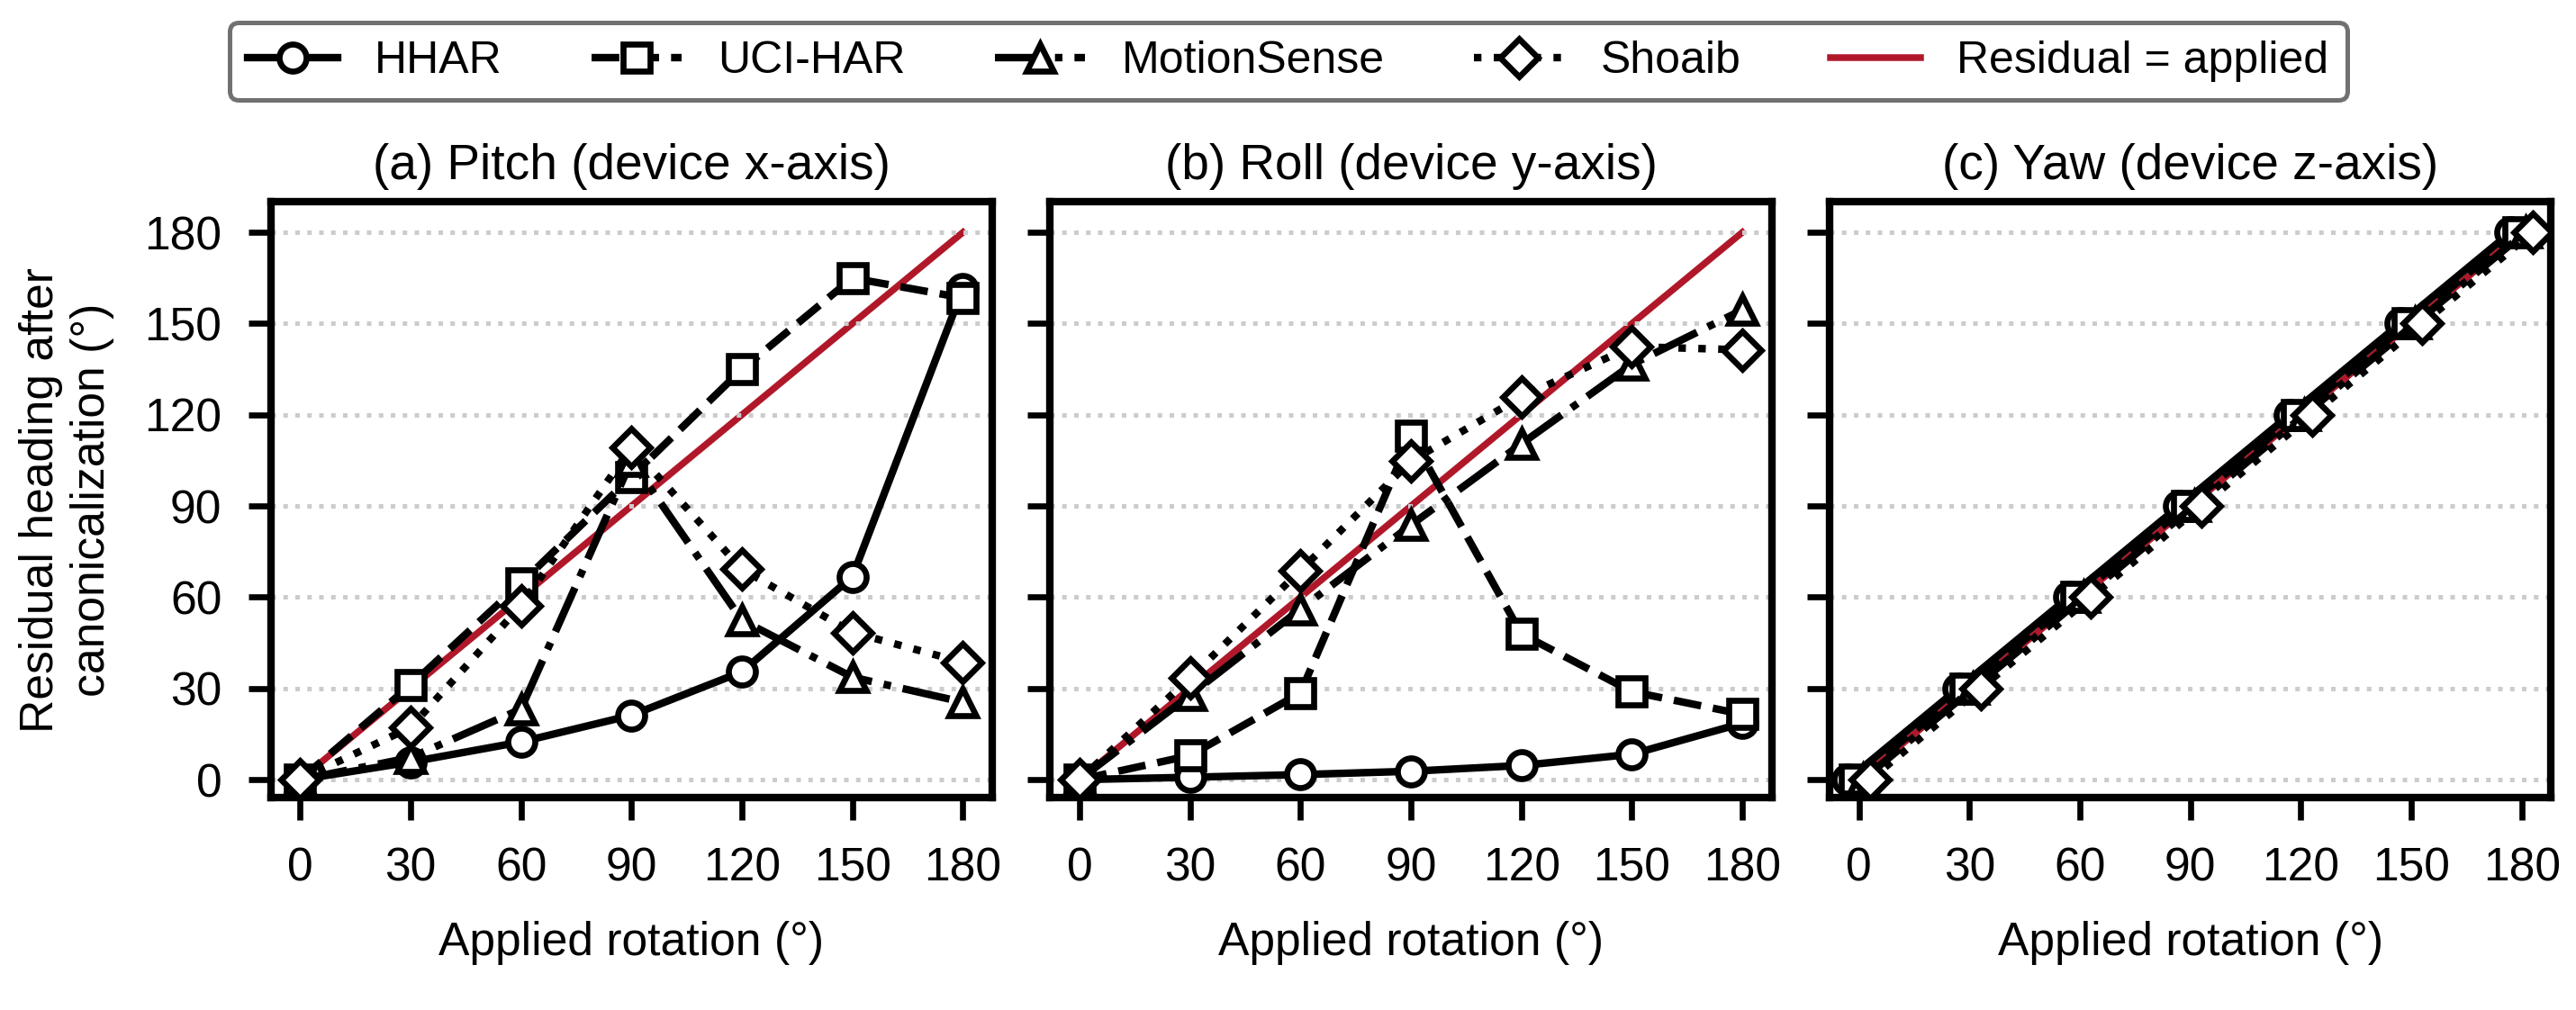

source           hhar                                       uci                \
perturb      device_x      device_y      device_z      device_x      device_y   
angle                                                                           
0.0      4.271798e-16  4.271798e-16  4.271798e-16  9.004121e-16  9.004121e-16   
30.0     5.793454e+00  7.890294e-01  3.000000e+01  3.105120e+01  7.927500e+00   
60.0     1.239725e+01  1.665610e+00  6.000000e+01  6.464700e+01  2.848979e+01   
90.0     2.117419e+01  2.762674e+00  9.000000e+01  9.965344e+01  1.131443e+02   
120.0    3.547427e+01  4.655181e+00  1.200000e+02  1.349411e+02  4.798419e+01   
150.0    6.676254e+01  8.356596e+00  1.500000e+02  1.649701e+02  2.894869e+01   
180.0    1.614427e+02  1.855732e+01  1.800000e+02  1.584683e+02  2.153171e+01   

source                       motion                                    shoaib  \
perturb      device_z      device_x      device_y      device_z      device_x   
angle                                                                           
0.0      9.004121e-16  9.754607e-16  9.754607e-16  9.754607e-16  1.125879e-15   
30.0     3.000000e+01  7.239122e+00  2.778897e+01  3.000000e+01  1.717933e+01   
60.0     6.000000e+01  2.321393e+01  5.610064e+01  6.000000e+01  5.725419e+01   
90.0     9.000000e+01  1.048705e+02  8.371329e+01  9.000000e+01  1.093969e+02   
120.0    1.200000e+02  5.245461e+01  1.104423e+02  1.200000e+02  6.925083e+01   
150.0    1.500000e+02  3.372128e+01  1.365508e+02  1.500000e+02  4.843671e+01   
180.0    1.800000e+02  2.549986e+01  1.545001e+02  1.800000e+02  3.861596e+01   

source                               
perturb      device_y      device_z  
angle                                
0.0      1.125879e-15  1.125879e-15  
30.0     3.342942e+01  3.000000e+01  
60.0     6.881117e+01  6.000000e+01  
90.0     1.047628e+02  9.000000e+01  
120.0    1.259051e+02  1.200000e+02  
150.0    1.424417e+02  1.500000e+02  
180.0    1.413840e+02  1.800000e+02

In [13]:
v5_plan()                     # v5_plan(cost=False) lists the runs without loading the datasets

v5_lodo()
v5_fig3()

**Training stages:** a stage that is called again skips its finished runs.

In [14]:
v5_run("floor")              # identity floor selected on the source, final arm
v5_run("budget")             # 8 runs per cell for the other encoder treatments
v5_run("oit")                # OIT: settings selected on the source, then 8 runs per cell
if RUN_STAGES:
    v5_unimts_time()
v5_run("unimts")             # UniMTS: more runs across datasets
v5_run("unimts_indomain")    # UniMTS: in-domain scores

[skipped] v5 stage floor: RUN_STAGES = False, the existing run logs are used
[skipped] v5 stage budget: RUN_STAGES = False, the existing run logs are used
[skipped] v5 stage oit: RUN_STAGES = False, the existing run logs are used
[skipped] v5 stage unimts: RUN_STAGES = False, the existing run logs are used
[skipped] v5 stage unimts_indomain: RUN_STAGES = False, the existing run logs are used


**Summary and analysis with these runs in place:**

In [15]:
import os
_d = os.path.join(REV_DIR, "runs")
if RUN_STAGES:      # moves the logs of unfinished UniMTS runs out of the analysis; never replaces a moved log
    os.makedirs(os.path.join(_d, "partial"), exist_ok=True)
    for _f in ("unimts_v5.csv", "ceiling_v5.csv"):
        if os.path.exists(os.path.join(_d, _f)):
            if os.path.exists(os.path.join(_d, "partial", _f)):
                print("kept", _f, "in runs/: runs/partial already holds a file of this name")
            else:
                os.rename(os.path.join(_d, _f), os.path.join(_d, "partial", _f))
                print("moved", _f, "to runs/partial")
print("UniMTS logs used by the analysis:", sorted(f for f in os.listdir(_d) if "unimts" in f))

v5_report()

v5_make_all()

v5_lodo()

cross, indom = v5_cross(), v5_indomain()
show = lambda name: print(pd.read_csv(_v5_out(name)).to_string(index=False))

print("=== 1. Macro-F1 / stairs-F1 per pair; last rows: mean, final configuration minus method [95% CI] ===")
show("T9_main_matrix.csv")

print("\n=== 2. 2 x 2 ablation: mean, s.d. and number of runs per cell; contrasts per pair ===")
abl = ["A_ssl", "B_grav", "C_yawft", "D_ft"]
g = cross[cross.arm.isin(abl)].groupby(["pair", "arm"]).macro_f1
print(pd.concat({"mean": g.mean().unstack()[abl], "sd": g.std(ddof=1).unstack()[abl],
                 "runs": g.size().unstack()[abl]}, axis=1).round(3).to_string())
show("T4_ablation_final.csv")

print("\n=== 3. Fraction of the gap closed per pair ===")
show("T1_gap_fraction_per_pair.csv")

print("\n=== 4. Final configuration: run-to-run s.d. within a cell, mean per source ===")
sd = cross[cross.arm == "D_ft"].groupby(["source", "target"]).macro_f1.std(ddof=1)
print(sd.groupby(level=0).mean().round(3).to_string())

print("\n=== 5. Runs repeated after the source check and runs that stayed below 0.5 on the source ===")
show("T10_failure_check.csv")

print("\n=== 6. Main table and differences without the runs that stayed below 0.5 on the source ===")
enc = abl + ["E_so3aug", "F_so3inv", "G_pca", "H_mizell", "I_oit2"]
bad = _v5_extra(cross).map(lambda e: e.get("src_f1", 1.0) < 0.5) & cross.arm.isin(enc)
print("excluded runs:", int(bad.sum()), cross[bad].groupby("arm").size().to_dict())
_dir = os.path.join(REV_DIR, "tables", "v5_without_failed")
os.makedirs(_dir, exist_ok=True)
with _v5_patched(_out=lambda name: os.path.join(_dir, name)):
    gap_fraction(cross[~bad], indom)
    differences(cross[~bad])

UniMTS logs used by the analysis: ['unimts.csv', 'unimts_v2.csv']

=== 1. Identity floor selected on the source (final arm) ===
held-out source subjects, rotated: mean macro-F1 by floor
arm     Dft_f0.0  Dft_f0.3  Dft_f0.5
source                              
hhar      0.9381    0.9311    0.9284
motion    0.9120    0.9103    0.9112
shoaib    0.9566    0.9692    0.9674
uci       0.9583    0.9681    0.9214
selected floor: HHAR 0, MotionSense 0, Shoaib 0.3, UCI-HAR 0.3
mean macro-F1 over 12 pairs: source-selected floor 0.688, fixed floor 0.683; difference +0.005, 95% CI [-0.016, +0.029], Wilcoxon p = 0.219

=== 2. Runs per cell (cross-dataset, 12 pairs) ===
                                     label  min  max  pairs
A_ssl               Encoder (device frame)    8    8     12
B_grav                    Canonicalization    8    8     12
C_yawft       Heading aug. only (device z)    8    8     12
D_ft                 Canon. + heading aug.    8    8     12
E_so3aug                        SO(3)

## 11. Numerical checks of Lemma 1, Corollary 1 and Propositions 1 to 3 and 6

The labels follow the numbering of the paper. Checks labelled "additional" concern identities that the paper does not state. Corollary 2 and Propositions 4 and 5 are checked by `v6_verify()` in Section 12.

In [16]:
%%writefile verify_propositions.py
"""Numerical checks of the formal statements of the paper
(Lemma 1, Corollary 1, Propositions 1 to 3 and 6, Eqs. 3 and 9) and of additional identities.

Run:  python3 verify_propositions.py        (needs only NumPy; about one minute)

The functions follow the implementation in the notebook
(rot_to_vertical_batch, canonicalize, pca_heading, mizell_transform, oit_transform).
A check prints PASS when the largest deviation is below its tolerance.
Checks labelled "additional" concern identities that the paper does not state.
"""
import numpy as np

rng = np.random.default_rng(0)
Z = np.array([0.0, 0.0, 1.0])
GATE = 5.0 / 9.80665            # threshold of Eq. 2 in g
RESULTS = []


def report(name, err, tol):
    ok = bool(err <= tol)
    RESULTS.append(ok)
    print("%-4s %-66s max deviation %.2e (tolerance %.0e)" % ("PASS" if ok else "FAIL", name, err, tol))


# Rotations
def skew(v):
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])


def rot(axis, th):
    """Rot(u, theta): rotation by theta about the unit vector u."""
    a = np.asarray(axis, float)
    a = a / np.linalg.norm(a)
    K = skew(a)
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def rotz(th):
    return rot(Z, th)


def R_min(g):
    """Eq. 3 with the conventions of the code (Algorithm 1, lines 6 to 8)."""
    v = np.cross(g, Z)
    c = float(g @ Z)
    s = np.linalg.norm(v)
    if s <= 1e-8:
        return np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
    K = skew(v)
    return np.eye(3) + K + K @ K * ((1 - c) / (s * s))


def R_second_form(g):
    """Eq. 3 in the equivalent form with (1 - c)/s^2 = 1/(1 + c)."""
    K = skew(np.cross(g, Z))
    return np.eye(3) + K + K @ K / (1 + float(g @ Z))


def R_explicit(g):
    """Eq. 3 written out entry by entry."""
    gx, gy, gz = g
    d = 1 + gz
    return np.array([[1 - gx * gx / d, -gx * gy / d, -gx],
                     [-gx * gy / d, 1 - gy * gy / d, -gy],
                     [gx, gy, gz]])


def R_ab(a, b):
    """Minimal rotation that carries the unit vector a to the unit vector b (b != -a)."""
    K = skew(np.cross(a, b))
    return np.eye(3) + K + K @ K / (1 + float(a @ b))


def haar():
    """Uniformly distributed rotation (normalized Gaussian quaternion), as in SO(3) augmentation (Sec. 3.5)."""
    q = rng.normal(size=4)
    w, x, y, z = q / np.linalg.norm(q)
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)],
                     [2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
                     [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)]])


def unit():
    v = rng.normal(size=3)
    return v / np.linalg.norm(v)


def wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


def heading(S):
    return np.arctan2(S[1, 0], S[0, 0])


def S_of(Q, g):
    """S(Q) of Proposition 1."""
    return R_min(Q @ g) @ Q @ R_min(g).T


def Omega(a, b, c):
    """Signed area of the spherical triangle (a, b, c) (additional identity)."""
    return 2 * np.arctan2(a @ np.cross(b, c), 1 + a @ b + b @ c + c @ a)


# Windows
def window(T=51):
    """Synthetic window: gravity along a random direction plus motion, shape [T, 6]."""
    u = unit()
    t = np.arange(T)[:, None]
    acc = u + 0.3 * rng.normal(size=(T, 3)) + 0.2 * np.sin(0.4 * t) * unit()
    gyr = 0.8 * rng.normal(size=(T, 3))
    return np.hstack([acc, gyr])


def act(Q, X):
    """Eq. 1."""
    return np.hstack([X[:, :3] @ Q.T, X[:, 3:] @ Q.T])


def g_hat(X):
    m = X[:, :3].mean(0)
    return m / np.linalg.norm(m), np.linalg.norm(m)


def canonicalize(X):
    """Eq. 4 with the threshold of Eq. 2."""
    g, n = g_hat(X)
    return X if n < GATE else act(R_min(g), X)


def pca_heading(Xc):
    """PCA heading alignment of Sec. 3.5."""
    H = Xc[:, :2] - Xc[:, :2].mean(0)
    w, V = np.linalg.eigh(H.T @ H)
    p = V[:, 1]
    if ((H @ p) ** 3).mean() < 0:
        p = -p
    return act(rotz(-np.arctan2(p[1], p[0])), Xc)


def mizell(X):
    """Vertical-horizontal decomposition of Sec. 3.5."""
    g, _ = g_hat(X)
    out = []
    for v in (X[:, :3], X[:, 3:]):
        par = v @ g
        out += [par, np.linalg.norm(v - par[:, None] * g, axis=1)]
    return np.stack(out, 1)


def angle(a, b):
    na, nb = np.linalg.norm(a, axis=-1), np.linalg.norm(b, axis=-1)
    nn = na * nb
    cos = (a * b).sum(-1) / np.where(nn > 0, nn, 1.0)
    return np.where(nn > 0, np.arccos(np.clip(cos, -1.0, 1.0)), 0.0)


def oit(X):
    """Orientation-invariant transformation of Sec. 3.5."""
    L = X.shape[0]
    chans = []
    for v in (X[:, :3], X[:, 3:]):
        d1 = v[1:] - v[:-1]
        d2 = d1[1:] - d1[:-1]
        seqs = [np.linalg.norm(v, axis=1), np.linalg.norm(d1, axis=1), np.linalg.norm(d2, axis=1),
                angle(v[:-1], v[1:]), angle(d1[:-1], d1[1:]), angle(d2[:-1], d2[1:])]
        for u in (v, d1, d2):
            n = np.cross(u[:-1], u[1:])
            seqs.append(angle(n[:-1], n[1:]))
        chans += [np.concatenate([s, np.repeat(s[-1:], L - len(s))]) for s in seqs]
    return np.stack(chans, 1)


N = 20000

# Eq. 3
e = 0.0
for _ in range(N):
    g = unit()
    R = R_min(g)
    e = max(e, np.abs(R - R_second_form(g)).max(), np.abs(R - R_explicit(g)).max(), np.abs(R @ g - Z).max(),
            np.abs(R @ R.T - np.eye(3)).max(), abs(np.linalg.det(R) - 1))
report("Eq. 3: equivalent forms and the explicit matrix agree; R g = z; R in SO(3)", e, 1e-7)

# Lemma 1
viol, eq_err = -np.inf, 0.0
for _ in range(N):
    u = unit()
    r = rng.uniform(0, 0.99)
    a = u + unit() * r
    viol = max(viol, np.arccos(np.clip(a @ u / np.linalg.norm(a), -1, 1)) - np.arcsin(r))
    # equality case: mean body acceleration orthogonal to the estimate (tangent to the ball)
    w = np.cross(u, unit())
    w /= np.linalg.norm(w)
    a = np.sqrt(1 - r * r) * (np.sqrt(1 - r * r) * u + r * w)
    b = a - u
    eq_err = max(eq_err, abs(np.linalg.norm(b) - r), abs(b @ a),
                 abs(np.arccos(np.clip(a @ u / np.linalg.norm(a), -1, 1)) - np.arcsin(r)))
report("Lemma 1: angle(g_hat, u) <= arcsin(|b|/g0)", max(viol, 0.0), 1e-9)
report("Lemma 1: equality when the mean body acceleration is orthogonal to g_hat", eq_err, 1e-7)

# Proposition 1 and Corollary 1
e1 = e2 = 0.0
for _ in range(2000):
    X = window()
    Q = haar()
    g, n = g_hat(X)
    S = S_of(Q, g)
    e1 = max(e1, np.abs(S @ Z - Z).max(), np.abs(S - rotz(heading(S))).max())
    e2 = max(e2, np.abs(canonicalize(act(Q, X)) - act(rotz(heading(S)), canonicalize(X))).max())
report("Prop. 1: S(Q) z = z and S(Q) is a rotation about z", e1, 1e-7)
report("Prop. 1: C(QX) = S(Q) C(X) on windows", e2, 1e-7)

# Proposition 2
ea = eb = ec = 0.0
for _ in range(N):
    g = unit()
    th = rng.uniform(-np.pi, np.pi)
    ea = max(ea, np.abs(R_min(rotz(th) @ g) - rotz(th) @ R_min(g) @ rotz(th).T).max(),
             np.abs(S_of(rotz(th), g) - rotz(th)).max())
    eb = max(eb, np.abs(S_of(rot(g, th), g) - rotz(th)).max())
    Q = haar()
    b = Q @ g
    twist = R_ab(g, b).T @ Q                              # leaves g fixed: Rot(g, tau)
    tau = heading(R_min(g) @ twist @ R_min(g).T)
    ec = max(ec, np.abs(twist @ g - g).max(), abs(wrap(heading(S_of(Q, g)) - tau - Omega(g, b, Z))))
report("Prop. 2a: R(RotZ g) = RotZ R(g) RotZ^T and S(RotZ) = RotZ", ea, 1e-7)
report("Prop. 2b (and Cor. 1, necessity): S(Q_theta) = RotZ_theta", eb, 1e-7)
report("Additional: psi = tau + Omega(g, Qg, z) (mod 2 pi)", ec, 1e-6)

# Additional identities
e1 = e2 = e3 = 0.0
for _ in range(N):
    A = haar()
    u, a, b = unit(), unit(), unit()
    th = rng.uniform(-np.pi, np.pi)
    e1 = max(e1, np.abs(A @ rot(u, th) @ A.T - rot(A @ u, th)).max(),
             np.abs(A @ R_ab(a, b) @ A.T - R_ab(A @ a, A @ b)).max())
    g = unit()
    H = R_ab(b, Z) @ R_ab(g, b) @ R_ab(Z, g)
    e2 = max(e2, np.abs(H - rotz(Omega(Z, g, b))).max(), abs(wrap(Omega(Z, g, b) - Omega(g, b, Z))))
    # A.3 against the spherical excess, for small triangles
    p = unit()
    q1, q2 = p + 0.3 * rng.normal(size=3), p + 0.3 * rng.normal(size=3)
    q1, q2 = q1 / np.linalg.norm(q1), q2 / np.linalg.norm(q2)

    def corner(x, y, w):
        t1, t2 = y - (y @ x) * x, w - (w @ x) * x
        return np.arccos(np.clip(t1 @ t2 / np.linalg.norm(t1) / np.linalg.norm(t2), -1, 1))
    excess = corner(p, q1, q2) + corner(q1, q2, p) + corner(q2, p, q1) - np.pi
    e3 = max(e3, abs(abs(Omega(p, q1, q2)) - excess))
report("Additional: conjugation identities", e1, 1e-6)
report("Additional: H = RotZ of Omega(z, g, b); cyclic symmetry of Omega", e2, 1e-6)
report("Additional: |Omega| equals the spherical excess (area) of the triangle", e3, 1e-6)
octant = R_ab(np.array([0.0, 1, 0]), Z) @ R_ab(np.array([1.0, 0, 0]), np.array([0.0, 1, 0])) @ R_ab(Z, np.array([1.0, 0, 0]))
report("Additional example: g = e_x, b = e_y gives H = RotZ(pi/2)", np.abs(octant - rotz(np.pi / 2)).max(), 1e-9)

# Proposition 3
e = 0.0
eps = 1e-5
for th_deg in (10, 45, 90, 135, 165, 175):
    th = np.radians(th_deg)
    ph = rng.uniform(-np.pi, np.pi)
    g = np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])
    e_th = np.array([np.cos(th) * np.cos(ph), np.cos(th) * np.sin(ph), -np.sin(th)])   # increasing polar angle
    e_ph = np.array([-np.sin(ph), np.cos(ph), 0.0])                                     # increasing azimuth
    for xi in np.linspace(0, 2 * np.pi, 25):
        gp = g + eps * (np.cos(xi) * e_th + np.sin(xi) * e_ph)
        gp /= np.linalg.norm(gp)
        d = heading(R_min(gp) @ R_min(g).T)
        e = max(e, abs(d / eps - np.tan(th / 2) * np.sin(xi)) / max(1.0, np.tan(th / 2)))
report("Prop. 3: d(psi) = eps tan(beta/2) sin(xi), xi from the meridian (= cos(chi) of the paper), relative", e, 1e-3)

# Proposition 6
em = eo = ep = 0.0
for _ in range(2000):
    X = window()
    Q = haar()
    em = max(em, np.abs(mizell(act(Q, X)) - mizell(X)).max())
    eo = max(eo, np.abs(oit(act(Q, X)) - oit(X)).max())
    ep = max(ep, np.abs(pca_heading(canonicalize(act(Q, X))) - pca_heading(canonicalize(X))).max())
report("Prop. 6a: Phi_VH(QX) = Phi_VH(X) (decomposition of Mizell)", em, 1e-7)
report("Prop. 6a: Phi_OIT(QX) = Phi_OIT(X) (OIT)", eo, 1e-5)
report("Prop. 6b: Phi_PCA(C(QX)) = Phi_PCA(C(X)) (PCA heading alignment)", ep, 1e-6)

# Eq. 9
e = 0.0
for _ in range(1000):
    f_in = rng.uniform(0.8, 1.0, 12)
    f_raw = rng.uniform(0.2, 0.6, 12)
    f_m = rng.uniform(0.3, 0.8, 12)
    G = f_in - f_raw
    phi = (f_m - f_raw).sum() / G.sum()
    e = max(e, np.abs(G - (f_m - f_raw) - (f_in - f_m)).max(), abs(phi + (f_in - f_m).mean() / G.mean() - 1))
report("Eq. 9: G = gain + residual for every pair, and phi_m + R_m / mean gap = 1", e, 1e-12)

# Measured sensitivity (Sec. 3.2.4)
print("\nMedian heading change for Gaussian errors of 1 degree per axis in g_hat (as in the notebook),")
print("compared with 0.6745 tan(theta/2) from Proposition 3:")
for th_deg in (20.0, 81.0, 165.0, 171.3):
    th = np.radians(th_deg)
    dh = []
    for _ in range(4000):
        ph = rng.uniform(-np.pi, np.pi)
        g = np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])
        p = g + np.radians(1.0) * rng.normal(size=3)
        p /= np.linalg.norm(p)
        dh.append(abs(np.degrees(heading(R_min(p) @ R_min(g).T))))
    print("  theta = %6.1f deg: simulated median %5.2f deg, formula %5.2f deg"
          % (th_deg, np.median(dh), 0.6745 * np.tan(th / 2)))

print("\n%d of %d checks passed." % (sum(RESULTS), len(RESULTS)))

Writing verify_propositions.py


In [ ]:
!python verify_propositions.py

## 12. Treated in-domain reference, attribution, concordance and protocol verdicts

These analyses train nothing. They read the run logs through `v5_cross()` and `v5_indomain()` and use the bootstrap of Section 9 (`Cells`, `hboot`, `contrast`), which is Algorithm 2 of the paper. They write only to `tables/v6/`.

| Function | Content | Paper |
|---|---|---|
| `v6_did()` | In-domain effect of a treatment and the fraction of the gap closed with the treated in-domain reference | Definition 2, Sec. 4.5 |
| `v6_shapley()` | Order-averaged attribution of the joint gain to canonicalization and heading augmentation | Sec. 4.7 |
| `v6_agreement()` | Treatment effect against the treatment-by-pair interaction; Kendall's W with its reference under permutation | Sec. 4.6 |
| `v6_contrasts()` | The 15 contrasts with both verdicts of the reporting protocol, and the contrasts with the SO(3) treatments at the same identity floor | Algorithm 3, Sec. 4.6 |
| `v6_verify()` | Numerical checks of Eq. 3, Corollary 2 and Propositions 3 to 5 (NumPy only) | Secs. 3.2 and 3.4 |
| `v6_check_canon()` | Optional, needs the datasets: Eq. 3 written as 1/(1 + c) against the implemented form on the windows | Algorithm 1 |

`v6_all()` runs the first five and writes `tables/v6/manuscript_numbers_v6.json`. The first cell below defines the functions and the second cell calls `v6_all()`. Section 14 repeats these analyses with the SO(3) runs of Section 13.

In [ ]:
# Analyses from the run logs: treated in-domain reference, attribution, concordance, contrasts
# Uses the definitions of Sections 9 and 10. Output: tables/v6.
import inspect
import itertools
import json
import os

import numpy as np
import pandas as pd

V6_TAG = "v6"
V6_FINAL = "D_ft"
V6_DELTA = 0.05
_V6_NEED = ["REV_DIR", "load_cross", "load_indomain", "Cells", "hboot", "_ci", "_units_for", "contrast",
            "FAMILIES", "LABEL", "FULL_TREAT", "kendall_w", "anova_two_way", "_holm"]
V6_NUM = {}                               # values for the paper, written to manuscript_numbers_v6.json


def _v6_p(*a):
    print(*a, flush=True)


def _v6_need(names=None, what="the analysis code (Sections 9 and 10 of the notebook)"):
    miss = [n for n in (names or _V6_NEED) if n not in globals()]
    if miss:
        raise RuntimeError(f"{what} is not defined yet (missing: {', '.join(miss)}). Run those cells first.")


def _v6_out(name):
    d = os.path.join(REV_DIR, "tables", V6_TAG)
    os.makedirs(d, exist_ok=True)
    return os.path.join(d, name)


def v6_cross():
    """Cross-dataset runs used by the analysis (v5_cross when Section 10 is loaded)."""
    _v6_need()
    return (globals().get("v5_cross") or load_cross)()


def v6_indomain():
    _v6_need()
    return (globals().get("v5_indomain") or load_indomain)()


def _v6_ci_txt(ci, pct=False):
    if ci is None or np.isnan(ci[0]):
        return "n/a"
    txt = f"{100 * ci[0]:.0f}% to {100 * ci[1]:.0f}%" if pct else f"{ci[0]:+.3f} to {ci[1]:+.3f}"
    return txt.replace("-", "−")              # minus sign as in the paper


# 1. Definition 2: in-domain effect and the fraction with the treated in-domain reference
# For a treatment m with treated in-domain runs:
#   in-domain effect   D_in(p)  = F1_in,m(p) - F1_in(p)
#   shift-specific     D_did(p) = [F1_m(p) - F1_raw(p)] - D_in(p)
#   phi_did            = sum_p D_did(p) / sum_p [F1_in(p) - F1_raw(p)]
# Intervals: hboot (datasets, then seeds; in-domain: folds, then seeds), as for phi.
# Treated in-domain runs exist for B_grav (ceiling_strict), D_ft (ceiling_v4) and XGB_canon
# (ceiling_strict).
def v6_did(cross=None, indom=None, n_boot=None, save=True):
    _v6_need()
    cross = v6_cross() if cross is None else cross
    indom = v6_indomain() if indom is None else indom
    C = Cells(cross, indom)
    rows = []
    for fam, Fm in FAMILIES.items():
        raw = Fm["raw"]
        for m in Fm["treat"]:
            pairs = [p for p in C.pairs if C.has(p, raw) and C.has(p, m) and C.has(p, raw, indom=True)
                     and C.has(p, m, indom=True)]
            if not pairs:
                continue
            gap = np.array([C.m(p, raw, True) - C.m(p, raw) for p in pairs])
            gain = np.array([C.m(p, m) - C.m(p, raw) for p in pairs])
            din = np.array([C.m(p, m, True) - C.m(p, raw, True) for p in pairs])

            def stat(rng, sel, raw=raw, m=m):
                num = den = dd = 0.0
                di = []
                for p in sel:
                    cr, ci = C.r(p, raw, rng), C.r(p, raw, rng, indom=True)
                    cm, cim = C.r(p, m, rng), C.r(p, m, rng, indom=True)
                    num += cm - cr
                    den += ci - cr
                    dd += (cm - cr) - (cim - ci)
                    di.append(cim - ci)
                ok = den > 1e-9
                return {"phi": num / den if ok else np.nan, "did": dd / den if ok else np.nan,
                        "din": float(np.mean(di))}

            bs = pd.DataFrame(hboot(pairs, _units_for(pairs), stat, n_boot=n_boot))
            rows.append({"family": fam, "treatment": m, "label": LABEL.get(m, m), "n_pairs": len(pairs),
                         "gap": float(gap.mean()), "gain": float(gain.mean()),
                         "phi": float(gain.sum() / gap.sum()),
                         "in_domain_treated": float(np.mean([C.m(p, m, True) for p in pairs])),
                         "in_domain_effect": float(din.mean()), "in_domain_effect_ci": _ci(bs["din"]),
                         "gap_treated": float(np.mean([C.m(p, m, True) - C.m(p, m) for p in pairs])),
                         "phi_did": float((gain.sum() - din.sum()) / gap.sum()), "phi_did_ci": _ci(bs["did"])})
    T = pd.DataFrame(rows)
    if T.empty:
        _v6_p("[v6_did] no treatment has both cross-dataset and treated in-domain runs "
              "(expected logs: ceiling_strict.csv and ceiling_v4.csv)")
        return T
    show = T.copy()
    show["in_domain_effect_ci"] = show["in_domain_effect_ci"].map(_v6_ci_txt)
    show["phi_did_ci"] = show["phi_did_ci"].map(lambda c: _v6_ci_txt(c, pct=True))
    if save:
        show.round(4).to_csv(_v6_out("T_did_v6.csv"), index=False)
    _v6_p("\n=== Definition 2: in-domain effect and fraction of the gap closed with the treated in-domain reference ===")
    _v6_p(show[["family", "label", "n_pairs", "gap", "gain", "phi", "in_domain_effect", "in_domain_effect_ci",
                "phi_did", "phi_did_ci"]].round(3).to_string(index=False))
    R = T.set_index("treatment")
    for m, r in R.iterrows():
        V6_NUM[f"did.{m}.phi_did"] = round(r.phi_did, 3)
        V6_NUM[f"did.{m}.phi_did_ci"] = [round(float(v), 3) for v in r.phi_did_ci]
        V6_NUM[f"did.{m}.in_domain_effect"] = round(r.in_domain_effect, 3)
        V6_NUM[f"did.{m}.n_pairs"] = int(r.n_pairs)
    want = ["B_grav", V6_FINAL, "XGB_canon"]
    if all(m in R.index for m in want):
        f = lambda m: f"{100 * R.loc[m, 'phi_did']:.0f}%"
        c = lambda m: _v6_ci_txt(R.loc[m, "phi_did_ci"], pct=True)
        e = lambda m: f"{R.loc[m, 'in_domain_effect']:+.3f}".replace("-", "−")
        _v6_p("\nParagraph for Sec. 4.5 (replaces the highlighted paragraph of the manuscript):\n")
        _v6_p(f"With the in-domain reference treated in the same way (Definition 2), canonicalization and "
              f"canonicalization with heading augmentation closed {f('B_grav')} (95% CI {c('B_grav')}) and "
              f"{f(V6_FINAL)} ({c(V6_FINAL)}) of the encoder gap, and canonicalization closed {f('XGB_canon')} "
              f"({c('XGB_canon')}) of the XGBoost gap. The in-domain effects Δ_m^in, that is, the part of each "
              f"gain that the treatment also produces without a change of dataset, were {e('B_grav')}, {e(V6_FINAL)} "
              f"and {e('XGB_canon')} macro-F1.")
        if any(R.loc[m, "n_pairs"] != 12 for m in want):
            _v6_p("\nNOTE: not every treatment has all 12 pairs; state the number of pairs in the text.")
    else:
        _v6_p(f"\n[v6_did] treated in-domain runs missing for {[m for m in want if m not in R.index]}; "
              "the paragraph of Sec. 4.5 cannot be completed for them.")
    return T


# 2. Order-averaged attribution of the joint gain (Sec. 4.7)
def v6_shapley(cross=None, n_boot=None, heading_only="C_yawft"):
    _v6_need()
    cross = v6_cross() if cross is None else cross
    C = Cells(cross)
    A, B, H, D = "A_ssl", "B_grav", heading_only, V6_FINAL
    pairs = [p for p in C.pairs if all(C.has(p, a) for a in (A, B, H, D))]
    if not pairs:
        _v6_p("[v6_shapley] the four arms of the ablation are not complete")
        return None

    def shares(f, pp):
        a, b, h, d = (np.array([f(p, x) for p in pp]) for x in (A, B, H, D))
        return 0.5 * ((b - a) + (d - h)), 0.5 * ((h - a) + (d - b)), d - b - h + a

    sc, sh, si = shares(C.m, pairs)
    T = pd.DataFrame({"canonicalization": sc, "heading": sh, "joint": sc + sh, "interaction": si}, index=pairs)
    bs = pd.DataFrame(hboot(pairs, _units_for(pairs), lambda rng, sel: dict(zip(
        ("canon", "heading"), (float(v.mean()) for v in shares(lambda p, x: C.r(p, x, rng), sel)[:2]))), n_boot=n_boot))
    res = {"canonicalization": float(sc.mean()), "heading": float(sh.mean()), "joint": float((sc + sh).mean()),
           "share_canonicalization": float(sc.sum() / (sc + sh).sum()),
           "canonicalization_ci": _ci(bs["canon"]), "heading_ci": _ci(bs["heading"]),
           "interaction_mean": float(si.mean()), "interaction_max": float(si.max()),
           "interaction_max_pair": pairs[int(np.argmax(si))], "n_pairs": len(pairs)}
    T.round(3).to_csv(_v6_out("T_shapley_v6.csv"))
    for k in ("canonicalization", "heading", "joint", "share_canonicalization"):
        V6_NUM[f"shapley.{k}"] = round(res[k], 3)
    _v6_p("\n=== Order-averaged attribution of the joint gain (Sec. 4.7) ===")
    _v6_p(f"canonicalization {res['canonicalization']:.3f} ({100 * res['share_canonicalization']:.0f}%), 95% CI "
          f"{_v6_ci_txt(res['canonicalization_ci'])}; heading augmentation {res['heading']:.3f} "
          f"({100 * (1 - res['share_canonicalization']):.0f}%), 95% CI {_v6_ci_txt(res['heading_ci'])}; "
          f"joint gain {res['joint']:.3f}")
    _v6_p(f"largest interaction {res['interaction_max']:+.3f} on {res['interaction_max_pair']}")
    _v6_p("manuscript: 0.239 (69%) and 0.105 (31%) of 0.344")
    return T, res


# 3. Consistency of pair ranking and differences in level (Sec. 4.6)
def v6_agreement(cross=None, n_perm=5000, seed=0):
    """Treatment effect against the treatment-by-pair interaction, and Kendall's W with its reference
    under independent permutations of each treatment's scores across pairs."""
    _v6_need()
    cross = v6_cross() if cross is None else cross
    C = Cells(cross)
    treats = [m for m in FULL_TREAT if all(C.has(p, m) for p in C.pairs)]
    pairs = [p for p in C.pairs if C.has(p, "A_ssl")]
    M = np.array([[C.m(p, m) for m in treats] for p in pairs])
    raw = np.array([C.m(p, "A_ssl") for p in pairs])
    G = M - raw[:, None]
    A = anova_two_way(G).set_index("source")
    W = kendall_w(G)[0]
    rng = np.random.default_rng(seed)
    null = np.array([kendall_w(rng.permuted(M, axis=0) - raw[:, None])[0] for _ in range(n_perm)])
    res = {"treatments": treats, "n_pairs": len(pairs),
           "ss_pair": float(A.loc["Transfer pair", "SS"]), "ss_treatment": float(A.loc["Treatment", "SS"]),
           "ss_interaction": float(A.loc["Residual", "SS"]),
           "W_gain": float(W), "W_perm_mean": float(null.mean()), "W_perm_lo": float(np.percentile(null, 2.5)),
           "W_perm_hi": float(np.percentile(null, 97.5)), "W_perm_p": float((null >= W).mean())}
    json.dump(res, open(_v6_out("agreement_v6.json"), "w"), indent=1)
    for k in ("ss_treatment", "ss_interaction", "W_gain", "W_perm_mean", "W_perm_lo", "W_perm_hi"):
        V6_NUM[f"agree.{k}"] = round(res[k], 3)
    _v6_p("\n=== Consistency of pair ranking and differences in level (Sec. 4.6) ===")
    _v6_p(f"sums of squares: treatment {res['ss_treatment']:.3f}, treatment-by-pair interaction "
          f"{res['ss_interaction']:.3f}, pair {res['ss_pair']:.3f}")
    _v6_p(f"Kendall's W of the gains {res['W_gain']:.2f}; under permutation {res['W_perm_mean']:.2f} "
          f"({res['W_perm_lo']:.2f} to {res['W_perm_hi']:.2f})")
    _v6_p("manuscript: interaction 0.104, treatment 0.042; W 0.87; under permutation 0.63 (0.50 to 0.75)")
    return res


# 4. Contrasts with the two verdicts of Algorithm 3
# Same bootstrap draws as contrast(), so the intervals equal those of Table 4 and Supplementary
# Table S1. Added: the difference verdict, the joint reading, a bootstrap p-value with the Holm
# adjustment over the 15 contrasts, and the contrasts with the SO(3) treatments at the same
# identity floor (D_ft_fixed: floor 0.3 on every pair).
def protocol_verdict(L, U, delta=V6_DELTA):
    diff = "above" if L > 0 else ("below" if U < 0 else "not detected")
    eq = "within margin" if (L > -delta and U < delta) else "not established"
    if diff == "above":
        read = "improves by less than the margin" if eq == "within margin" else "improves on the baseline"
    elif diff == "below":
        read = "worse by less than the margin" if eq == "within margin" else "worse than the baseline"
    else:
        read = "equivalent" if eq == "within margin" else "inconclusive"
    return diff, eq, read


def _v6_contrast(C, a, b, delta=V6_DELTA):
    r = contrast(C, a, b, delta=delta)
    if not r:
        return None
    pairs = [p for p in C.pairs if C.has(p, a) and C.has(p, b)]
    seed = inspect.signature(contrast).parameters["seed"].default
    bs = np.array(hboot(pairs, _units_for(pairs),
                        lambda rng, sel: np.mean([C.r(p, a, rng) - C.r(p, b, rng) for p in sel]), seed=seed))
    bs = bs[~np.isnan(bs)]
    r["p_boot"] = float(min(1.0, max(2 * min((bs <= 0).mean(), (bs >= 0).mean()), 1.0 / len(bs))))
    r["difference"], r["equivalence"], r["reading"] = protocol_verdict(r["ci90_lo"], r["ci90_hi"], delta)
    return r


def v6_contrasts(cross=None, delta=V6_DELTA):
    _v6_need()
    cross = v6_cross() if cross is None else cross
    C = Cells(cross)
    full = [m for m in FULL_TREAT if any(C.has(p, m) for p in C.pairs)]
    rows = [dict(r, family="between encoder treatments") for a, b in itertools.combinations(full, 2)
            if (r := _v6_contrast(C, a, b, delta))]
    if rows:
        for r, p in zip(rows, _holm([r["p_boot"] for r in rows])):
            r["p_boot_holm"] = float(p)
    extra = [(V6_FINAL, "XGB_canon", "across families"), ("G_pca", "XGB_canon", "across families"),
             ("H_mizell", "XGB_canon", "across families"),
             ("D_ft_fixed", "E_so3aug", "same identity floor (0.3)"),
             ("D_ft_fixed", "F_so3inv", "same identity floor (0.3)")]
    for a, b, fam in extra:
        r = _v6_contrast(C, a, b, delta)
        if r:
            rows.append(dict(r, family=fam))
    T = pd.DataFrame(rows)
    if T.empty:
        return T
    T.round(4).to_csv(_v6_out("T_contrasts_v6.csv"), index=False)
    cols = ["family", "a", "b", "mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "min_margin"] + \
           (["p_boot_holm"] if "p_boot_holm" in T else []) + ["difference", "equivalence", "reading"]
    _v6_p(f"\n=== Contrasts: 95% and 90% intervals as in Table 4, verdicts of Algorithm 3 at +-{delta} ===")
    _v6_p(T[cols].round(3).to_string(index=False))
    sub = T[T.family == "between encoder treatments"]
    V6_NUM["contrasts.n"] = int(len(sub))
    V6_NUM["contrasts.n_equivalent"] = int((sub.equivalence == "within margin").sum())
    if "p_boot_holm" in sub:
        V6_NUM["contrasts.n_holm_significant"] = int((sub.p_boot_holm < 0.05).sum())
    for _, r in T[T.family.str.startswith("same identity floor")].iterrows():
        V6_NUM[f"matched_floor.{r.a}-{r.b}"] = [round(r.mean_diff, 3), round(r.ci95_lo, 3), round(r.ci95_hi, 3)]
    if (T.family.str.startswith("same identity floor")).any():
        _v6_p("\nSec. 4.6 states the differences at the same floor as 0.057 and 0.045 (from the means); the rows "
              "'same identity floor' give them with intervals.")
    else:
        _v6_p("\n[v6_contrasts] no runs with the selected floor (main_v5.csv, arm D_ft_sel): the contrasts at the "
              "same floor are the contrasts of D_ft above.")
    return T


# 5. Eq. 3 in the form 1/(1 + c) against the implementation (optional, needs the datasets)
def rot_to_vertical_v6(g, eta=1e-6):
    """R = I + [v]x + [v]x^2 / (1 + c), and R = diag(1, -1, -1) when 1 + c < eta."""
    g = np.asarray(g, np.float64)
    c = g[:, 2]
    v = np.stack([g[:, 1], -g[:, 0], np.zeros(len(g))], 1)          # g x z
    z = np.zeros(len(g))
    K = np.stack([np.stack([z, -v[:, 2], v[:, 1]], 1), np.stack([v[:, 2], z, -v[:, 0]], 1),
                  np.stack([-v[:, 1], v[:, 0], z], 1)], 1)
    R = np.eye(3)[None] + K + (K @ K) / np.maximum(1 + c, eta)[:, None, None]
    R[1 + c < eta] = np.diag([1.0, -1.0, -1.0])
    return R


def v6_check_canon(datasets=None):
    """Algorithm 1 states the branches of rot_to_vertical_batch. The check reports how many windows fall
    into each branch and how far the form 1/(1 + c) of Eq. 3 is from the implemented form (1 - c)/s^2 on
    the windows."""
    _v6_need(["get_ds", "gravity_dirs", "rot_to_vertical_batch", "rotate_windows", "REV", "DATASETS_REV"],
             "the experiment code (Section 3 of the notebook)")
    rows = []
    for d in (datasets or DATASETS_REV):
        X = get_ds(d)[0]
        g, n = gravity_dirs(X)
        ok = n >= REV["gate_g"]
        s = np.linalg.norm(np.cross(g, np.array([0.0, 0.0, 1.0])), axis=1)
        diff = np.abs(rotate_windows(X[ok], rot_to_vertical_batch(g[ok])) -
                      rotate_windows(X[ok], rot_to_vertical_v6(g[ok]))).reshape(int(ok.sum()), -1).max(1)
        rows.append({"dataset": d, "windows": len(X), "below_threshold": int((~ok).sum()),
                     "branch_s_le_1e-8": int((s[ok] <= 1e-8).sum()), "max_abs_diff_of_forms": float(diff.max())})
    T = pd.DataFrame(rows)
    _v6_p(T.to_string(index=False))
    T.to_csv(_v6_out("check_canon.csv"), index=False)
    return T


# 6. Numerical checks of Corollary 2 and Propositions 3 to 5 (NumPy only)
def v6_verify(n=20000, seed=0):
    """Eq. 3 in both forms, Corollary 2, Propositions 3, 4 and 5."""
    rng = np.random.default_rng(seed)
    Z = np.array([0.0, 0.0, 1.0])
    res = []

    def report(name, err, tol):
        res.append(bool(err <= tol))
        _v6_p("%-4s %-76s %.2e (tolerance %.0e)" % ("PASS" if err <= tol else "FAIL", name, err, tol))

    def skew(v):
        return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

    def rot(axis, th):
        a = np.asarray(axis, float) / np.linalg.norm(axis)
        K = skew(a)
        return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K

    def R_min(g):                                   # the implementation (Algorithm 1, lines 6 to 8)
        v = np.cross(g, Z)
        c = float(g @ Z)
        s = np.linalg.norm(v)
        if s <= 1e-8:
            return np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
        K = skew(v)
        return np.eye(3) + K + K @ K * ((1 - c) / (s * s))

    def haar():
        q = rng.normal(size=4)
        w, x, y, z = q / np.linalg.norm(q)
        return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)],
                         [2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
                         [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)]])

    def unit():
        v = rng.normal(size=3)
        return v / np.linalg.norm(v)

    def act(R, X):                                  # Eq. 1
        return np.hstack([X[:, :3] @ R.T, X[:, 3:] @ R.T])

    head = lambda S: np.arctan2(S[1, 0], S[0, 0])

    # Eq. 3: the two forms agree and R g = z
    g = np.stack([unit() for _ in range(n)])
    R1 = rot_to_vertical_v6(g)
    e = max(np.abs(R1[i] - R_min(g[i])).max() for i in range(0, n, 10))
    report("Eq. 3: the form 1/(1 + c) equals the form (1 - c)/s^2; R g = z",
           max(e, np.abs(np.einsum("nij,nj->ni", R1, g) - Z).max()), 1e-9)

    # Corollary 2: uniform residual heading under a Haar mounting, for fixed g, for two sections
    ks = 0.0
    for gg in (np.array([0.3, 0.1, 0.95]), np.array([0.97, 0.2, 0.1]), np.array([0.1, -0.2, -0.97])):
        gg = gg / np.linalg.norm(gg)
        for twist in (0.0, 1.0):                    # second section: R'(g) = RotZ(g_x + 2 g_y) R_min(g)
            sec = lambda h: rot(Z, twist * (h[0] + 2 * h[1])) @ R_min(h)
            psi = np.sort([head(sec(Q @ gg) @ Q @ sec(gg).T) for Q in (haar() for _ in range(n))])
            ks = max(ks, np.abs((psi + np.pi) / (2 * np.pi) - (np.arange(n) + 0.5) / n).max())
    report("Cor. 2: residual heading uniform under a Haar mounting (largest KS distance, 6 cases)", ks,
           1.95 / np.sqrt(n))

    # Proposition 3: the frame turns about the vertical by tan(beta/2) eps cos(chi)
    e, eps = 0.0, 1e-5
    for b_deg in (10, 45, 90, 135, 165, 175):
        b = np.radians(b_deg)
        ph = rng.uniform(-np.pi, np.pi)
        gg = np.array([np.sin(b) * np.cos(ph), np.sin(b) * np.sin(ph), np.cos(b)])
        e_b = np.array([np.cos(b) * np.cos(ph), np.cos(b) * np.sin(ph), -np.sin(b)])    # along the meridian
        e_p = np.array([-np.sin(ph), np.cos(ph), 0.0])                                  # along the parallel
        for chi in np.linspace(0, 2 * np.pi, 25):
            gp = gg + eps * (np.cos(chi) * e_p + np.sin(chi) * e_b)
            gp /= np.linalg.norm(gp)
            e = max(e, abs(head(R_min(gp) @ R_min(gg).T) / eps - np.tan(b / 2) * np.cos(chi)) / max(1.0, np.tan(b / 2)))
    report("Prop. 3: rotation about the vertical = eps tan(beta/2) cos(chi), first order (relative)", e, 1e-3)

    # Proposition 4 (i), (ii): two sections differ by a rotation about z; an invariant f does not see it
    f = lambda X: np.concatenate([X[:, 2], np.linalg.norm(X[:, :2], axis=1), X[:, 5], np.linalg.norm(X[:, 3:5], axis=1)])
    e1 = e2 = 0.0
    for _ in range(2000):
        X = np.hstack([unit() + 0.3 * rng.normal(size=(51, 3)), rng.normal(size=(51, 3))])
        gh = X[:, :3].mean(0)
        gh /= np.linalg.norm(gh)
        Ra = R_min(gh)
        Rb = rot(Z, 3.0 * gh[0] + 1.7 * gh[1]) @ Ra
        e1 = max(e1, np.abs((Rb @ Ra.T) @ Z - Z).max())
        e2 = max(e2, np.abs(f(act(Ra, X)) - f(act(Rb, X))).max())
    report("Prop. 4(i): R'(g) R(g)^T fixes z", e1, 1e-9)
    report("Prop. 4(ii): a heading-invariant function does not depend on the section", e2, 1e-9)

    # Proposition 4 (iii): continuity across g = -z
    X0 = np.hstack([0.05 * rng.normal(size=(51, 3)), rng.normal(size=(51, 3))])
    X0[:, :3] += -Z - X0[:, :3].mean(0)             # mean acceleration exactly -z
    outs, xs = [], []
    for ang in np.linspace(0, 2 * np.pi, 13)[:-1]:
        X = act(rot(np.array([np.cos(ang), np.sin(ang), 0.0]), 1e-6), X0)      # tilted by 1e-6 rad, 12 directions
        gh = X[:, :3].mean(0)
        gh /= np.linalg.norm(gh)
        Cx = act(R_min(gh), X)
        outs.append(f(Cx))
        xs.append(Cx[:, 3])
    report("Prop. 4(iii): a heading-invariant function is continuous across g = -z", np.ptp(np.array(outs), axis=0).max(), 1e-4)
    _v6_p("     (the canonical x-channel of the gyroscope itself changes by %.2f across g = -z)"
          % np.ptp(np.array(xs), axis=0).max())

    # Proposition 5: the orbit average does not increase a convex risk under the orbit-averaged law
    worst, K = -np.inf, 36
    rots = [np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]]) for t in 2 * np.pi * np.arange(K) / K]
    for _ in range(200):
        Wm = rng.normal(size=(4, 2))
        xs_, ys_ = rng.normal(size=(64, 2)), rng.integers(0, 4, 64)

        def p_f(x):
            z_ = x @ Wm.T
            z_ = z_ - z_.max(1, keepdims=True)
            return np.exp(z_) / np.exp(z_).sum(1, keepdims=True)

        probs = np.stack([p_f(xs_ @ Rm.T) for Rm in rots])                      # [K, N, classes]
        risk_f = -np.log(probs[:, np.arange(64), ys_]).mean()                   # predictor under the averaged law
        risk_bar = -np.log(probs.mean(0)[np.arange(64), ys_]).mean()            # orbit average
        worst = max(worst, risk_bar - risk_f)
    report("Prop. 5: cross-entropy risk of the orbit average <= risk of the predictor", max(worst, 0.0), 1e-12)
    _v6_p("%d of %d checks passed." % (sum(res), len(res)))
    V6_NUM["verify.passed"] = f"{sum(res)}/{len(res)}"
    return all(res)


# 7. All analyses
def v6_all(n_boot=None):
    """All analyses that need no training. Writes tables/v6 and manuscript_numbers_v6.json."""
    V6_NUM.clear()
    v6_verify()
    cross, indom = v6_cross(), v6_indomain()
    _v6_p(f"\n[v6] cross-dataset runs {len(cross)}, in-domain runs {len(indom)}")
    v6_did(cross, indom, n_boot=n_boot)
    v6_shapley(cross, n_boot=n_boot)
    v6_agreement(cross)
    v6_contrasts(cross)
    with open(_v6_out("manuscript_numbers_v6.json"), "w") as fh:
        json.dump(V6_NUM, fh, indent=1, default=str)
    _v6_p(f"\nwrote {_v6_out('manuscript_numbers_v6.json')}")
    return V6_NUM

In [19]:
v6_all()

PASS Eq. 3: the form 1/(1 + c) equals the form (1 - c)/s^2; R g = z               3.96e-13 (tolerance 1e-09)
PASS Cor. 2: residual heading uniform under a Haar mounting (largest KS distance, 6 cases) 7.51e-03 (tolerance 1e-02)
PASS Prop. 3: rotation about the vertical = eps tan(beta/2) cos(chi), first order (relative) 5.73e-05 (tolerance 1e-03)
PASS Prop. 4(i): R'(g) R(g)^T fixes z                                             1.55e-15 (tolerance 1e-09)
PASS Prop. 4(ii): a heading-invariant function does not depend on the section     1.78e-15 (tolerance 1e-09)
PASS Prop. 4(iii): a heading-invariant function is continuous across g = -z       2.66e-15 (tolerance 1e-04)
     (the canonical x-channel of the gyroscope itself changes by 5.95 across g = -z)
PASS Prop. 5: cross-entropy risk of the orbit average <= risk of the predictor    0.00e+00 (tolerance 1e-12)
7 of 7 checks passed.

[v6] cross-dataset runs 1416, in-domain runs 259

=== Definition 2: in-domain effect and fraction of the gap 

{'verify.passed': '7/7',
 'did.B_grav.phi_did': 0.364,
 'did.B_grav.phi_did_ci': [0.098, 0.505],
 'did.B_grav.in_domain_effect': 0.019,
 'did.B_grav.n_pairs': 12,
 'did.D_ft.phi_did': 0.538,
 'did.D_ft.phi_did_ci': [0.398, 0.807],
 'did.D_ft.in_domain_effect': 0.042,
 'did.D_ft.n_pairs': 12,
 'did.XGB_canon.phi_did': 0.222,
 'did.XGB_canon.phi_did_ci': [-0.044, 0.478],
 'did.XGB_canon.in_domain_effect': 0.008,
 'did.XGB_canon.n_pairs': 12,
 'shapley.canonicalization': 0.239,
 'shapley.heading': 0.105,
 'shapley.joint': 0.344,
 'shapley.share_canonicalization': 0.694,
 'agree.ss_treatment': 0.042,
 'agree.ss_interaction': 0.104,
 'agree.W_gain': 0.872,
 'agree.W_perm_mean': 0.63,
 'agree.W_perm_lo': 0.503,
 'agree.W_perm_hi': 0.749,
 'contrasts.n': 15,
 'contrasts.n_equivalent': 2,
 'contrasts.n_holm_significant': 2,
 'matched_floor.D_ft_fixed-E_so3aug': [0.057, 0.011, 0.121],
 'matched_floor.D_ft_fixed-F_so3inv': [0.045, 0.003, 0.078]}

## 13. SO(3) treatments with the identity floor selected on the source

The identity floor of SO(3) augmentation (`E_so3aug`) and of the learned SO(3) invariance (`F_so3inv`) is selected for each source dataset among 0, 0.3 and 0.5. For the selection, 20% of the source subjects are held out from pretraining and from fine-tuning. The floor with the highest macro-F1 on randomly rotated windows of these subjects is selected (two fine-tuning seeds per floor). No target data is used.

The two treatments are then run on the 12 pairs with the selected floor and 2 pretraining × 4 fine-tuning seeds. Where the selected floor is 0.3, the runs of Sections 6 and 10 are used. The logs are `runs/hparam_so3source.csv` (selection) and `runs/main_so3source.csv` (12 pairs), and the tables are written to `tables/so3source/`. The cells of this section need a GPU; a stage that is called again skips its finished runs.

In [ ]:
# SO(3) treatments with the identity floor selected on the source
# Uses the definitions of Sections 2 to 4. Logs: runs/<stage>_so3source.csv.
import os, json, time, contextlib, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SO3_SOURCE_TAG = "so3source"
SO3_FLOORS = (0.0, 0.3, 0.5)
SO3_ARMS = ("E_so3aug", "F_so3inv")
SO3_PRE_SEEDS = (42, 43)
SO3_FT_SEEDS = (42, 43, 44, 45)
SO3_VAL_PRE_SEED = 42
SO3_VAL_FT_SEEDS = (42, 43)
SO3_VAL_SPLIT_SEED = 0
SO3_VAL_ROT_SEED = 20261117
SO3_MAX_HOURS = 15.0            # time limit per session, checked between training runs
SO3_REUSE_FIXED_FLOOR = True    # runs with floor 0.3 are reused only where 0.3 is selected on the source
SO3_REQUIRE_CUDA = True
SO3_SESSION_STARTED = time.monotonic()    # the time limit is shared by the selection and the final runs of a session

SO3_RESULTS = Path(REV_DIR) / "tables" / SO3_SOURCE_TAG
SO3_RESULTS.mkdir(parents=True, exist_ok=True)


def _so3_sanity():
    required = ("get_ds", "pair_data", "prep", "pretrain_rev", "get_encoder_rev", "finetune_rev",
                "predict_rev", "metrics_rev", "RunLog", "_run_cell", "ARMS_REV", "REV", "REV_DIR",
                "_haar_np", "rotate_windows", "PAIRS", "DATASETS_REV", "DEVICE")
    missing = [n for n in required if n not in globals()]
    if missing:
        raise RuntimeError("Run the three pipeline definition cells first; missing: " + ", ".join(missing))
    if SO3_REQUIRE_CUDA and getattr(DEVICE, "type", None) != "cuda":
        raise RuntimeError("CUDA GPU not available. Enable GPU in Colab Runtime settings before training.")
    if QUICK or REV["pre_epochs"] < 30 or REV["ft_epochs"] != 40:
        raise RuntimeError("Do not use QUICK mode or shortened training. Expected 40 fine-tuning epochs and normal pretraining.")


@contextlib.contextmanager
def _so3_log_tag():
    global RUN_TAG
    old = RUN_TAG
    RUN_TAG = SO3_SOURCE_TAG
    try:
        yield
    finally:
        RUN_TAG = old


def _so3_path(stage, tag=SO3_SOURCE_TAG):
    return Path(REV_DIR) / "runs" / f"{stage}_{tag}.csv"


def _so3_read(stage, tag=SO3_SOURCE_TAG):
    path = _so3_path(stage, tag)
    return pd.read_csv(path) if path.exists() and path.stat().st_size else pd.DataFrame()


def _so3_floor_key(value):
    return str(float(value)).replace(".", "p")


def _so3_arm_name(arm, floor, val=False):
    prefix = "val" if val else "final"
    return f"{arm}_{prefix}_floor{_so3_floor_key(floor)}"


def _so3_val_data(src):
    Xr, y, groups, _meta, fingerprint = get_ds(src)
    labels = sorted(int(c) for c in np.unique(y))
    lmap = {c: i for i, c in enumerate(labels)}
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SO3_VAL_SPLIT_SEED)
    tr, va = next(splitter.split(Xr, y, groups))
    if set(np.unique(groups[tr])) & set(np.unique(groups[va])):
        raise AssertionError("Validation subject leakage")
    if set(labels) != set(np.unique(y[tr])):
        raise RuntimeError(f"Source {src}: source-training subjects omit some activity classes")
    rng = np.random.default_rng(SO3_VAL_ROT_SEED)
    Q = np.stack([_haar_np(rng) for _ in range(len(va))]).astype(np.float32)
    return dict(Xtr=np.asarray(Xr[tr], np.float32), Xclean=np.asarray(Xr[va], np.float32),
                Xrot=rotate_windows(Xr[va], Q), ytr=np.array([lmap[v] for v in y[tr]]),
                yva=np.asarray(y[va]), labels=labels, fingerprint=fingerprint,
                train_subjects=len(np.unique(groups[tr])), val_subjects=len(np.unique(groups[va])))


class SO3BudgetExceeded(Exception):
    """The time limit is reached; the finished runs are in the log."""


class SO3Budget:
    def __init__(self, hours=SO3_MAX_HOURS, shared=True):
        self.start = SO3_SESSION_STARTED if shared else time.monotonic()
        self.seconds = max(0.0, hours * 3600.0) if hours is not None else None
    def check(self):
        if self.seconds is not None and time.monotonic() - self.start >= self.seconds:
            raise SO3BudgetExceeded("SO(3) budget reached between runs. Re-execute to resume from CSV logs.")
    def report(self):
        print(f"[time] {((time.monotonic()-self.start)/3600):.2f} h in this execution", flush=True)


def so3_select_source_floors():
    """Floor per (source, arm), selected on held-out source subjects by the macro-F1 on rotated windows.
    Needs the 3 floors x 2 fine-tuning seeds for both arms and the four sources. No target data is read."""
    df = _so3_read("hparam")
    df = df[df["exp"] == "so3_source_val"] if len(df) else df
    need = len(DATASETS_REV) * len(SO3_ARMS) * len(SO3_FLOORS) * len(SO3_VAL_FT_SEEDS)
    if len(df) < need:
        raise RuntimeError(f"Only {len(df)}/{need} validation rows found. Run so3_tune() to completion first.")
    choices, overview = {}, []
    for src in DATASETS_REV:
        choices[src] = {}
        for arm in SO3_ARMS:
            candidates = []
            for floor in SO3_FLOORS:
                k = _so3_arm_name(arm, floor, val=True)
                d = df[(df.source == src) & (df.arm == k) &
                       (df.pre_seed == SO3_VAL_PRE_SEED) &
                       (df.ft_seed.isin(SO3_VAL_FT_SEEDS))]
                d = d.drop_duplicates(subset=["ft_seed"], keep="last")
                if len(d) != len(SO3_VAL_FT_SEEDS):
                    raise RuntimeError(f"Incomplete source validation: {src}, {arm}, floor {floor}")
                rotated = float(d.macro_f1.mean())
                clean = float(np.mean([json.loads(e).get("clean_f1", float("nan")) for e in d.extra]))
                candidates.append((rotated, clean, floor))
                overview.append(dict(source=src, arm=arm, floor=floor,
                                     source_rotated_f1=rotated, source_clean_f1=clean))
            # Highest macro-F1 on rotated source windows, then on unrotated windows, then the lower floor.
            best = max(candidates, key=lambda z: (z[0], z[1], -z[2]))
            choices[src][arm] = best[2]
    report = pd.DataFrame(overview)
    report.to_csv(SO3_RESULTS / "source_validation_grid.csv", index=False)
    payload = {"selection_method": "source-held-out-subjects, pretraining only on training subjects",
               "validation": "one fixed Haar rotation per held-out source window, same for each candidate",
               "selected": choices, "floors": list(SO3_FLOORS),
               "validation_pre_seed": SO3_VAL_PRE_SEED,
               "validation_ft_seeds": list(SO3_VAL_FT_SEEDS),
               "validation_split_seed": SO3_VAL_SPLIT_SEED,
               "validation_rotation_seed": SO3_VAL_ROT_SEED}
    (SO3_RESULTS / "selected_floors.json").write_text(json.dumps(payload, indent=2), encoding="utf8")
    print("\nSOURCE-ONLY selected identity floors (rows: source, columns: arm):")
    print(pd.DataFrame.from_dict(choices, orient="index").to_string())
    print("Grid saved:", SO3_RESULTS / "source_validation_grid.csv")
    return choices


def so3_tune(max_hours=SO3_MAX_HOURS):
    """Selection runs: 4 sources x 2 arms x 3 floors x 2 seeds. The encoder is pretrained on the training
    subjects of the source only. Finished runs are skipped."""
    _so3_sanity()
    timer = SO3Budget(max_hours)
    try:
        with _so3_log_tag():
            log = RunLog("hparam")
            for src in DATASETS_REV:
                d = None
                for arm in SO3_ARMS:
                    pending = [(fl, fs) for fl in SO3_FLOORS for fs in SO3_VAL_FT_SEEDS
                               if not log.has(exp="so3_source_val", source=src, target=src,
                                              arm=_so3_arm_name(arm, fl, val=True),
                                              pre_seed=SO3_VAL_PRE_SEED, ft_seed=fs)]
                    if not pending:
                        print(f"[skip] source val {src}, {arm}: complete", flush=True)
                        continue
                    timer.check()
                    if d is None:
                        d = _so3_val_data(src)
                    # A held-out subject's windows are excluded from both pretraining and fine-tuning.
                    pre = get_encoder_rev(src, "raw", ARMS_REV[arm]["obj"], SO3_VAL_PRE_SEED,
                                          X_override=d["Xtr"], tag_extra="_so3source_val_subject_disjoint")
                    for floor in SO3_FLOORS:
                        for fs in SO3_VAL_FT_SEEDS:
                            name = _so3_arm_name(arm, floor, val=True)
                            if log.has(exp="so3_source_val", source=src, target=src,
                                       arm=name, pre_seed=SO3_VAL_PRE_SEED, ft_seed=fs):
                                continue
                            timer.check()
                            model = finetune_rev(pre, d["Xtr"], d["ytr"], len(d["labels"]),
                                                 aug="so3", seed=fs, floor=floor)
                            pc = [d["labels"][int(k)] for k in predict_rev(model, d["Xclean"])]
                            pr = [d["labels"][int(k)] for k in predict_rev(model, d["Xrot"])]
                            clean = metrics_rev(d["yva"], pc, d["labels"])
                            rotated = metrics_rev(d["yva"], pr, d["labels"])
                            extra = {"clean_f1": clean["macro_f1"],
                                     "source_train_subjects": d["train_subjects"],
                                     "source_val_subjects": d["val_subjects"],
                                     "identity_floor": floor, "selection": "source_only",
                                     "ft_attempts": getattr(model, "attempts", 1),
                                     "source_train_f1": getattr(model, "src_f1", None)}
                            log.add(dict(exp="so3_source_val", source=src, target=src, arm=name,
                                         pre_seed=SO3_VAL_PRE_SEED, ft_seed=fs, labels=json.dumps(d["labels"]),
                                         n_train=len(d["Xtr"]), n_test=len(d["Xclean"]),
                                         data_fp=d["fingerprint"], extra=json.dumps(extra),
                                         cfg=json.dumps({"floor": floor, "obj": ARMS_REV[arm]["obj"],
                                                         "aug": "so3", "selection": "source_only"}), **rotated))
                            print(f"[validation] {src} {arm} floor {floor:g} seed {fs}: "
                                  f"rotated-F1={rotated['macro_f1']:.4f}, clean-F1={clean['macro_f1']:.4f}", flush=True)
        return so3_select_source_floors()
    except SO3BudgetExceeded as e:
        print(str(e)); print("Saved runs remain in", _so3_path("hparam")); return None
    finally:
        timer.report()


def _so3_old_fixed_runs():
    """Runs with floor 0.3 in the earlier logs (read only)."""
    parts = []
    for tag in ("v2", "v4", "v5"):
        d = _so3_read("main", tag)
        if d.empty:
            continue
        d = d[(d.exp == "main") & (d.arm.isin(SO3_ARMS))].copy()
        if d.empty:
            continue
        # A run is reused only if its log records the floor 0.3.
        def is_fixed(cfg):
            try: return abs(float(json.loads(cfg).get("floor", np.nan)) - 0.3) < 1e-9
            except Exception: return False
        d = d[d.cfg.map(is_fixed)]
        if not d.empty:
            d["_original_tag"] = tag
            parts.append(d)
    if not parts:
        return pd.DataFrame()
    out = pd.concat(parts, ignore_index=True)
    return out.drop_duplicates(["source", "target", "arm", "pre_seed", "ft_seed"], keep="first")


def _so3_original_keys(old):
    return set(zip(old.source.astype(str), old.target.astype(str), old.arm.astype(str),
                   old.pre_seed.astype(int), old.ft_seed.astype(int))) if len(old) else set()


def so3_plan(selected=None):
    """Runs of the 12-pair comparison that are still missing. No GPU is needed."""
    selected = so3_select_source_floors() if selected is None else selected
    old = _so3_old_fixed_runs() if SO3_REUSE_FIXED_FLOOR else pd.DataFrame()
    oldkeys = _so3_original_keys(old)
    fresh = _so3_read("main")
    newkeys = set(zip(fresh.source.astype(str), fresh.target.astype(str), fresh.arm.astype(str),
                      fresh.pre_seed.astype(int), fresh.ft_seed.astype(int))) if len(fresh) else set()
    rows = []
    for src, tgt in PAIRS:
        for arm in SO3_ARMS:
            floor = float(selected[src][arm])
            name = _so3_arm_name(arm, floor)
            needed, reused, finished = 0, 0, 0
            for ps in SO3_PRE_SEEDS:
                for fs in SO3_FT_SEEDS:
                    if floor == 0.3 and (src,tgt,arm,ps,fs) in oldkeys:
                        reused += 1
                    elif (src,tgt,name,ps,fs) in newkeys:
                        finished += 1
                    else:
                        needed += 1
            rows.append(dict(source=src, target=tgt, treatment=arm, selected_floor=floor,
                             reused_prior=reused, new_finished=finished, to_run=needed))
    out = pd.DataFrame(rows)
    print(out.to_string(index=False))
    print(f"\n{out.to_run.sum()} fine-tunes remaining of {len(PAIRS)*len(SO3_ARMS)*len(SO3_PRE_SEEDS)*len(SO3_FT_SEEDS)} "
          f"full-budget cells; selected-source floor only.")
    print("Additional pretraining may be required if full-source encoder caches are missing.")
    return out


def so3_run_final(max_hours=SO3_MAX_HOURS):
    """Run the missing cells of the 12-pair comparison with the selected floors (2 x 4 seeds). Runs with
    floor 0.3 are taken from the earlier logs where 0.3 is selected; the other floors are trained and
    logged in runs/main_so3source.csv."""
    _so3_sanity()
    choices = so3_select_source_floors()       # the selection is complete before the pairs are loaded
    old = _so3_old_fixed_runs() if SO3_REUSE_FIXED_FLOOR else pd.DataFrame()
    oldkeys = _so3_original_keys(old)
    budget = SO3Budget(max_hours)
    try:
        with _so3_log_tag():
            log = RunLog("main")
            for src, tgt in PAIRS:
                for arm in SO3_ARMS:
                    floor = float(choices[src][arm])
                    name = _so3_arm_name(arm, floor)
                    missing = [(ps, fs) for ps in SO3_PRE_SEEDS for fs in SO3_FT_SEEDS
                               if not (floor == 0.3 and (src,tgt,arm,ps,fs) in oldkeys)
                               and not log.has(exp="main", source=src, target=tgt, arm=name,
                                               pre_seed=ps, ft_seed=fs)]
                    if not missing:
                        print(f"[skip] {src}->{tgt} {arm}, floor {floor:g}: complete", flush=True)
                        continue
                    budget.check()
                    Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, ARMS_REV[arm]["kind"])
                    for ps in SO3_PRE_SEEDS:
                        if not any(p == ps for p, _ in missing):
                            continue
                        budget.check()
                        enc = get_encoder_rev(src, "raw", ARMS_REV[arm]["obj"], ps)
                        for fs in SO3_FT_SEEDS:
                            if (ps, fs) not in missing:
                                continue
                            budget.check()
                            model = finetune_rev(enc, Xs, ys, len(labels), aug="so3", seed=fs, floor=floor)
                            pred = [labels[int(k)] for k in predict_rev(model, Xt)]
                            result = metrics_rev(yt, pred, labels)
                            extra = dict(source_only_selected_floor=floor,
                                         source_only_selection_file=str(SO3_RESULTS / "selected_floors.json"),
                                         reused_prior=False, ft_attempts=getattr(model,"attempts",1),
                                         source_train_f1=getattr(model,"src_f1",None))
                            log.add(dict(exp="main", source=src, target=tgt, arm=name,
                                         pre_seed=ps, ft_seed=fs, labels=json.dumps(labels),
                                         n_train=len(Xs), n_test=len(Xt), data_fp=fp,
                                         extra=json.dumps(extra),
                                         cfg=json.dumps({"floor": floor, "objective": ARMS_REV[arm]["obj"],
                                                         "augmentation":"so3", "selection":"source_only"}),
                                         **result))
                            print(f"[final] {src}->{tgt} {arm} floor {floor:g} "
                                  f"pre {ps} ft {fs} F1={result['macro_f1']:.4f}", flush=True)
        return so3_report()
    except SO3BudgetExceeded as e:
        print(str(e)); print("Finished runs saved in", _so3_path("main")); return so3_plan(choices)
    finally:
        budget.report()


def so3_report():
    """Report from the logs: selected floors and 12-pair means."""
    choices = so3_select_source_floors()
    old = _so3_old_fixed_runs() if SO3_REUSE_FIXED_FLOOR else pd.DataFrame()
    old_lookup = {} if old.empty else {(str(r.source), str(r.target), str(r.arm), int(r.pre_seed),int(r.ft_seed)):r
                                  for _,r in old.iterrows()}
    fresh = _so3_read("main")
    fresh_lookup = {} if fresh.empty else {(str(r.source), str(r.target), str(r.arm), int(r.pre_seed),int(r.ft_seed)):r
                                      for _,r in fresh.iterrows()}
    rows=[]; missing=[]
    for src,tgt in PAIRS:
        for arm in SO3_ARMS:
            floor=float(choices[src][arm]); keyname=_so3_arm_name(arm, floor)
            for ps in SO3_PRE_SEEDS:
                for fs in SO3_FT_SEEDS:
                    key=(src,tgt,arm,ps,fs)
                    if floor==0.3 and key in old_lookup:
                        r=old_lookup[key]; origin="existing_0.3_source_confirmed"
                    elif (src,tgt,keyname,ps,fs) in fresh_lookup:
                        r=fresh_lookup[(src,tgt,keyname,ps,fs)]; origin="new_source_only"
                    else:
                        missing.append((src,tgt,arm,floor,ps,fs)); continue
                    rows.append(dict(source=src,target=tgt,arm=arm,selected_floor=floor,
                                     pre_seed=ps,ft_seed=fs,macro_f1=float(r.macro_f1),
                                     stairs_f1=float(r.stairs_f1),origin=origin))
    out = pd.DataFrame(rows)
    if rows:
        out.to_csv(SO3_RESULTS / "source_selected_12pair_runs.csv", index=False)
    if not missing:
        per = out.groupby(["source","target","arm"],as_index=False).macro_f1.mean()
        per.to_csv(SO3_RESULTS / "source_selected_12pair_means.csv", index=False)
        means = out.groupby("arm").macro_f1.mean().sort_index()
        print("\nFull 12-pair mean macro-F1 (source-selected floors):\n" + means.to_string())
        print(f"Contrast F_so3inv - E_so3aug: {means['F_so3inv']-means['E_so3aug']:+.4f}")
        print("24 pair/treatment cells, eight runs each: COMPLETE")
    else:
        print(f"Incomplete: {len(missing)} missing runs. Execute so3_run_final() again to resume.")
        print("First missing:", missing[:8])
    print("Results in:", SO3_RESULTS)
    return out

**Device, paths and number of runs:**

In [21]:
_so3_sanity()
print("Device:", DEVICE, "\nData root:", DATA_ROOT)
print("Results:", SO3_RESULTS)
print("Source-only training: 4 sources x 2 arms x 3 floors x 2 fine-tune seeds = 48 validation fine-tunes")
print("Final: at most 12 transfers x 2 arms x 2 pretrain seeds x 4 fine-tune seeds = 192 fine-tunes; reuse may reduce this")

Device: cuda 
Data root: /content/drive/MyDrive
Results: /content/drive/MyDrive/revision/tables/so3source
Source-only training: 4 sources x 2 arms x 3 floors x 2 fine-tune seeds = 48 validation fine-tunes
Final: at most 12 transfers x 2 arms x 2 pretrain seeds x 4 fine-tune seeds = 192 fine-tunes; reuse may reduce this


**Selection on the source:**

In [22]:
selected_so3_floors = so3_tune(max_hours=SO3_MAX_HOURS)    # None when the time limit is reached

[data] hhar: 28914 windows, 9 subjects
  [enc] rev1_hhar_n22573_9db24b74_raw_mlm_l0.0_w0_s42_e80_so3source_val_subject_disjoint  n=22573  80 ep  3.8 min
[validation] hhar E_so3aug floor 0 seed 42: rotated-F1=0.9126, clean-F1=0.9103
[validation] hhar E_so3aug floor 0 seed 43: rotated-F1=0.9180, clean-F1=0.9206
[validation] hhar E_so3aug floor 0.3 seed 42: rotated-F1=0.9049, clean-F1=0.9446
[validation] hhar E_so3aug floor 0.3 seed 43: rotated-F1=0.8977, clean-F1=0.9289
[validation] hhar E_so3aug floor 0.5 seed 42: rotated-F1=0.8914, clean-F1=0.9171
[validation] hhar E_so3aug floor 0.5 seed 43: rotated-F1=0.9036, clean-F1=0.9502
  [enc] rev1_hhar_n22573_9db24b74_raw_so3_l0.1_w0_s42_e80_so3source_val_subject_disjoint  n=22573  80 ep  10.4 min
[validation] hhar F_so3inv floor 0 seed 42: rotated-F1=0.8716, clean-F1=0.8829
[validation] hhar F_so3inv floor 0 seed 43: rotated-F1=0.9113, clean-F1=0.9138
[validation] hhar F_so3inv floor 0.3 seed 42: rotated-F1=0.8755, clean-F1=0.9166
[validation

**Runs of the 12-pair comparison that are left:**

In [23]:
remaining_so3 = so3_plan()


SOURCE-ONLY selected identity floors (rows: source, columns: arm):
        E_so3aug  F_so3inv
hhar         0.0       0.0
uci          0.0       0.3
motion       0.0       0.3
shoaib       0.0       0.3
Grid saved: /content/drive/MyDrive/revision/tables/so3source/source_validation_grid.csv
source target treatment  selected_floor  reused_prior  new_finished  to_run
  hhar    uci  E_so3aug             0.0             0             0       8
  hhar    uci  F_so3inv             0.0             0             0       8
   uci   hhar  E_so3aug             0.0             0             0       8
   uci   hhar  F_so3inv             0.3             8             0       0
  hhar motion  E_so3aug             0.0             0             0       8
  hhar motion  F_so3inv             0.0             0             0       8
motion   hhar  E_so3aug             0.0             0             0       8
motion   hhar  F_so3inv             0.3             8             0       0
  hhar shoaib  E_so3aug  

**Runs on the 12 pairs:**

In [24]:
sourceonly_so3_results = so3_run_final(max_hours=SO3_MAX_HOURS)


SOURCE-ONLY selected identity floors (rows: source, columns: arm):
        E_so3aug  F_so3inv
hhar         0.0       0.0
uci          0.0       0.3
motion       0.0       0.3
shoaib       0.0       0.3
Grid saved: /content/drive/MyDrive/revision/tables/so3source/source_validation_grid.csv
[final] hhar->uci E_so3aug floor 0 pre 42 ft 42 F1=0.9133
[final] hhar->uci E_so3aug floor 0 pre 42 ft 43 F1=0.9159
[final] hhar->uci E_so3aug floor 0 pre 42 ft 44 F1=0.8678
[final] hhar->uci E_so3aug floor 0 pre 42 ft 45 F1=0.8466
[final] hhar->uci E_so3aug floor 0 pre 43 ft 42 F1=0.9058
[final] hhar->uci E_so3aug floor 0 pre 43 ft 43 F1=0.9322
[final] hhar->uci E_so3aug floor 0 pre 43 ft 44 F1=0.8408
[final] hhar->uci E_so3aug floor 0 pre 43 ft 45 F1=0.8094
[final] hhar->uci F_so3inv floor 0 pre 42 ft 42 F1=0.8751
[final] hhar->uci F_so3inv floor 0 pre 42 ft 43 F1=0.7811
[final] hhar->uci F_so3inv floor 0 pre 42 ft 44 F1=0.9065
[final] hhar->uci F_so3inv floor 0 pre 42 ft 45 F1=0.7839
[final] hhar-

**Selected floors and 12-pair means:**

In [25]:
sourceonly_so3_results = so3_report()


SOURCE-ONLY selected identity floors (rows: source, columns: arm):
        E_so3aug  F_so3inv
hhar         0.0       0.0
uci          0.0       0.3
motion       0.0       0.3
shoaib       0.0       0.3
Grid saved: /content/drive/MyDrive/revision/tables/so3source/source_validation_grid.csv

Full 12-pair mean macro-F1 (source-selected floors):
arm
E_so3aug    0.611066
F_so3inv    0.632377
Contrast F_so3inv - E_so3aug: +0.0213
24 pair/treatment cells, eight runs each: COMPLETE
Results in: /content/drive/MyDrive/revision/tables/so3source


## 14. Tables and figures with the source-selected SO(3) runs

`so3s_cross()` returns the cross-dataset runs of Section 10 with the two SO(3) treatments replaced by their runs with the source-selected floor. The runs with floor 0.3 on every pair stay available as `E_so3aug_fixed` and `F_so3inv_fixed`. `so3s_make_all()` repeats the analyses of Sections 9, 10 and 12 on these runs and adds tables for the SO(3) treatments: runs per cell, contrasts with the Holm adjustment, rank-based tests, per-class F1 and the check on the source.

Pairs with the same source and label set are evaluated with the same trained models, and pairs with the same target and label set share one in-domain cell. With `joint=True`, each bootstrap draw therefore resamples the seeds once per source, label set and treatment, and the in-domain cell once per target and label set (`CellsShared`, `hboot_shared`). The observed means do not change. The tables are written to `tables/so3source/paper_joint/`. With `joint=False`, the seeds of every pair are resampled separately, as in Section 9, and the tables are written to `tables/so3source/paper/`.

In [ ]:
# Tables with the source-selected SO(3) runs (no training).
# Reads the run logs; writes to tables/so3source/.
import os, json, inspect, itertools
import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare, wilcoxon, rankdata, f as _so3s_fdist

SO3S_TAG = "so3source"
SO3S_ARMS = ("E_so3aug", "F_so3inv")
SO3S_FLOORS = (0.0, 0.3, 0.5)
SO3S_FIXED = 0.3                       # floor of the runs of Sections 6 and 10
SO3S_SOURCES = ("hhar", "uci", "motion", "shoaib")
SO3S_PRE, SO3S_FT = (42, 43), (42, 43, 44, 45)
SO3S_VAL_PRE, SO3S_VAL_FT = 42, (42, 43)
SO3S_N_CELL = len(SO3S_PRE) * len(SO3S_FT)


def _so3s_read(stage, tag=SO3S_TAG):
    p = os.path.join(REV_DIR, "runs", f"{stage}_{tag}.csv")
    return pd.read_csv(p) if os.path.exists(p) and os.path.getsize(p) else pd.DataFrame()


def _so3s_key(fl):
    return str(float(fl)).replace(".", "p")


def _so3s_json(s):
    try:
        return json.loads(s) if isinstance(s, str) and s.startswith("{") else {}
    except Exception:
        return {}


def _so3s_num(v, default=np.nan):
    try:
        return default if v is None else float(v)
    except (TypeError, ValueError):
        return default


def so3s_selected(quiet=True):
    """{source: {arm: floor}} from runs/hparam_so3source.csv, with the rule of Section 13: highest
    macro-F1 on rotated windows of held-out source subjects, then on unrotated windows, then the lower
    floor. Raises if the selection runs are incomplete or if the result differs from
    tables/so3source/selected_floors.json."""
    h = _so3s_read("hparam")
    v = h[h.exp == "so3_source_val"] if len(h) else h
    if v.empty:
        raise RuntimeError("runs/hparam_so3source.csv has no source-validation runs yet")
    v = v[(v.pre_seed == SO3S_VAL_PRE) & v.ft_seed.isin(SO3S_VAL_FT)]
    v = v.drop_duplicates(["source", "arm", "ft_seed"], keep="last")
    v = v.assign(clean=v["extra"].map(lambda e: _so3s_num(_so3s_json(e).get("clean_f1"))))
    sel, grid = {}, []
    for src in SO3S_SOURCES:
        sel[src] = {}
        for arm in SO3S_ARMS:
            cand = []
            for fl in SO3S_FLOORS:
                d = v[(v.source == src) & (v.arm == f"{arm}_val_floor{_so3s_key(fl)}")]
                if len(d) != len(SO3S_VAL_FT):
                    raise RuntimeError(f"source validation incomplete: {src}, {arm}, floor {fl:g} "
                                       f"({len(d)} of {len(SO3S_VAL_FT)} runs)")
                rot, cl = float(d.macro_f1.mean()), float(d.clean.mean())
                cand.append((rot, cl, float(fl)))
                grid.append({"source": src, "arm": arm, "floor": fl, "rotated_f1": rot, "clean_f1": cl,
                             "seed_range": float(d.macro_f1.max() - d.macro_f1.min())})
            sel[src][arm] = max(cand, key=lambda z: (z[0], z[1], -z[2]))[2]
    p = os.path.join(REV_DIR, "tables", SO3S_TAG, "selected_floors.json")
    if os.path.exists(p):
        saved = json.load(open(p)).get("selected", {})
        diff = [(s, a, saved[s][a], sel[s][a]) for s in sel for a in sel[s]
                if s in saved and a in saved[s] and abs(float(saved[s][a]) - sel[s][a]) > 1e-9]
        if diff:
            raise RuntimeError(f"selection recomputed from the log differs from selected_floors.json: {diff}")
    so3s_selected.grid = pd.DataFrame(grid)
    if not quiet:
        G = so3s_selected.grid.pivot_table(index=["arm", "source"], columns="floor", values="rotated_f1", sort=False)
        print("held-out source subjects, rotated: mean macro-F1 by identity floor")
        print(G.round(4).to_string())
        print("selected floor (rows: source):")
        print(pd.DataFrame.from_dict(sel, orient="index").to_string())
    return sel


SO3S_CLASS = {0: "static", 2: "stairs-up", 3: "stairs-down", 4: "walk", 5: "run", 6: "bike"}
# Critical values q_0.05 of the Nemenyi test (Demsar, 2006, Table 5a), k = number of treatments
SO3S_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}


_SO3S_DIR = {"name": "paper"}


def so3s_out(name):
    p = os.path.join(REV_DIR, "tables", SO3S_TAG, _SO3S_DIR["name"], name)
    os.makedirs(os.path.dirname(p), exist_ok=True)
    return p


def so3s_cross(allow_partial=False, quiet=True):
    """v5_cross() with the SO(3) arms replaced by their runs with the source-selected floor.
    E_so3aug, F_so3inv   : source-selected floor on all 12 pairs (runs of Section 13 where the selected
                           floor is not 0.3, the runs of Sections 6 and 10 where it is 0.3)
    E_so3aug_fixed, ...  : the runs with floor 0.3 on all 12 pairs (sensitivity)
    An arm with unfinished cells is not merged. The logs of Section 13 store the source score as
    source_train_f1; it is copied to src_f1, the key that failure_check() reads."""
    base = v5_cross()
    sel = so3s_selected()
    new = _so3s_read("main")
    new = new[new.exp == "main"].copy() if len(new) else pd.DataFrame(columns=list(base.columns))
    m = new.arm.astype(str).str.extract(r"^(E_so3aug|F_so3inv)_final_floor(\d+p\d+)$")
    new["_base"] = m[0]
    new["_floor"] = pd.to_numeric(m[1].str.replace("p", ".", regex=False), errors="coerce")
    new = new[new._base.notna()].copy()

    def fix(e):
        d = _so3s_json(e)
        if d.get("src_f1") is None and d.get("source_train_f1") is not None:
            d["src_f1"] = d["source_train_f1"]
        return json.dumps(d)

    if len(new):
        new["extra"] = new["extra"].map(fix)
        new["pair"] = new.source.astype(str) + "->" + new.target.astype(str)
        new["labkey"] = new["labels"].map(_labkey)
        new["_tag"] = SO3S_TAG
    pairs = sorted(set(base.pair))
    out, missing, origin = [base[~base.arm.isin(SO3S_ARMS)]], [], []
    for arm in SO3S_ARMS:
        old = base[base.arm == arm]
        old = old[old.pre_seed.isin(SO3S_PRE) & old.ft_seed.isin(SO3S_FT)]
        out.append(old.assign(arm=f"{arm}_fixed"))
        for pair in pairs:
            fl = float(sel[pair.split("->")[0]][arm])
            if abs(fl - SO3S_FIXED) < 1e-9:
                rec = old[old.pair == pair]
                wrong = rec.cfg.map(lambda c: not abs(_so3s_num(_so3s_json(c).get("floor")) - SO3S_FIXED) < 1e-9)
                if wrong.any():
                    raise RuntimeError(f"{arm} {pair}: an earlier run does not record the floor {SO3S_FIXED}")
                src_tag = "earlier runs (0.3 selected on the source)"
            else:
                rec = new[(new._base == arm) & (new.pair == pair) & ((new._floor - fl).abs() < 1e-9)]
                rec = rec[rec.pre_seed.isin(SO3S_PRE) & rec.ft_seed.isin(SO3S_FT)]
                rec = rec.drop_duplicates(["pre_seed", "ft_seed"], keep="last").assign(arm=arm)
                src_tag = "new runs"
            n = len(rec.drop_duplicates(["pre_seed", "ft_seed"]))
            origin.append({"arm": arm, "pair": pair, "floor": fl, "runs": n, "origin": src_tag})
            if n < SO3S_N_CELL:
                missing.append((arm, pair, fl, n))
            out.append(rec)
    so3s_cross.origin = pd.DataFrame(origin)
    if missing and not allow_partial:
        raise RuntimeError(f"{len(missing)} cells have fewer than {SO3S_N_CELL} runs with the source-selected floor "
                           f"(first: {missing[:4]}); run so3_run_final() first")
    df = pd.concat(out, ignore_index=True).drop(columns=["_base", "_floor"], errors="ignore")
    if not quiet:
        o = so3s_cross.origin
        print("SO(3) arms of record: runs per cell by origin")
        print(o.groupby(["arm", "floor", "origin"]).runs.agg(["size", "min", "max"])
              .rename(columns={"size": "cells"}).to_string())
        if missing:
            print(f"incomplete cells: {len(missing)}")
    return df


# Shared trainings.
# Pairs with the same source and label set are evaluated with the same trained models, and pairs
# with the same target and label set share one in-domain cell. Cells and hboot of Section 9
# resample the seeds of every pair separately. CellsShared and hboot_shared draw the seed-level
# resample once per (source, label set, arm), in-domain once per (target, label set, arm), within
# a bootstrap draw. The observed means do not change.
_SO3S_CELLS0, _SO3S_HBOOT0 = Cells, hboot
_SO3S_DRAW = {"n": 0, "active": False}


class CellsShared(_SO3S_CELLS0):
    def __init__(self, cross, indom=None, metric="macro_f1"):
        srt = lambda d: d.sort_values([c for c in ("pair", "arm", "pre_seed", "fold", "ft_seed") if c in d],
                                      kind="stable")
        super().__init__(srt(cross) if len(cross) else cross,
                         srt(indom) if indom is not None and len(indom) else indom, metric)
        self._memo, self._memo_draw = {}, -1

    def r(self, p, a, rng, indom=False):
        cell = (self.indom if indom else self.cross).get((p, a), {})
        if not cell:
            return np.nan
        if not _SO3S_DRAW["active"]:                       # outside hboot_shared: as Cells
            return super().r(p, a, rng, indom)
        if self._memo_draw != _SO3S_DRAW["n"]:
            self._memo, self._memo_draw = {}, _SO3S_DRAW["n"]
        s, t = p.split("->")
        keys = list(cell)
        key = (indom, t if indom else s, self.labkey.get(p), a, tuple((k, len(cell[k])) for k in keys))
        if key not in self._memo:
            pick = rng.choice(len(keys), len(keys), replace=True)
            self._memo[key] = [(keys[i], rng.integers(0, len(cell[keys[i]]), len(cell[keys[i]]))) for i in pick]
        return float(np.mean([cell[k][j].mean() for k, j in self._memo[key]]))


def hboot_shared(pairs, units, stat, n_boot=None, seed=None):
    def stat2(rng, sel):
        _SO3S_DRAW["n"] += 1
        _SO3S_DRAW["active"] = True
        try:
            return stat(rng, sel)
        finally:
            _SO3S_DRAW["active"] = False
    kw = {} if seed is None else {"seed": seed}
    return _SO3S_HBOOT0(pairs, units, stat2, n_boot=n_boot, **kw)


def _so3s_contrast(C, a, b):
    """contrast() with a bootstrap p-value and both verdicts of Algorithm 3 (same resamples)."""
    r = contrast(C, a, b)
    if not r:
        return None
    pairs = [p for p in C.pairs if C.has(p, a) and C.has(p, b)]
    seed = inspect.signature(contrast).parameters["seed"].default
    bs = np.array(hboot(pairs, _units_for(pairs),
                        lambda rng, s: np.mean([C.r(p, a, rng) - C.r(p, b, rng) for p in s]), seed=seed))
    bs = bs[~np.isnan(bs)]
    r["p_boot"] = float(min(1.0, max(2 * min((bs <= 0).mean(), (bs >= 0).mean()), 1.0 / len(bs))))
    L, U = r["ci90_lo"], r["ci90_hi"]
    r["difference"] = "above" if L > 0 else ("below" if U < 0 else "not detected")
    r["equivalence"] = "within margin" if (L > -DELTA and U < DELTA) else "not established"
    return r


def so3s_contrasts(cross=None, save=True):
    """Table 4 and Supplementary Table S1 with the source-selected SO(3) arms: the 15 contrasts between the
    six encoder treatments (Holm over the 15 bootstrap p-values), the contrasts across families, and the
    sensitivity rows (source-selected minus fixed floor; every arm at the fixed floor)."""
    cross = so3s_cross() if cross is None else cross
    C = Cells(cross)
    full = [t for t in FULL_TREAT if any(C.has(p, t) for p in C.pairs)]
    rows = [dict(r, family="between encoder treatments") for a, b in itertools.combinations(full, 2)
            if (r := _so3s_contrast(C, a, b))]
    for r, p in zip(rows, _holm([r["p_boot"] for r in rows])):
        r["p_boot_holm"] = float(p)
    extra = [(FINAL, "XGB_canon", "across families"), ("G_pca", "XGB_canon", "across families"),
             ("H_mizell", "XGB_canon", "across families"), ("E_so3aug", "XGB_canon", "across families"),
             ("F_so3inv", "XGB_canon", "across families"),
             ("E_so3aug", "E_so3aug_fixed", "sensitivity: source-selected minus fixed floor"),
             ("F_so3inv", "F_so3inv_fixed", "sensitivity: source-selected minus fixed floor"),
             ("D_ft_fixed", "E_so3aug_fixed", "sensitivity: every arm at the fixed floor"),
             ("D_ft_fixed", "F_so3inv_fixed", "sensitivity: every arm at the fixed floor")]
    for a, b, fam in extra:
        if (r := _so3s_contrast(C, a, b)):
            rows.append(dict(r, family=fam))
    T = pd.DataFrame(rows)
    if save and len(T):
        T.round(4).to_csv(so3s_out("T_contrasts_so3source.csv"), index=False)
    cols = ["family", "a", "b", "mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "min_margin",
            "p_boot_holm", "wins", "difference", "equivalence"]
    print(f"\n=== Contrasts (hierarchical bootstrap; equivalence margin +-{DELTA}) ===")
    print(T[[c for c in cols if c in T]].round(3).to_string(index=False))
    return T


def so3s_rank_tests(cross=None, arms=None, save=True):
    """Conventional multiple-comparison analysis over the 12 pairs (Demsar, 2006): Friedman test with the
    Iman-Davenport statistic, average ranks, Nemenyi critical difference, and all pairwise Wilcoxon
    signed-rank tests with the Holm adjustment and two effect sizes. The 12 pairs share four datasets and
    are not independent, so these p-values are descriptive; the bootstrap contrasts remain primary."""
    cross = so3s_cross() if cross is None else cross
    C = Cells(cross)
    arms = list(arms or FULL_TREAT)
    pairs = [p for p in C.pairs if all(C.has(p, a) for a in arms)]
    M = np.array([[C.m(p, a) for a in arms] for p in pairs])
    N, k = M.shape
    ranks = np.vstack([rankdata(-row) for row in M])          # rank 1 = highest macro-F1
    avg = ranks.mean(0)
    chi2, p_chi = friedmanchisquare(*[M[:, j] for j in range(k)])
    FF = (N - 1) * chi2 / (N * (k - 1) - chi2) if N * (k - 1) > chi2 else np.inf
    p_F = float(_so3s_fdist.sf(FF, k - 1, (k - 1) * (N - 1)))
    cd = SO3S_Q05[k] * np.sqrt(k * (k + 1) / (6.0 * N)) if k in SO3S_Q05 else np.nan
    R = pd.DataFrame({"treatment": [LABEL.get(a, a) for a in arms], "arm": arms, "mean_macro_f1": M.mean(0),
                      "average_rank": avg}).sort_values("average_rank").reset_index(drop=True)
    rows = []
    for i, j in itertools.combinations(range(k), 2):
        d = M[:, i] - M[:, j]
        nz = d[d != 0]
        try:
            pw = float(wilcoxon(d).pvalue) if len(nz) else 1.0
        except ValueError:
            pw = np.nan
        rk = rankdata(np.abs(nz))
        rb = float((rk[nz > 0].sum() - rk[nz < 0].sum()) / (len(nz) * (len(nz) + 1) / 2)) if len(nz) else 0.0
        dz = float(d.mean() / d.std(ddof=1)) if d.std(ddof=1) > 0 else np.nan
        rows.append({"a": arms[i], "b": arms[j], "mean_diff": float(d.mean()),
                     "wins": f"{int((d > 0).sum())}/{N}", "wilcoxon_p": pw, "rank_biserial": rb, "cohen_dz": dz,
                     "rank_diff": float(avg[j] - avg[i]), "beyond_cd": bool(abs(avg[i] - avg[j]) > cd)})
    P = pd.DataFrame(rows)
    P["wilcoxon_p_holm"] = _holm(P.wilcoxon_p.fillna(1).values)
    if save:
        R.round(4).to_csv(so3s_out("T_ranks_friedman.csv"), index=False)
        P.round(4).to_csv(so3s_out("T_wilcoxon_holm.csv"), index=False)
    print(f"\n=== Rank-based comparison over {N} pairs, {k} treatments (descriptive: the pairs share 4 datasets) ===")
    print(f"Friedman chi2({k - 1}) = {chi2:.2f}, p = {p_chi:.4f}; Iman-Davenport F({k - 1}, {(k - 1) * (N - 1)}) = "
          f"{FF:.2f}, p = {p_F:.4f}; Nemenyi critical difference (alpha = 0.05) = {cd:.3f} ranks")
    print(R.round(3).to_string(index=False))
    print(P.round(4).to_string(index=False))
    return R, P, {"chi2": float(chi2), "p": float(p_chi), "F": float(FF), "p_F": p_F, "cd": float(cd), "N": N, "k": k}


def so3s_cells(cross=None, arms=None, save=True):
    """Mean +- s.d. over the 8 runs of each cell (macro-F1), and the 12-pair means of macro-F1,
    stairs-F1 and accuracy for the SO(3) arms next to the final arm."""
    cross = so3s_cross() if cross is None else cross
    arms = list(arms or [FINAL, "E_so3aug", "E_so3aug_fixed", "F_so3inv", "F_so3inv_fixed"])
    d = cross[cross.arm.isin(arms)]
    g = d.groupby(["pair", "arm"]).macro_f1
    mean, sd, n = g.mean().unstack()[arms], g.std(ddof=1).unstack()[arms], g.size().unstack()[arms]
    order = Cells(cross).pairs
    T = pd.DataFrame({a: [f"{mean.loc[p, a]:.3f} +- {sd.loc[p, a]:.3f} ({int(n.loc[p, a])})" for p in order]
                      for a in arms}, index=order)
    S = pd.DataFrame({m: d.groupby(["pair", "arm"])[m].mean().unstack()[arms].mean()
                      for m in ("macro_f1", "stairs_f1", "acc")})
    S["sd_within_cell_mean"] = sd.mean()
    if save:
        T.to_csv(so3s_out("T_cells_mean_sd.csv"))
        S.round(4).to_csv(so3s_out("T_arm_means.csv"))
    print("\n=== macro-F1 per cell: mean +- s.d. over runs (number of runs) ===")
    print(T.to_string())
    print("\n=== 12-pair means (mean of the cell means) ===")
    print(S.round(3).to_string())
    return T, S


def so3s_per_class(cross=None, arms=None, save=True):
    """Per-class F1, averaged over runs within a cell and then over the pairs that contain the class."""
    cross = so3s_cross() if cross is None else cross
    arms = list(arms or ["A_ssl", FINAL, "E_so3aug", "F_so3inv"])
    rows = []
    for (arm, pair), g in cross[cross.arm.isin(arms)].groupby(["arm", "pair"]):
        pc = pd.DataFrame([_so3s_json(s) for s in g.per_class.dropna()]).mean()
        rows += [{"arm": arm, "pair": pair, "class": SO3S_CLASS.get(int(c), str(c)), "f1": float(v)}
                 for c, v in pc.items()]
    T = pd.DataFrame(rows).groupby(["arm", "class"]).f1.mean().unstack().reindex(arms)
    T = T[[c for c in SO3S_CLASS.values() if c in T]]
    if save:
        T.round(4).to_csv(so3s_out("T_per_class_f1.csv"))
    print("\n=== per-class F1 (mean over the pairs that contain the class) ===")
    print(T.round(3).to_string())
    return T


def so3s_trainings(cross=None, save=True):
    """Distinct trainings behind the cross-dataset runs of the encoder: pairs with the same source and
    label set share the trained model, so a run of the log is an evaluation and not always a training.
    Gives the counts of Sec. 4.2 in both units."""
    cross = so3s_cross() if cross is None else cross
    arms = ["A_ssl", "B_grav", "C_yawft", FINAL, "E_so3aug", "F_so3inv", "G_pca", "H_mizell", "I_oit2"]
    d = cross[cross.arm.isin(arms)].copy()
    ex = d["extra"].map(_so3s_json)
    d["att"] = ex.map(lambda e: _so3s_num(e.get("ft_attempts"), 1.0)).values
    d["sf"] = ex.map(lambda e: _so3s_num(e.get("src_f1"), 1.0)).values
    g = d.groupby(["arm", "source", "labkey", "pre_seed", "ft_seed"]).agg(
        evaluations=("att", "size"), att=("att", "max"), sf=("sf", "min"), sf_hi=("sf", "max"))
    T = g.groupby("arm").agg(trainings=("att", "size"), evaluations=("evaluations", "sum"),
                             repeated=("att", lambda s: int((s > 1).sum())),
                             all_attempts_below_0p5=("sf", lambda s: int((s < 0.5).sum()))).reindex(arms).dropna()
    T = T.astype(int)
    differ = int(((g.sf_hi - g.sf).abs() > 1e-3).sum())
    if save:
        T.to_csv(so3s_out("T_trainings.csv"))
    print("\n=== distinct trainings (same source, label set, arm and seeds = one trained model) ===")
    print(T.to_string())
    print(f"Sec. 4.2: {int(T.evaluations.sum())} cross-dataset evaluations from {int(T.trainings.sum())} trainings; "
          f"{int(T.repeated.sum())} trainings repeated ({100 * T.repeated.sum() / T.trainings.sum():.1f}%); "
          f"all attempts below 0.5 in {int(T.all_attempts_below_0p5.sum())} trainings")
    print(f"check: groups whose logged source score differs across targets: {differ} (0 confirms the sharing)")
    return T


def so3s_medians(cross=None, save=True):
    """12-pair means of the cell means and of the cell medians over runs. A median is not moved by the
    few runs that did not fit the source, so the gap between the two columns shows their weight."""
    cross = so3s_cross() if cross is None else cross
    arms = [a for a in ["A_ssl", "B_grav", FINAL] + [t for t in FULL_TREAT if t != FINAL]
            + ["E_so3aug_fixed", "F_so3inv_fixed"] if (cross.arm == a).any()]
    g = cross[cross.arm.isin(arms)].groupby(["pair", "arm"]).macro_f1
    T = pd.DataFrame({"mean_of_cell_means": g.mean().unstack().mean(),
                      "mean_of_cell_medians": g.median().unstack().mean()}).reindex(arms)
    T["median_minus_mean"] = T.mean_of_cell_medians - T.mean_of_cell_means
    T[f"{FINAL}_minus_arm_means"] = T.loc[FINAL, "mean_of_cell_means"] - T.mean_of_cell_means
    T[f"{FINAL}_minus_arm_medians"] = T.loc[FINAL, "mean_of_cell_medians"] - T.mean_of_cell_medians
    if save:
        T.round(4).to_csv(so3s_out("T_means_vs_medians.csv"))
    print("\n=== 12-pair macro-F1: cell means against cell medians over the runs ===")
    print(T.round(3).to_string())
    return T


def so3s_by_source(cross=None, a=None, others=("E_so3aug", "F_so3inv", "E_so3aug_fixed", "F_so3inv_fixed"), save=True):
    """Difference a - b of the cell means, averaged over the three pairs of each source."""
    cross = so3s_cross() if cross is None else cross
    a = a or FINAL
    C = _SO3S_CELLS0(cross)
    rows = {}
    for b in others:
        pp = [p for p in C.pairs if C.has(p, a) and C.has(p, b)]
        d = pd.Series({p: C.m(p, a) - C.m(p, b) for p in pp})
        r = d.groupby(d.index.map(lambda p: p.split("->")[0])).mean()
        r["all pairs"] = d.mean()
        rows[f"{a} - {b}"] = r
    T = pd.DataFrame(rows).T
    if save:
        T.round(4).to_csv(so3s_out("T_contrast_by_source.csv"))
    print("\n=== contrast by source dataset (mean over its three pairs) ===")
    print(T.round(3).to_string())
    return T


def _so3s_fraction(C, m, raw="A_ssl", n_boot=None, ref=None):
    """Gap fraction of treatment m: cross-dataset reference arm `raw`, in-domain reference arm `ref`."""
    ref = ref or raw
    pp = [p for p in C.pairs if C.has(p, raw) and C.has(p, m) and C.has(p, ref, indom=True)]
    if not pp:
        return None
    gap = sum(C.m(p, ref, True) - C.m(p, raw) for p in pp)
    gain = sum(C.m(p, m) - C.m(p, raw) for p in pp)

    def stat(rng, s):
        num = den = res = 0.0
        for p in s:
            cr, ci, cm = C.r(p, raw, rng), C.r(p, ref, rng, indom=True), C.r(p, m, rng)
            num += cm - cr; den += ci - cr; res += ci - cm
        return {"phi": num / den if den > 1e-9 else np.nan, "gain": num / len(s), "resid": res / len(s)}

    bs = pd.DataFrame(hboot(pp, _units_for(pp), stat, n_boot=n_boot))
    f = lambda c: "[%.3f, %.3f]" % _ci(bs[c])
    return {"treatment": m, "pairs": len(pp), "cross": float(np.mean([C.m(p, m) for p in pp])),
            "gain": gain / len(pp), "gain_ci": f("gain"), "phi": gain / gap, "phi_ci": f("phi"),
            "resid": float(np.mean([C.m(p, ref, True) - C.m(p, m) for p in pp])), "resid_ci": f("resid"),
            "pairs_gain_pos": int(sum(C.m(p, m) > C.m(p, raw) for p in pp))}


def so3s_failure(cross=None, indom=None):
    """Counts for Sec. 4.2 (runs repeated after the check on the source, runs that stayed below 0.5), and
    the main table and contrasts without the runs that stayed below 0.5."""
    cross = so3s_cross() if cross is None else cross
    indom = v5_indomain() if indom is None else indom
    with _v5_patched(_out=so3s_out):
        T = failure_check(cross)
    runs, rep, bad = int(T.runs.sum()), int(T.retried.sum()), int(T.still_below.sum())
    print("\n=== source check with the source-selected SO(3) runs in place ===")
    print(T.to_string())
    print(f"Sec. 4.2: a repetition in {rep} of the {runs} cross-dataset runs of the encoder ({100 * rep / runs:.1f}%); "
          f"all attempts below 0.5 in {bad} runs: {T[T.still_below > 0].still_below.to_dict()}")
    enc = list(T.index)
    ex = cross["extra"].map(_so3s_json)
    drop = ex.map(lambda e: _so3s_num(e.get("src_f1"), 1.0) < 0.5) & cross.arm.isin(enc)
    if drop.any():
        print(f"\n--- without the {int(drop.sum())} runs that stayed below 0.5 on the source ---")
        with _v5_patched(_out=lambda name: so3s_out(os.path.join("without_failed", name))):
            gap_fraction(cross[~drop], indom)
            differences(cross[~drop])
    return T


def so3s_report(n_boot=None):
    """Tables for the two SO(3) arms: selection, runs per cell, gap fraction with intervals, contrasts
    with the final arm and with the other treatments, sensitivity to the floor, rank-based tests,
    per-class F1 and the check on the source."""
    sel = so3s_selected(quiet=False)
    G = so3s_selected.grid.copy()
    G.round(4).to_csv(so3s_out("S_selection_grid.csv"), index=False)
    S = pd.DataFrame([{"arm": a, "source": src, "selected_floor": sel[src][a],
                       "margin_best_minus_second": float(np.diff(np.sort(d.rotated_f1.values)[-2:])[0]),
                       "largest_seed_range": float(d.seed_range.max())}
                      for (a, src), d in G.groupby(["arm", "source"], sort=False)])
    S.round(4).to_csv(so3s_out("S_selection_margins.csv"), index=False)
    print("\nselection: margin of the best floor over the second, against the spread between the two seeds")
    print(S.round(4).to_string(index=False))
    cross = so3s_cross(quiet=False)
    indom = v5_indomain()
    C = Cells(cross, indom)
    so3s_cells(cross)
    so3s_medians(cross)
    so3s_by_source(cross)
    so3s_trainings(cross)
    rows = [r for m in (FINAL, "E_so3aug", "E_so3aug_fixed", "F_so3inv", "F_so3inv_fixed")
            if (r := _so3s_fraction(C, m, n_boot=n_boot))]
    F = pd.DataFrame(rows)
    F.round(4).to_csv(so3s_out("T_so3_gap_fraction.csv"), index=False)
    print("\n=== Gap fraction of the encoder family (ratio of sums; 95% hierarchical-bootstrap intervals) ===")
    print(F.round(3).to_string(index=False))
    T = so3s_contrasts(cross)
    ranks = so3s_rank_tests(cross)
    so3s_per_class(cross)
    fail = so3s_failure(cross, indom)
    return {"selected": sel, "fraction": F, "contrasts": T, "ranks": ranks, "failure": fail}


def so3s_make_all(n_boot=None, figs=True, joint=True):
    """All tables and figures with the source-selected SO(3) arms: make_all() (Tables 3 to 6, S1, S2, S5,
    Fig. 4), Definition 2, the order-averaged attribution, the concordance statistics, the
    leave-one-dataset-out fractions and the tables of so3s_report().
    joint=True  : seeds resampled once per shared training (CellsShared), to tables/so3source/paper_joint
    joint=False : seeds resampled per pair (Cells of Section 9), to tables/so3source/paper"""
    _SO3S_DIR["name"] = "paper_joint" if joint else "paper"
    cross = so3s_cross(quiet=False)                           # raises if an arm is incomplete
    swap = dict(Cells=CellsShared, hboot=hboot_shared) if joint else {}
    with _v5_patched(load_cross=so3s_cross, load_indomain=v5_indomain, _out=so3s_out, **swap):
        num = make_all(n_boot=n_boot, figs=figs)
        indom = v5_indomain()
        with _v5_patched(_v6_out=so3s_out, _v5_out=so3s_out):
            V6_NUM.clear()
            v6_did(cross, indom, n_boot=n_boot)
            v6_shapley(cross, n_boot=n_boot)
            v6_agreement(cross)
            v5_lodo(cross, indom)
            json.dump(V6_NUM, open(so3s_out("manuscript_numbers_v6.json"), "w"), indent=1, default=str)
        rep = so3s_report(n_boot=n_boot)
    print("\nwrote", so3s_out(""))
    return num, rep

**UniMTS in-domain log:** the stage `unimts_indomain` has 19 of its 24 runs. Its log is moved to `runs/partial/`, so UniMTS has no in-domain reference and no gap fraction.

In [27]:
import time
p = os.path.join(REV_DIR, "runs", "ceiling_v5.csv")
if os.path.exists(p):
    c = pd.read_csv(p)
    per_arm = c.groupby("arm").size()
    print(f"[unimts] ceiling_v5.csv: {len(c)} in-domain runs, per arm {per_arm.to_dict()}")
    if c.arm.astype(str).str.startswith("UniMTS").all() and not (per_arm >= 24).all():   # 8 combinations x 3 folds
        q = os.path.join(REV_DIR, "runs", "partial", "ceiling_v5.csv")
        os.makedirs(os.path.dirname(q), exist_ok=True)
        if os.path.exists(q):
            q = q.replace(".csv", time.strftime("_%Y%m%d_%H%M%S.csv"))
        os.rename(p, q)
        print(f"[unimts] unfinished -> moved to runs/partial/{os.path.basename(q)} "
              "(nothing overwritten; move it back as ceiling_v5.csv to resume that stage)")

[unimts] ceiling_v5.csv: 19 in-domain runs, per arm {'UniMTS_raw': 19}
[unimts] unfinished -> moved to runs/partial/ceiling_v5_20261118_132100.csv (nothing overwritten; move it back as ceiling_v5.csv to resume that stage)


**Tables and figures:**

In [28]:
num, rep = so3s_make_all(joint=True)

SO(3) arms of record: runs per cell by origin
                                                          cells  min  max
arm      floor origin                                                    
E_so3aug 0.0   new runs                                      12    8    8
F_so3inv 0.0   new runs                                       3    8    8
         0.3   earlier runs (0.3 selected on the source)      9    8    8
[load] cross-dataset runs 1608, in-domain runs 240
[gap] family unimts: no in-domain reference or no treatment runs -> skipped

=== Main result: fraction of the gap closed (ratio of sums), 95% CI ===
  enc    Canonicalization             gain +0.224 +0.056..+0.378   frac 0.40 [0.13, 0.56]   mean per-pair 0.36   residual 0.337   (11/12 pairs > 0)
  enc    Canon. + heading aug.        gain +0.344 +0.216..+0.495   frac 0.61 [0.46, 0.84]   mean per-pair 0.61   residual 0.217   (12/12 pairs > 0)
  enc    SO(3) aug.                   gain +0.267 +0.121..+0.390   frac 0.48 [0.26, 0.62

## 15. Gravity-removed control and tuning of the device-frame encoder

This section adds two arms to the 12-pair matrix. Their logs are `runs/main_v7.csv` and `runs/hparam_v7.csv`.

- `A_demean`: the device-frame encoder with the window mean of each accelerometer axis removed and no rotation applied. The input no longer contains the gravity component, and the axes stay those of the device. 12 pairs, 2 pretraining × 4 fine-tuning seeds.
- `A_ssl_tuned`: the device-frame encoder with the input scaling and the fine-tuning learning rate selected on held-out source subjects, on the grid used for OIT in Section 10. The pairs of a source that selects the default setting keep the runs of `A_ssl`.

`v7_summary()` prints the cell means, the check on the source, the contrasts and the gap fractions. The cells that train need a GPU; a stage that is called again skips its finished runs.

In [ ]:
# Gravity-removed control and tuning of the device-frame encoder.
# Logs: runs/main_v7.csv and runs/hparam_v7.csv. A stage that is called again skips its finished runs.
import os, json, time, contextlib
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

V7_TAG = "v7"
V7_BUDGET = {"pre": (42, 43), "ft": (42, 43, 44, 45)}      # 8 runs per cell, as for the other encoder arms
# (input scaling, fine-tuning learning rate): the grid used for OIT in Section 10. The default is first
# and is kept in a tie.
V7_GRID = [("none", 1e-3), ("none", 3e-4), ("none", 1e-4), ("z", 1e-3), ("z", 3e-4), ("z", 1e-4)]
V7_DRY = globals().get("V7_DRY", False)                    # True allows shortened training without a GPU (code test)


def _v7_sanity():
    need = ("get_ds", "pair_data", "prep", "prep_cached", "get_encoder_rev", "finetune_rev", "predict_rev",
            "metrics_rev", "RunLog", "_run_cell", "ARMS_REV", "KIND_DIM", "REV", "REV_DIR", "PAIRS",
            "DATASETS_REV", "RUN_TAG")
    miss = [n for n in need if n not in globals()]
    if miss:
        raise RuntimeError("definitions of Sections 2 to 4 are missing: " + ", ".join(miss))
    if not V7_DRY and (globals().get("QUICK") or REV["ft_epochs"] != 40 or REV["pre_epochs"] < 30):
        raise RuntimeError("QUICK or shortened training is set; 40 fine-tuning epochs are expected")
    if not V7_DRY and getattr(DEVICE, "type", None) != "cuda":
        raise RuntimeError("no CUDA GPU")


@contextlib.contextmanager
def _v7_tag():
    """Route RunLog to runs/<stage>_v7.csv inside the block."""
    global RUN_TAG
    old = RUN_TAG
    RUN_TAG = V7_TAG
    try:
        yield
    finally:
        RUN_TAG = old


@contextlib.contextmanager
def _v7_rev(**kw):
    old = {k: REV[k] for k in kw}
    REV.update(kw)
    try:
        yield
    finally:
        REV.update(old)


def _v7_read(stage, tag=V7_TAG):
    """One run log as a data frame. A run that is logged more than once is read once."""
    p = os.path.join(REV_DIR, "runs", f"{stage}_{tag}.csv")
    d = pd.read_csv(p) if os.path.exists(p) and os.path.getsize(p) else pd.DataFrame()
    k = [c for c in ("exp", "source", "target", "arm", "pre_seed", "ft_seed", "fold", "perturb", "angle") if c in d]
    return d.drop_duplicates(k, keep="first") if len(d) else d


def v7_demean(X):
    """Device frame with the window mean of each accelerometer axis removed; gyroscope unchanged.
    No rotation is applied: the axes stay those of the device."""
    X = np.asarray(X, np.float32).copy()
    X[:, :, 0:3] -= X[:, :, 0:3].mean(axis=1, keepdims=True)
    return X


_prep_v7base = globals().get("_prep_v7base", prep)


def prep(X_raw, kind):
    return v7_demean(X_raw) if kind == "rawdm" else _prep_v7base(X_raw, kind)


KIND_DIM["rawdm"] = 6
ARMS_REV["A_demean"] = dict(kind="rawdm", obj="mlm", aug=None, label="Device frame, gravity removed")


# Stage "demean": device-frame encoder with the accelerometer window mean removed, no rotation.
# 12 pairs x 8 runs.
def v7_exp_demean(pairs=None, budget=None):
    _v7_sanity()
    pairs = pairs or PAIRS
    budget = budget or V7_BUDGET
    with _v7_tag():
        log = RunLog("main")
        for src, tgt in pairs:
            Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, "rawdm")
            _run_cell(log, "main", src, tgt, "A_demean", Xs, ys, Xt, yt, labels, src, "merged",
                      budget["pre"], budget["ft"], data_fp=fp,
                      extra={"control": "device frame, accelerometer window mean removed"})
        return log.df()


# Stages "parity_val" and "parity": the grid used for OIT on the device-frame encoder.
# Selection on held-out source subjects (same split as the floor selection), unrotated: 48 runs.
# The 12-pair runs are repeated only for the sources that select a setting other than the default.
def _v7_stats(src, kind):
    X = prep_cached(src, "merged", kind)[0]
    flat = X.reshape(-1, X.shape[2]).astype(np.float64)
    return flat.mean(0).astype(np.float32), np.maximum(flat.std(0), 1e-6).astype(np.float32)


def _v7_scale(X, stats):
    return ((np.asarray(X, np.float32) - stats[0]) / stats[1]).astype(np.float32)


def _v7_cfg(arm, scaling, lr):
    return f"{arm}_{scaling}_lr{lr:g}"


def _v7_is_default(c):
    return c[0] == "none" and abs(float(c[1]) - float(REV["ft_lr"])) < 1e-12


def v7_exp_parity_val(arm="A_ssl", sources=None, grid=None, pre_seed=42, ft_seeds=(42, 43), val_frac=0.2):
    _v7_sanity()
    a = ARMS_REV[arm]
    if a["aug"] is not None:
        raise ValueError("per-channel scaling does not commute with a rotation operator")
    sources = sources or DATASETS_REV
    grid = grid or V7_GRID
    with _v7_tag():
        log = RunLog("hparam")
        for src in sources:
            todo = {c: [fs for fs in ft_seeds
                        if not log.has(exp="parity_val", source=src, target=src, arm=_v7_cfg(arm, *c),
                                       pre_seed=pre_seed, ft_seed=fs)] for c in grid}
            if not any(todo.values()):
                print(f"[skip] parity selection {src}: complete", flush=True)
                continue
            Xr, y, g, _, fp = get_ds(src)
            labels = sorted(int(c) for c in np.unique(y))
            lmap = {c: i for i, c in enumerate(labels)}
            tr, va = next(GroupShuffleSplit(n_splits=1, test_size=val_frac, random_state=0).split(Xr, y, g))
            assert not set(np.unique(g[tr])) & set(np.unique(g[va])), "validation subject in the training split"
            ytr = np.array([lmap[v] for v in y[tr]])
            Xk = prep_cached(src, "merged", a["kind"])[0]
            stats = _v7_stats(src, a["kind"])
            for scaling, lr in grid:
                if not todo[(scaling, lr)]:
                    continue
                X = Xk if scaling == "none" else _v7_scale(Xk, stats)
                enc_kw = {} if scaling == "none" else dict(X_override=X, tag_extra="_z")
                enc = get_encoder_rev(src, a["kind"], a["obj"], pre_seed, **enc_kw)
                name = _v7_cfg(arm, scaling, lr)
                for fs in todo[(scaling, lr)]:
                    with _v7_rev(ft_lr=lr):
                        m = finetune_rev(enc, X[tr], ytr, len(labels), aug=None, seed=fs)
                    r = metrics_rev(y[va], np.array([labels[p] for p in predict_rev(m, X[va])]), labels)
                    log.add(dict(exp="parity_val", source=src, target=src, arm=name, pre_seed=pre_seed,
                                 ft_seed=fs, labels=json.dumps(labels), n_train=len(tr), n_test=len(va),
                                 data_fp=fp, cfg=json.dumps({"scaling": scaling, "ft_lr": lr}),
                                 extra=json.dumps({"ft_attempts": int(getattr(m, "attempts", 1)),
                                                   "src_f1": round(float(getattr(m, "src_f1", float("nan"))), 4),
                                                   "val_subjects": int(len(np.unique(g[va])))}),
                                 **r))
                    print(f"  [parity-val] {src} {name:22s} ft {fs}: held-out source F1 {r['macro_f1']:.4f}",
                          flush=True)
        return log.df()


def v7_parity_selected(arm="A_ssl", grid=None, quiet=False):
    """({source: (scaling, lr)}, table): highest mean macro-F1 on held-out source subjects; a tie keeps
    the first setting of the grid."""
    grid = grid or V7_GRID
    names = [_v7_cfg(arm, *c) for c in grid]
    h = _v7_read("hparam")
    v = h[h.exp == "parity_val"] if len(h) else h
    if v.empty:
        raise RuntimeError("no selection runs in hparam_v7.csv: v7_run('parity_val')")
    g = v.groupby(["source", "arm"]).macro_f1
    val = g.mean().unstack().reindex(columns=names)
    if val.isna().any().any():
        raise RuntimeError("the selection runs are incomplete: v7_run('parity_val')")
    rng_ = (g.max() - g.min()).unstack().reindex(columns=names)
    sel = {str(s): grid[int(np.argmax(val.loc[s].values))] for s in val.index}
    if not quiet:
        print("held-out source subjects: mean macro-F1 by setting")
        print(val.round(4).to_string())
        T = pd.DataFrame({"selected": {s: f"{c[0]}, lr {c[1]:g}" for s, c in sel.items()},
                          "selected_minus_default": val.max(axis=1) - val[names[0]],
                          "largest_seed_range": rng_.max(axis=1)})
        print(T.round(4).to_string())
    return sel, val


def v7_exp_parity(arm="A_ssl", pairs=None, budget=None):
    _v7_sanity()
    pairs = pairs or PAIRS
    budget = budget or V7_BUDGET
    sel, _ = v7_parity_selected(arm, quiet=True)
    a0 = ARMS_REV[arm]
    a = dict(a0, name=f"{arm}_tuned")
    with _v7_tag():
        log = RunLog("main")
        for src, tgt in pairs:
            scaling, lr = sel[src]
            if _v7_is_default((scaling, lr)):
                print(f"[skip] {src}->{tgt}: the default setting was selected, the logged runs of {arm} stand",
                      flush=True)
                continue
            Xs, ys, Xt, yt, labels, fp, _, _ = pair_data(src, tgt, a0["kind"])
            enc_kw = None
            if scaling == "z":
                stats = _v7_stats(src, a0["kind"])
                Xs, Xt = _v7_scale(Xs, stats), _v7_scale(Xt, stats)
                enc_kw = dict(X_override=_v7_scale(prep_cached(src, "merged", a0["kind"])[0], stats),
                              tag_extra="_z")
            with _v7_rev(ft_lr=lr):
                _run_cell(log, "main", src, tgt, a, Xs, ys, Xt, yt, labels, src, "merged",
                          budget["pre"], budget["ft"], data_fp=fp, enc_kw=enc_kw,
                          extra={"scaling": scaling, "ft_lr": lr, "selection": "held-out source subjects"})
        return log.df()


# Stage runner and summary
V7_STAGES = {"demean": v7_exp_demean, "parity_val": v7_exp_parity_val, "parity": v7_exp_parity}


def v7_run(stage, **kw):
    t0 = time.time()
    print(f"######## v7 stage {stage} ########", flush=True)
    out = V7_STAGES[stage](**kw)
    print(f"######## {stage} done in {(time.time() - t0) / 3600:.2f} h ########", flush=True)
    return out


def v7_summary():
    """Cell means of A_demean and A_ssl_tuned next to A_ssl, B_grav and D_ft, the check on the source,
    contrasts with intervals and gap fractions, from the logs (no training)."""
    new = _v7_read("main")
    if new.empty:
        print("no runs in main_v7.csv")
        return None
    new = new[new.exp == "main"].copy()
    new["pair"] = new.source.astype(str) + "->" + new.target.astype(str)
    old = pd.concat([_v7_read("main", t) for t in ("v2", "v4", "v5")], ignore_index=True)
    old = old[old.exp == "main"].copy()
    old["pair"] = old.source.astype(str) + "->" + old.target.astype(str)
    sel = old[old.arm == "D_ft_sel"]                       # final arm: source-selected floor where it was run
    dft = pd.concat([sel.assign(arm="D_ft"), old[(old.arm == "D_ft") & ~old.pair.isin(set(sel.pair))]])
    d = pd.concat([new, old[old.arm.isin(["A_ssl", "B_grav"])], dft], ignore_index=True)
    arms = [a for a in ("A_ssl", "A_ssl_tuned", "A_demean", "B_grav", "D_ft") if (d.arm == a).any()]
    order = [f"{s}->{t}" for s in SO3S_SOURCES for t in SO3S_SOURCES if s != t]
    g = d[d.arm.isin(arms)].groupby(["pair", "arm"]).macro_f1
    M, N = g.mean().unstack().reindex(order)[arms], g.size().unstack().reindex(order)[arms]
    print("=== cross-dataset macro-F1, cell means (runs per cell below) ===")
    print(pd.concat([M, M.mean().to_frame("mean").T]).round(3).to_string())
    print(N.fillna(0).astype(int).to_string())
    ex = new["extra"].map(lambda e: json.loads(e) if isinstance(e, str) and e.startswith("{") else {})
    chk = pd.DataFrame({"arm": new.arm, "repeated": ex.map(lambda e: e.get("ft_attempts", 1) > 1),
                        "below_0p5": ex.map(lambda e: (e.get("src_f1") or 1.0) < 0.5)}).groupby("arm").agg(
        runs=("repeated", "size"), repeated=("repeated", "sum"), below_0p5=("below_0p5", "sum"))
    print("\n=== source check of the new runs ===")
    print(chk.to_string())
    for a, b in (("A_demean", "A_ssl"), ("B_grav", "A_demean"), ("D_ft", "A_demean"), ("A_ssl_tuned", "A_ssl")):
        if a in M and b in M:
            x = (M[a] - M[b]).dropna()
            if len(x):
                print(f"  {a} - {b}: {x.mean():+.3f} over {len(x)} pairs ({int((x > 0).sum())} positive)")
    cross = so3s_cross()
    add = new.assign(labkey=new["labels"].map(_labkey), _tag=V7_TAG)
    tuned = add[add.arm == "A_ssl_tuned"]
    if len(tuned):                                          # device-frame arm with the source-selected setting
        keep = cross[(cross.arm == "A_ssl") & ~cross.pair.isin(set(tuned.pair))]
        add = pd.concat([add, tuned.assign(arm="A_ssl_src"), keep.assign(arm="A_ssl_src")], ignore_index=True)
    cross = pd.concat([cross, add], ignore_index=True)
    C = Cells(cross, v5_indomain())
    print("\n=== contrasts (hierarchical bootstrap) ===")
    rows = [r for a, b in (("A_demean", "A_ssl"), ("B_grav", "A_demean"), (FINAL, "A_demean"),
                           ("A_demean", "XGB_raw"), ("A_ssl_src", "A_ssl"), ("B_grav", "A_ssl_src"),
                           (FINAL, "A_ssl_src")) if (r := _so3s_contrast(C, a, b))]
    T = pd.DataFrame(rows)
    if len(T):
        print(T[["a", "b", "n_pairs", "mean_diff", "ci95_lo", "ci95_hi", "ci90_lo", "ci90_hi", "wins",
                 "difference", "equivalence"]].round(3).to_string(index=False))
    F = pd.DataFrame([r for m in ("A_demean", "B_grav", FINAL) if (r := _so3s_fraction(C, m))])
    print("\n=== gap fraction against the device-frame encoder (95% intervals) ===")
    print(F.round(3).to_string(index=False))
    if (cross.arm == "A_ssl_src").any():
        F2 = pd.DataFrame([r for m in ("B_grav", FINAL) if (r := _so3s_fraction(C, m, raw="A_ssl_src", ref="A_ssl"))])
        print("\n=== the same with the tuned device-frame arm as the cross-dataset reference "
              "(in-domain reference not re-tuned) ===")
        print(F2.round(3).to_string(index=False))
    return M

**One run of each stage** (one pair or one source, one seed):

In [30]:
v7_exp_demean(pairs=[("uci", "hhar")], budget={"pre": (42,), "ft": (42,)})
v7_exp_parity_val(sources=["uci"], ft_seeds=(42,))

[data] uci: 10299 windows, 30 subjects
[data] hhar: 28914 windows, 9 subjects
  [enc] rev1_uci_n10299_84e45b18_merged_rawdm_mlm_l0.0_w0_s42_e80  n=8355  80 ep  0.9 min
  [main] uci->hhar A_demean   fold -1 pre 42 ft 42  F1 0.480  stairs 0.171  attempts 1
  [parity-val] uci A_ssl_none_lr0.001     ft 42: held-out source F1 0.9661
  [parity-val] uci A_ssl_none_lr0.0003    ft 42: held-out source F1 0.9609
  [parity-val] uci A_ssl_none_lr0.0001    ft 42: held-out source F1 0.9782
  [enc] rev1_uci_n8355_8fa5138a_raw_mlm_l0.0_w0_s42_e80_z  n=8355  51 ep  0.5 min
  [parity-val] uci A_ssl_z_lr0.001        ft 42: held-out source F1 0.9909
  [parity-val] uci A_ssl_z_lr0.0003       ft 42: held-out source F1 0.9843
  [parity-val] uci A_ssl_z_lr0.0001       ft 42: held-out source F1 0.9909


,exp,source,target,arm,pre_seed,ft_seed,fold,perturb,angle,labels,...,macro_f1,stairs_f1,acc,per_class,confusion,walk_as_down,extra,cfg,data_fp,time
0,parity_val,uci,uci,A_ssl_none_lr0.001,42,42,-1,none,0.0,"[0, 2, 3, 4]",...,0.966134,0.963807,0.975186,"{""0"": 0.9993, ""2"": 0.9948, ""3"": 0.9328, ""4"": 0...","[[737, 0, 0, 1], [0, 285, 0, 0], [0, 1, 257, 3...",0.100610,"{""ft_attempts"": 1, ""src_f1"": 0.9882, ""val_subj...","{""scaling"": ""none"", ""ft_lr"": 0.001}",n10299_84e45b18_merged,2026-11-18 05:16:55
1,parity_val,uci,uci,A_ssl_none_lr0.0003,42,42,-1,none,0.0,"[0, 2, 3, 4]",...,0.960892,0.945818,0.970844,"{""0"": 0.9959, ""2"": 0.9251, ""3"": 0.9665, ""4"": 0...","[[732, 0, 0, 6], [0, 247, 16, 22], [0, 1, 260,...",0.003049,"{""ft_attempts"": 1, ""src_f1"": 0.9746, ""val_subj...","{""scaling"": ""none"", ""ft_lr"": 0.0003}",n10299_84e45b18_merged,2026-11-18 05:17:27
2,parity_val,uci,uci,A_ssl_none_lr0.0001,42,42,-1,none,0.0,"[0, 2, 3, 4]",...,0.978202,0.981909,0.981390,"{""0"": 0.9919, ""2"": 0.9735, ""3"": 0.9904, ""4"": 0...","[[738, 0, 0, 0], [0, 275, 1, 9], [0, 1, 257, 3...",0.000000,"{""ft_attempts"": 1, ""src_f1"": 0.9989, ""val_subj...","{""scaling"": ""none"", ""ft_lr"": 0.0001}",n10299_84e45b18_merged,2026-11-18 05:17:59
3,parity_val,uci,uci,A_ssl_z_lr0.001,42,42,-1,none,0.0,"[0, 2, 3, 4]",...,0.990944,0.990363,0.993176,"{""0"": 1.0, ""2"": 0.9826, ""3"": 0.9981, ""4"": 0.9831}","[[738, 0, 0, 0], [0, 283, 0, 2], [0, 0, 261, 0...",0.003049,"{""ft_attempts"": 1, ""src_f1"": 1.0, ""val_subject...","{""scaling"": ""z"", ""ft_lr"": 0.001}",n10299_84e45b18_merged,2026-11-18 05:19:00
4,parity_val,uci,uci,A_ssl_z_lr0.0003,42,42,-1,none,0.0,"[0, 2, 3, 4]",...,0.984289,0.983444,0.988213,"{""0"": 1.0, ""2"": 0.9726, ""3"": 0.9943, ""4"": 0.9703}","[[738, 0, 0, 0], [0, 284, 0, 1], [0, 0, 261, 0...",0.009146,"{""ft_attempts"": 1, ""src_f1"": 1.0, ""val_subject...","{""scaling"": ""z"", ""ft_lr"": 0.0003}",n10299_84e45b18_merged,2026-11-18 05:19:32
5,parity_val,uci,uci,A_ssl_z_lr0.0001,42,42,-1,none,0.0,"[0, 2, 3, 4]",...,0.990896,0.990320,0.993176,"{""0"": 1.0, ""2"": 0.9845, ""3"": 0.9962, ""4"": 0.9829}","[[738, 0, 0, 0], [0, 285, 0, 0], [0, 0, 261, 0...",0.006098,"{""ft_attempts"": 1, ""src_f1"": 1.0, ""val_subject...","{""scaling"": ""z"", ""ft_lr"": 0.0001}",n10299_84e45b18_merged,2026-11-18 05:20:06


**Stages:** gravity-removed control, selection runs of the device-frame encoder, selected settings. The summary at the end of the output uses the bootstrap of Section 9.

In [31]:
v7_run("demean")
v7_run("parity_val")
v7_parity_selected()
v7_summary()

######## v7 stage demean ########
  [enc] rev1_hhar_n28914_300ccb95_merged_rawdm_mlm_l0.0_w0_s42_e80  n=28914  80 ep  2.5 min
  [main] hhar->uci A_demean   fold -1 pre 42 ft 42  F1 0.484  stairs 0.301  attempts 1
  [main] hhar->uci A_demean   fold -1 pre 42 ft 43  F1 0.479  stairs 0.207  attempts 1
  [main] hhar->uci A_demean   fold -1 pre 42 ft 44  F1 0.497  stairs 0.334  attempts 1
  [main] hhar->uci A_demean   fold -1 pre 42 ft 45  F1 0.465  stairs 0.334  attempts 1
  [enc] rev1_hhar_n28914_300ccb95_merged_rawdm_mlm_l0.0_w0_s43_e80  n=28914  80 ep  2.6 min
  [main] hhar->uci A_demean   fold -1 pre 43 ft 42  F1 0.454  stairs 0.244  attempts 1
  [main] hhar->uci A_demean   fold -1 pre 43 ft 43  F1 0.572  stairs 0.384  attempts 1
  [main] hhar->uci A_demean   fold -1 pre 43 ft 44  F1 0.576  stairs 0.314  attempts 1
  [main] hhar->uci A_demean   fold -1 pre 43 ft 45  F1 0.494  stairs 0.388  attempts 1
  [main] uci->hhar A_demean   fold -1 pre 42 ft 43  F1 0.461  stairs 0.255  attempts 1

arm,A_ssl,A_demean,B_grav,D_ft
pair,,,,
hhar->uci,0.401743,0.502547,0.623086,0.920140
hhar->motion,0.221276,0.431287,0.464932,0.520049
hhar->shoaib,0.215036,0.423484,0.576377,0.631835
uci->hhar,0.306905,0.449985,0.520418,0.753439
uci->motion,0.375957,0.476427,0.536016,0.552957
uci->shoaib,0.424289,0.501309,0.576080,0.661473
motion->hhar,0.211220,0.456330,0.634171,0.679377
motion->uci,0.196291,0.473206,0.605772,0.612197
motion->shoaib,0.521652,0.580721,0.638383,0.698968


**Runs with the selected settings:**

In [32]:
v7_run("parity")

######## v7 stage parity ########
[skip] shoaib->hhar: the default setting was selected, the logged runs of A_ssl stand
[skip] shoaib->uci: the default setting was selected, the logged runs of A_ssl stand
[skip] shoaib->motion: the default setting was selected, the logged runs of A_ssl stand
######## parity done in 0.00 h ########


**Summary with seeds resampled once per shared training.** `main_v7.csv` holds rows that repeat a run with the same scores; each run is read once.

In [33]:
d = pd.read_csv(os.path.join(REV_DIR, "runs", "main_v7.csv"))
k = ["source", "target", "arm", "pre_seed", "ft_seed"]
g = d[d.duplicated(k, keep=False)].groupby(k).macro_f1.agg(["size", "min", "max"])
print(f"main_v7.csv: {len(d)} rows, {int(d.duplicated(k).sum())} repeated; "
      f"largest macro-F1 difference between repeats of one run: {float((g['max'] - g['min']).max()) if len(g) else 0.0:.4f}")
print(_v7_read("main").groupby("arm").size().to_string())
with _v5_patched(Cells=CellsShared, hboot=hboot_shared):
    v7_table = v7_summary()

main_v7.csv: 193 rows, 25 repeated; largest macro-F1 difference between repeats of one run: 0.0000
arm
A_demean       96
A_ssl_tuned    72
=== cross-dataset macro-F1, cell means (runs per cell below) ===
arm             A_ssl  A_ssl_tuned  A_demean  B_grav   D_ft
hhar->uci       0.402        0.347     0.503   0.623  0.920
hhar->motion    0.221        0.155     0.431   0.465  0.520
hhar->shoaib    0.215        0.180     0.423   0.576  0.632
uci->hhar       0.307        0.239     0.450   0.520  0.753
uci->motion     0.376        0.309     0.476   0.536  0.553
uci->shoaib     0.424        0.389     0.501   0.576  0.661
motion->hhar    0.211        0.181     0.456   0.634  0.679
motion->uci     0.196        0.129     0.473   0.606  0.612
motion->shoaib  0.522        0.539     0.581   0.638  0.699
shoaib->hhar    0.236          NaN     0.337   0.622  0.688
shoaib->uci     0.528          NaN     0.473   0.501  0.733
shoaib->motion  0.487          NaN     0.500   0.514  0.801
mean            